# Necessary Imports

In [ ]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt

In [ ]:
pd.set_option('display.max_columns',None)
sns.set_theme('paper')
warnings.filterwarnings('ignore')

In [ ]:
data_types_trf = {'vehicle_condition':'object',
                  'is_lunch_rush':'boolean',
                  'is_dinner_rush':'boolean',
                  'is_friday_night':'boolean',
                  'is_weekend':'boolean',
                  'is_month_start':'boolean',
                  'is_month_end':'boolean',
                  'is_festival':'boolean'}

In [ ]:
try:
  load_data = pd.read_csv('/content/3. swiggy_data_cleaned.csv', dtype = data_types_trf, parse_dates = ['order_placed_datetime', 'order_picked_datetime'],
                           on_bad_lines = 'skip')

except FileNotFoundError as e:
    print('Cannot find dataset csv/xlsx file')

else:
  df = load_data.copy()
  display(df.head(10))

,rider_age,rider_ratings,multiple_deliveries,vehicle_type,vehicle_condition,city_name,distance_km,order_type,order_placed_datetime,order_picked_datetime,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival,weather,traffic,time_taken
0,37.0,4.9,0.0,Motor-Cycle,2,Indore,3.025149,Snack,2022-03-19 11:30:00,2022-03-19 11:45:00,15.0,11.0,0.2588,-0.9659,Morning,False,False,19.0,Saturday,False,True,3.0,False,False,False,Sunny,High,24
1,34.0,4.5,1.0,Scooter,2,Bangalore,20.183530,Snack,2022-03-25 19:45:00,2022-03-25 19:50:00,5.0,19.0,-0.9659,0.2588,Evening,False,False,25.0,Friday,True,False,3.0,False,False,False,Stormy,Jam,33
2,23.0,4.4,1.0,Motor-Cycle,0,Bangalore,1.552758,Drinks,2022-03-19 08:30:00,2022-03-19 08:45:00,15.0,8.0,0.8660,-0.5000,Morning,False,False,19.0,Saturday,False,True,3.0,False,False,False,Sandstorms,Low,26
3,38.0,4.7,1.0,Motor-Cycle,0,Coimbatore,7.790401,Buffet,2022-04-05 18:00:00,2022-04-05 18:10:00,10.0,18.0,-1.0000,-0.0000,Evening,False,False,5.0,Tuesday,False,False,4.0,False,False,False,Sunny,Medium,21
4,32.0,4.6,1.0,Scooter,1,Chennai,6.210138,Snack,2022-03-26 13:30:00,2022-03-26 13:45:00,15.0,13.0,-0.2588,-0.9659,Afternoon,True,False,26.0,Saturday,False,True,3.0,False,False,False,Cloudy,High,30
5,22.0,4.8,1.0,Motor-Cycle,0,Hyderabad,4.610365,Buffet,2022-03-11 21:20:00,2022-03-11 21:30:00,10.0,21.0,-0.7071,0.7071,Night,False,True,11.0,Friday,True,False,3.0,False,False,False,Cloudy,Jam,26
6,33.0,4.7,1.0,Scooter,1,Ranchi,16.600361,Meal,2022-03-04 19:15:00,2022-03-04 19:30:00,15.0,19.0,-0.9659,0.2588,Evening,False,False,4.0,Friday,True,False,3.0,False,False,False,Fog,Jam,40
7,35.0,4.6,1.0,Motor-Cycle,2,Mysore,20.205253,Meal,2022-03-14 17:25:00,2022-03-14 17:30:00,5.0,17.0,-0.9659,-0.2588,Evening,False,False,14.0,Monday,False,False,3.0,False,False,False,Cloudy,Medium,32
8,22.0,4.8,1.0,Motor-Cycle,0,Hyderabad,19.975520,Buffet,2022-03-20 20:55:00,2022-03-20 21:05:00,10.0,20.0,-0.8660,0.5000,Evening,False,True,20.0,Sunday,False,True,3.0,False,False,False,Stormy,Jam,34
9,36.0,4.2,3.0,Motor-Cycle,2,Delhi,10.280582,Snack,2022-02-12 21:55:00,2022-02-12 22:10:00,15.0,21.0,-0.7071,0.7071,Night,False,True,12.0,Saturday,False,True,2.0,False,False,False,Fog,Jam,46


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45502 entries, 0 to 45501
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   rider_age               43648 non-null  float64       
 1   rider_ratings           43594 non-null  float64       
 2   multiple_deliveries     44509 non-null  float64       
 3   vehicle_type            45502 non-null  object        
 4   vehicle_condition       45502 non-null  object        
 5   city_name               45502 non-null  object        
 6   distance_km             41872 non-null  float64       
 7   order_type              45502 non-null  object        
 8   order_placed_datetime   43862 non-null  datetime64[ns]
 9   order_picked_datetime   45502 non-null  datetime64[ns]
 10  order_pickup_time_mins  43862 non-null  float64       
 11  order_placed_hr         45445 non-null  float64       
 12  sin_hr                  45445 non-null  float6

In [ ]:
df.dtypes.value_counts()

,count
float64,10
object,8
boolean,7
datetime64[ns],2
int64,1


In [ ]:
df.duplicated().sum() # No Duplicates

np.int64(0)

In [ ]:
numerical_df = df.select_dtypes(include = 'number')
numerical_cols = numerical_df.columns.tolist()

categorical_df = df.select_dtypes(include = ['object', 'boolean'])
categorical_cols = categorical_df.columns.tolist()

In [ ]:
print(len(numerical_df.columns))
print(len(categorical_df.columns))

# Our data has more categorical columns than numerical columns: An algorithm that perform well on categorical data, will give us better results

11
15


In [ ]:
import statsmodels.api as sm
from sklearn.feature_selection import mutual_info_regression
from scipy.stats import skew, kurtosis, pearsonr, spearmanr, normaltest, anderson, ttest_ind, chi2_contingency, f_oneway

# User-Defined Function to perform EDA

## Categorical feature

### a. Uni-Variate Analysis

In [ ]:
def get_univariate_analysis_for_categorical_feature(df: pd.DataFrame, feature:str) -> None:

    # ==========================================================================
    # PURPOSE OF THIS FUNCTION
    # ==========================================================================
    # This function performs univariate analysis on one categorical column.
    # "Univariate analysis" means: we are studying only one variable at a time.
    #
    # ==========================================================================
    # Main goals of this function:
    # Understand the structure of a categorical feature
    #  - Check its data type
    #  - Count how many distinct categories exist
    #  - Measure missing-value percentage %
    #  - Compute frequency and proportion of each category
    #  - Show a summary table
    #  - Visualize category proportions using a barplot
    # ==========================================================================
    #
    # ==========================================================================
    # Why this is useful:
    # Before feature engineering or statistical analysis, we need to know:
    # - whether category labels are clean or inconsistent
    # - whether there are too many categories
    # - whether some categories are very rare
    # - whether one category dominates the column
    #
    # This helps in later decisions like:
    # - cleaning labels
    # - grouping rare categories
    # - choosing encoding methods
    # ==========================================================================
    #
    # ==========================================================================
    # Why this function is useful:
    # During EDA, we often repeat the same steps for every variable.
    # So instead of writing the same code again and again, this function bundles
    # all important numerical diagnostics into one reusable workflow.
    # ==========================================================================

    # ==========================================================================
    # STEP 1: Set seaborn theme for plotting
    # ==========================================================================
    # This controls the visual style of plots.
    # Here you are using the 'paper' theme
    sns.set_theme('paper')

    # ==========================================================================
    # STEP 2: Print the data-type of the selected column
    # ==========================================================================
    # This helps confirm whether the feature is stored as:
    # - object
    # - category
    # - bool
    # - numerical
    #
    # Why this matters:
    # Sometimes a categorical feature may be stored as numeric,
    # and we need to recognize that before analysis.
    print(f'Data-Type of {feature} : {df[feature].dtype}')

    # ==========================================================================
    # STEP 3: Print all unique values in the column
    # ==========================================================================
    # This is one of the most important early data-cleaning checks.
    #
    # It helps detect issues such as:
    # - inconsistent capitalization
    # - leading/trailing spaces
    # - duplicate labels written differently
    # - unexpected or invalid categories
    #
    # Example:
    # 'Male', 'male', ' Male', 'M'
    # These may represent the same category but appear as different values.
    print(f'Unique values in {feature} : {df[feature].unique()}')

    # ==========================================================================
    # STEP 4: Print total number of unique categories
    # ==========================================================================
    # This tells us the cardinality of the categorical feature.
    print(f'Total unique values in {feature} : {df[feature].nunique()}')

    # ==========================================================================
    # STEP 5: Calculate percentage of missing values
    # ==========================================================================
    # Missing values are important in EDA because they may affect:
    # - interpretation
    # - plotting
    # - statistical testing
    # - encoding/modeling later
    #
    # Formula:
    # (number of null values / total rows) * 100
    null_prop = round((df[feature].isnull().sum()/len(df))*100,2)
    print(f'%of NaN values in {feature} : {null_prop}\n')

    # ==========================================================================
    # STEP 6: Drop missing values before frequency analysis
    # ==========================================================================
    # Analyze the distribution of valid category values separately from missingness.
    series = df[feature].dropna()

    # ==========================================================================
    # STEP 7: Compute frequency of each category
    # ==========================================================================
    # This helps identify:
    # - most common category
    # - least common category
    # - imbalance in the feature
    # - rare labels that may need grouping later
    counts = series.value_counts()

    # ==========================================================================
    # STEP 8: Compute category proportions
    # ==========================================================================
    # Why proportions are useful:
    # They are easier to interpret than counts, especially when dataset size
    # is large or when comparing across columns.
    #
    # Example:
    # Instead of saying category A appears 12,000 times,
    # we can say category A makes up 53.2% of valid observations.
    proportion = round(series.value_counts(normalize = True),4)

    # ==========================================================================
    # STEP 9: Extract category labels & Create a summary table
    # ==========================================================================
    # We convert them to a list so they can be used in a summary DataFrame.
    category = counts.index.to_list()

    # This table combines:
    # - category names
    # - raw counts
    # - proportions
    #
    # Why this is useful:
    # It gives a clean tabular summary that is easier to inspect
    summary_info = pd.DataFrame({f'{feature}':category,
                                  'counts': counts.values,
                                  'proportion': proportion.values
                                })

    # ==========================================================================
    # STEP 10: Sort categories by proportion in descending order
    # ==========================================================================
    # The most common categories are shown first.
    #
    # Why this helps:
    # It makes the summary table and plot easier to read because the dominant
    # categories appear at the top / first.
    summary_info.sort_values(by = 'proportion', ascending = False, inplace = True, ignore_index = True)

    # ==========================================================================
    # STEP 11: Display top 8 categories
    # ==========================================================================
    # You are only displaying the first 8 rows of the summary table.
    #
    # Why this may be useful:
    # - keeps output compact
    # - avoids clutter if the column has many categories
    #
    # But important:
    # This does NOT mean the column has only 8 categories.
    # It only shows the top 8 most common categories.
    display(summary_info.head(8))

    # ==========================================================================
    # STEP 12: Create a cleaner label for plot axis
    # ==========================================================================
    # Example:
    # 'order_time_of_day' --> 'Order Time Of Day'
    #
    # Why this is done:
    # Column names in code often use snake_case, which looks less readable
    # in charts. This makes the axis label more presentation-friendly.
    col_name = ' '.join(feature.split('_')).title()

    # ==========================================================================
    # STEP 13: Plot category proportions using a barplot
    # ==========================================================================
    # x-axis  -> category names
    # y-axis  -> proportion of each category
    #
    # Why barplot is appropriate:
    # For categorical variables, barplots are one of the best ways to visualize
    # the distribution of categories.

    # order = summary_info[col_name].tolist(), ensures categories appear in the same order
    # as the sorted summary table (highest proportion first).
    ordering = summary_info[feature].tolist()
    sns.barplot(data = summary_info, x = feature, y = 'proportion', order = ordering , width = 0.6, edgecolor = 'black', palette = 'rainbow')

    # ==========================================================================
    # STEP 14: Add axis labels
    # ==========================================================================
    plt.xlabel(col_name)
    plt.ylabel('Proportion')
    plt.xticks(rotation = 45)
    plt.tight_layout()
    plt.show()

### b. Bi-Variate Analysis

In [ ]:
def get_bivariate_analysis_for_categorical_vs_numerical(df:pd.DataFrame, feature:str, target:str, palette = 'rainbow') -> None:

    # ==========================================================================
    # PURPOSE OF THIS FUNCTION
    # ==========================================================================
    # This function performs bivariate analysis when:
    # - one variable is categorical: feature
    # - one variable is numerical: target
    #
    # ==========================================================================
    # Main goals:
    # 1. Understand how the numerical variable is distributed
    # inside each category of categorical variable
    # 2. Compare category-wise:
    #    - counts
    #    - proportions
    #    - mean
    #    - median
    #    - standard deviation
    # 3. Visually inspect whether some categories tend to have:
    #    - higher or lower values of the numerical variable
    #    - wider spread / more variability
    #    - more outliers
    #    - differently shaped distributions
    # 4. Statistically test whether category means differ
    # ==========================================================================
    #
    # ==========================================================================
    # In simple words:
    # This function answers: "Does the numerical variable behave differently across categories ?"
    #
    # Example:
    # If cat_col = 'vehicle_type' and num_col = 'time_taken',
    #  - This function helps inspect whether delivery time differs across vehicle types.
    #  - Whether some vehicle types show more spread
    #  - And whether those differences are statistically significant.
    # ==========================================================================
    sns.set_theme('paper')

    # ==========================================================================
    # STEP 1: Keep only two relevant columns
    # ==========================================================================
    # For this analysis, we only need:
    # - the categorical feature
    # - the numerical feature
    #
    # Creating a smaller working DataFrame makes the analysis cleaner
    # and avoids accidentally using unrelated columns.
    df = df[[feature, target]].dropna()

    # ==========================================================================
    # STEP 2A: Create group-wise summary statistics
    # ==========================================================================
    # For each category in feature, compute:
    # count, mean, std of feature
    #
    # Why this is useful:
    # This gives the first structured summary of
    # how the numerical variable behaves inside each category.
    summary_info_df = df.groupby(feature, as_index = False).agg(count = (feature,'count'),
                                                                mean =  (target,'mean'),
                                                                std =   (target,'std')).round(2)
    # Rename columns to make them self-explanatory
    summary_info_df.columns = [feature, 'count', f'mean_{target}', f'std_{target}']

    # ==========================================================================
    # STEP 2B: Add proportion of each category
    # ==========================================================================
    # This tells us how large each category is relative to the total sample.
    #
    # Why this matters:
    # A category may have a very high or low mean, but if it contains very few
    # observations, that result may be less reliable.
    proportion = round((summary_info_df['count']/summary_info_df['count'].sum())*100,3)

    # Insert the percentage column after count column for readability
    summary_info_df.insert(2,'proportion_%', proportion)

    # ==========================================================================
    # STEP 2C: Sort categories by mean of the numerical variable
    # ==========================================================================
    # Sorting categories by mean makes the plots easier to interpret,
    # because categories will appear from lower mean to higher mean.
    #
    # This helps reveal patterns more clearly than random/default ordering.
    summary_info_df.sort_values(by = f'mean_{target}', ascending = True, ignore_index = True, inplace = True)

    # Display the summary table
    display(summary_info_df)
    print('-'*160)

    # ==========================================================================
    # STEP 3: Create a multi-plot layout
    # ==========================================================================
    # We use GridSpec so that different plots can have flexible placement.
    #
    # This function creates 5 visual views:
    # 1. KDE plot across categories
    # 2. Box plot across categories
    # 3. (Count plot + Mean trend) across categories
    # 4. Strip plot
    # 5. Violin plot across categories
    #
    # Why so many plots?
    # Because each one reveals a different aspect of the relationship:
    # - KDE       -> shape of distribution of target variable across categories
    # - Boxplot   -> median, spread in target across categories along outliers detection in each category
    # - Countplot -> frequency of each category
    # - Stripplot -> raw individual data points & their spread
    # - Violin    -> full distribution shape + spread

    # ==========================================================================
    # STEP 3A: Create figure object
    # ==========================================================================
    fig = plt.figure(figsize = (24,20))

    # Increase spacing between subplot rows and columns
    gs = fig.add_gridspec(nrows = 3, ncols = 2,
                           hspace = 0.35,   # vertical spacing between rows
                           wspace = 0.20    # horizontal spacing between columns
        )
    ax_kde =    fig.add_subplot(gs[0, 0])
    ax_box =    fig.add_subplot(gs[0, 1])
    ax_count =  fig.add_subplot(gs[1, 0])
    ax_strip =  fig.add_subplot(gs[1, 1])
    ax_violin = fig.add_subplot(gs[2, :])   # span both columns

    # Convert feature to a categorical-friendly dtype
    # With some Seaborn versions, a Boolean variable used as the categorical axis can not be interpreted inconsistently.
    # Seaborn then fails to create any boxes, but its internal code still tries to use boxprops, which was never created.
    df[feature] = df[feature].astype(str)
    summary_info_df[feature] = summary_info_df[feature].astype(str)

    # Cleaning name, Ex: 'order_day_of_week' -> Order day of week
    feature_name = ' '.join(feature.split('_')).capitalize()
    target_name = ' '.join(target.split('_')).capitalize()

    # Store category ordering from the summary table so that all plots use the same category order
    ordering = summary_info_df[feature].tolist()

    fig.suptitle(f'Analysis: {feature_name} vs {target_name}', fontsize = 20)

    # ==========================================================================
    # STEP 3B: KDE plot
    # ==========================================================================
    # KDE plot shows the distribution of the numerical variable separately for each category.
    #
    # Why useful:
    # It helps compare:
    # - where the distributions are centered
    # - whether some categories are shifted left/right (skewness across each category)
    # - whether some categories are more spread out
    # - whether distributions overlap heavily

    if feature == 'traffic':
        color_palette = {'Low':'green', 'Medium':'yellow', 'High':'red', 'Jam':'black'}

    else:
      color_palette = palette

    sns.kdeplot(data = df, x = target, hue = feature, hue_order = ordering, common_norm = False, palette = color_palette, ax = ax_kde)
    ax_kde.set_title(f'Distribution of "{target_name}" across "{feature_name}"', fontsize = 16)
    ax_kde.set_ylabel('Density', color = 'blue', fontsize = 14)
    ax_kde.set_xlabel(target_name, fontsize = 14)

    # ==========================================================================
    # STEP 3C: Box plot
    # ==========================================================================
    # Boxplot gives a compact summary of the numerical variable inside each category:
    # - median
    # - quartiles
    # - spread
    # - potential outliers (using IQR Rule)
    #
    # This is one of the best plots for category-vs-numerical comparison
    sns.boxplot(data = df, x = target, y = feature, order = ordering, width = 0.5, palette = color_palette, ax = ax_box)

    # Labels for the box plot
    ax_box.set_title(f'Boxplot of "{target_name}" across "{feature_name}"', fontsize = 16)
    ax_box.set_ylabel(feature_name, color = 'blue', fontsize = 14)
    ax_box.set_xlabel(target_name, fontsize = 14)

    # ==========================================================================
    # STEP 3D: Count plot of category frequency
    # ==========================================================================
    # This shows how many observations belong to each category.
    #
    # Why this matters:
    # Mean differences are easier to trust when the category has enough data.
    sns.countplot(data = df, x = feature, stat = 'proportion', order = ordering, width = 0.3, edgecolor = 'black', palette = color_palette, ax = ax_count)

    # Labels for the vount plot
    ax_count.set_title(f'Categories Proportion in "{feature_name}" along with mean "{target_name}" across categories', fontsize = 14)
    ax_count.set_ylabel('Category Proportion', color = 'blue', fontsize = 14)
    ax_count.set_xlabel(feature_name, fontsize = 14)

    # Create a secondary y-axis so we can overlay mean trend
    ax_mean = ax_count.twinx()

    # Plot category-wise mean of the numerical variable on top of the count plot
    sns.lineplot(data = summary_info_df, x = feature, y = f'mean_{target}', color = 'black', marker = 'o', label = f'avg_{target}', ax = ax_mean)

    # Labels for the mean trend line
    ax_mean.set_ylabel(f'Average {target_name}', color = 'red', fontsize = 14)
    ax_mean.legend(loc = 'best')

    # ========================================================================
    # STEP 3E: Strip plot
    # ========================================================================
    # Strip plot shows raw individual observations for each category.
    #
    # Why useful:
    # Unlike boxplots and violin plots, this shows actual point-level data.
    # It helps visually inspect:
    # - spread
    # - outliers
    sns.stripplot(data = df,  x = feature, y = target, order = ordering, edgecolor = 'black', palette = color_palette, ax = ax_strip)
    ax_strip.set_title(f'Strip plot of "{target_name}" across "{feature_name}"', fontsize = 16)
    ax_strip.set_ylabel(target_name, color = 'blue', fontsize = 14)
    ax_strip.set_xlabel(feature_name, fontsize = 14)

    # Create a secondary y-axis so we can overlay mean trend
    ax_mean = ax_strip.twinx()

    # Plot category-wise mean of the numerical variable on top of the count plot
    sns.lineplot(data = summary_info_df, x = feature, y = f'mean_{target}', color = 'black', marker = 'o', label = f'avg_{target}', ax = ax_mean)

    # Labels for the mean trend line
    ax_mean.set_ylabel(f'Average {target_name}', color = 'red', fontsize = 14)
    ax_mean.legend(loc = 'best')

    # ==========================================================================
    # STEP 3F: Violin plot
    # ==========================================================================
    # Violin plot combines:
    # - distribution shape (like KDE) with  median iinformation
    # - along category-wise comparison
    #
    # This helps inspect whether categories differ not only in center,
    # but also in overall shape and density.
    sns.violinplot(data = df, x = feature, y = target, order = ordering, palette = color_palette, ax = ax_violin)

    # Compute overall median of the numerical variable across all categories
    grand_median =  round(df[target].median(),2)

    # Add a horizontal reference line for the grand median
    # This helps compare each category against the overall center of the dataset.
    ax_violin.axhline(grand_median, color = 'red', label = f'Grand Median:{grand_median}')
    ax_violin.set_title(f'Violin Plot of "{target_name}" across "{feature_name}"', fontsize = 16)
    ax_violin.set_ylabel(target_name, color = 'blue', fontsize = 14)
    ax_violin.set_xlabel(feature_name, fontsize = 14)
    ax_violin.legend(loc = 'best')

    # Improve spacing between plots
    plt.tight_layout()
    fig.subplots_adjust(top = 0.93)
    plt.show()

    # ==========================================================================
    # STEP 4: Hypothesis testing
    # ==========================================================================
    print('-'*140)

    # Create one numerical array for each category
    groups = [data[target].values for category, data in df.groupby(feature)]

    # Check minimum number of groups needed
    if len(groups) < 2:
       print('Welch ANOVA / Welch t-test required atleast 2 groups')
       return

    elif len(groups) > 2:
         print('Welch One-Way ANOVA (not assumed equal variance)')

         # Welch ANOVA is used here to test whether the mean of the numerical variable differs across categories where total_categories > 2
         # Why Welch ANOVA instead of regular ANOVA ?
         # Because Welch ANOVA does NOT assume equal variances across groups, which makes it safer in many real datasets
         #
         # Ho: All category means are equal
         # Ha: At least one category mean differs from the other

         f_stat, p_value = f_oneway(*groups, equal_var = False)

         if p_value < 0.05:
            print('\nReject Ho')
            print(f'Result: Significant difference in category mean of "{target}" detected across "{feature_name}"')
            print(f'Result: Welch’s ANOVA indicates that atleast one category mean of "{target}" is significantly differs from the rest of the others')

         else:
             print('\nFail to Reject Ho')
             print(f'Result: No significant difference in category mean of "{target}" detected across "{feature_name}"')

    elif len(groups) == 2:

         print('Welch t-test (not assumed equal variance)')

         # Ho: There is no significant difference between the mean of two independent samples
         # Ha: There is a significant difference between the mean of two independent samples
         t_stat, p_value = ttest_ind(groups[0], groups[1], equal_var = False)

         if p_value < 0.05:
            print('\nReject Ho')
            print(f'Result: t-test indicates there is a significant difference between the mean of "{target}" across two categories of "{feature_name}"')

         else:
             print('\nFail to Reject Ho')
             print(f'Result: t-test indicated there is No significant difference between the mean of "{target}" across two categories of "{feature_name}"')


    print('-'*140)

### c. Multi-Variate Hypothesis Testing

In [ ]:
def get_hypothesis_test_results_for_categorical_column(df:pd.DataFrame, feature_given:str) -> None:

    """
    This function is written for Exploratory Hypothesis Testing around one categorical feature

    ============================================================================
    Main purpose:
    ============================================================================

    Given one categorical feature `feature_given`, this function checks:

    1. Which other categorical features are significantly associated with `feature_given`
    2. Which numerical features significantly differ across the categories of `feature_given`
    3. Among those other significant features (numerical & categorical ), which of them
    #  are also significantly associated with the target variable for ex: `time_taken`

    ============================================================================
    Core idea behind this logic:
    ============================================================================
    I do not want to manually & blindly test each & every feature with the other

    Instead, I want to follow a 2-step screening logic:

    Step 1: Give my chosen categorical feature i.e `feature_given`.
            Check whether some another feature (numerical & categorical) is significantly associated with `feature_given`

    Step 2: If yes, then check whether this same feature is also significantly related to `time_taken`

    ============================================================================
    Why this logic is useful:
    ============================================================================
    This helps identify features that may be sitting on a meaningful relationship path.

    Example:
    --------
    If `feature_given = weather`, then I want to ask:
        - Is weather associated with traffic ?
        - If yes, is traffic also associated with time_taken?

        Or:
        - Does rider_age differ across traffic categories?
        - If yes, is rider_age also associated with time_taken?

    So this function acts like a relationship-discovery / screening tool,
    but centered around a categorical feature instead of a numerical one.

    ============================================================================
    Important limitation:
    ============================================================================
    This function detects statistical associations / differences, NOT causation.

    So results should be interpreted as: "feature A is significantly associated with feature B"
                                                        and not as
                                         "feature A causes feature B".

    1. This code is useful for Hypothesis screening, but not for final inference by itself, because:
       - many tests are being run
       - **p-values alone do not show practical importance**
       - **statistically significant association does not mean causation**

       So this function is best used to answer:
        - What features are statistically connected to my chosen variable (`feature_given`)?
        - Among those, which also connect to the target ?
        - Which relationships are worth exploring further with plots ?
        - Which relationships should I investigate more deeply next ?

       So this is a relationship discovery tool, not a final inferential proof tool.


    2. Statistical significance is not practical significance*

       - A tiny effect can become significant in a large dataset.
       - So after getting significant results, you still need to ask:
       - Is the effect size meaningful ?
       - Is the relationship practically important ?

    ============================================================================
    Overall idea:
    ============================================================================
    We start with one main categorical feature (`feature_given`).

    Then we do two types of checks:

    A) Categorical vs Categorical
       - Check whether `feature_given` is associated with another categorical feature using Chi-square test of independence.
       - If they are associated, then check whether that 2nd categorical feature is also associated with `time_taken`
          - If the feature has more than 2 groups -> Welch ANOVA
          - If it has exactly 2 groups -> Welch t-test

    B) Categorical vs Numerical
       - Check whether a numerical feature differs across groups of `feature_given` using:
         - Welch ANOVA if categories in `feature_given` has > 2 groups
         - Welch t-test if categories in `feature_given` has exactly 2 groups
       - If significant, then check whether that numerical feature is associated with `time_taken` using Spearman correlation.

    Final output:
    -------------
    A DataFrame containing only statistically significant relationships found
    during the above checks.
    """

    # ==========================================================================
    # STEP 1: Identify categorical columns from the DataFrame
    # ==========================================================================
    # We separate columns by datatype because:
    # different variable combination need different hypothesis tests.
    #
    # Categorical vs Categorical -> Chi-square test of independence
    # Categorical vs Numerical   -> Welch ANOVA / Welch t-test
    #
    # Columns with dtype object or boolean are treated as categorical.
    cat_cols = df.select_dtypes(include = ['object','boolean']).columns.tolist()

    # ==========================================================================
    # STEP 2: Remove the main categorical feature (`feature_given`)
    # from other categorical candidates list
    # We do not want to compare the selected feature with itself.
    # ==========================================================================
    if feature_given in cat_cols:
        cat_cols.remove(feature_given)

    # This list will store all significant findings row by row.
    # Later it will be converted into a DataFrame.
    results = []

    # ==========================================================================
    # STEP 3: Compare main categorical feature (`feature_given`) with other
    # categorical features
    # ==========================================================================
    for c in cat_cols:

        # ======================================================================
        # STEP 3A: Create a temporary clean DataFrame for this test
        # ======================================================================
        #
        # Keep only:
        # - the main categorical feature
        # - another categorical feature (`c`)
        # - the target variable `time_taken`
        #
        # Then drop rows with missing values because:
        # - Chi-square test requires complete category information
        # - the 2nd-stage test against `time_taken` also needs complete rows
        df1 = df[[feature_given, c, 'time_taken']].dropna()

        # ======================================================================
        # Step 3B: Test whether categorical feature (`feature_given`) and `c`
        # are associated using Chi-square test of independence.
        # ======================================================================
        #
        # ======================================================================
        # Chi-Sqaure test of independence also known as Chi-Square test of association
        # is a statistical test that is used to determine whether there is an
        # association b/w the two categorical features in a sample.
        # It helps to identify, if the occurence of one variable is dependent on
        # the occurence of the other variables, or if they are independent of each other.
        #
        # Hypotheses:
        # Ho: There is no association b/w the two categorical variables (They are independent)
        # Ha: There is an association b/w the two categorical variables (They are dependent)
        # ======================================================================
        _, p_value, _ , _ =  chi2_contingency(pd.crosstab(df1[feature_given], df1[c]))

        # Continue only if the 1st-stage categorical association is significant
        if p_value < 0.05: # Reject Null Hypthesis (Ho)

           # Start storing result info. for this relationship
           # [main feature, related categorical feature, first-stage p-value]
           l1 = [feature_given, c, round(p_value,3)]

           # ===================================================================
           # STEP 3C: If categorical feature `c` is associated with
           # main categorical feature `feature_given`, then check
           # whether `c` is also associated with `time_taken`
           # ===================================================================
           # Logic:
           # To do that, we split `time_taken` into groups based on the categories of `c`
           groups = [data['time_taken'].values for category, data in df1.groupby(c)]

           # ===================================================================
           # STEP 3D:
           # If `c` has more than 2 categories:
           # Compare mean `time_taken` across all groups using Welch ANOVA.
           #
           # If `c` has exactly 2 categories:
           # Compare mean `time_taken`across two groups using Welch's t-test.
           #
           # Why Welch ANOVA & Welch t-test ?
           # Because it does not assume equal variances across groups,
           # which is safer for real-world data.
           # ===================================================================
           if len(groups) > 2:
               f_stat, p_value = f_oneway(*groups, equal_var = False)

           else:
               t_stat, p_value = ttest_ind(groups[0], groups[1], equal_var = False)

           # Store second-stage result
           l1.extend([c, 'time_taken', round(p_value,3)])

           # Save final row for this categorical feature
           results.append(l1)

    # # ==========================================================================
    # # Step 4: Compare main categorical feature (`col_name`) with numerical features
    # # ==========================================================================
    # #
    # # Goal:
    # # Find which numerical features are significantly differ across the groups
    # # of the main categorical feature, and then see whether those same
    # # numerical features are also associated with `time_taken`.

    # ======================================================================
    # STEP 4A: Columns with numeric dtype are treated as numerical.
    # ======================================================================
    num_cols = df.select_dtypes(include = 'number').columns.tolist()
    num_cols.remove('time_taken')

    for i in num_cols:

        # ======================================================================
        # STEP 4B: Create a temporary clean DataFrame for this test
        # ======================================================================
        # Keep:
        # - main categorical feature
        # - one numerical feature
        # - target variable `time_taken`
        df2 = df[[feature_given, i, 'time_taken']].dropna()

        # ======================================================================
        # STEP 4C: Test whether the numerical feature differs across the categories of `feature_given`
        # ======================================================================
        # Example question:
        # "Does rider_age differ across traffic categories? "
        #
        # To test that, we split the numerical feature `i` into groups
        # according to the categories of `feature_given`
        groups = [data[i].values for category, data in df2.groupby(feature_given)]

        # If `feature_given` has more than 2 groups: use Welch ANOVA to compare means across all groups.
        if len(groups) > 2:
           f_stat, p_value = f_oneway(*groups, equal_var = False)

        # If `feature_given` has exactly 2 groups: use Welch's t-test to compare the two group means
        elif len(groups) == 2:
             t_stat, p_value = ttest_ind(groups[0], groups[1], equal_var = False)

        # Continue only if the numerical feature significantly differs across categories of `feature_given`
        if p_value < 0.05:
           l2 = [feature_given, i, round(p_value,3)]

           # ===================================================================
           # Step 4D: After finding that numerical feature `i` which differs across
           # the groups of `feature_given`, check whether `i` is associated with `time_taken`.
           # ===================================================================
           #
           # Here we use Spearman correlation because:
           # - both variables are numerical
           # - Spearman captures monotonic association
           # - it is safer than Pearson when normality may not hold
           spearman_corr, spearman_p_value = spearmanr(df2[i], df2['time_taken'])

           # Store second-stage result
           l2.extend([i, 'time_taken', round(spearman_p_value,3)])

           # Save final row for this categorical feature
           results.append(l2)

    # ==========================================================================
    # Step 5: Convert collected results into a DataFrame
    # ==========================================================================
    # At this stage, `results` contains only those features that passed
    # the 1st-stage significance filter.
    #
    # If nothing significant was found, return an empty DataFrame.
    if len(results) != 0:
       result_df = pd.DataFrame(results)
       result_df.columns = ['feature_1', 'feature_2', 'p_value_b/w_feature_1_and_feature_2', 'feature_2', 'feature_3', 'p_value_b/w_feature_2_and_feature_3']

       # Sort results so the strongest 1st-stage statistical evidence appears first
       result_df.sort_values(by = ['p_value_b/w_feature_1_and_feature_2'], ascending = True, ignore_index = True, inplace = True)
       return result_df

    else:
      # If no significant first-stage relationships were found, return an empty DataFrame
      return pd.DataFrame()

### d. Multi-Variate Analysis

In [ ]:
def get_multivariate_analysis_for_categorical_feature(df:pd.DataFrame, feature_given:str, plot_facet:list) -> None:

    """
    ============================================================================
    PURPOSE OF THIS FUNCTION
    This function performs multivariate analysis for one categorical/discrete feature.
    ============================================================================

    ============================================================================
    Main goal:

    1. Overall category-level summary:
       - average delivery distance
       - average delivery time

    2. Feature × traffic summary:
       - Study traffic proportion within every feature category
       - average delivery distance
       - average delivery time
       - Check how distance_km changes under category × traffic combinations
       - Check how time_taken  changes under category × traffic combinations

    3. Combined visualization:
       - grouped bars: traffic proportion
       - red zig-zag line: average delivery distance
       - black zig-zag line: average delivery time

    4. Study the full distribution of time_taken across more complex subgroup combinations
    ============================================================================

    ============================================================================
    Why this is useful:
    A simple grouped summary can be misleading.

    Example:
    Suppose one category has high average time_taken.
    It may simply contain a larger share of:
    - Jam traffic
    - longer distances
    - difficult weather
    - unfavorable order times
    - handling multiple deliveries at once

    So this function tries to separate:
    - direct category-level summary from interaction-level behavior with other important variables
    ============================================================================
    """

    # ==========================================================================
    # HELPER FUNCTION
    # ==========================================================================

    def get_metric_positions(data:pd.DataFrame, feature:str, feature_order: list, traffic_order: list, metric: str, total_group_width: float = 0.8) -> tuple[list, list]:

        """
        Calculate the expected centre of every grouped traffic bar and match
        that bar position with its corresponding metric value.

        Why this helper is needed
        -------------------------
        A regular line plot using:

            x = feature

        gives only one x-coordinate for each feature category.

        For example:

            False -------- True

        However, the grouped bar plot contains multiple traffic bars inside
        each feature category:

            False-Low
            False-Medium
            False-High
            False-Jam

            True-Low
            True-Medium
            True-High
            True-Jam

        To place one line marker above each individual traffic bar, we calculate
        the expected centre of every grouped bar manually.

        This logic also handles missing feature × traffic combinations.

        For example, order_time_of_day may contain:

            Morning    : Low, High
            Late Night : Low
            Night      : Low, Jam
            Afternoon  : Medium, High
            Evening    : Medium, Jam

        Missing combinations are skipped rather than assigned an incorrect
        metric value.
        """

        x_positions = []
        metric_values = []

        number_of_traffic_categories = len(traffic_order)

        if number_of_traffic_categories == 0:
            return x_positions, metric_values

        # Seaborn normally assigns approximately 0.8 total horizontal width
        # to all hue bars belonging to one x-axis category.
        individual_bar_width = total_group_width / number_of_traffic_categories

        # Traverse feature categories from left to right.
        for feature_index, feature_category in enumerate(feature_order):

            # Traverse traffic categories in their selected hue order.
            for traffic_index, traffic_category in enumerate(traffic_order):

                # Find the metric for the exact:
                #
                # feature category × traffic category
                matching_value = data.loc[(data[feature] == str(feature_category)) & (data["traffic"] == str(traffic_category)), metric]

                # This combination may not exist in the dataset.
                if matching_value.empty:
                    continue

                # Position of one hue bar within the complete grouped-bar width:
                #
                # feature_index
                #     = centre of the complete x-axis category
                #
                # - total_group_width / 2
                #     = move to the left edge of the complete bar group
                #
                # + individual_bar_width / 2
                #     = move to the centre of the first hue bar
                #
                # + traffic_index * individual_bar_width
                #     = move to the centre of the required traffic bar
                bar_center = feature_index - total_group_width / 2 + individual_bar_width / 2 + traffic_index * individual_bar_width
                x_positions.append(bar_center)
                metric_values.append(matching_value.iloc[0])

        return x_positions, metric_values

    # ==========================================================================
    # STEP 1: Create a local analysis DataFrame
    # ==========================================================================
    # Work on a copy so that this function does not alter the original DataFrame
    # & use the complete observations for every calculation.
    analysis_df = df[[feature_given, 'traffic', 'distance_km', 'time_taken']].dropna().copy()

    # ===============================================================
    # STEP 2: Convert the categorical matching columns to strings.
    # ===============================================================
    # This prevents mismatches such as:
    #
    # False vs "False"
    # True  vs "True"
    # 0     vs "0"
    analysis_df[feature_given] = analysis_df[feature_given].astype(str)
    analysis_df['traffic'] = analysis_df['traffic'].astype(str)

    # ==========================================================================
    # STEP 3: Create category-level summary
    # ==========================================================================
    #
    # For each category in `feature_given`, calculate:
    # - avg_dist : average distance_km for that category
    # - avg_time : average time_taken  for that category
    #
    # Example for is_festival:
    #
    # is_festival    avg_dist    avg_time
    # False             ...          ...
    # True              ...          ...
    #
    # - What is the average delivery distance for each category in `feature_given`?
    # - What is the average delivery time for each category in `feature_given`?
    # - This gives the broad, high-level picture for each category withnin `feature_given`
    #
    # - This summary is useful, but it does not explain WHY a category has a higher or lower average delivery time

    category_summary = analysis_df.groupby(feature_given, as_index = False).agg(avg_dist = ('distance_km','mean'),
                                                                                avg_time = ('time_taken','mean')).round(2)

    category_summary.sort_values(by = ['avg_time'], ascending = True, ignore_index = True, inplace = True)

    print("\nOverall category-level summary:")
    display(category_summary)

    # ==========================================================================
    # STEP 4: Calculate traffic composition within each feature category
    # ==========================================================================
    # For every category of `feature_given`, calculate the relative frequency of each traffic condition.
    traffic_composition = analysis_df.groupby(feature_given, as_index = False)['traffic'].value_counts(normalize = True)

    # ==========================================================================
    # STEP 5: Calculate means for every feature × traffic combination
    # ==========================================================================
    # Now calculate average distance and average delivery time
    # separately for every combination of: feature category × traffic condition
    #
    # Example:
    #
    # False × Low
    # False × Medium
    # False × High
    # False × Jam
    # True  × Low
    #
    # This is more informative than the overall category-level mean because it
    # allows us to compare categories under the same traffic conditions
    # how time changes within same category but on different traffic conditions
    combination_summary = analysis_df.groupby([feature_given,'traffic'], as_index = False).agg(avg_dist = ('distance_km','mean'),
                                                                                               avg_time_taken = ('time_taken','mean'))
    # ==========================================================================
    # STEP 6: Merge traffic composition with combination-level averages
    # ==========================================================================
    # Both tables contain one row for each feature × traffic combination.
    #
    # traffic_composition contains:
    # - proportion
    #
    # combination_summary contains:
    # - avg_dist
    # - avg_time_taken
    #
    # Merging them creates one analytical table containing all three measures.
    combination_analysis = traffic_composition.merge(combination_summary, on = [feature_given, 'traffic'], how = 'inner')

    # ==========================================================================
    # STEP 7: Convert columns into ordered categorical variables + Sort the combination
    # ==========================================================================
    # This guarantees that sorting and plotting use the exact analytical order selected above.

    feature_order = category_summary[feature_given].tolist()
    combination_analysis[feature_given] = pd.Categorical(combination_analysis[feature_given], categories = feature_order, ordered = True)

    # Traffic has a natural ordering: Low -> Medium -> High -> Jam
    # This order is more meaningful than alphabetical ordering.
    traffic_order = ['Low', 'Medium', 'High', 'Jam']
    combination_analysis['traffic'] = pd.Categorical(combination_analysis['traffic'], categories = traffic_order, ordered = True)
    combination_analysis.sort_values(by = [feature_given, 'traffic'], ignore_index = True, inplace = True)

    print("\nFeature × traffic analysis:")
    display(combination_analysis.set_index([feature_given, 'traffic']).round(4))

    # ==========================================================================
    # STEP 8: Create the main figure
    # ==========================================================================
    feature_name = feature_given.replace("_", " ").title()
    sns.set_theme(context = 'paper')

    fig, ax_proportion = plt.subplots(nrows = 1, ncols = 1, figsize = (16, 7))
    fig.suptitle(f'Traffic Composition Analysis by {feature_name}', fontsize=15, y = 1.02)

    # ==========================================================================
    # STEP 9: Plot Traffic Proportion Bars
    # ==========================================================================
    traffic_color_palette = {'Low':'green', 'Medium':'yellow', 'High':'red', 'Jam':'black'}

    # Each bar represents the proportion of one traffic category within one category `of feature_given`
    sns.barplot(data = combination_analysis, x = feature_given, y = 'proportion', errorbar = None, hue = 'traffic', order = feature_order, hue_order=traffic_order,
                palette = traffic_color_palette, ax = ax_proportion)

    ax_proportion.set_title('Traffic Composition + Average Delivery Distance + Average Time Taken', fontsize = 14)
    ax_proportion.set_xlabel(feature_name, fontsize = 12)
    ax_proportion.set_ylabel('Traffic proportion', color = 'blue', fontsize = 12)

    # ==========================================================================
    # STEP 10: Create the average distance axis
    # ==========================================================================
    # Distance uses a different numerical scale, so it receives its own y-axis.
    ax_distance = ax_proportion.twinx()

    distance_x_positions, average_distance_values = get_metric_positions(data = combination_analysis, feature = feature_given, feature_order = feature_order,
                                                                         traffic_order = traffic_order, metric = 'avg_dist')

    ax_distance.plot(distance_x_positions, average_distance_values, color = 'black', marker = 'o', linewidth = 1.5, markersize = 5, label = 'Average distance')
    ax_distance.set_ylabel('Average delivery distance (km)', color = 'black', fontsize = 12)
    ax_distance.tick_params(axis = 'y', labelcolor = 'black')

    # Make the right-side distance spine red.
    ax_distance.spines['right'].set_color('black')

    # ==========================================================================
    # STEP 11: CREATE THE AVERAGE-TIME AXIS
    # ==========================================================================
    # Time also has a different numerical scale, so it receives another independent axis.
    ax_time = ax_proportion.twinx()

    # Both twinx axes are initially placed in exactly the same position.
    #
    # Move the time axis outward so that:
    #
    # - distance ticks remain on the inner-right side
    # - time ticks appear farther to the right
    # - labels and tick values do not overlap
    ax_time.spines['right'].set_position(("outward", 75))
    ax_time.spines['right'].set_color('red')

    time_x_positions, average_time_values = get_metric_positions(data = combination_analysis, feature = feature_given, feature_order = feature_order,
                                                                traffic_order = traffic_order, metric = 'avg_time_taken')

    ax_time.plot(time_x_positions, average_time_values, color = 'red', marker = 'd', linewidth = 1.5, markersize = 5, label = 'Average time taken')
    ax_time.set_ylabel('Average delivery time taken', color = 'red', fontsize = 12)
    ax_time.tick_params(axis = 'y', labelcolor = 'red')

    # ==========================================================================
    # STEP 12: CREATE LEGENDS
    # ==========================================================================
    # Legend for traffic bar colours.
    ax_proportion.legend(title = 'Traffic', loc = 'upper left')

    # Legend for average-distance line.
    ax_distance.legend(loc = 'upper center', bbox_to_anchor = (0.50, 1.01))

    # Legend for average-time line.
    ax_time.legend(loc = 'lower center', bbox_to_anchor = (0.50, 0.00))

    # ==========================================================================
    # STEP 13: FINAL LAYOUT
    # ==========================================================================
    # Reserve space for the second outward-shifted right y-axis.
    fig.subplots_adjust(right = 0.84, top = 0.86)
    plt.tight_layout()
    plt.show()

    # ==========================================================================
    # STEP 14: Faceted KDE plots for time_taken
    # ==========================================================================
    # Now the function moves from summary statistics to full distribution analysis.
    #
    # Goal:
    # Study how the entire distribution of time_taken changes across combinations of:
    # - feature_given
    # - each variable listed in plot_facet
    #
    # Why this is important:
    # Mean or median alone can hide:
    # - spread / variability
    # - skewness
    # - heavy right tails
    # - multi-modality
    # - overlap between subgroups
    #
    # KDE-based facet helps inspect the full shape of time_taken across subgroup combinations.
    #
    #
    # KDE plots help us compare the full shape of the `time_taken` distribution
    # for each subgroup. This allows us to check:
    # - whether the distribution shifts left or right
    # - whether some groups are more spread out than others
    # - whether some combinations show long right tails
    # - whether patterns stay consistent across traffic or distance categories
    #
    # `sharex = False` is used so each facet can adjust its x-axis independently if needed
    #
    # These faceted KDE plots help compare the full distribution of `time_taken`
    # across subgroup combinations, so we can study not only average differences
    # but also spread, skewness, overlap, and long-tail behavior.

    # ==========================================================================
    # STEP 15: Define meaningful category orderings for important variables
    # ==========================================================================
    # Some categorical variables have a natural or analytically useful order.
    #
    # Example:
    # traffic should usually appear as: Low -> Medium -> High -> Jam
    #
    # If not ordered explicitly, plots may appear in alphabetical order, which is less meaningful.
    traffic_ordering  = ['Low', 'Medium', 'High', 'Jam']
    dist_ordering = ['Short', 'Medium', 'Long', 'Very Long', 'Extreme Long']
    weather_ordering = ['Sunny', 'Stormy', 'Windy', 'Sandstorms', 'Cloudy', 'Fog']
    vehicle_type_ordering = ['Electric-Scooter', 'Scooter', 'Bicycle', 'Motor-Cycle']
    order_time_day_ordering = ['Morning', 'Late Night', 'Afternoon', 'Night', 'Evening']

    # ==========================================================================
    # STEP 16: Create a copy so categorical ordering can be safely applied
    new_df = df.dropna().copy()
    # ==========================================================================

    # ==========================================================================
    # STEP 17: Convert selected columns to ordered categorical dtype,
    # so later pivot tables / displays respect meaningful order
    # ==========================================================================
    new_df['traffic'] =           pd.Categorical(new_df['traffic'],           categories = traffic_ordering,        ordered = True)
    new_df['distance_cat'] =      pd.Categorical(new_df['distance_cat'],      categories = dist_ordering,           ordered = True)
    new_df['weather'] =           pd.Categorical(new_df['weather'],           categories = weather_ordering,        ordered = True)
    new_df['vehicle_type'] =      pd.Categorical(new_df['vehicle_type'],      categories = vehicle_type_ordering,   ordered = True)
    new_df['order_time_of_day'] = pd.Categorical(new_df['order_time_of_day'], categories = order_time_day_ordering, ordered = True)

    # ==========================================================================
    # STEP 18: Helper function to return ordered category levels
    # ==========================================================================
    # This function decides the order to use for rows/columns in faceted plots and pivot tables.
    #
    # If the feature has a meaningful custom order, use it.
    # Otherwise, fall back to sorted unique values.
    def get_ordering(facet):

        if facet == 'traffic':
           return sorted(new_df[facet].unique(), key = lambda x : traffic_ordering.index(x))

        elif facet == 'distance_cat':
           return sorted(new_df[facet].unique(), key = lambda x : dist_ordering.index(x))

        elif facet == 'weather':
           return sorted(new_df[facet].unique(), key = lambda x : weather_ordering.index(x))

        elif facet == 'vehicle_type':
           return sorted(new_df[facet].unique(), key = lambda x : vehicle_type_ordering.index(x))

        elif facet == 'order_time_of_day':
            return sorted(new_df[facet].unique(),key = lambda x : order_time_day_ordering.index(x))

        else:
           return sorted(new_df[facet].unique())

    # ==========================================================================
    # STEP 19: Loop through each faceting variable listed in plot_facet
    # ==========================================================================
    # For each facet variable, the function creates two FacetGrid KDE visualizations:
    #
    # Plot 1:
    # row = feature_given
    # col = facet
    #
    # Plot 2:
    # row = facet
    # col = feature_given
    #
    # Why create both directions?
    # Because changing rows and columns changes how easily patterns are compared.
    #
    # One layout helps compare:
    # - within a category, across facet levels
    #
    # The other helps compare:
    # - within a facet level, across categories
    print('\n\n\n')

    sns.set_theme(style = 'whitegrid', context = 'talk')

    for facet in plot_facet:

        main_order =  get_ordering(feature_given)
        facet_order = get_ordering(facet)

        # ======================================================================
        # Plot 1: row = feature_given, col = facet
        # ======================================================================
        # This layout helps answer:
        # Within each category of `feature_given` how does the distribution of `time_taken` change across the levels of the facet variable ?

        g1 = sns.FacetGrid(data = new_df, row = feature_given, row_order = main_order, col = facet, col_order = facet_order, hue = facet,
                           sharex = False, height = 5, aspect = 2)

        g1.map(sns.kdeplot, 'time_taken', fill = True)
        g1.fig.subplots_adjust(top = 0.92)
        g1.fig.suptitle(f'Distribution of Time Taken across "{feature_given}" and "{facet}"', fontsize = 40, fontweight = 'bold')
        plt.tight_layout()
        plt.show()
        print()

        # Show mean time_taken in pivot-table form for the same subgroup structure
        display(new_df.pivot_table(index = feature_given, columns = facet, values = 'time_taken', aggfunc = 'mean'))
        print('\n\n')

        # ======================================================================
        # Plot 2: row = facet, col = col_name
        # ======================================================================
        # This layout helps answer:
        # Within each level of the facet variable, how does the distribution of `time_taken` differ across categories of `feature_given` ? "
        g2 = sns.FacetGrid(data = new_df, row = facet, row_order = facet_order, col = feature_given, col_order = main_order, hue = feature_given,
                           sharex = False, height = 5, aspect = 2)

        g2.map(sns.kdeplot, 'time_taken', fill = True)
        g2.fig.subplots_adjust(top = 0.92)
        g2.fig.suptitle(f'Distribution of Time Taken across "{facet}" and "{feature_given}"', fontsize = 40, fontweight = 'bold')
        plt.tight_layout()
        plt.show()
        print()

        # Show mean time_taken in reversed pivot-table orientation
        display(new_df.pivot_table(index = facet, columns = feature_given, values = 'time_taken', aggfunc = 'mean'))
        print('\n\n')

    # ==========================================================================
    # STEP 20: Reset theme back to paper style
    # ==========================================================================
    # Since the function temporarily changed the seaborn theme for faceted plots,
    # this resets the default plotting style back for later analyses.
    sns.set_theme('paper')

## Numerical Feature

### a. Uni-Variate Analysis

In [ ]:
def get_univariate_analysis_for_numerical_feature(df: pd.DataFrame, feature: str, num_bins:int) -> None:

    # ==========================================================================
    # PURPOSE OF THIS FUNCTION
    # ==========================================================================
    # This function performs Uni-Variate analysis for one numerical column.
    #
    # "Univariate analysis" means:studying one variable at a time, without relating it to any other variable.
    #
    # Main goals of this function:
    # 1. Check basic column information
    #    - data type
    #    - missing value percentage
    # 2. Detect potential outliers using the Inter Qualtile Range (IQR) rule
    # 3. Show summary statistics (using `describe()`)
    # 4. Visually inspect the distribution using:
    #    - Histogram + KDE
    #    - Boxplot
    #    - QQ plot
    # 5. Quantify shape using:
    #    - skewness
    #    - kurtosis
    # 6. Check approximate Normality using:
    #    - QQ Plot
    #    - Omnibus Normality test
    #    - Anderson Darling test
    #
    # Why this function is useful:
    # During EDA, we often repeat the same steps for every numerical variable.
    # So instead of writing the same code again & again,
    # this function bundles all important numerical diagnostics into one reusable workflow.

    # Set seaborn theme for neat, paper-style plots
    sns.set_theme('paper')

    # ==========================================================================
    # STEP 1: Basic column information
    # ==========================================================================
    # Capture datatype for quick sanity check.
    # This confirms that the selected column is stored in a numerical form or not
    print(f'Data-Type: {df[feature].dtype}')

    # Calculate percentage of missing values in the selected column.
    null_prop = round((df[feature].isnull().sum()/len(df))*100,2)

    # Print missing-value percentage for each column
    print(f'Missing Value %: {null_prop}')

    # Drop missing values before statistical calculations.
    # Since most numerical summaries and statistical tests require valid observed values.
    series = df[feature].dropna()

    # ==========================================================================
    # STEP 2: Outlier detection using IQR rule
    # ==========================================================================
    # Compute quartiles:
    # q1 = 25th percentile
    # q2 = 50th percentile (median)
    # q3 = 75th percentile
    #
    # Why quartiles are useful:
    # They give us rough idea about spread and are also used for IQR-based outlier detection.
    q1,q2,q3 = np.percentile(series, q = [25,50,75]).round(2)

    # Interquartile Range = middle 50% spread
    IQR = q3 - q1
    lower_bound = q1 - 1.5*IQR
    upper_bound = q3 + 1.5*IQR

    # values < q1 - 1.5*IQR or value > q3 + 1.5*IQR are flagged as outliers
    # Count how many observations fall outside the IQR bounds
    outliers_count = ((series < lower_bound) | (series > upper_bound)).sum()
    print(f'Outlier count (IQR rule): {outliers_count}')

    # ==========================================================================
    # STEP 3: Basic statistical summary
    # ==========================================================================
    # describe() gives a compact statistical summary:
    # - count
    # - mean
    # - quartiles (25th, median, 75th)
    # - std
    # - min
    # - max
    #
    # This gives a quick numerical overview of the column before looking at plots.
    display(series.describe().round(2))

    # ==========================================================================
    # STEP 4: Clean the column name for plot titles
    # ==========================================================================
    # Example:
    # 'rider_age' -> 'Rider age'
    #
    # Why this step:
    # variable names in code are often snake_case and less readable in charts.
    col_name = feature.replace('_', ' ').title()

    print('-'*170)
    # ==========================================================================
    # STEP 5: Create distribution plots
    # ==========================================================================
    # We create 3 side-by-side plots because each one answers a different question:
    #
    # 1. Histogram + KDE: helps inspect distribution shape, spread, skewness, modality & rough idea of tail behavior
    #
    # 2. Boxplot: helps visually confirm spread and potential outliers
    #
    # 3. QQ plot: helps judge whether the distribution is approximately follows Normal Distribution or not

    fig,(ax1,ax2,ax3) = plt.subplots(nrows = 1, ncols = 3, figsize = (20,5))
    fig.suptitle(f'Distribution of {col_name}', fontsize = 18) # suptitle stands for "Super Title" (or "Superior Title")

    # ==========================================================================
    # STEP 5A: Histogram + KDE
    # ==========================================================================
    # Histogram shows frequency distribution of the numerical variable.
    # KDE gives a smoothed approximation of the distribution shape.
    #
    # What this plot helps inspect:
    # - Distribution shape
    # - skewness
    # - modality (one peak / multiple peaks)
    # - rough idea of tail behavior
    # - how mean and median compare visually
    #
    # Compute mean for visualization / reference line on histogram.
    mean = series.mean().round(2)

    sns.histplot(series, bins = num_bins, stat = 'density', color = 'royalblue', ax = ax1)
    sns.kdeplot(series, color = 'black', ax = ax1)

    # Add vertical reference lines for quartiles and mean
    # This helps visually compare center and spread of the distribution.
    ax1.axvline(q1,   color = 'red',    linestyle = '--', label = f'Q1 = {q1}')
    ax1.axvline(q2,   color = 'yellow',  linestyle = '--', label = f'Q2(Median) = {q2}')
    ax1.axvline(mean, color = 'green',  linestyle = '--', label = f'Mean = {mean}')
    ax1.axvline(q3,   color = 'purple', linestyle = '--', label = f'Q3 = {q3}')

    # Labelling
    ax1.set_title(f'Histogram + PDF', fontsize = 16)
    ax1.set_ylabel(ylabel = 'Density', color = 'blue', fontsize = 14)
    ax1.set_xlabel(xlabel = col_name, fontsize = 14)
    ax1.legend()

    # ==========================================================================
    # STEP 5B: Boxplot
    # ==========================================================================
    # Boxplot is a compact visual summary of:
    # - quartiles (Q1,Q2,Q3)
    # - spread
    # - potential outliers
    #
    # Main goal here: Visually confirm the outlier pattern suggested by the IQR rule.
    sns.boxplot(x = series, color = 'lightgreen', ax = ax2)

    # Add quartile reference lines to make boxplot easier to interpret
    ax2.axvline(q1,   color = 'red',    linestyle = '--', label = f'Q1 = {q1}')
    ax2.axvline(q2,   color = 'black',  linestyle = '--', label = f'Q2 = {q2}')
    ax2.axvline(mean, color = 'green',  linestyle = '--', label = f'Mean = {mean}')
    ax2.axvline(q3,   color = 'purple', linestyle = '--', label = f'Q3 = {q3}')

    # Labelling
    ax2.set_title(f'Boxplot', fontsize = 16)
    ax2.set_xlabel(xlabel = col_name, fontsize = 14)
    ax2.legend()

    # ==========================================================================
    # STEP 5C: QQ plot
    # QQ plot = Quantile - Quantile plot
    # ==========================================================================
    # It compares:
    # - sample quantiles from your data
    #               with
    # - theoretical quantiles from a Normal distribution
    #
    # Interpretation:
    # If points lie close to the 45-degree line,
    # - the data is approximately Normal.
    #
    # Why this is important:
    # QQ plot is one of the most useful visual tools for checking Normality
    sm.qqplot(series, line = '45', fit = True, ax = ax3)
    ax3.set_title(f'QQ plot', fontsize = 12)
    ax3.set_xlabel(xlabel = 'Normal Theoretical Quantiles', fontsize = 12)
    ax3.set_ylabel(ylabel = 'Sample Quantiles', fontsize = 12)

    # Improve spacing between plots
    plt.tight_layout()
    plt.show()

    print('-'*170)
    # ==========================================================================
    # STEP 6: Skewness
    # ==========================================================================
    # Skewness measures asymmetry of the distribution.
    #
    # Rough interpretation:
    # - near 0 -> symmetric

    # - positive -> right-skewed
    #   - The right tail is longer
    #   - The mean is greater than the median, which is pulled higher by a few large extreme values

    # - negative -> left-skewed
    #   - The left tail is longer.
    #   - The mean is less than the median, which is pulled lower by a few small extreme values
    sk = skew(series).round(1)
    print(f'\nSkewness: {sk}')

    if sk > 0:
       print(f'Distribution of {col_name} is Right-Skewed')
       print('The right tail is longer')
       print('The mean is greater than the median, which is pulled higher by a few large extreme values.')

    elif sk < 0:
       print(f'Distribution of {col_name} is Left-Skewed')
       print('The left tail is longer')
       print('The mean is less than the median, which is pulled lower by a few small extreme values.')

    # Interpret skewness magnitude in simple language
    if round(sk,1) == 0.0:
       print(f'\nBut Overall Distribution of {col_name} is: Perfectly Symmetrical')

    elif abs(sk) <= 0.5:
       print(f'\nBut Overall Distribution of {col_name} is: Almost symmetrical')

    elif abs(sk) <= 1:
       print(f'\nBut Overall Distribution of {col_name} is: Moderately Symmetrical')

    else:
       print(f'{col_name} is: Highly Skewed')

    # ==========================================================================
    # STEP 7: Kurtosis
    # ==========================================================================
    # Here kurtosis refers to "excess kurtosis", which compares
    # tail heaviness relative to the normal distribution.
    #
    # Interpretation:
    # > 0  -> heavier tails than Normal Distribution (more extreme values)
    # = 0  -> similar tail behavior to Normal Distribution
    # < 0  -> lighter tails than normal
    excess_kurt = kurtosis(series).round(3)
    print(f'\nExcess Kurtosis: {excess_kurt}')

    if excess_kurt > 0:
       print(f'Leptokurtic -> Distribution of {col_name} has "fat tails" and a "higher frequency of extreme outliers" than a Normal Distribution".')

    elif excess_kurt == 0:
       print(f'Mesokurtic -> Distribution of {col_name} has "tails" and "outliers similar to a Normal distribution"')

    elif excess_kurt < 0:
       print(f'Platykurtic -> Distribution of {col_name} has "thin tails" and "fewer outliers" than a Normal distribution.')

    # ==========================================================================
    # STEP 8: Omnibus test for normality
    # ==========================================================================
    # k^2 = n * [ (skewness^2)/6 + (Excess Kurtosis)^2/24 ]
    # where:
    #       k^2: Omibus test stastics: follows Chi-square Distribution with dof = 2
    #       n: number of observations
    #
    # This test combines skewness and kurtosis information to test Normality.
    #
    # Hypotheses:
    # Ho: Data is Normally distributed
    # Ha: Data is not Normally distributed
    #
    # Important:
    # This is a statistical test:
    # so with large samples even small deviations from normality may become statistically significant.
    print('\nOmnibus Test for Normality')
    ob_test_static, ob_p = normaltest(series)

    if ob_p < 0.05:
        print('OB: Result: Reject Null Hypothesis. Data is not Normally Distributed')
    else:
        print('OB: Result: Fail to Reject Null Hypothesis. We do not have enough evidence to support that Data is not Normally Distributed')

    # ==========================================================================
    # STEP 9: Anderson-Darling test for normality
    # ==========================================================================
    # Another normality test, often considered quite sensitive.
    #
    # Unlike p-value based tests, Anderson-Darling compares the test statistic
    # against critical values at chosen significance levels.
    print('\nAnderson–Darling Test for Normality')

    ad_result = anderson(series, dist='norm')

    # Find the position corresponding to the 5% significance level
    alpha_index = list(ad_result.significance_level).index(5.0)

    # Compare the test statistic with the 5% critical value
    if ad_result.statistic > ad_result.critical_values[alpha_index]:
       print('AD: Result: Reject Null Hypothesis. Data is not Normally Distributed \n')
    else:
       print('AD: Result: Fail to Reject Null Hypothesis. We do not have enough evidence to support that Data is not Normally Distributed')
       print('Data is Normally Distributed \n')

    print('-'*170)

    # ==========================================================================
    # FINAL NOTE / INTERPRETATION GUIDANCE
    # ==========================================================================
    # With large samples even small deviations from normality
    # become statistically significant.
    # For large datasets, normality tests often reject Ho even when the actual
    # deviation from normality is very small and not practically important.
    #
    # So final judgment should NOT only rely on p-values of statistical tests.
    #
    # Best practice is combine:
    # - Histogram + KDE
    # - Boxplot
    # - QQ plot
    # - Skewness / Kurtosis
    # - Normality tests
    #
    # In short: Use both visual evidence and statistical evidence together.

### b. Bi-Variate Analysis

In [ ]:
def get_bivariate_analysis_for_numerical_vs_numerical(df:pd.DataFrame, feature:str, feature_type:str, target:str, palette:str, bins_to_divide = 20) -> None:

    # ==========================================================================
    # PURPOSE OF THIS FUNCTION
    # ==========================================================================
    # This function is used to performs bivariate analysis when:
    # - the feature is numerical
    # - the target is also numerical

    # ==========================================================================
    # Main goals:
    # 1. Visually inspect how the feature and target move together
    #
    # 2. Check whether the relationship looks:
    #    - Linear
    #    - Non-Linear
    #    - Monotonic
    #
    # 3. Summarize target behavior across feature values
    # 4. Measure dependency statistically using:
    #    - Mutual Information
    #
    # 5. Strength of relationship: weak / strong
    #    - Spearman correlation
    #    - Pearson correlation
    #
    # Why combine multiple methods?
    # Because one single metric is usually not enough:
    # - Pearson mainly captures linear association
    # - Spearman captures monotonic association
    # - Mutual Information can capture broader dependency
    # - Plots help reveal deeper patterns
    #
    # So the overall idea is: Visual Intuition + Statistical Evidence together.
    # ==========================================================================
    sns.set_theme('paper')

    # ==========================================================================
    # STEP 1: Prepare clean data
    # ==========================================================================
    # Keep only the feature and target columns that are relevant for this analysis.
    #
    # Then drop rows with missing values because:
    # 1. Most plots and statistical functions do not handle NaN properly
    # 2. We want all computations to be based on valid observed pairs only
    #
    # Result:
    # df contains only complete cases for [feature, target]
    df = df[[feature, target]].dropna()

    # ==========================================================================
    # STEP 2: Create main visualization
    # ==========================================================================
    # We create two plots side by side:
    #
    # 1st plot:
    # - Scatter plot
    # - Linear regression line
    # - LOWESS regression line
    # - Mean / Median trend lines
    #
    # Why this combination?
    # Because each view reveals something different:
    # - scatter plot shows raw point-wise relationship
    # - regression line & mean/median shows overall trend
    #
    # 2nd plot: 2D KDE plot
    # 3rd plot: Density Heatmap
    #
    # Because each view reveals something different:
    # - 2D KDE plot and Density Heatmap plot to see dense regions in feature-target space

    # 4th plot: Count plot with mean and median treds if numrical data is discrete
    # The goal is to visually inspect different types of relationships

    fig,(ax_scatter) = plt.subplots(nrows = 1, ncols = 1, figsize = (14,5))

    # Add an overall title showing which feature and target are being compared
    fig.suptitle(f'Analysis: {feature} vs {target}', fontsize = 12)

    # ==========================================================================
    # STEP 2A: Scatter plot
    # ==========================================================================
    # Why low alpha and small marker size?
    # In large datasets, points can overlap heavily (overplotting)
    # so lighter points and smaller markers make the cloud easier to read.
    sns.scatterplot(data = df, x = feature, y = target, s = 15, color = 'blue', alpha = 0.1, ax = ax_scatter)

    # ==========================================================================
    # STEP 2B: Linear regression line
    # ==========================================================================
    # regplot with default: linear fit helps inspect Linear association.
    # The green line is the ordinary Linear Regression trend.
    sns.regplot(data = df, x = feature, y = target, scatter = False, fit_reg = True, line_kws = {'color':'green', 'lw': 3},
                label = 'Linear Regression', ax = ax_scatter)

    # ==========================================================================
    # STEP 2C: LOWESS trend line
    # ==========================================================================
    # LOWESS = Locally Weighted Regression
    #
    # Why use this?
    # It is very useful for detecting nonlinear patterns / relationships
    #
    # Interpretation idea:
    # - If LOWESS and linear regression lines are close -> relationship may be roughly linear
    # - If LOWESS bends away strongly -> relationship may be nonlinear
    sns.regplot(data = df, x = feature, y = target, scatter = False, fit_reg = True, lowess = True, line_kws = {'color':'purple', 'lw': 3},
                label = 'Locally Weighted Linear Regression', ax = ax_scatter)

    # ==========================================================================
    # STEP 2D: Mean & Median trend lines
    # ==========================================================================
    # Raw scatter plots can be noisy, especially with many points.
    #
    # So here the idea is:
    # Instead of focusing on every single observation,
    # summarize how the target behaves across ranges of the feature.
    #
    # We use a secondary y-axis so these trend lines do not distort
    # the scale of the scatter/regression plot.
    ax_mean_median_trend = ax_scatter.twinx()

    if feature_type == 'continuous':

       # =======================================================================
       # For continuous numerical features: create quantile bins
       # =======================================================================
       # Why quantile bins ?
       # Because they try to keep roughly equal number of observations in each bin.
       # This gives more stable mean/median estimates across the feature range.
       df['bin'] = pd.qcut(df[feature], q = bins_to_divide, duplicates = 'drop')

       # For each bin, compute mean and median of the target.
       #
       # Why mean and median both?
       # - mean is sensitive to outliers
       # - median is robust to outliers
       #
       # Comparing them helps understand whether target values in that region
       # are influenced by skewness or extreme values.
       avg_df = df.groupby('bin', as_index = False)[target].agg(['mean','median']).reset_index()

       # Convert each interval bin into its midpoint
       # so that the trend lines can be plotted on a numeric x-axis.
       avg_df['bin_mid'] = avg_df['bin'].apply(lambda x: x.mid)

       # Plot mean target across feature bins
       sns.lineplot(data = avg_df, x = 'bin_mid', y = 'mean',   color = 'red',   marker = 'o', label = f'Mean of {target} across {feature}', ax = ax_mean_median_trend)

       # Plot median target across feature bins
       sns.lineplot(data = avg_df, x = 'bin_mid', y = 'median', color = 'black', marker = 'd', label = f'Median of {target} across {feature}', ax = ax_mean_median_trend)

    elif feature_type == 'discrete':

         # =====================================================================
         # For discrete numerical features: group directly by each value
         # =====================================================================
         # Example:
         # If feature values are 0,1,2,3 then there is no need to create bins.
         avg_df = df.groupby(feature, as_index = False)[target].agg(['mean','median'])
         avg_df[feature] = avg_df[feature].astype(int)

         # Plot mean target for each discrete feature value
         sns.lineplot(data = avg_df, x = feature, y = 'mean',   color = 'black', marker = 'o', label = f'Mean of {target} across {feature}', ax = ax_mean_median_trend)

         # Plot median target for each discrete feature value
         sns.lineplot(data = avg_df, x = feature, y = 'median', color = 'red',   marker = 'd', label = f'Median of {target} across {feature}', ax = ax_mean_median_trend)

    # ==========================================================================
    # STEP 2E: Final plot formatting
    # ==========================================================================
    target_label =  target.replace('_',' ').title()
    feature_label = feature.replace('_',' ').title()

    ax_scatter.set_title('Scatter Plot + Linear & LOWESS Regression + Mean/Median Trends', fontsize = 10)

    # Labelling Scatter Plot + Linear & LOWESS Regression Y-Axis & X-Axis
    ax_scatter.set_ylabel(target_label,  color = 'black', fontsize = 10)
    ax_scatter.set_xlabel(feature_label, color = 'black', fontsize = 10)
    ax_scatter.legend(loc = 'lower right')

    # Labelling Mean & Median Trend subplot
    ax_mean_median_trend.set_ylabel(f'Mean & Median trend of {target_label} across {feature_label}', fontsize = 10)
    ax_mean_median_trend.tick_params(axis = 'y', labelcolor = 'green')
    ax_mean_median_trend.legend(loc = 'best')

    # ==========================================================================
    # STEP 3: Special case for discrete / ordinal-like numerical data
    # ==========================================================================
    # If the numerical feature is discrete, we also want to know:
    # - how many observations exist at each feature value
    # - & how the target's mean and median behave at each value
    #
    # Why this is useful:
    # A trend may look strong, but if some categories have very few observations,
    # the pattern may be unstable or misleading.
    if feature_type == 'discrete':

       # Count observations & mean of time_taken for each discrete value
       temp_df = df.groupby(feature, as_index = False).agg(num_count = (feature, 'count'),
                                                            avg =      (target, 'mean')).round(2)

       temp_df.sort_values(by = feature, ascending = True, inplace = True, ignore_index = True)

       # Create a second figure:
       # bars = counts
       # lines = mean and median of target

       # Convert x labels to string for cleaner plotting
       x_labels = temp_df[feature].astype(str)

       # Ordering to be followed
       # ordering = temp_df[feature].values.tolist()

       fig, ax_count = plt.subplots(nrows = 1, ncols = 1, figsize = (12,5))
       fig.suptitle(f'Observation Count of {feature_label} & {target_label} mean trend across {feature_label}', fontsize = 12)
       ax_mean = ax_count.twinx()

       sns.barplot(data = temp_df,  x = x_labels, y = 'num_count', edgecolor = 'black', palette = 'rainbow', width = 0.5, ax = ax_count)
       sns.lineplot(data = temp_df, x = x_labels, y = 'avg', color = 'black', marker = 'o', label = f'Avg of {target_label}', ax = ax_mean)

       # Label the combined frequency + target trend plot
       ax_count.set_ylabel('Observation Count',   color = 'blue', fontsize = 12)
       ax_count.set_xlabel(feature_label, color = 'black', fontsize = 12)
       ax_mean.set_ylabel(f'Avg {target_label}',  color = 'green', fontsize = 12)
       ax_mean.legend(loc =  'best')

       # Improve spacing between plots
       plt.tight_layout()
       plt.show()

    # ==========================================================================
    # STEP 4: 2D KDE plot
    # ==========================================================================
    # KDE = Kernel Density Estimation
    #
    # This plot shows where observations are concentrated in the feature-target plane.
    #
    # Why it is helpful:
    # - reveals dense regions
    # - helps detect uneven concentration of points
    fig, ax_kde = plt.subplots(nrows = 1, ncols = 1, figsize = (18,6))
    sns.kdeplot(data = df, x = feature, y = target, fill = True, cmap = palette, cbar = True, ax = ax_kde)
    ax_kde.set_title('2-Dimension KDE Plot', fontsize = 15)

    # Labelling 2D-KDE Plot
    ax_kde.set_ylabel(target_label,  color = 'black', fontsize = 12)
    ax_kde.set_xlabel(feature_label, color = 'black', fontsize = 12)

    # Improve spacing and display the figure
    plt.tight_layout()
    plt.show()

    # ==========================================================================
    # STEP 5: Interactive density heatmap
    # ==========================================================================
    # This gives another view of observation concentration,
    # but in an interactive heatmap form.
    #
    # Why keep this in addition to KDE?
    # Because sometimes heatmaps are easier to inspect than smooth KDE surfaces,
    # especially when the user wants hover-based interactive exploration.
    fig_heat = px.density_heatmap(df, x = feature, y = target, color_continuous_scale = palette)

    # Labelling
    fig_heat.update_layout(title = 'Density Heatmap')
    fig_heat.update_xaxes(title_text = feature_label)
    fig_heat.update_yaxes(title_text = target_label)
    fig_heat.show()

    # ==========================================================================
    # STEP 6: Compute Mutual Information
    # ==========================================================================
    # Mutual Information (MI) measures dependency between feature and target.
    #
    # Important:
    # MI can detect dependency even when the relationship is not linear.
    #
    # Why useful?
    # Pearson may miss nonlinear dependency.
    # Spearman may miss non-monotonic dependency.
    # MI is broader and often helpful for feature relevance checking.
    #
    # Generally useful for feature selection
    mi = mutual_info_regression(df[[feature]], df[target], random_state = 42, n_jobs = -1)[0]

    # ==========================================================================
    # STEP 7: Correlation measures
    # ==========================================================================
    # Spearman:
    # - based on ranks
    # - captures monotonic association
    # - more robust for nonlinear monotonic patterns
    spear_rank_coef, p = spearmanr(df[feature], df[target])

    # Pearson:
    # - based on raw values
    # - captures linear association
    # - used here mainly as a linear sanity check
    pearson_coef, p2 = pearsonr(df[feature], df[target])

    print('-'*130)
    print(f'STATISTICS FOR {feature_label} vs {target_label}')
    print(f'Mutual Information: {round(mi, 4)} (Higher = more dependency)')
    print(f'Spearman Rank:      {round(spear_rank_coef, 4)} (Robust to non-linear)')
    print(f'Pearson Coef:       {round(pearson_coef, 4)}')

    # ==========================================================================
    # STEP 8: Hypothesis test for Spearman correlation
    # ==========================================================================
    # Hypotheses:
    # Ho: No monotonic relationship b/w two variable exists in population data
    # Ha: A  monotonic relationship b/w two variable exists in population data
    #
    # If p < 0.05:
    # conclude that the monotonic association is statistically significant
    # If p < 0.05 -> we reject Ho with strong evidence.

    if p < 0.05:
       print(f'\nResult: Statistically significant monotonic association detected between {feature_label} & {target_label} by Spearman Rank')
    else:
       print(f'\nResult: No statistically significant monotonic association detected between {feature_label} & {target_label} by Spearman Rank')

    print("-"*130)

### c. Multi-Variate Hypothesis Testing

In [ ]:
def get_hypothesis_test_results_for_numerical_column(df: pd.DataFrame, feature_given: str) -> None:

    """
    This function is written for Exploratory Hypothesis-Testing around one numerical feature.

    ============================================================================
    Main purpose:
    ============================================================================

    Given one numerical feature in `feature_given`, this function checks:

    1. Which other numerical features are significantly associated with `feature_given`
    2. Which categorical features show significant differences across `feature_given`
    3. Among those significant features (numerical & categorical),
       - Which of them are significantly associated with the target variable `time_taken`

    ============================================================================
    Core idea behind this logic:
    ============================================================================

    I do not want to manually & blindly test each & every feature with the other

    Instead, I want to follow a 2-step screening logic:

    Step 1: Give my chosen numerical feature i.e `feature_given`.
            Check whether some another feature (numerical & categorical) is significantly associated with `feature_given`

    Step 2: If yes, then check whether this same feature is also significantly related to `time_taken`

    ============================================================================
    Example:
    ============================================================================

    Suppose that during Bi-variate analysis, I found that `multiple_deliveries` is significantly associated with the target variable `time_taken`.
    Now, when I call: ```get_hypothesis_test_results_for_numerical_data(df, feature_given = "multiple_deliveries")```

    I want to investigate the following relationship path:
    1. Is `multiple_deliveries` significantly associated with another feature, such as `distance_km`?
    2. If yes, is `distance_km` also significantly associated with `time_taken`?

    At this stage, the function is not proving causation. It is only detecting statistical associations between the variables.
    For example, suppose the function finds the following association pattern:

                             multiple_deliveries
                                     |
                                     v
                                distance_km
                                     |
                                     v
                                 time_taken

    This result may provide a useful hint for deeper Multi-variate analysis
    A possible real-world explanation could be:

           Increase in multiple deliveries leads to
                               |
                               v
           Increase in the total distance covered by the rider which leads to
                               |
                               v
           Increase in the time required to complete the delivery


    However, this explanation is only a hypothesis that needs further investigation.

    The statistical results may suggest that `distance_km` is an important variable lying between `multiple_deliveries` and `time_taken`.

    It may also be possible that the increase in `distance_km` is more directly responsible for the increase in `time_taken`,
    while `multiple_deliveries` is only associated with the increase in distance.

    Therefore, after discovering this relationship path, I can perform deeper analysis to understand:
     1. Whether the relationship remains after controlling for other variables
     2. Whether `distance_km` explains part of the relationship between `multiple_deliveries` and `time_taken`
     3. Whether the variables interact with one another
     4. Whether the observed pattern is meaningful from domain perspective

    ============================================================================
    Important limitation 1:
    ============================================================================

    1. This function detects statistical associations between features. It does not establish causation.

    2. So results should be interpreted as: "feature A is significantly associated with feature B"
                                                               and not as
                                                    "feature A causes feature B"

    3. Similarly, even when the function discovers a path such as: Feature A <--> Feature B <--> Target,
       this does not prove that Feature A affects the target through Feature B.

    4. The observed pattern could be influenced by:
       - Reverse relationships i.e Feature B <--> Feature A <--> Target
       - Interactions between features
       - Random patterns in the available sample

    5. So this function is best used to answer:
        - What features are statistically connected to my chosen variable (`feature_given`)?
        - Among those, which also connect to the target `time_taken` ?
        - Which relationships are worth exploring further with plots ?
        - Which relationships should I investigate more deeply next ?

       So this is a relationship discovery tool, not a final inferential proof tool.

    6. Therefore, the output should be treated as a starting point for deeper analysis, not as proof of a causal relationship.

    7. This function helps us find potentially meaningful relationships, but it does not tell us why those relationships exist.

    ============================================================================
    Important limitation 2:
    ============================================================================

    1. This code is useful for Hypothesis screening, but not for final inference by itself, because:
       - many tests are being run
       - p-values alone do not show practical importance
       - statistically significant association does not mean causation

    2. Statistical significance is not practical significance

       - A tiny effect can become significant in a large dataset.
       - So after getting significant results, you still need to ask:
       - Is the effect size meaningful ?
       - Is the relationship practically important ?

    ============================================================================
    Why is this logic useful ?
    ============================================================================
    This function helps with Exploratory Multi-variate relationship discovery involving the target variable.

    Its purpose is to:
    1. Identify features that are associated with the selected feature
    2. Check whether those same features are also associated with the target
    3. Detect possible relationship paths between multiple variables
    4. And provide useful hints about which combinations of variables deserve deeper investigation
    5. Therefore, this function acts as a relationship-discovery and screening tool
    6. It does not provide a final explanation of how the variables influence one another
    7. Instead, it helps narrow down the relationships that may be worth studying further

    ============================================================================
    Logic Implemented in Code:
    ============================================================================

    A) Numerical vs Numerical
       - Check whether the numerical feature i.e. `feature_given` is associated with any another numerical feature using Spearman correlation.
       - If significant relationship exists i.e. p_value < 0.05
         - Then check whether this another numerical feature is also associated with `time_taken` using Spearman correlation.

    B) Numerical vs Categorical
       - Check whether the numerical feature i.e. `feature_given` differs across differnet categories of a categorical feature using:
             - Welch t-test if categorical feature has exactly 2 groups
             - Welch ANOVA  if categorical feature has > 2 groups
               -  If significant relationship exists i.e. p < 0.05
                  - Then check whether this categorical feature is also associated with `time_taken` using:
                    - Welch t-test if exactly 2 groups
                    - Welch ANOVA if > 2 groups

    ============================================================================
    Returns:
    ============================================================================

    1. The function returns a DataFrame containing only relationships that passed the Stage-1 significance test.

    2. For every Stage-1 significant relationship, the returned DataFrame also reports
       whether its corresponding Stage-2 relationship with `time_taken` was significant.

    3. If no Stage-1 significant relationships are found, an empty DataFrame with the
       expected column structure is returned.

    """

    # ==========================================================================
    # STEP 1: Identify categorical and numerical columns from the DataFrame
    # ==========================================================================
    # We first split columns by datatype because different kinds of hypothesis
    # tests are needed for different variable combinations.
    #
    # Numerical vs Numerical   -> Spearman correlation
    # Numerical vs Categorical -> Welch t-test / Welch ANOVA
    #
    # Numerical columns are identified as number dtype
    num_cols = df.select_dtypes(include = 'number').columns.tolist()

    # Suppose `feature_given` = 'distance_km' then we should remove it from num_cols
    # Because `feature_given` should never be tested against itself.
    if feature_given != 'time_taken' and feature_given in num_cols:
       num_cols.remove(feature_given)
       num_cols.remove('time_taken')

    elif feature_given == 'time_taken':
         num_cols.remove('time_taken')

    # This list will store every significant relationship found.
    # Later it will be converted into a DataFrame.
    results = []

    # ==========================================================================
    # STEP 2: Test Numerical `feature_given` against other numerical features
    # ==========================================================================
    # Goal:
    # Check whether the chosen numerical feature i.e. `feature_given`
    # is significantly associated with each another numerical feature.
    for i in num_cols:

        # ======================================================================
        # STEP 2A: Build a clean temporary DataFrame
        # ======================================================================

        # Case 1:
        if feature_given != 'time_taken':

           df1 = df[[feature_given, i, 'time_taken']].dropna()

           # Why include time_taken here?
           # Because after the first-stage test, we also need to test
           # whether this second feature(i) is associated with `time_taken.`
           #
           # Keep only the columns needed for this comparison and drop missing values
           # so that all statistical tests are performed on the same valid rows.

        # Case 2:
        elif feature_given == 'time_taken':

             # In this case there is no need take `time_taken` column explicitely
             # as it is already present in feature_given
             df1 = df[[feature_given, i]].dropna()

        # ======================================================================
        # Step 3A: Test association between `feature_given` and
        # another numerical feature using Spearman correlation
        # ======================================================================
        # Why Spearman ?
        # - It measures monotonic association
        # - It does not require normality
        # - It is useful when relationships may be non-linear but still monotonic
        #
        # Hypotheses:
        # Ho: There is no monotonic relationship between the two variables in the population data.
        # Ha: There is a monotonic relationship  between the two variables in the population data
        spearman_corr, p_value = spearmanr(df1[feature_given], df1[i])

        # ======================================================================
        # Step 3C:
        # Continue only if the first-stage relationship is statistically significant
        # ======================================================================
        if p_value < 0.05: # Reject Null Hypothesis Ho

           # Start storing result for this chain of relationships
           l1 = [feature_given, i, p_value]

           # Case 1:
           if feature_given != 'time_taken':

                # Again use Spearman because both variables are numerical
                # and we want a monotonic-association-based test.
                _, p_value_time = spearmanr(df1[i], df1['time_taken'])

                l1.extend([i, 'time_taken', p_value_time])

           # Case 2:
           elif feature_given == 'time_taken':

                l1.extend([feature_given, i,'Already compared'])

           # Save the full result row
           results.append(l1)

    # ==========================================================================
    # PART B: Test mumerical `feature_name` against categorical features
    # ==========================================================================
    # Goal:
    # Check whether the chosen numerical feature (`feature_given`) differs
    # across different categories of each categorical variable.

    # Categorical columns are identified as object or boolean
    cat_cols = df.select_dtypes(include = ['object', 'boolean']).columns.tolist()

    for c in cat_cols:

        # ======================================================================
        # STEP B1: Build a clean temporary DataFrame
        # ======================================================================
        # Keep only relevant columns:
        # - selected numerical feature
        # - categorical feature
        # - time_taken
        #
        # Drop missing values so all group comparisons are valid.
        if feature_given != 'time_taken':
           df2 = df[[feature_given, c, 'time_taken']].dropna()

        elif feature_given == 'time_taken':
           df2 = df[[feature_given, c]].dropna()

        # ======================================================================
        # STEP B2: Split the numerical feature values according to the
        # categories of the categorical feature.
        # ======================================================================
        # Example:
        # if feature_given = 'rider_age' & c = vehicle_type,
        # then groups_num becomes a list like: [values of rider_age for scooter,
        #                                       values of rider_age for bicycle,
        #                                       values of rider_age for motor-cycle & so on]

        groups_num = [data[feature_given].values for category, data in df2.groupby(c)]

        # Skip invalid cases where fewer than 2 groups are available.
        # No between-group comparison can be done with less than 2 groups.
        # It's common sense though
        if len(groups_num) < 2:
            continue

        # ======================================================================
        # STEP B3: Test whether feature_given differs across categories of c
        # ======================================================================
        # If there are more than 2 groups: use Welch ANOVA
        # If there are exactly 2 groups: use Welch t-test
        #
        # Interpretation: This is testing whether the mean value of `feature_given`
        # differs across categories of `c`
        # Example: "Does mean value of rider_age differ across weather conditions ?"
        #
        # Why Welch versions?
        # Because they do not assume equal variance across groups, which is usually
        # safer for real-world data.
        if len(groups_num) > 2:

           # More than 2 groups -> Welch ANOVA
           #
           # Ho: The mean values of `feature_gievn` are same across all categories of `c`
           # Ha: At least one category mean is significantly different from others
           f_stat, p_value = f_oneway(*groups_num, equal_var = False)

        elif len(groups_num) == 2:

           # Exactly 2 groups -> Welch Independent two sample t-test
           #
           # Ho: There is no significant difference between the mean of two independent samples
           # Ha: There is a significant difference between the mean of two independent samples
           t_stat, p_value = ttest_ind(groups_num[0], groups_num[1], equal_var = False)

        # Continue only if the first-stage relationship is statistically significant
        if p_value < 0.05:
           l2 = [feature_given, c,p_value]

           # ====================================================================================================================
           # STEP B4: If c is significantly related to feature_given, check whether c is also associated with `time_taken`
           # Here we split time_taken according to the same categories of the categorical feature `c`.
           # ====================================================================================================================
           if feature_given != 'time_taken':

               groups_time = [data['time_taken'].values for category, data in df.groupby(c)]

               if len(groups_time) > 2:
                  f_stat, p_value_time = f_oneway(*groups_time, equal_var = False) # More than 2 groups -> Welch ANOVA

               else:
                  t_stat, p_value_time = ttest_ind(groups_time[0], groups_time[1], equal_var = False) # Exactly 2 groups -> Welch t-test

               l2.extend([c, 'time_taken', p_value_time])

           else:
               l2.extend([feature_given, c, 'Already compared'])


           # Save the full result row
           results.append(l2)

    # ==========================================================================
    # Step 3: Convert collected results into a DataFrame
    # ==========================================================================
    # If at least one significant result was found,
    # convert the list of result rows into a structured DataFrame
    if len(results)!= 0:

        result_df = pd.DataFrame(results)
        result_df.columns = ['feature_1', 'feature_2', 'p_value_b/w_feature_1_and_feature_2', 'feature_2', 'feature_3', 'p_value_b/w_feature_2_and_feature_3']

        if feature_given == 'time_taken':
           # Sort by 1st-stage p-value so the strongest statistical evidence appears first
           result_df.sort_values(by = ['p_value_b/w_feature_1_and_feature_2'], ascending = True, ignore_index = True, inplace = True)
           return result_df

        else:
            # Sort by 2nd-stage p-value so the strongest statistical evidence appears first
            result_df.sort_values(by = ['p_value_b/w_feature_1_and_feature_2'], ascending = True, ignore_index = True, inplace = True)
            return result_df.round(2)

    else:
       return pd.DataFrame()

## Outliers Detection

In [ ]:
def check_for_outliers(df, feature):

    # ==========================================================================
    # PURPOSE OF THIS FUNCTION
    # ==========================================================================
    # This function is designed to study the rows that are flagged as outliers
    # for one numerical feature (for example: 'time_taken').
    #
    # Main goal:
    # 1. Detect outlier rows using the IQR rule
    # 2. Split the dataset into:
    #    a) rows where the selected feature has outliers in it
    #    b) rows where the selected feature has no outliers in it
    # 3. Compare other numerical features of both groups with each other, same goes for categorical features too
    #
    # Why this is useful ?
    # 1. If outlier rows show meaningful patterns (for example: longer distances, high traffic, festival, more multiple deliveries etc),
    # then those outliers represent genuine real-world extreme operational cases.
    # 2. But if they look random, inconsistent, or impossible, then they may be suspicious might be due to data quality issues
    #    or due some other reasons

    # ==========================================================================
    # STEP 1: Compute quartiles of the selected feature
    # ==========================================================================
    # We remove missing values first because percentile calculation
    # should be based only on valid numeric observations and np.percentile can't
    # handle NaN values
    #
    # q1 = 25th percentile
    # q3 = 75th percentile
    q1,q3 = np.percentile(df[feature].dropna(), q = [25,75])

    # ==========================================================================
    # STEP 2: Compute IQR-based outlier limits
    # ==========================================================================
    # Interquartile Range = middle 50% spread
    # IQR = Interquartile Range = q3 - q1
    #
    # Standard boxplot rule:
    # Lower bound = q1 - 1.5 * IQR
    # Upper bound = q3 + 1.5 * IQR
    #
    # Any value outside this interval is treated as an outlier.
    #
    # Why this rule is used:
    # It is a simple and widely accepted robust method for detecting unusually
    # low or high observations without being too sensitive to extreme values.
    IQR = q3 - q1
    lower_bound = q1 - 1.5*IQR
    upper_bound = q3 + 1.5*IQR

    # ==========================================================================
    # STEP 3: Create a boolean mask for outlier rows
    # ==========================================================================
    # mask = True for rows where the selected feature is
    # below the lower bound or above the upper bound
    #
    # In other words:
    # True  -> row belongs to outlier group
    # False -> row belongs to non-outlier group
    mask = (df[feature] < lower_bound) | (df[feature] > upper_bound)

    # ==========================================================================
    # STEP 4: Split the dataset into outlier and non-outlier groups
    # ==========================================================================
    # data_outliers_df     : only rows where selected feature is an outlier
    # data_not_outliers_df : all remaining rows
    #
    # Why this split matters: All later comparisons are based on these two groups.
    data_outliers_df = df[mask]
    data_not_outliers_df = df[~mask]

    # ==========================================================================
    # STEP 5: Compare numerical features between the two groups
    # ==========================================================================
    # We compare mean values of selected numerical variables for:
    # - outlier rows
    # - non-outlier rows
    #
    # Purpose:
    # This tells us whether outlier deliveries systematically differ from
    # normal deliveries in terms of age, ratings, distance, order pickup time etc.
    #
    # Important interpretation:
    # This is a group comparison, not proof of causation.
    #
    # Example:
    # If distance_km is higher in outlier rows,
    # it means outlier deliveries tend to have longer distances, which signifies that outlieres have meaningful patterns.
    # They are not random
    # But it does NOT automatically prove that distance alone caused the outlier behavior.

    print('------------------------------------------------------------------------Numerical Data-Type-----------------------------------------------------------------')

    numerical_data_results = []

    num_cols = ['rider_age', 'rider_ratings', 'distance_km', 'order_pickup_time_mins', 'time_taken']

    if feature in num_cols:
       num_cols.remove(feature)

    for i in num_cols:

        # Mean of the other numerical feature among non-outlier rows
        a1 = data_not_outliers_df[i].mean()

        # Mean of the other numerical feature among outlier rows
        a2 = data_outliers_df[i].mean()

        # Store results row-by-row so they can later be converted into a DataFrame
        numerical_data_results.append([i, a1, a2])

    # Convert the collected results into a summary table
    result_df = pd.DataFrame(data = numerical_data_results, columns = ['feature', f'when_no_outliers', 'when_outliers'])

    if result_df.isnull().sum().sum() > 0:
       display(result_df.fillna(f'No outliers observation in "{feature}" '))

    else:
      # Compute difference between both groups
      # This is used only for sorting, so the variables with the biggest separation appear first.
      result_df['diff'] = result_df['when_outliers'] - result_df['when_no_outliers']

      # Sort features by difference so that the largest difference appear first
      result_df.sort_values(by = ['diff'], ascending = False, ignore_index = True, inplace = True)

      # Remove diff column from final display because it was only used for ordering
      result_df.drop(columns = ['diff'], inplace = True)

      # Renaming columns for better understanding
      result_df.columns = ['feature', f'when_no_outliers_in({feature})', f'when_outliers_in({feature})']
      result_df = result_df.round(2)

      # Show final numerical comparison table
      display(result_df)
      print()

    # ==========================================================================
    # STEP 6: Define categorical columns to compare between groups
    # ==========================================================================
    # These variables are checked to see which categories are more common among
    # outlier rows vs non-outlier rows.
    #
    # This helps answer questions like:
    # - Are outliers more likely during dinner rush ?
    # - Are they more common in traffic jams?
    # - Are they more common during festivals?
    # - Are they linked with multiple deliveries ?

    print('------------------------------------------------------------------------Categorical Data-Type-----------------------------------------------------------------')

    cat_cols = ['vehicle_type', 'vehicle_condition', 'multiple_deliveries', 'order_type', 'order_placed_hr', 'order_time_of_day', 'is_lunch_rush', 'is_dinner_rush',
                'order_day_of_week', 'is_weekend', 'is_friday_night', 'is_month_start', 'is_month_end', 'weather', 'is_festival', 'traffic']

    # ==========================================================================
    # STEP 7: Compare category proportions in outlier vs non-outlier groups
    # ==========================================================================
    # For each categorical feature:
    # 1. Compute normalized value counts in outlier rows
    # 2. Compute normalized value counts in non-outlier rows
    # 3. Merge both distributions into one table
    # 4. Sort categories by the difference in proportions
    #
    # Why normalized value counts?
    # Because proportions are easier to compare than raw counts when the sizes of
    # the two groups are very different.
    #
    # Example:
    # P(traffic = Jam | outlier in time_taken) vs P(traffic = Jam | no outlier in time_taken)
    #
    # This tells us whether a category is over-represented or under-represented among outlier deliveries.

    for i in cat_cols:

        # Category proportions among outlier rows
        t1 = data_outliers_df[i].value_counts(normalize = True).rename('outliers').reset_index()

        # Category proportions among non-outlier rows
        t2 = data_not_outliers_df[i].value_counts(normalize = True).rename('non-outliers').reset_index()

        # Merge both tables so each category can be compared side-by-side
        # Interpretation of NaN: that category did not appear in that group.
        result_df = t1.merge(t2, on = i, how = 'outer').round(3)

        # Compute difference between both groups
        # This is used only for sorting, so the variables with the biggest separation appear first.
        result_df['diff'] = result_df['outliers'] - result_df['non-outliers']

        # Sort categories so the most over-represented categories in outlier rows appear first
        # Sort features by difference so that the largest difference appear first
        result_df.sort_values(by = ['diff'], ascending = False, ignore_index = True, inplace = True)

        # Remove diff column after sorting because final goal is presentation
        result_df.drop(columns = ['diff'], inplace = True)

        result_df.columns = [i, f'P({i} | outliers in {feature})', f'P({i} | no-outliers in {(feature)})']

        # ======================================================================
        # STEP 8: Transpose the table for display readability
        # ======================================================================
        result_df = result_df.set_index(i).T
        display(result_df)
        print('\n','--'*70)


# Lets start our EDA

## 1.time_taken (target)

### a. Uni-Variate Analysis

Data-Type: int64
Missing Value %: 0.0
Outlier count (IQR rule): 270


,time_taken
count,45502.00
mean,26.30
std,9.39
min,10.00
25%,19.00
50%,26.00
75%,32.00
max,54.00


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


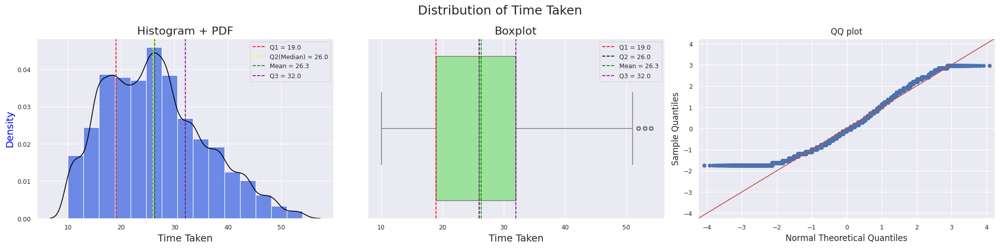

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Skewness: 0.5
Distribution of Time Taken is Right-Skewed
The right tail is longer
The mean is greater than the median, which is pulled higher by a few large extreme values.

But Overall Distribution of Time Taken is: Almost symmetrical

Excess Kurtosis: -0.312
Platykurtic -> Distribution of Time Taken has "thin tails" and "fewer outliers" than a Normal distribution.

Omnibus Test for Normality
OB: Result: Reject Null Hypothesis. Data is not Normally Distributed

Anderson–Darling Test for Normality
AD: Result: Reject Null Hypothesis. Data is not Normally Distributed 

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_univariate_analysis_for_numerical_feature(df = df.copy(), feature = 'time_taken', num_bins = 15)

In [ ]:
px.histogram(df, x = 'time_taken', nbins = 15, title = 'Distribution of time_taken')

**Observations:**
- The target variable `time_taken` does not look evenly spread or continuous.
   
- Its distribution appears bimodal with one concentration around 15 to 19 minutes & other around 25 to 29 minutes.   
   
- It suggesting deliveries seem to happen in **two typical time groups**, not around one single center which is understandble because **delivery durations are often more common around few time ranges instead of evenly spread in a continuous way.**

### b. Outlier Detection

**Q. Do the outliers in `time_taken` look like genuine operational cases, or do they look suspicious / artificial ?**

So for that goal, the right interpretation is:

- Do outlier cases show systematic association with plausible real-world conditions ? Or do they look random, inconsistent, or impossible?
  - This is we can find out be analysing other features

---
1. For numerical features, this analysis compares the average `time_taken` value in outlier deliveries vs non-outlier deliveries.
   - So, the interpretation is about **difference between groups, not direct causation.**

2. For categorical features, this analysis compares the proportion of each category among outlier deliveries and non-outlier deliveries, such as `P(category | outliers in time_taken) vs P(category | no outliers in time_taken)`.
   - So, the interpretation is about **association and over-representation of an category, not direct causation.**
   -  It tells us which categories are more common or less common among outlier deliveries.

---
**Intuition behind the Conditional Probablity Formula**

- The intuition behind the formula for conditional probability:
$$P(A|B) = \frac{P(A ∩ B)} {P(B)} $$ is based on the concept of reducing sample space.

- The denominator `P(B) is the probability of an event B occuring`. When we say we want to know the probablity of A given B i.e `P(A|B)`, we're effectively saying that B has occured and therefore B is our new universe or sample space.

- So we're not considering cases when B didn't occure anymore, and we're normalizing by the probability of B.

- The numerator `P(A ∩ B), is the joint probability of A and B`, meaning both A and B occur.

- **So in the conext of our new universe where B has already occured,
`P(A ∩ B) represents the cases where A also occurs`.**

- By dividing the joint probability P(A ∩ B) by P(B) i.e.
$$\frac{P(A ∩ B)} {P(B)} $$ we effectively **find the proportion of times that A occurs given that B has already occured.**

In [ ]:
# Run the function on a copy of the dataset, using 'time_taken' as the feature for outlier detection
#
# Why df.copy() ?
# So that the original dataset remains untouched even if future modifications are added inside the function.

check_for_outliers(df = df.copy(), feature = 'time_taken')

------------------------------------------------------------------------Numerical Data-Type-----------------------------------------------------------------


,feature,when_no_outliers_in(time_taken),when_outliers_in(time_taken)
0,distance_km,9.70,13.29
1,rider_age,29.54,32.28
2,rider_ratings,4.64,4.49
3,order_pickup_time_mins,9.99,9.63



------------------------------------------------------------------------Categorical Data-Type-----------------------------------------------------------------


vehicle_type,Motor-Cycle,Electric-Scooter,Scooter,Bicycle
P(vehicle_type | outliers in time_taken),0.989,0.004,0.007,NaN
P(vehicle_type | no-outliers in time_taken),0.578,0.084,0.337,0.001



 --------------------------------------------------------------------------------------------------------------------------------------------


vehicle_condition,0,3,1,2
P(vehicle_condition | outliers in time_taken),0.981,0.019,NaN,NaN
P(vehicle_condition | no-outliers in time_taken),0.326,0.009,0.332,0.332


... (25 outputs left out)

is_festival,True,False
P(is_festival | outliers in time_taken),0.341,0.659
P(is_festival | no-outliers in time_taken),0.018,0.982



 --------------------------------------------------------------------------------------------------------------------------------------------


traffic,Jam,High,Low,Medium
P(traffic | outliers in time_taken),0.909,0.091,NaN,NaN
P(traffic | no-outliers in time_taken),0.311,0.098,0.346,0.245



 --------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
t1 = df['vehicle_type'].value_counts().reset_index()
t2 = df.groupby('vehicle_type', as_index = False)['vehicle_condition'].value_counts()

d = t1.merge(t2, on = 'vehicle_type', how = 'inner')
d.columns = ['vehicle_type', 'vehicle_count', 'vehicle_condition', 'conditon_count']
d

# In our data riders with Motorcyle are the highest
# Outliers almost exclusively occur among motorcycle riders.
# However, this likely reflects: Motorcycles being the dominant vehicle in this dataset
# There they are also used for longer deliveries
# & also majority of Motor-cycle comes under vehicle condition 0 (means best).

,vehicle_type,vehicle_count,vehicle_condition,conditon_count
0,Motor-Cycle,26427,0,15009
1,Motor-Cycle,26427,1,7583
2,Motor-Cycle,26427,2,3753
3,Motor-Cycle,26427,3,82
4,Scooter,15244,2,7655
5,Scooter,15244,1,7447
6,Scooter,15244,3,142
7,Electric-Scooter,3778,2,3626
8,Electric-Scooter,3778,3,152
9,Bicycle,53,3,53


### c. **Observations from outliers:**
---

### Rider Related features

1. **Rider age**
   - Deliveries with outlier in time_taken have a slightly higher average rider age (32.28) than deliveries without outliers (29.54).
   - This shows a **clear difference** between the two groups.
   - So, `rider age` shows **strong association** with outlier delivery times.
   - This supports the idea that **many outliers are real delivery delays**, not random errors.
   - On their own, this feature **strongly explain** why does some outliers in time taken happen.
   - **But the interpretation is about difference between groups, not direct causation.**


2. **Rider ratings**
   - The average rider ratings time is almost the same in both groups with 4.64 in non-outliers vs 4.49 in outliers.
   - This shows a **very small difference** between the two groups.
   - So, `rider ratings` shows **very weak association** with outlier delivery times.
   - On their own, this feature **not at all explain** why does some outliers in time taken happen.


3. **Vehicle type**
   - Outlier deliveries are almost completely concentrated in Motor Cycle.
   - Non-outlier deliveries are spread more across Motor Cycle then Scooter, then Electric Scooter then Bicycle.
   - This shows a **clear distribution difference** between outlier and non outlier deliveries groups.
   - On their own, this feature **very strongly explain** why does some outliers in time taken happen.
   - So, `vehicle type` is **strongly associated** with outlier delivery times.
   - However, this should **not be taken as proof** that Motor Cycle causes long delivery times.
   - As the interpretation **is about association and over-representation of an category, not direct causation.**
   

4. **Vehicle condition**
   - Outlier deliveries are fully concentrated in vehicle condition 0.
   - Non-outlier deliveries are spread across several vehicle condition categories.
   - This shows a **clear distribution difference** between outlier and non outlier deliveries groups.
   - On their own, this feature **very strongly explain** why does some outliers in time taken happen.
   - So, `vehicle condition` is **strongly associated** with outlier delivery times.
   - However, this should **not be taken as proof** that Vehicle condition causes long delivery times.
   - As the interpretation **is about association and over-representation of an category, not direct causation.**


5. **Multiple deliveries**
    - `Non-outlier deliveries` are mostly concentrated in `0 and 1.`
    - `Outlier deliveries` are mostly concentrated in higher delivery load categories, especially `2 and 3.`
    - This shows a **clear difference** between the two groups.
    - So, having `multiple deliveries` is **strongly associated** with outlier delivery times.
    - This supports the idea that **many outliers are real delivery delays**, not random errors.
    - On their own, this feature **very strongly explain** why does some outliers in time taken happen.
   - **But the interpretation is about difference between groups, not direct causation.**
   - The interpretation **is about association and over-representation of an category, not direct causation.**


6. **Distance km**
   - Deliveries with outlier in time_taken have a much higher average distance (13.29 km) than deliveries without outliers (9.7 km).
   - This shows a **clear difference** between the two groups.
   - So, `distance_km` shows **very strongly association** with outlier delivery times.
   - This supports the idea that **many outliers are real delivery delays**, not random errors.
   - On their own, this feature **very strongly explain** why does some outliers in time taken happen.
   - **But the interpretation is about difference between groups, not direct causation.**

7. **Order pickup time mins**
   - The average pickup preparation time is almost the same in both groups (9.99 vs 9.63).
   - This shows **no strong distribution difference** between outlier and non outlier deliveries groups
   - So, `order_pickup_time_mins` shows **very weak association** with outlier delivery times.
   - On their own, this feature **not at all explain** why does some outliers in time taken happen.
   
---

### 0rder Related features

8. **Order type**
   - The proportions of Snack, Buffet, Meal, and Drinks are very similar for outlier and non outlier deliveries.
   - This shows **no strong distribution difference** between outlier and non outlier deliveries groups
   - This means `order_type` shows **very weak association** with outlier delivery times.
   - On their own, this feature **not at all explain** why does some outliers in time taken happen.


9. **Order placed hr**
    - `Outlier deliveries are heavily concentrated around 7 to 9 pm.`
    - Non-outlier deliveries are more spread across different hours.
    - This shows a **clear time based pattern between** between outlier and non outlier deliveries groups.
    - This supports the idea that **many outliers are real delivery delays**, not random errors.   
    - On their own, this feature **very strongly explain** why does some outliers in time taken happen.
    - **But the interpretation is about difference between groups, not direct causation.**
    - The interpretation **is about association and over-representation of an category, not direct causation.**


10. **Order time of day**
    - Outlier deliveries happen mostly during Evening and Night.
    - This shows a **clear difference in time of day composition**.
    - So, outlier delivery times are **strongly associated** with Evening and Night periods.
    - This shows a **strong distribution difference** between outlier and non outlier deliveries groups
    - On their own, this `order_time_of_day` **strongly explain** why does some outliers in time taken happen.
    - But the interpretation **is about difference between groups, not direct causation.**
    - The interpretation **is about association and over-representation of an category, not direct causation.**


11. **Is dinner rush**
    - Outlier deliveries happen very often during dinner rush (0.641), compared with non-outlier deliveries (0.312).
    - This is a **large difference**.
    - So, `is_dinner_rush` is **strongly associated** with outlier delivery times.
    - This supports the idea that many outliers are linked to **real hour delivery conditions**.
    - On their own, this feature **very strongly explain** why does some outliers in time taken happen.
    - But the interpretation **is about difference between groups, not direct causation.**
    - The interpretation **is about association and over-representation of an category, not direct causation.**


12. **Order day of week**
    - The distribution across weekdays is somewhat similar in both groups, though outliers are slightly more concentrated on some days such as Wednesday
    - Wednesday shows **strong distribution difference** between outlier and non outlier deliveries groups
    - This means that `order_day_of_week` shows **mild association** with outlier delivery times.
    - On their own, this feature **slighlty explain** why does some outliers in time taken happen.
    - So, `order_day_of_week` is **mildely associated** with outlier delivery times.
    - However, this should **not be taken as proof** that Wednesday causes long delivery times.
    - As the interpretation **is about association and over-representation of an category, not direct causation.**
    
   
13. **Is lunch rush**
    - The proportion of lunch rush orders is low in both groups (0.063 vs 0.056).
     - This means `is_lunch_rush` status shows **very small distribution difference** between the two groups.
    - This shows **no strong distribution difference** between outlier and non- outlier deliveries groups
    - This means that `is_lunch_rush` shows **very weak association** with outlier delivery times.
    - On their own, this feature **not at all explain** why does some outliers in time taken happen.


14. **Is weekend**
    - The weekend proportions are almost the same in outlier and non-outlier deliveries (0.278 vs 0.275).
    - This means `is_weekned` status shows **very small distribution difference** between the two groups.
    - This shows **no strong distribution difference** between outlier and non- outlier deliveries groups
    - This means that `is_weekned`shows **very weak association** with outlier delivery times.
    - On their own, this feature **not at all explain** why does some outliers in time taken happen.


15. **Is friday night**
    - Friday night is slightly more common among outlier deliveries (0.137) than among non-outlier deliveries (0.101).
    - This means `is_friday_night` status shows **very small distribution difference** between the two groups.
    - This shows **no strong distribution difference** between outlier and non- outlier deliveries groups
    - This means that `is_friday_night` shows **very weak association** with outlier delivery times.
    - On their own, this feature **not at all explain** why does some outliers in time taken happen.


16. **Is month start**
    - Month start orders are more common among outlier deliveries (0.985) than non-outlier deliveries (0.95).
    - This means `is_month_start` status shows **very small distribution difference** between the two groups.
    - This shows **no strong distribution difference** between outlier and non- outlier deliveries groups
    - This means that `is_month_start`shows **very weak association** with outlier delivery times.
    - On their own, this feature **not at all explain** why does some outliers in time taken happen.


17. **Is month end**
    - Month-end orders are more common among outlier deliveries (0.052) than among non-outlier deliveries (0.021).
    - This means `is_month_end` status shows **very small distribution difference** between the two groups.
    - This shows **no strong distribution difference** between outlier and non- outlier deliveries groups
    - This means that `is_month_end`shows **very weak association** with outlier delivery times.
    - On their own, this feature **not at all explain** why does some outliers in time taken happen.

---
### Delivery Conditions Related features

18. **Weather**
    - The weather proportions are fairly similar across outlier and non outlier deliveries except Fog
    - Fog category stands in a very strong way.
    - So, `weather` does **show a clear standalone pattern** with outlier delivery times in this comparison.
    - On their own, this feature do **strongly explain** why does some outliers in time taken happen.
    - But the interpretation **is about difference between groups, not direct causation.**
    - The interpretation **is about association and over-representation of an category, not direct causation.**


19. **Is festival**
    - Festival orders are much more common among outlier deliveries (0.341) than among non-outlier deliveries (0.018).
    - This is one of the **strongest differences** in the whole analysis.
    - So, `is_festival` status is **strongly associated** with outlier delivery times.
    - This strongly supports the idea that many outliers are **genuine delays** happening under special high demand conditions.
    - On their own, this feature do **strongly explain** why does some outliers in time taken happen.
    - But the interpretation **is about difference between groups, not direct causation.**
    - The interpretation **is about association and over-representation of an category, not direct causation.**


20. **Traffic**
    - Outlier deliveries are heavily concentrated in Jam traffic (0.909) in outliers vs non-outlier (0.311)
    - This is one of the **strongest differences** in the whole analysis.
    - So, `traffic` conditions, especially traffic Jam is **strongly associated** with outlier delivery times.
    - This strongly supports the idea that the outliers are **genuine delays**, not random noise.
    - On their own, this feature do **strongly explain** why does some outliers in time taken happen.
    - But the interpretation **is about difference between groups, not direct causation.**
    - The interpretation **is about association and over-representation of an category, not direct causation.**

---
**Final conclusion**
  - The outliers in time taken do **not look random garbage outliers**.
  - These outliers are not behaving randomly. They are heavily concentrated in combinations that make real-world delivery delays plausible
  - They are linked with **real delivery conditions** such as:
    - longer distance
    - Evening and Night orders
    - during dinner rush time
    - traffic jams
    - festival days
    - multiple deliveries
    - This suggests that these outliers are likely **genuine real world delivery delays**. So, these outliers should **not be removed automatically** just because they are extreme values.
    - They should be removed only if there is separate evidence that they are:
      - data entry mistakes
      - impossible values
      - measurement errors
      - duplicated records
      - corrupted records

###### Use this code during model building

- Since there are outliers in time_taken so if you want to apply linear regression you should tranform the time_taken

- Complete Revise Linear Regression Notes & solve conceptual Doubts then come here

Data-Type: float64
Missing Value %: 0.0
Outlier count (IQR rule): 0


,time_taken
count,45502.00
mean,0.00
std,1.00
min,-2.17
25%,-0.74
50%,0.09
75%,0.68
max,2.37


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


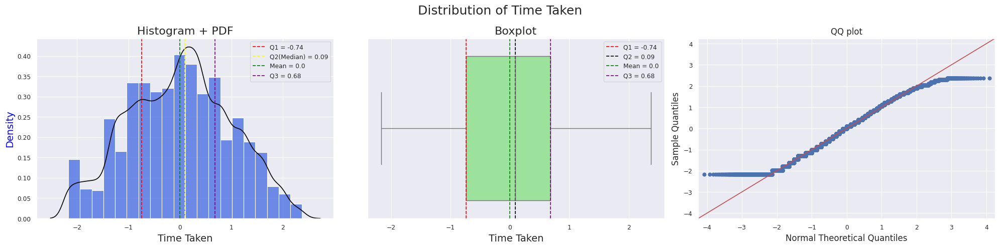

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Skewness: -0.0

But Overall Distribution of Time Taken is: Perfectly Symmetrical

Excess Kurtosis: -0.591
Platykurtic -> Distribution of Time Taken has "thin tails" and "fewer outliers" than a Normal distribution.

Omnibus Test for Normality
OB: Result: Reject Null Hypothesis. Data is not Normally Distributed

Anderson–Darling Test for Normality
AD: Result: Reject Null Hypothesis. Data is not Normally Distributed 

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
from sklearn.preprocessing import PowerTransformer

temp_df = df.copy()

pt = PowerTransformer(method = 'yeo-johnson', standardize = True)

temp_df['time_taken'] = pt.fit_transform(temp_df[['time_taken']])

get_univariate_analysis_for_numerical_feature(df = temp_df, feature = 'time_taken', num_bins = 20)

# For large dataset, we can not soley rely on Hypothesis that
# Coming to Omnibus Test or Anderson Darling
# In such large dataset even a small deviation can make p value < 0.05
# That's why these test shows Result: Reject Null Hypothesis. Data is not Normally Distributed

## 2.distance_km

### a. Uni-Variate Analysis

Data-Type: float64
Missing Value %: 7.98
Outlier count (IQR rule): 0


,distance_km
count,41872.00
mean,9.72
std,5.60
min,1.47
25%,4.66
50%,9.19
75%,13.68
max,20.97


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


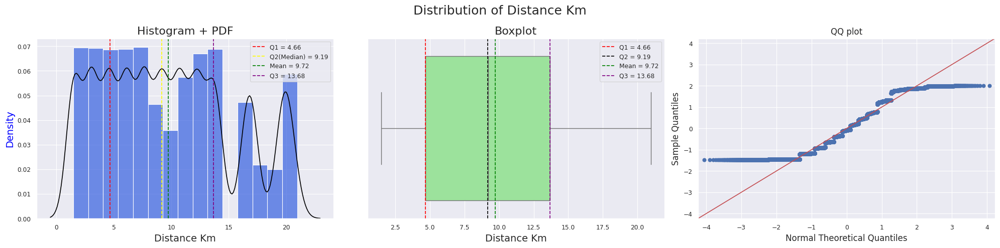

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Skewness: 0.3
Distribution of Distance Km is Right-Skewed
The right tail is longer
The mean is greater than the median, which is pulled higher by a few large extreme values.

But Overall Distribution of Distance Km is: Almost symmetrical

Excess Kurtosis: -0.906
Platykurtic -> Distribution of Distance Km has "thin tails" and "fewer outliers" than a Normal distribution.

Omnibus Test for Normality
OB: Result: Reject Null Hypothesis. Data is not Normally Distributed

Anderson–Darling Test for Normality
AD: Result: Reject Null Hypothesis. Data is not Normally Distributed 

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_univariate_analysis_for_numerical_feature(df = df.copy(), feature = 'distance_km', num_bins = 15)

In [ ]:
df[df['distance_km'] == df['distance_km'].max()]

,rider_age,rider_ratings,multiple_deliveries,vehicle_type,vehicle_condition,city_name,distance_km,order_type,order_placed_datetime,order_picked_datetime,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival,weather,traffic,time_taken
912,22.0,4.7,0.0,Electric-Scooter,2,Prayagraj,20.969489,Drinks,2022-02-16 22:55:00,2022-02-16 23:10:00,15.0,22.0,-0.500,0.866,Night,False,True,16.0,Wednesday,False,False,2.0,False,False,False,Cloudy,Low,26
15683,22.0,5.0,0.0,Motor-Cycle,1,Prayagraj,20.969489,Meal,2022-02-12 22:10:00,2022-02-12 22:15:00,5.0,22.0,-0.500,0.866,Night,False,True,12.0,Saturday,False,True,2.0,False,False,False,Sandstorms,Low,12
25877,32.0,3.8,1.0,Motor-Cycle,2,Prayagraj,20.969489,Snack,2022-02-14 20:25:00,2022-02-14 20:30:00,5.0,20.0,-0.866,0.500,Evening,False,True,14.0,Monday,False,False,2.0,False,False,False,Sandstorms,Jam,33


### b. Bi-Variate Analysis

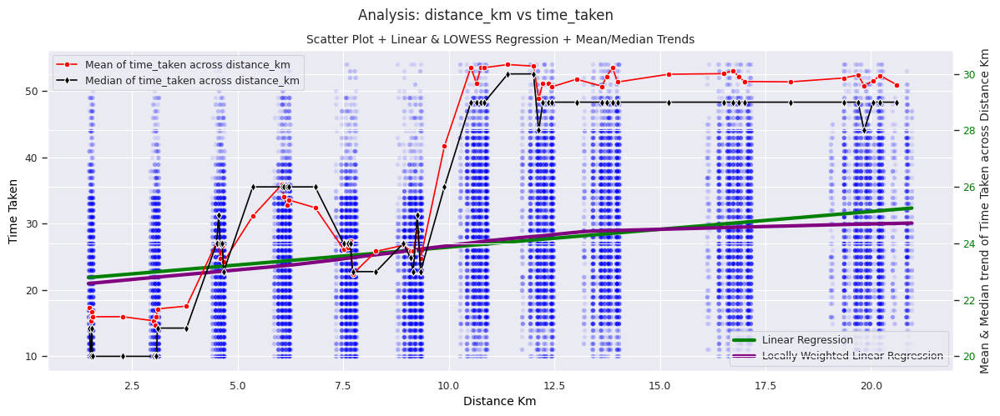

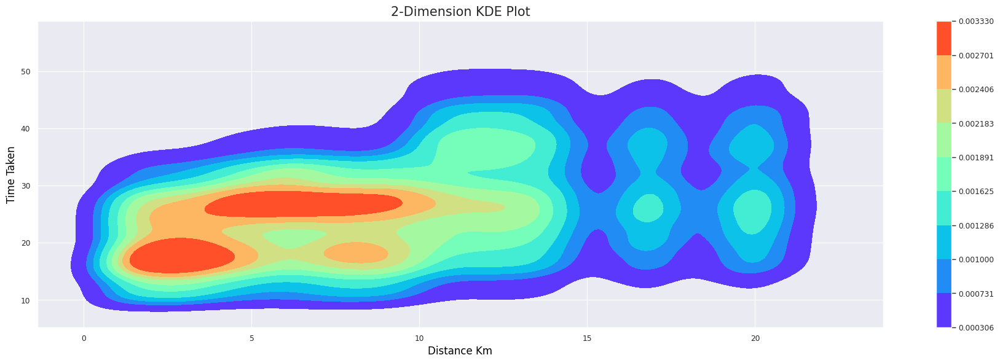

----------------------------------------------------------------------------------------------------------------------------------
STATISTICS FOR Distance Km vs Time Taken
Mutual Information: 0.095 (Higher = more dependency)
Spearman Rank:      0.3197 (Robust to non-linear)
Pearson Coef:       0.3207

Result: Statistically significant monotonic association detected between Distance Km & Time Taken by Spearman Rank
----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_numerical_vs_numerical(df = df.copy(), feature = 'distance_km', feature_type = 'continuous', target = 'time_taken',
                                                  bins_to_divide = 60, palette = 'rainbow')

My queries from Bi-Variate Analysis

---
**Q1. Why there is a sudden upward shift in mean `time_taken` after 3km but then sudden downward shift after 6km, but then again an upward shift after 7.7 km, and a biggest upward steep after 9.3km & from 10.5 km graph get stablized ?**

**Q2. Why there is no gradual increase in mean `time_taken` even when the `distance_km` increases from 11 to 20 km+ ?**

**Q3. Why does mean trend of `time_taken` across `distance_km` shows up-down pattern a lot ?**

**Q4. How does for the same `distance_km` the spread in `time_taken` varies a from 10 to 50 + minutes ?**

In [ ]:
df[df['distance_km'].between(0,4, inclusive = 'both')]['time_taken'].mean()

np.float64(21.427965540092778)

In [ ]:
df[df['distance_km'].between(5,10, inclusive = 'both')]['time_taken'].mean()

np.float64(24.387136782423813)

In [ ]:
df[df['distance_km'].between(11,15, inclusive = 'both')]['time_taken'].mean()

np.float64(29.75842771485676)

In [ ]:
df[df['distance_km'].between(16,23, inclusive = 'both')]['time_taken'].mean()

np.float64(29.868525896414344)

In [ ]:
new_df  = df.drop(columns = ['sin_hr','cos_hr', 'order_placed_datetime', 'order_picked_datetime'])

condition_list = [new_df['distance_km'].between(0,3,   inclusive = 'both'),
                  new_df['distance_km'].between(4,7,   inclusive = 'both'),
                  new_df['distance_km'].between(8,13,  inclusive = 'both'),
                  new_df['distance_km'].between(14,18, inclusive = 'both')]

choice_list = ['Short', 'Medium', 'Long', 'Very Long']

new_df['distance_cat'] = np.select(condition_list, choice_list, default = 'Extreme Long')

In [ ]:
new_df['traffic'] = pd.Categorical(new_df['traffic'], categories = ['Low', 'Medium', 'High', 'Jam'], ordered = True)

new_df['distance_cat'] = pd.Categorical(new_df['distance_cat'], categories = ['Short', 'Medium', 'Long', 'Very Long', 'Extreme Long'], ordered = True)

### c. Multi-Variate Analysis

In [ ]:
get_hypothesis_test_results_for_numerical_column(df = df.drop(columns = ['sin_hr','cos_hr']).copy(), feature_given = 'distance_km')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,distance_km,order_placed_hr,0.0,order_placed_hr,time_taken,0.00
1,distance_km,is_dinner_rush,0.0,is_dinner_rush,time_taken,0.00
2,distance_km,is_lunch_rush,0.0,is_lunch_rush,time_taken,0.16
3,distance_km,order_time_of_day,0.0,order_time_of_day,time_taken,0.00
4,distance_km,traffic,0.0,traffic,time_taken,0.00
5,distance_km,is_month_start,0.0,is_month_start,time_taken,0.00
6,distance_km,is_friday_night,0.0,is_friday_night,time_taken,0.00
7,distance_km,order_day_of_week,0.0,order_day_of_week,time_taken,0.00
8,distance_km,is_month_end,0.0,is_month_end,time_taken,0.00
9,distance_km,multiple_deliveries,0.0,multiple_deliveries,time_taken,0.00


In [ ]:
d1 = new_df.copy().dropna()

d1['distance_bins'] = pd.qcut(d1['distance_km'], q = 60)
d1['mid'] = d1['distance_bins'].apply(lambda x: x.mid)
avg_df = d1.groupby('mid',as_index = False)['time_taken'].mean()
avg_df.head(10)

,mid,time_taken
0,1.4865,21.968230
1,1.5145,21.509346
2,1.5260,21.419355
3,1.5420,21.788754
4,1.5550,21.549080
5,2.2715,21.701238
6,3.0070,21.462709
7,3.0445,21.319444
8,3.0820,21.421296
9,3.1065,21.671756


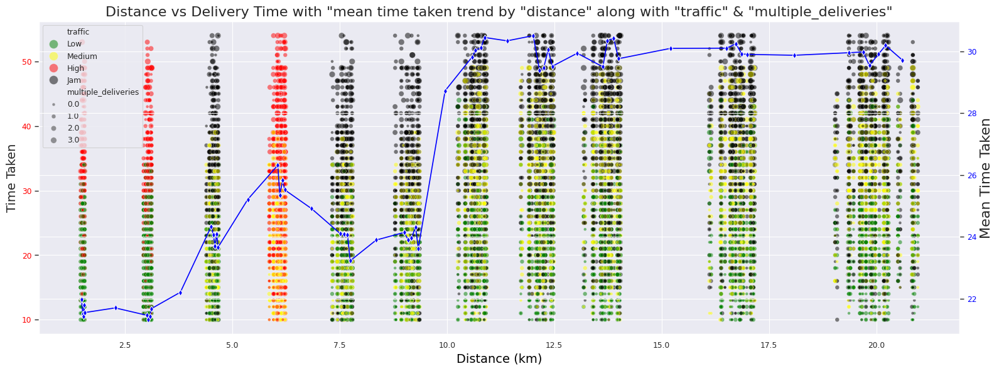

In [ ]:
fig, ax_scatter = plt.subplots(nrows = 1, ncols = 1, figsize = (16,6))

# Plot 1: Scatter Plot
color_palette = {'Low':'green', 'Medium':'yellow', 'High':'red', 'Jam':'black'}

sns.scatterplot(data = new_df,  x = 'distance_km', y = 'time_taken', s = 100, alpha = 0.5, hue = 'traffic', size = 'multiple_deliveries', palette = color_palette,
                ax = ax_scatter)
ax_scatter.set_title('Distance vs Delivery Time with "mean time taken trend by "distance" along with "traffic" & "multiple_deliveries"', fontsize = 16)
ax_scatter.set_ylabel('Time Taken', fontsize = 14)
ax_scatter.tick_params(axis = 'y', labelcolor = 'red')
ax_scatter.set_xlabel('Distance (km)', color = 'black', fontsize = 14)

# Plot 2: Mean Trend
ax_mean = ax_scatter.twinx()
sns.lineplot(data = avg_df, x = 'mid', y = 'time_taken', marker = 'd', color = 'blue', ax = ax_mean)
ax_mean.set_ylabel('Mean Time Taken', fontsize = 16)
ax_mean.tick_params(axis = 'y', labelcolor = 'blue')

# Improve spacing
plt.tight_layout()
plt.show()

**Q1. Why there is a sudden upward shift in mean `time_taken` after 3km but then sudden downward shift after 6km, but then again an upward shift after 7.7 km, and a biggest upward steep after 9.3km & from 10.5 km graph get stablized ?**

- These spikes overall trend reflect `Low to High` traffic Transition, then `High to Jam` traffic congestion areas along with increase in order volume, with increase in stacked deliveries, which causes delay in delivery time, even when the distances are same.

- This combined effect, causes mean delivery time to shows spikes, even when distances are same, along with some more reasons which you can find out by looking at the later figures.

- Here Dominant effect is traffic

In [ ]:
temp_df = new_df.groupby('distance_cat', as_index =  False)['time_taken'].mean().round(2)

temp_df = temp_df.sort_values(by = 'distance_cat').reset_index(drop = True)

temp_df

,distance_cat,time_taken
0,Short,21.47
1,Medium,24.65
2,Long,27.86
3,Very Long,29.90
4,Extreme Long,26.33


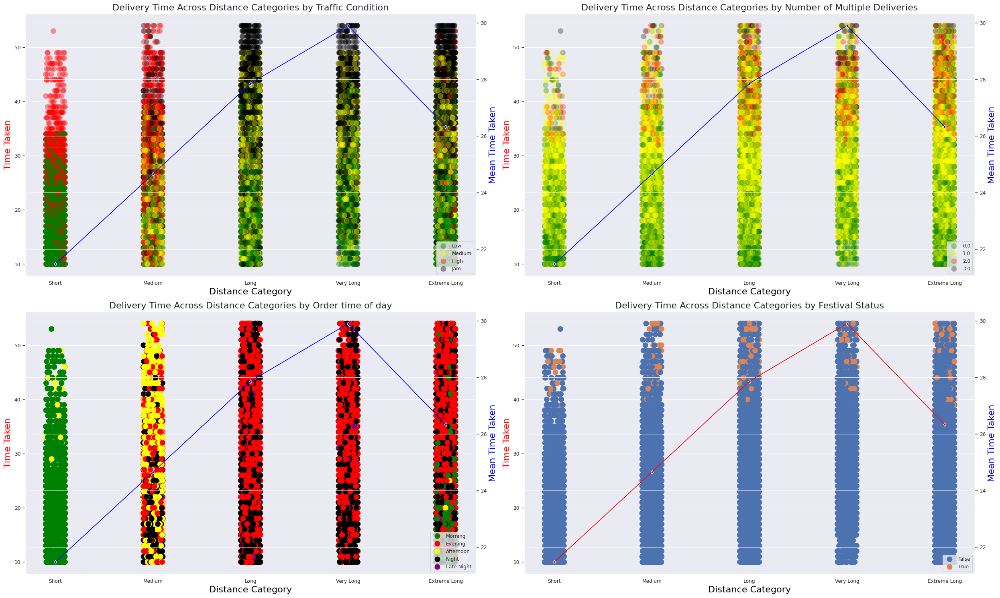

In [ ]:
# 2nd Figure object
fig, [(ax_traffic, ax_mul), (ax_order_time, ax_festival)] = plt.subplots(nrows = 2, ncols = 2, figsize = (25,15))

ordering = ['Short', 'Medium', 'Long', 'Very Long', 'Extreme Long']

# Plot 1:
color_palette = {'Low':'green', 'Medium':'yellow', 'High':'red', 'Jam':'black'}
sns.stripplot(data = new_df.dropna(), x = 'distance_cat', y = 'time_taken', order = ordering, hue = 'traffic', alpha = 0.4, s = 10, palette = color_palette, ax = ax_traffic)
ax_mean = ax_traffic.twinx()
sns.lineplot(data = temp_df, x = 'distance_cat', y = 'time_taken', marker = 'd', color = 'blue', ax = ax_mean)
ax_mean.set_ylabel('Mean Time Taken', color = 'blue', fontsize = 16)

# Labelling
ax_traffic.set_title('Delivery Time Across Distance Categories by Traffic Condition', fontsize = 16)
ax_traffic.set_ylabel('Time Taken', color = 'red', fontsize = 16)
ax_traffic.set_xlabel('Distance Category', color = 'black', fontsize = 16)
ax_traffic.legend(loc = 'lower right')

# Plot 2:
color_palette = {0:'green', 1:'yellow', 2:'red', 3:'black'}
sns.stripplot(data = new_df.dropna(), x = 'distance_cat', y = 'time_taken', order = ordering, hue = 'multiple_deliveries', alpha = 0.3, s = 10, palette = color_palette, ax = ax_mul)
ax_mean = ax_mul.twinx()
sns.lineplot(data = temp_df, x = 'distance_cat', y = 'time_taken', marker = 'd', color = 'blue', ax = ax_mean)
ax_mean.set_ylabel('Mean Time Taken', color = 'blue', fontsize = 16)

# Labelling
ax_mul.set_title('Delivery Time Across Distance Categories by Number of Multiple Deliveries', fontsize = 16)
ax_mul.set_ylabel('Time Taken', color = 'red', fontsize = 16)
ax_mul.set_xlabel('Distance Category', color = 'black', fontsize = 16)
ax_mul.legend(loc = 'lower right')

# Plot 3:
color_palette = {'Morning':'green', 'Afternoon':'yellow', 'Evening':'red', 'Night':'black', 'Late Night':'purple'}
sns.stripplot(data = new_df.dropna(), x = 'distance_cat', y = 'time_taken', order = ordering, hue = 'order_time_of_day', s = 10, palette = color_palette, ax = ax_order_time)
ax_mean = ax_order_time.twinx()
sns.lineplot(data = temp_df, x = 'distance_cat', y = 'time_taken', marker = 'd', color = 'blue', ax = ax_mean)
ax_mean.set_ylabel('Mean Time Taken', color = 'blue', fontsize = 16)

# Labelling
ax_order_time.set_title('Delivery Time Across Distance Categories by Order time of day', fontsize = 16)
ax_order_time.set_ylabel('Time Taken', color = 'red', fontsize = 16)
ax_order_time.set_xlabel('Distance Category', color = 'black', fontsize = 16)
ax_order_time.legend(loc = 'lower right')

# Plot 4:
sns.stripplot(data = new_df.dropna(), x = 'distance_cat', y = 'time_taken', order = ordering, hue = 'is_festival', s = 10, ax = ax_festival)
ax_mean = ax_festival.twinx()
sns.lineplot(data = temp_df, x = 'distance_cat', y = 'time_taken', marker = 'd', color = 'red', ax = ax_mean)
ax_mean.set_ylabel('Mean Time Taken', color = 'blue', fontsize = 16)

# Labelling
ax_festival.set_title('Delivery Time Across Distance Categories by Festival Status', fontsize = 16)
ax_festival.set_ylabel('Time Taken', color = 'red', fontsize = 16)
ax_festival.set_xlabel('Distance Category', color = 'black', fontsize = 16)
ax_festival.legend(loc = 'lower right')

# Improve Spacing
plt.tight_layout()
plt.show()

**Q3. Why does mean trend of `time_taken` across `distance_km` shows up-down pattern a lot ?**

**Q4. How does for the same `distance_km` the spread in `time_taken` varies a from 10 to 50 + minutes ?**

---
1. **Distance increases opportunity for delay, not guaranteed delay**
   
**For example:**

| Delivery Distance | Traffic Condition | Stacked Deliveries | Estimated Delivery Time |
| ----------------: | ----------------- | -----------------: | ----------------------: |
|          **3 km** | Low               |                  1 |              **15 min** |
|          **3 km** | Low               |                  2 |              **22 min** |
|          **3 km** | Low               |                  3 |              **30 min** |
|          **3 km** | Traffic Jam       |                  1 |              **35 min** |
|          **3 km** | Traffic Jam       |                  2 |              **43 min** |
|          **3 km** | Traffic Jam       |                  3 |              **50 min** |
|          **5 km** | Low               |                  1 |              **22 min** |
|          **5 km** | Low               |                  2 |              **30 min** |
|          **5 km** | Low               |                  3 |              **38 min** |
|          **5 km** | Traffic Jam       |                  1 |              **42 min** |
|          **5 km** | Traffic Jam       |                  2 |              **52 min** |
|**5 km** | Traffic Jam       |                  3 |     **60 min (1 hour)** |


2. Also within that same range of distance, deliveries are happening under very different conditions:
   - different traffic conditions
   - different stacked deliveries
   - festival times
   - different order_time_of_day & other conditions too

---
**Q5. Since there is a moderate co-relation between `distance_km` and `time_taken`. Is `distance_km` the sole causation in `time_taken` ?**

- No

- A moderate Pearson/Spearman around 0.32 means:
  - longer distance is associated with longer time
  - but the relationship is only moderate
  - many deliveries with the same distance still have different times

- Our own plots already prove this:
  - same distance -> large vertical spread in time_taken
  - traffic groups clearly separate outcomes
  - mean line changes with traffic composition

- So distance is:
  - a contributing factor
  - probably a causal component in a practical sense
  - but not the sole cause

### d. Final Observations

---
**1. Correlation Interpretation**
  - Both pearson & spearman rank correlations indicate that delivery time tends to increase as delivery distance increases.

  - The association is positive, meaning `longer delivery distances are generally associated with longer delivery times.`

  - The relationship is statistically significant, indicating that the pattern is unlikely to occur due to random variation.

  - However, the magnitude of correlation around 0.32 indicates only a medium / moderate association.

---
**2. Scatter Plot + LOWESS + Mean & Median Trend + KDE Density Interpretation**

  a. **Scatter Plot**

  - As the distance increases more & more observations lies on the higher side of `time taken` to delivery order.
  
  - The scatter plot shows a clear upward trend between `distance_km` and `time_taken`.
    
  - Shorter delivery distances are typically associated with shorter delivery times, while longer distances tend to correspond to larger delivery times.
  
  - However there is sufficient vertical spread at nearly every distance value.  This indicates that **deliveries with similar/same distances can still have very different delivery times.**

  - Distance contributes to delivery time but does not fully explain its variability.
  
  - This suggests that **additional features also influence delivery time duration.**

  b. **Linear Regression vs LOWESS**

  - The linear regression line slopes upward confirming that delivery time increases with distance. However the slope is not steep that much. The LOWESS curve closely follows the regression line.

  - This indicates that delivery distance contributes to delivery duration across most ranges.
  
  - However the increase appears gradual rather than steep. This observation aligns with the moderate correlation observed earlier.

  c. **Mean and Median Bin Trend**

  - The bin based aggregation shows that mean and median delivery time generally increase as delivery distance increases.

  - This indicates a positive association between `distance_km` and `time_taken`.

  - **However there is a sudden upward shift in mean `time_taken` after 3km but then sudden downward shift after 6km, but then again an upward shift after 7.7 km, and a biggest upward steep after 9.3km**

  - These spikes overall trend reflect `Low to High` traffic Transition, then `High to Jam` traffic congestion areas along with increase in order volume, with increase in stacked deliveries, which causes delay in delivery time, even when the distances are same.

  - This combined effect, causes mean delivery time to shows spikes, even when distances are same along with more reasons

  - Delivery time is not purely determined by `distance_km` but also by `traffic`, `multiple_deliveries` along with other features too.

  d. **KDE & Density Heatmap Interpretation**

  - The KDE density plot highlights where most observations occur.

  - Primary density region : distance approximately 0 to 5 km & median time_taken of 22 mintutes.
  
  - Secondary density region : distance approximately 5 to 10 km & median time_taken of 24 mintutes.

  - **Short distance deliveries dominate the dataset.**

  -  As distance increases, the distribution of delivery time gradually shifts upward. This indicates that longer distances correspond to longer delivery times.
  
  - Despite the positive relationship, **delivery times overlap across many distance values.** Some short distance deliveries take relatively long times while some longer distance deliveries are completed quickly.
   
---
**3. Mutual Information Interpretation**
- Mutual information measures any statistical dependency including nonlinear relationships.

- Mutual Information value 0.095 indicates weak to moderate dependency between distance_km and time_taken.

- A value near 0.095 suggests that distance contains some predictive information about delivery time but does not fully determine it.

---
**4. Explained Variation Insight**
- Using Pearson correlation approximately
  - R2 score = (Pearson Correlation Coefficient)^2  = 20.32^2 = 0.102

- **This suggests that `distance_km` alone explains ~ 10% of the variation in delivery time alone.**

- This implies that around 90% of the variation in delivery time is driven by other variables or combination of other variables.

- Distance tends to provide slightly stronger predictive information. **However distance alone cannot fully explain variation in time_taken**

---
**Final Conclusion**
- Longer distances require longer travel time and expose riders to more potential delays.

- However traffic conditions along with other factors significantly distort the expected distance time relationship.

  - For example a shorter delivery in heavy traffic may take longer time than a longer distance delivery in low traffic conditions.

- From a predictive modeling perspective `distance_km` is a **meaningful but not dominant feature.**

- Distance should therefore be treated as one of the important variable rather than a standalone predictor.

- **`distance_km` is an important driver of `time_taken`, because it likely contributes useful signal but must be combined with other operational variables such as `traffic`, `multiple_deliveries`, `order_time_of_day`, `is_festival`& others to achieve stronger predictive performance of delivery time.**

## 3.traffic

### a. Uni & Bi-Variate Analysis

Data-Type of traffic : object
Unique values in traffic : ['High' 'Jam' 'Low' 'Medium' nan]
Total unique values in traffic : 4
%of NaN values in traffic : 1.12



,traffic,counts,proportion
0,Low,15477,0.3440
1,Jam,14143,0.3143
2,Medium,10947,0.2433
3,High,4425,0.0984


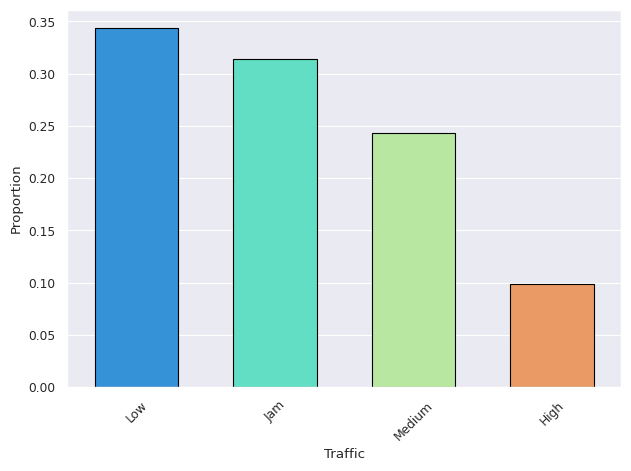

In [ ]:
get_univariate_analysis_for_categorical_feature(df = df.copy(), feature = 'traffic')

,traffic,count,proportion_%,mean_time_taken,std_time_taken
0,Low,15477,34.399,21.27,6.80
1,Medium,10947,24.331,26.70,8.56
2,High,4425,9.835,27.24,8.40
3,Jam,14143,31.434,31.18,9.94


----------------------------------------------------------------------------------------------------------------------------------------------------------------


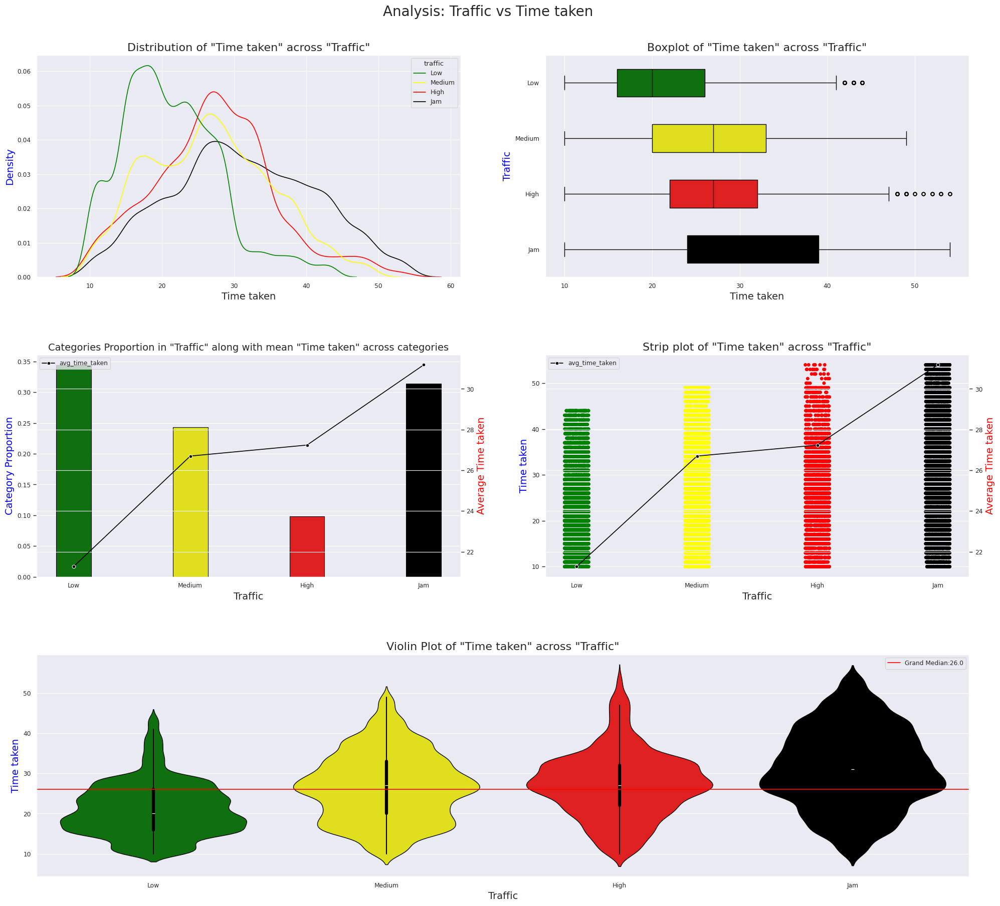

--------------------------------------------------------------------------------------------------------------------------------------------
Welch One-Way ANOVA (not assumed equal variance)

Reject Ho
Result: Significant difference in category mean of "time_taken" detected across "Traffic"
Result: Welch’s ANOVA indicates that atleast one category mean of "time_taken" is significantly differs from the rest of the others
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df = df.copy(), feature = 'traffic', target = 'time_taken')

### b. Multi-Variate Analysis

In [ ]:
get_hypothesis_test_results_for_categorical_column(df = df.drop(columns = ['sin_hr','cos_hr']).copy(), feature_given = 'traffic')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,traffic,order_time_of_day,0.0,order_time_of_day,time_taken,0.000
1,traffic,is_lunch_rush,0.0,is_lunch_rush,time_taken,0.159
2,traffic,is_dinner_rush,0.0,is_dinner_rush,time_taken,0.000
3,traffic,order_day_of_week,0.0,order_day_of_week,time_taken,0.000
4,traffic,is_friday_night,0.0,is_friday_night,time_taken,0.000
5,traffic,is_month_start,0.0,is_month_start,time_taken,0.000
6,traffic,is_month_end,0.0,is_month_end,time_taken,0.000
7,traffic,is_festival,0.0,is_festival,time_taken,0.000
8,traffic,rider_ratings,0.0,rider_ratings,time_taken,0.000
9,traffic,multiple_deliveries,0.0,multiple_deliveries,time_taken,0.000


#### Figure 1:

 |Traffic Condition | Average Distance | Average Time taken |
 |------------------|------------------|--------------------|
 | Low              | 8.1 km           |     21+ min        |
 | Medium           | 11.1km           |     26+ min        |
 | High             | 4.5 km           |     27+ min        |
 | Jam              | 12 km            |     31+ min        |

Here we're checking is the rider stuck in the worsen traffic condition also travel more distance

---

**Important insight**

- Under **High** traffic, average distance is very lower, but average time is still  higher

- `If distance_km were the only main story, then High traffic should have had a much lower average delivery time than Medium traffic. But that is not what the plot shows.`

- Comparing average **distance_km** and average **time_taken** across traffic groups shows that the effect of **traffic** is not explained by distance alone.

- Traffic Congestion can overpower distance differences. A short distance deliveries under heavy traffic may take as long as, or even longer than, a longer trip in medium / lower traffic.

- Compared with **distance_km** alone, **traffic** provides a much cleaner categorical signal for explaining variation in **time_taken**.

- This supports the interpretation that **`traffic`** has its own real effect on **`time_taken`**, beyond the effect of **`distance_km`**.

,traffic,avg_dist,avg_time
0,Low,8.15,21.27
1,Medium,11.07,26.70
2,High,4.40,27.24
3,Jam,12.04,31.18


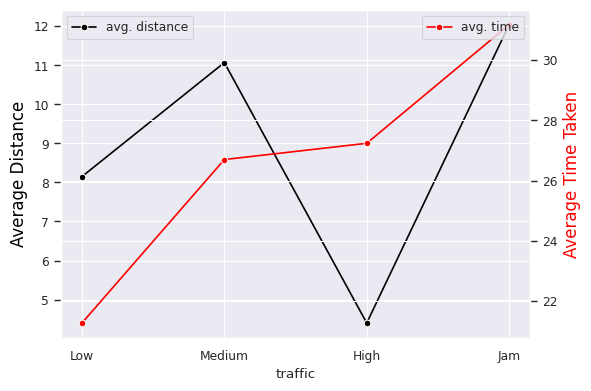

In [ ]:
avg_df = new_df.groupby('traffic', as_index = False).agg(avg_dist = ('distance_km','mean'),
                                                     avg_time = ('time_taken','mean')).round(2)

avg_df.sort_values(by = ['avg_time'], ascending = True, ignore_index = True)
display(avg_df)

# Plotting figure
fig, ax_dist = plt.subplots(figsize = (6,4))
ax_time = ax_dist.twinx()

sns.lineplot(data = avg_df, x = 'traffic', y = 'avg_dist', color = 'black', marker = 'o', label = 'avg. distance', ax = ax_dist)
sns.lineplot(data = avg_df, x = 'traffic', y = 'avg_time', color = 'red',   marker = 'o', label = 'avg. time', ax = ax_time)
ax_dist.set_ylabel('Average Distance', color = 'black', fontsize = 12)
ax_time.set_ylabel('Average Time Taken', color = 'red', fontsize = 12)
ax_dist.legend(loc = 'upper left')
ax_time.legend(loc = 'upper right')
plt.tight_layout()
plt.show()

#### Figure 2:

**Important Insights:**

---

1. From the `get_hypothesis_test_results_for_categorical_column(df = new_df.copy(), feature_given = 'traffic')` we found out that `traffic` has the highest association with `order_time_of_day` and `order_time_of_day` has significat association with `time_taken`.

2. But from Figure 2: you can see that within the same category of `order_time_of_day` the `time_taken` is heavyly driven by change in traffic composition

3. Also the change in `mean time taken` trend line can be explained with the help of `traffic` composition

4. It is possible that the change in `traffic` is more directly responsible for the increase in `time_taken`, while `order_time_of_day` is only associated with the change in `traffic`

5. And from the graph we can see that `order_time_of_day` shows significant relationship with `time_taken` because of the middle variable called `traffic`.

6. `But is important not to conclude pure causality from these plots alone.`

7. As observational **EDA** alone does not fully establish causal effect.

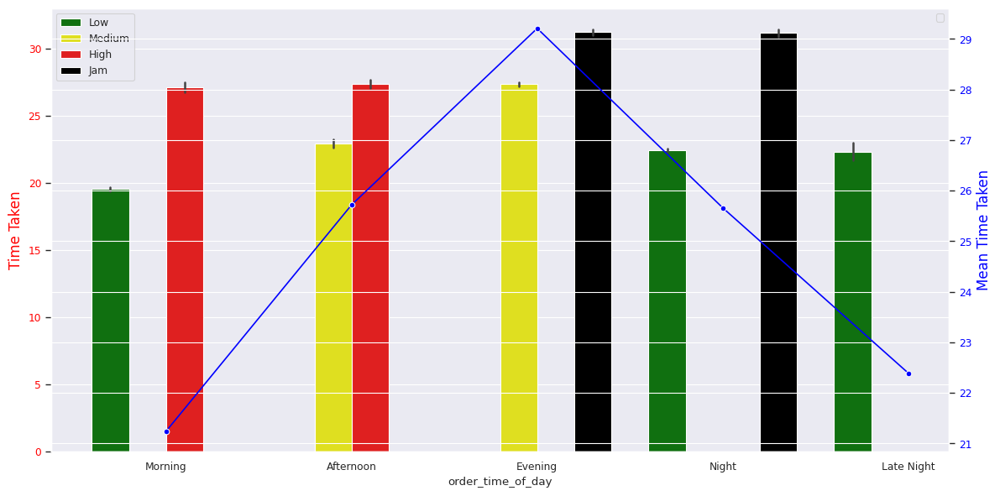

In [ ]:
new_df['order_time_of_day'] = pd.Categorical(new_df['order_time_of_day'], categories = ['Morning', 'Afternoon', 'Evening', 'Night', 'Late Night'], ordered = True)

traffic_color_palette = {'Low':'green', 'Medium':'yellow', 'High':'red', 'Jam':'black'}

avg_df = new_df.groupby('order_time_of_day', as_index = False)['time_taken'].mean().round(2)

fig, ax_time_bar = plt.subplots(figsize = (12,6))
ax_time_mean = ax_time_bar.twinx()

sns.barplot(data = new_df, x = 'order_time_of_day', y = 'time_taken', hue = 'traffic', palette = traffic_color_palette, ax = ax_time_bar)
sns.lineplot(data = avg_df, x = avg_df.index, y = 'time_taken', marker = 'o', color = 'blue', ax = ax_time_mean)

# Labelling
ax_time_bar.set_ylabel('Time Taken', color = 'red', fontsize = 12)
ax_time_bar.tick_params(axis = 'y', labelcolor = 'red')

ax_time_mean.set_ylabel('Mean Time Taken', color = 'blue', fontsize = 12)
ax_time_mean.tick_params(axis = 'y', labelcolor = 'blue')

ax_time_bar.legend(loc = 'upper left')
ax_time_mean.legend(loc = 'upper right')
plt.tight_layout()
plt.show()

### c. Final Observations

**1. KDE distribution by traffic**
- The distribution for **Low** traffic is concentrated more around lower delivery times
- **Medium** traffic shifts to the right
- **High** traffic also shifts to the right relative to **Medium**
- **Jam** traffic is the most right-shifted and also the widest
- As traffic become worsen, the whole distribution of **time_taken** tends to move toward larger values.
- This means that **traffic** affects not only the average delivery time, but also the overall distribution of delivery time.
- `At the same time, there is a meaningful overlap across traffic categories. This means traffic is an important factor, but not the only determinant of delivery time.`

- For example:
  - Some deliveries under **Jam** traffic completed quickly
  - Some deliveries under **Low** traffic take higher time
- **This suggests that additional variables also influence `time_taken`**.

**2. Boxplot by traffic**
- The median for **Low** traffic is clearly the smallest
- The median increases for **Medium** and **High**
- The median for **Jam** is the highest
- The spread also tends to increase, especially for **Jam**
- So, on a broader picture traffic leads: **Higher Delivery time**

**3. Count and mean time plot**
- This is useful because it shows  both **sample size** and **average time_taken** together.
- **Low** and **Jam** have large numbers of observations
- **High** has fewer observations
- Average **time_taken** increases from **Low** -> **Medium ~ High** -> **Jam**
- That means the effect is not just due to one tiny category.
- Especially: **Jam** has both a large count and a high average delivery time

**4. Violin plot**
- This plot helps visualize both shape and density.
- **Low** is denser in lower times
- **Medium** and **High** shift upward
- Jam is broader and centered higher than the others
- The red grand median line is also informative:
  - much of Low lies below the grand median
  - much of Jam lies above it

**5. Welch ANOVA**
- Welch ANOVA indicates that atleast one category mean of time_taken is significantly differs from the rest of the others

- This **visually supports by Violen Plot that, a meaningful group difference in `time_taken` across traffic categories.**

---
**Final Conclusion**
- Worse traffic conditions are associated with:
  - Larger delivery times
  - Broader spread in delivery times

- **Jam** appears to be the most delay inducing traffic condition
- **traffic** has a statistically significant relationship with **time_taken**, but also shows a clear and practically meaningful shift in the distribution of delivery time.

- At the same time, there is a meaningful overlap across traffic categories. This means traffic is an important factor, but not the only determinant of delivery time.

- For example:
  - Some deliveries under **Jam** traffic completed quickly
  - Some deliveries under **Low** traffic take higher time
- **This suggests that additional variables also influence `time_taken`**.

## 4.is_festival

### a. Uni & Bi-Variate Analysis

Data-Type of is_festival : boolean
Unique values in is_festival : <BooleanArray>
[False, True, <NA>]
Length: 3, dtype: boolean
Total unique values in is_festival : 2
%of NaN values in is_festival : 0.5



,is_festival,counts,proportion
0,False,44380,0.9803
1,True,894,0.0197


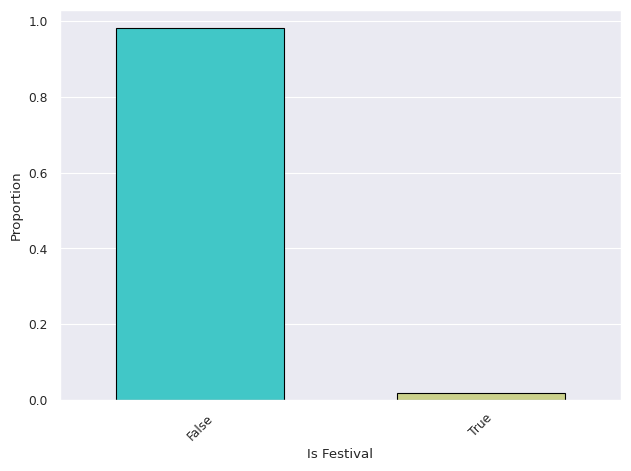

In [ ]:
get_univariate_analysis_for_categorical_feature(df = df.copy(), feature = 'is_festival')

,is_festival,count,proportion_%,mean_time_taken,std_time_taken
0,False,44380,98.025,25.99,9.02
1,True,894,1.975,45.52,4.01


----------------------------------------------------------------------------------------------------------------------------------------------------------------


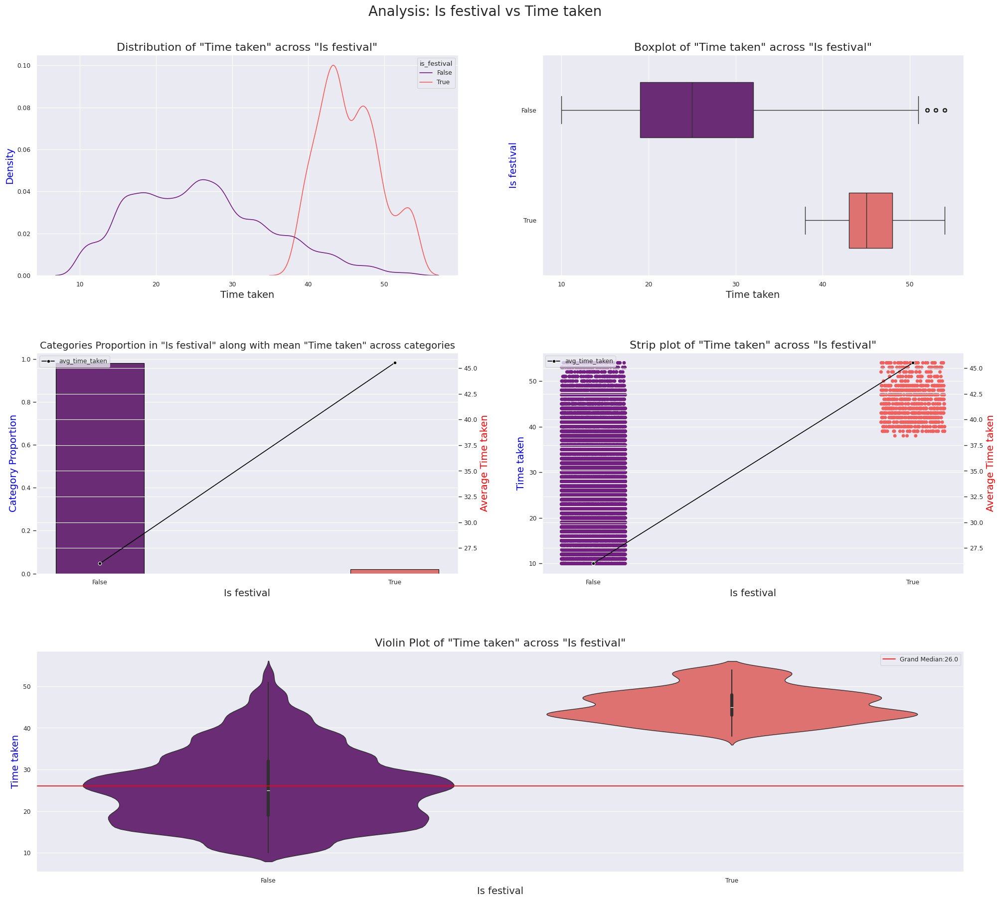

--------------------------------------------------------------------------------------------------------------------------------------------
Welch t-test (not assumed equal variance)

Reject Ho
Result: t-test indicates there is a significant difference between the mean of "time_taken" across two categories of "Is festival"
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df.copy(), feature = 'is_festival', target = 'time_taken', palette = 'magma')

### b. Multi-Variate Analysis

In [ ]:
get_hypothesis_test_results_for_categorical_column(df = df.drop(columns = ['sin_hr','cos_hr']).copy(), feature_given = 'is_festival')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,is_festival,vehicle_type,0.000,vehicle_type,time_taken,0.000
1,is_festival,vehicle_condition,0.000,vehicle_condition,time_taken,0.000
2,is_festival,order_time_of_day,0.000,order_time_of_day,time_taken,0.000
3,is_festival,is_dinner_rush,0.000,is_dinner_rush,time_taken,0.000
4,is_festival,is_friday_night,0.000,is_friday_night,time_taken,0.000
5,is_festival,order_day_of_week,0.000,order_day_of_week,time_taken,0.000
6,is_festival,is_month_start,0.000,is_month_start,time_taken,0.000
7,is_festival,is_month_end,0.000,is_month_end,time_taken,0.000
8,is_festival,rider_ratings,0.000,rider_ratings,time_taken,0.000
9,is_festival,weather,0.000,weather,time_taken,0.000



Overall category-level summary:


,is_festival,avg_dist,avg_time
0,False,9.66,26.01
1,True,13.26,45.46



Feature × traffic analysis:


proportion  avg_dist  avg_time_taken
is_festival traffic                                      
False       Low          0.3475    8.1446         21.2949
            Medium       0.2459   11.0399         26.5856
            High         0.0987    4.4018         26.9920
            Jam          0.3078   11.9560         30.5516
True        Low          0.0594   14.2773         42.0833
            Medium       0.1448   14.5522         43.7265
            High         0.0817    4.2516         45.7273
            Jam          0.7141   13.9488         46.0624

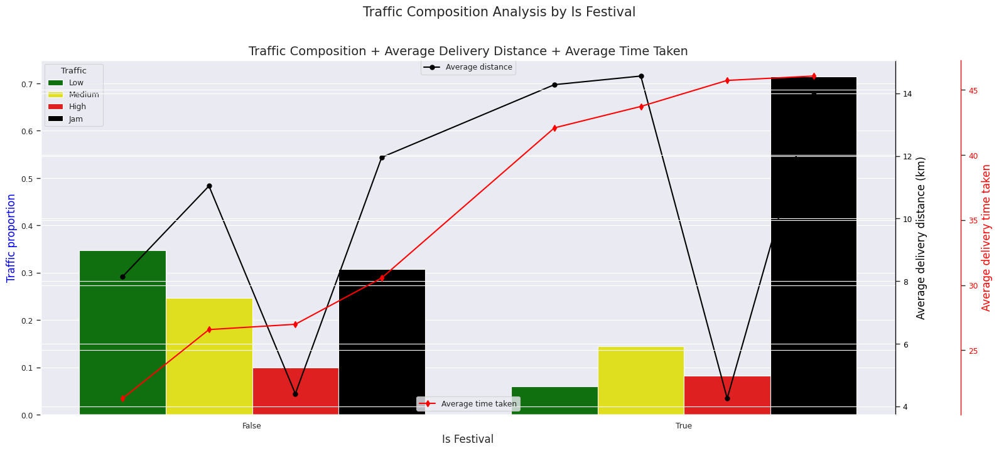

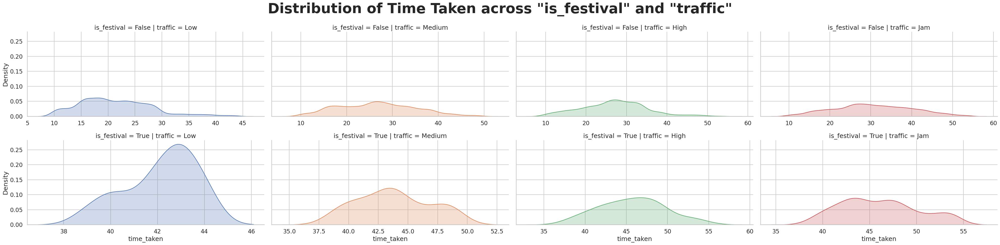

traffic,Low,Medium,High,Jam
is_festival,,,,
False,21.368170,26.668115,26.992342,30.592953
True,42.130435,43.779817,45.727273,46.041367


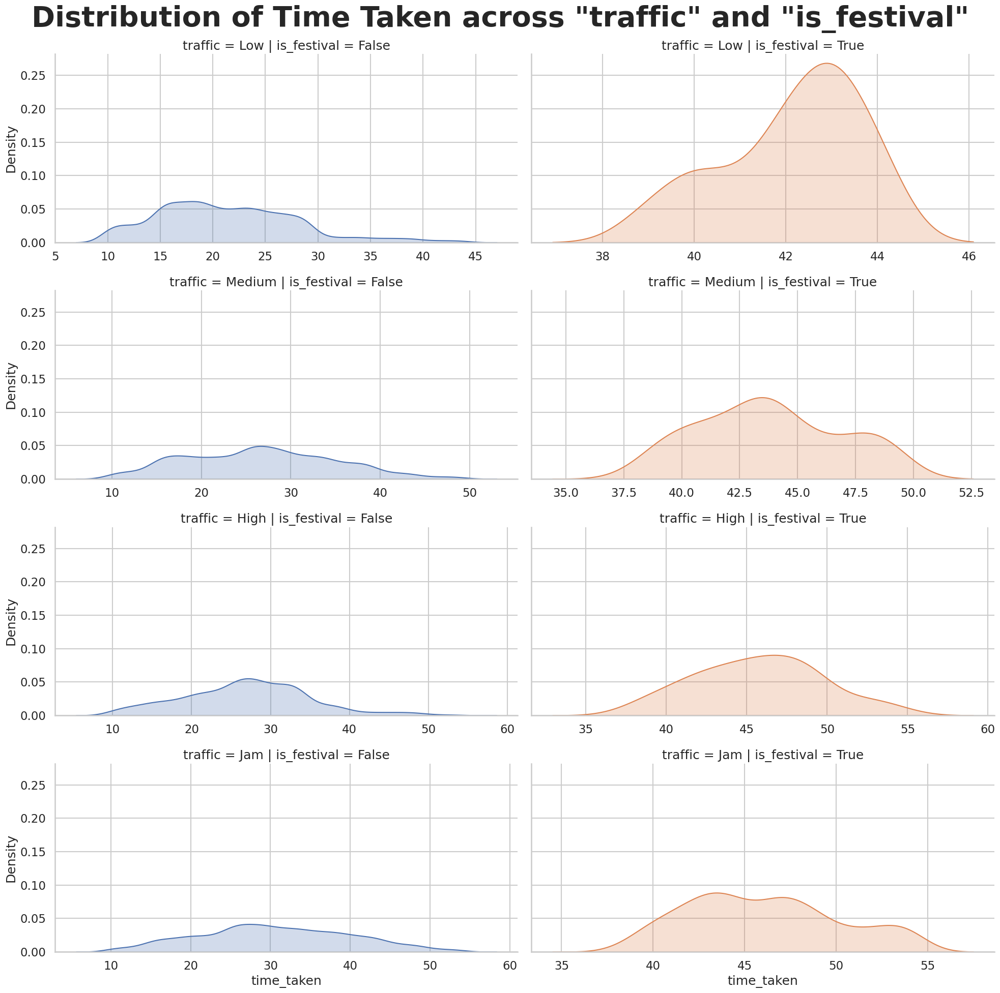

is_festival,False,True
traffic,,
Low,21.368170,42.130435
Medium,26.668115,43.779817
High,26.992342,45.727273
Jam,30.592953,46.041367


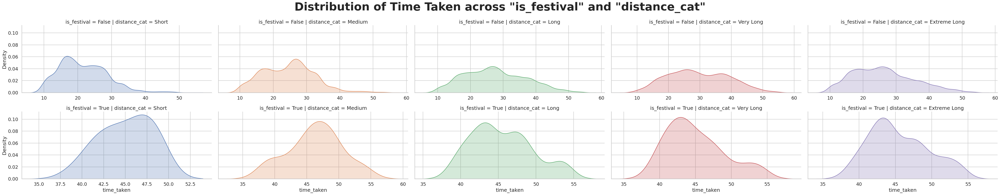

distance_cat,Short,Medium,Long,Very Long,Extreme Long
is_festival,,,,,
False,21.530998,24.580692,27.540740,29.470682,26.132810
True,45.050000,46.288136,45.498113,45.023256,45.493421


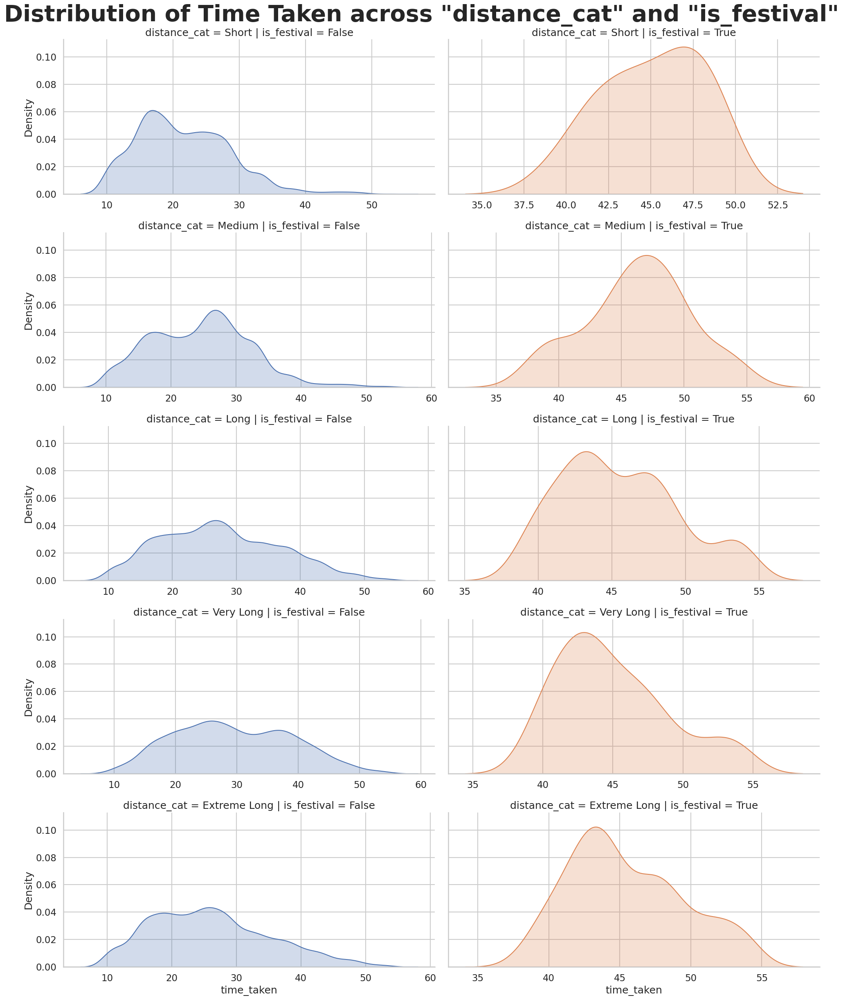

is_festival,False,True
distance_cat,,
Short,21.530998,45.050000
Medium,24.580692,46.288136
Long,27.540740,45.498113
Very Long,29.470682,45.023256
Extreme Long,26.132810,45.493421


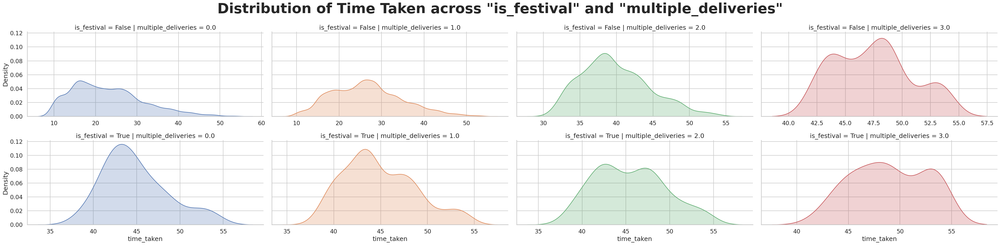

multiple_deliveries,0.0,1.0,2.0,3.0
is_festival,,,,
False,22.821194,26.619765,39.845815,47.453333
True,44.849057,44.893564,45.491803,48.940476


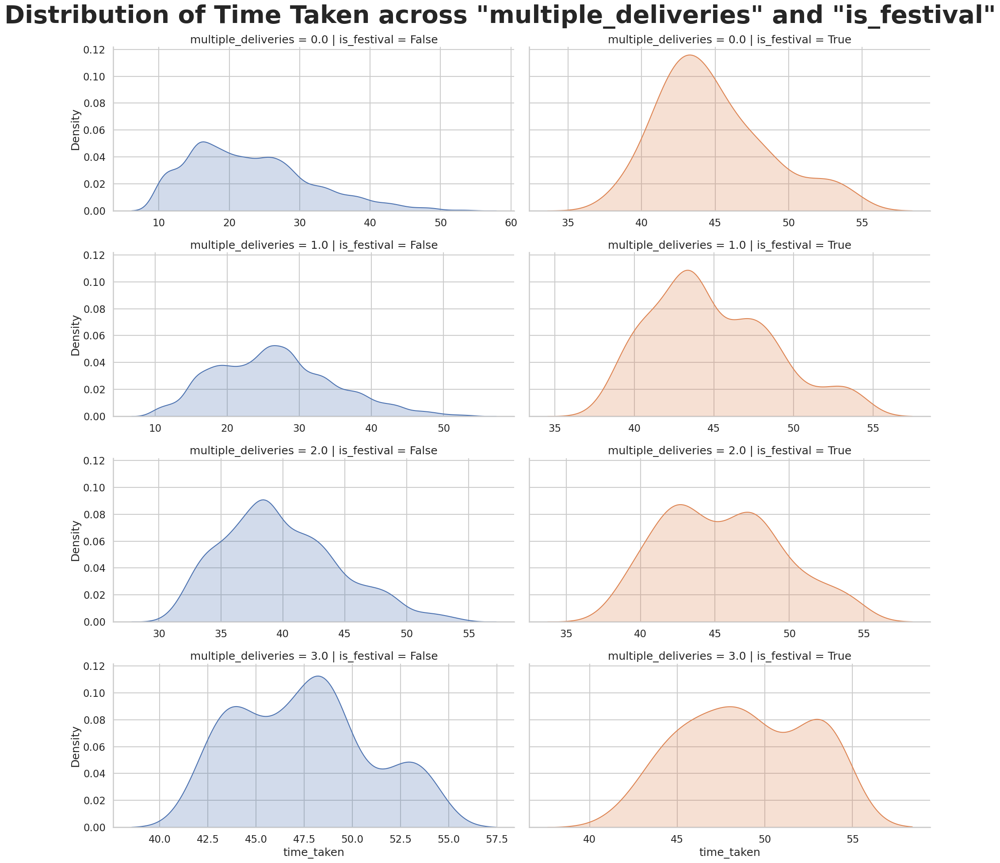

is_festival,False,True
multiple_deliveries,,
0.0,22.821194,44.849057
1.0,26.619765,44.893564
2.0,39.845815,45.491803
3.0,47.453333,48.940476


In [ ]:
get_multivariate_analysis_for_categorical_feature(df = new_df.copy(), feature_given = 'is_festival', plot_facet = ['traffic', 'distance_cat', 'multiple_deliveries'])

### c. Final Observations
- is_festival has a statistically significant relationship with time_taken

- **Only about 1.97% of rows are festival orders, but they behave very differently from the rest.**

- **Only about 1.97% of rows are festival orders, but average distance covered by the riders during festival time has marginally very high i.e. 4km + more**

- Festival orders take about 19-20 minutes longer on average

- The effect is also practically very strong

- Festival orders also have:
    
  - Traffic distribution changes drastically during festivals - A much larger proportion of jam traffic. But even within the same traffic category, festival deliveries remain slower. The delay gap remains visible even within the same traffic category, suggesting that **festivals introduce additional delay beyond traffic impact on time_taken.**

  - for `is_festival = True`, mutliple_deliveries itself effect the time_taken.  But even within the same stacked multiple_deliveries, festival deliveries remain slower, suggesting that **festivals introduce additional delay beyond multiple deliveries impact on time_taken**
    

---
**Final Conclusion :**

- **So `is_festival` is not just a proxy for distance, traffic & multiple deliveries**.
  
- **`is_festival` is likely an important predictor because captures a real shift in delivery time.**

- But `is_festival` alone itself doesn't cause higher delivery time.
  
- **`is_festival` is linked to a broader context of `longer distance routes`, `heavier traffic`, `multiple_deliveries` and along with others features, of which combined effect causes delay effects in delivery time.**

## 5.multiple_deliveries

### a.Uni-Variate Analysis

Data-Type: float64
Missing Value %: 2.18
Outlier count (IQR rule): 361


,multiple_deliveries
count,44509.00
mean,0.74
std,0.57
min,0.00
25%,0.00
50%,1.00
75%,1.00
max,3.00


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


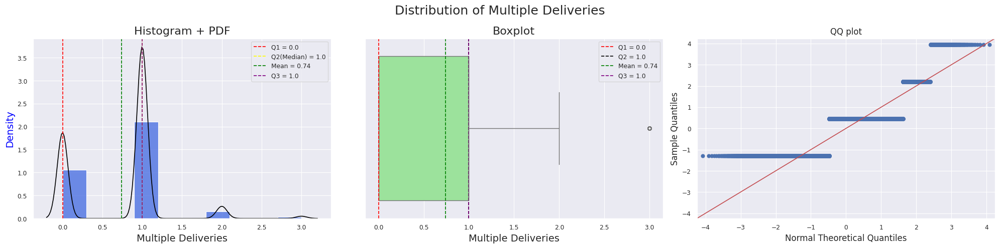

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Skewness: 0.3
Distribution of Multiple Deliveries is Right-Skewed
The right tail is longer
The mean is greater than the median, which is pulled higher by a few large extreme values.

But Overall Distribution of Multiple Deliveries is: Almost symmetrical

Excess Kurtosis: 0.912
Leptokurtic -> Distribution of Multiple Deliveries has "fat tails" and a "higher frequency of extreme outliers" than a Normal Distribution".

Omnibus Test for Normality
OB: Result: Reject Null Hypothesis. Data is not Normally Distributed

Anderson–Darling Test for Normality
AD: Result: Reject Null Hypothesis. Data is not Normally Distributed 

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_univariate_analysis_for_numerical_feature(df = df.copy(), feature = 'multiple_deliveries', num_bins = 10)

Data-Type of multiple_deliveries : float64
Unique values in multiple_deliveries : [ 0.  1.  3. nan  2.]
Total unique values in multiple_deliveries : 4
%of NaN values in multiple_deliveries : 2.18



,multiple_deliveries,counts,proportion
0,1.0,28109,0.6315
1,0.0,14057,0.3158
2,2.0,1982,0.0445
3,3.0,361,0.0081


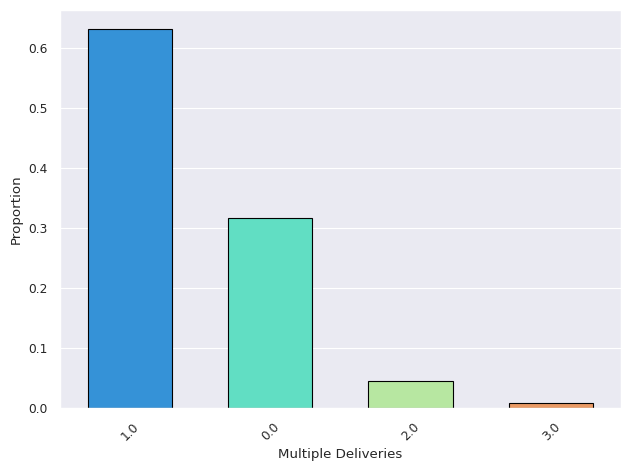

In [ ]:
get_univariate_analysis_for_categorical_feature(df = df.copy(), feature = 'multiple_deliveries')

Observations:

---
**1. Distribution Shape**

1. Key Stats:
   - Mean = 0.74
   - Median = 1
   - Q1 = 0
   - Q3 = 1
   - Max = 3
   - Skewness = 0.325 (slightly right-skewed)
   - Kurtosis = 0.912 (heavy tail)

2. Interpretation:   
   - **This is not continuous data**
   - It is a discrete variable with:  
     - Heavy concentration at 0 and 1
     - Very small concentration at 2
     - Extremely rare 3
   - Histogram confirms this:
     - Two dominant spikes at 0 and 1
     - Small spike at 2
     - Vey tiny at 3
   - So this is some kind of **0/1 dominant count feature.**

---
**2. The Outliers Are Not Real Outliers**

- IQR rule states 361 observations as outliers.
- But those are simply value = 3.
- That is not an outlier
- That is a rare category.
- **IQR method is inappropriate for discrete variables.**

---
**3. Categorical Perspective**
| Deliveries | %      |
| ---------- | ------ |
| 0          | 63.15% |
| 1          | 31.58% |
| 2          | 4.45%  |
| 3          | 0.81%  |

- Majority of riders handle 0 or 1 delivery.
- Handling 2 deliveries is uncommon.
- Handling 3 deliveries is very rare.

---
**4. Normality Tests Reject (Expected)**
- Normality tests rejecting is meaningless here because:
  - Data has only 4 possible values
  - Data is discrete not continuous
  - So rejecting normality is expected.

---
`multiple_deliveries` is:
 1. Discrete numerical
    - Data can take only specific separate values.
    - Often countable values
    - But can't take values in between those fixed points
    - For example: Multiple deliveries can be 0,1,2,3,4,5...so on
    - But Multiple deliveries can not be 1.25, 2.5, 3.2 etc
 2. Ordered
 3. Not continuous
 4. Highly imbalanced

---
Treat `multiple_deliveries` as **Ordinal Discrete numerical**

### b.Bi-Variate Analysis

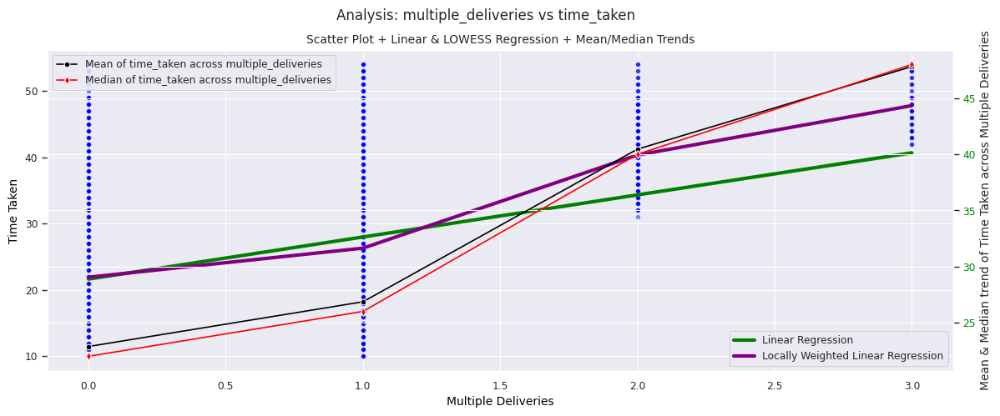

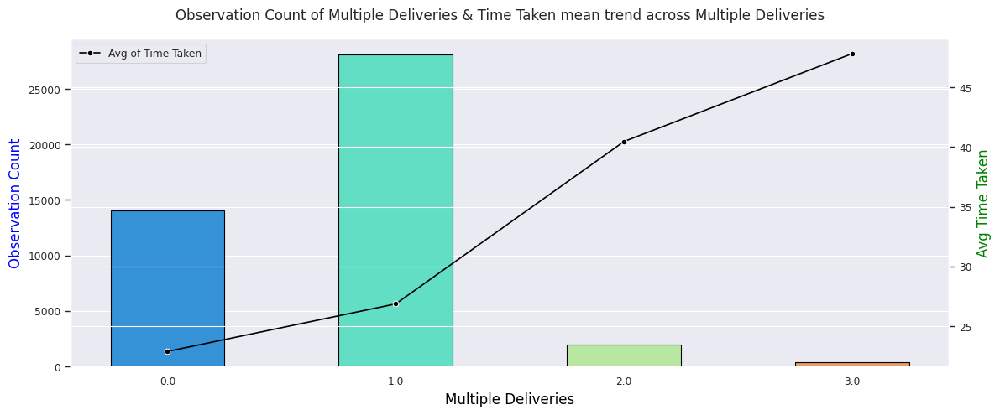

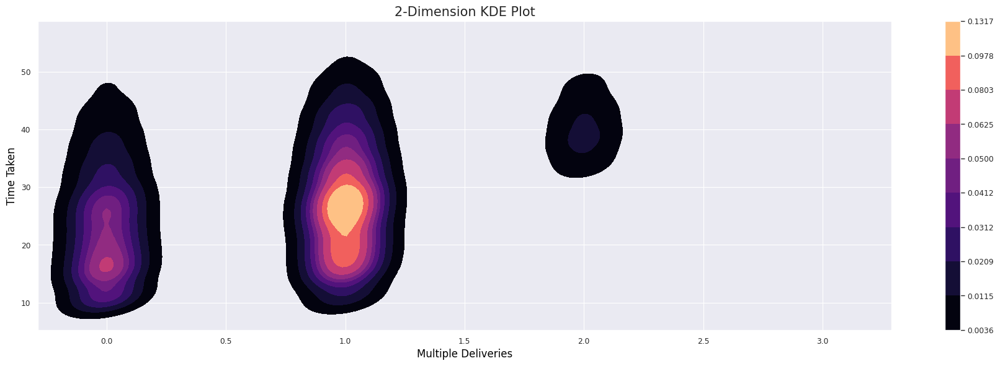

----------------------------------------------------------------------------------------------------------------------------------
STATISTICS FOR Multiple Deliveries vs Time Taken
Mutual Information: 0.1279 (Higher = more dependency)
Spearman Rank:      0.3396 (Robust to non-linear)
Pearson Coef:       0.3872

Result: Statistically significant monotonic association detected between Multiple Deliveries & Time Taken by Spearman Rank
----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_numerical_vs_numerical(df.copy(), feature = 'multiple_deliveries', feature_type = 'discrete', target = 'time_taken', palette = 'magma')

,multiple_deliveries,count,proportion_%,mean_time_taken,std_time_taken
0,0.0,14057,31.582,22.88,8.77
1,1.0,28109,63.154,26.86,8.54
2,2.0,1982,4.453,40.46,4.92
3,3.0,361,0.811,47.82,3.48


----------------------------------------------------------------------------------------------------------------------------------------------------------------


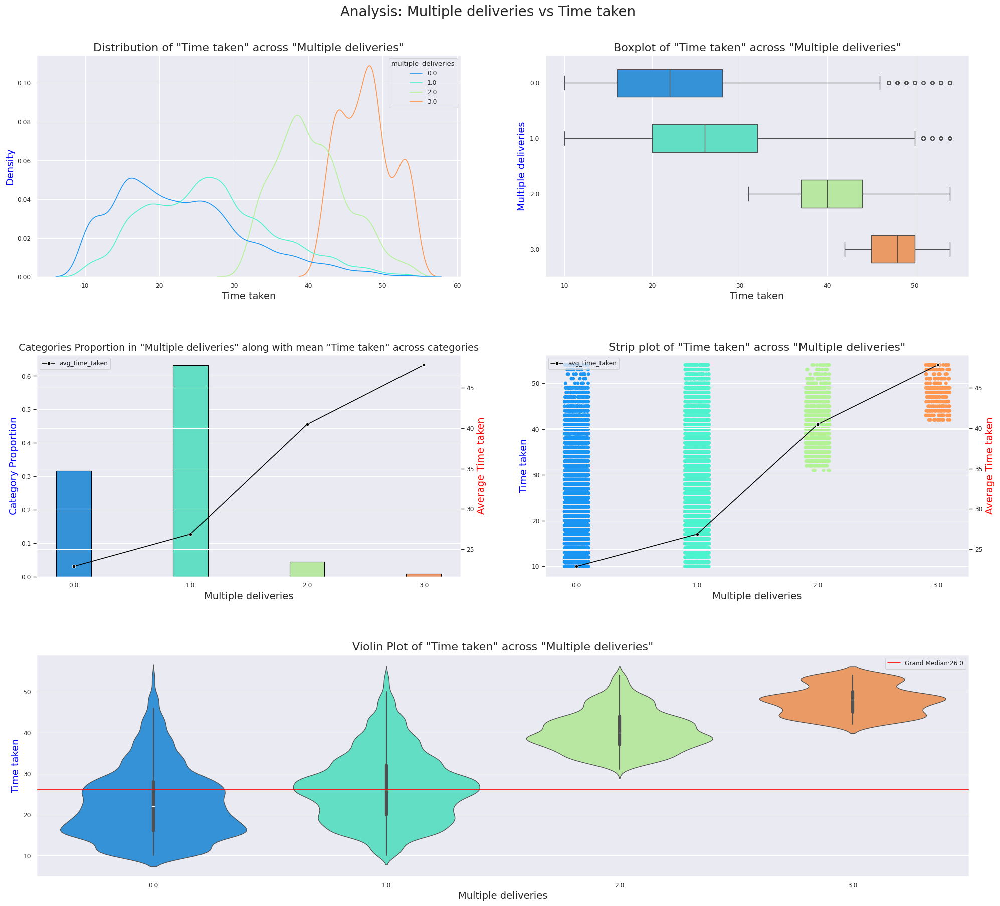

--------------------------------------------------------------------------------------------------------------------------------------------
Welch One-Way ANOVA (not assumed equal variance)

Reject Ho
Result: Significant difference in category mean of "time_taken" detected across "Multiple deliveries"
Result: Welch’s ANOVA indicates that atleast one category mean of "time_taken" is significantly differs from the rest of the others
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df.copy(), feature = 'multiple_deliveries', target = 'time_taken')

Q1. If a rider is doing multiple 2/3 deliveries, it does mean that they cover more distance that's leads to more time in delivery than riders with 0/1 deliveries ?

- **Yes**

,multiple_deliveries,count,proportion_%,mean_distance_km,std_distance_km
0,0.0,12919,31.535,9.10,5.56
1,1.0,25883,63.180,9.79,5.60
2,2.0,1838,4.487,12.94,4.80
3,3.0,327,0.798,13.03,4.65


----------------------------------------------------------------------------------------------------------------------------------------------------------------


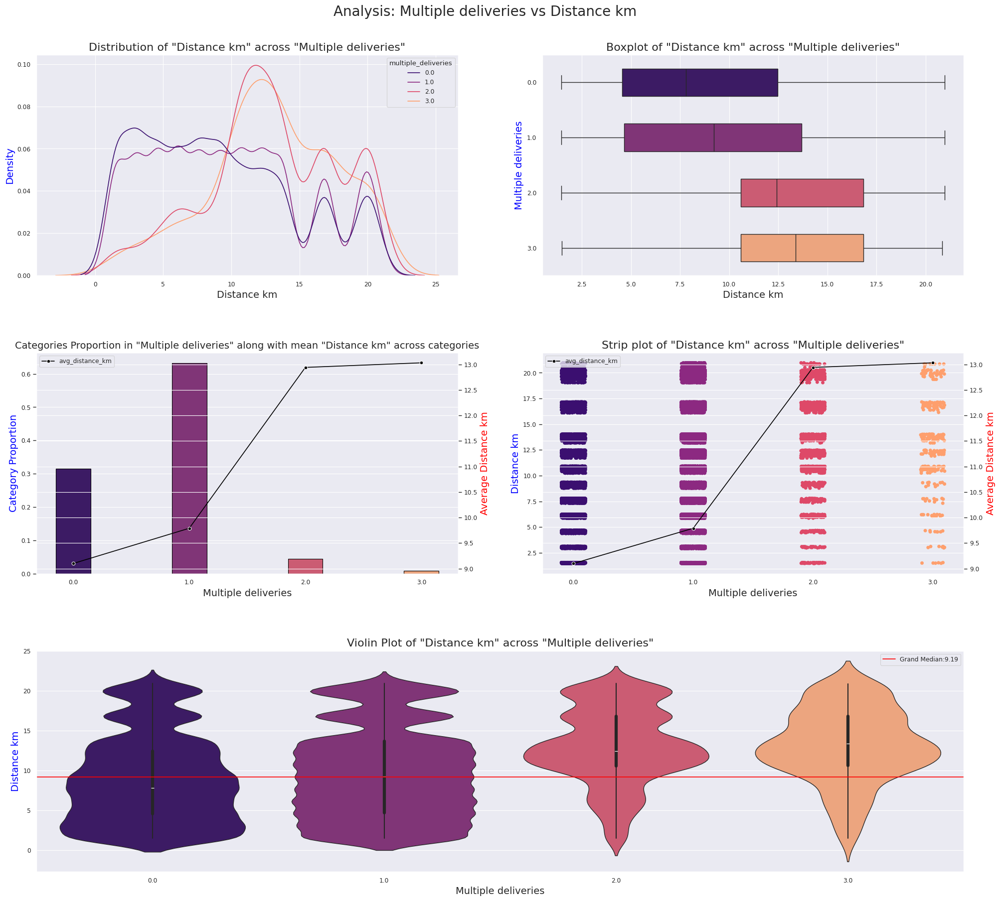

--------------------------------------------------------------------------------------------------------------------------------------------
Welch One-Way ANOVA (not assumed equal variance)

Reject Ho
Result: Significant difference in category mean of "distance_km" detected across "Multiple deliveries"
Result: Welch’s ANOVA indicates that atleast one category mean of "distance_km" is significantly differs from the rest of the others
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df.copy(), feature = 'multiple_deliveries', target = 'distance_km', palette = 'magma')

### c. Multi-Variate Analysis

In [ ]:
get_hypothesis_test_results_for_numerical_column(df = df.drop(columns = ['sin_hr','cos_hr']).copy(), feature_given = 'multiple_deliveries')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,multiple_deliveries,traffic,0.00,traffic,time_taken,0.00
1,multiple_deliveries,order_time_of_day,0.00,order_time_of_day,time_taken,0.00
2,multiple_deliveries,distance_km,0.00,distance_km,time_taken,0.00
3,multiple_deliveries,rider_age,0.00,rider_age,time_taken,0.00
4,multiple_deliveries,vehicle_condition,0.00,vehicle_condition,time_taken,0.00
5,multiple_deliveries,rider_ratings,0.00,rider_ratings,time_taken,0.00
6,multiple_deliveries,weather,0.00,weather,time_taken,0.00
7,multiple_deliveries,is_festival,0.00,is_festival,time_taken,0.00
8,multiple_deliveries,is_dinner_rush,0.00,is_dinner_rush,time_taken,0.00
9,multiple_deliveries,vehicle_type,0.00,vehicle_type,time_taken,0.00



Overall category-level summary:


,multiple_deliveries,avg_dist,avg_time
0,0.0,9.10,22.89
1,1.0,9.79,26.87
2,2.0,12.94,40.46
3,3.0,12.99,47.83



Feature × traffic analysis:


proportion  avg_dist  avg_time_taken
multiple_deliveries traffic                                      
0.0                 Low          0.4146    7.7079         19.2048
                    Medium       0.2338   10.4206         23.8072
                    High         0.0894    4.4514         24.0201
                    Jam          0.2623   11.7037         27.5292
1.0                 Low          0.3268    8.3365         22.3470
                    Medium       0.2513   11.1974         27.2389
                    High         0.1036    4.3789         27.6843
                    Jam          0.3183   11.9352         30.9639
2.0                 Low          0.0892   14.1975         38.5864
                    Medium       0.2324   13.9028         38.8791
                    High         0.0909    4.4256         39.8000
                    Jam          0.5876   13.6798         41.4789
3.0                 Low          0.0125   14.6858         43.5000
                    Medium       0.1406   14.3110         46.1778
                    High         0.0938    4.3987         47.6000
                    Jam          0.7531   13.7875         48.2407

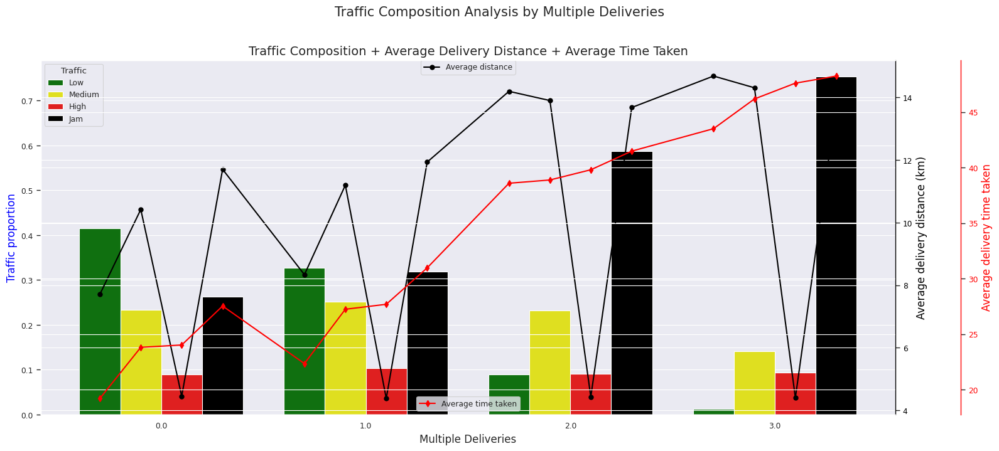

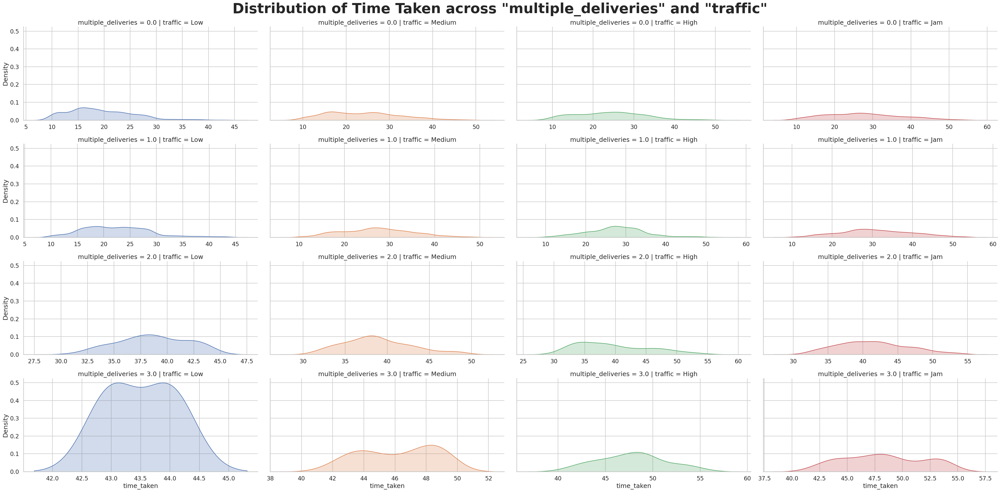

traffic,Low,Medium,High,Jam
multiple_deliveries,,,,
0.0,19.338264,23.907703,24.094804,27.581102
1.0,22.416056,27.293520,27.680702,30.977518
2.0,38.620253,38.867470,39.623457,41.455159
3.0,43.500000,46.177778,47.793103,48.268398


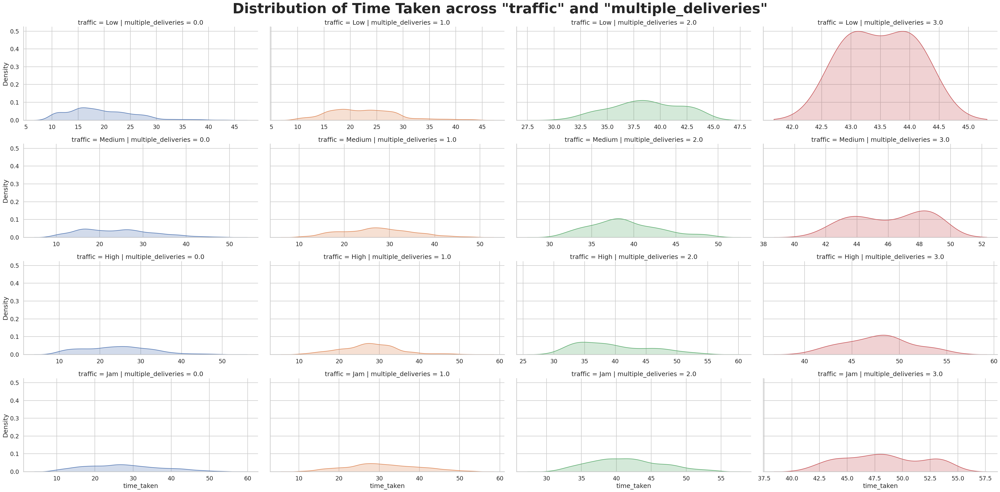

multiple_deliveries,0.0,1.0,2.0,3.0
traffic,,,,
Low,19.338264,22.416056,38.620253,43.500000
Medium,23.907703,27.293520,38.867470,46.177778
High,24.094804,27.680702,39.623457,47.793103
Jam,27.581102,30.977518,41.455159,48.268398


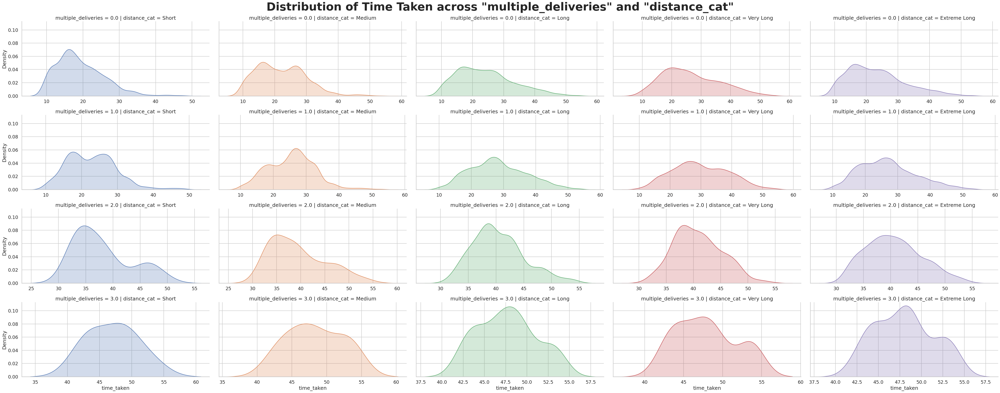

distance_cat,Short,Medium,Long,Very Long,Extreme Long
multiple_deliveries,,,,,
0.0,19.165101,22.032343,24.175641,26.388535,23.156243
1.0,22.794851,25.516896,28.301802,29.760797,26.950017
2.0,38.000000,39.389937,40.452951,40.839228,40.633914
3.0,47.000000,48.304348,47.666667,47.873016,47.982456


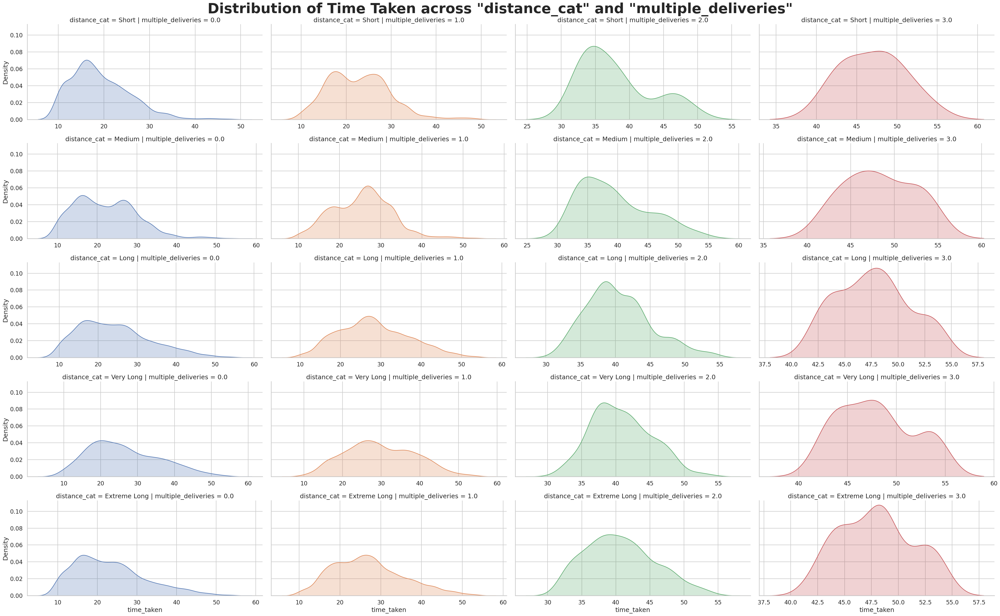

multiple_deliveries,0.0,1.0,2.0,3.0
distance_cat,,,,
Short,19.165101,22.794851,38.000000,47.000000
Medium,22.032343,25.516896,39.389937,48.304348
Long,24.175641,28.301802,40.452951,47.666667
Very Long,26.388535,29.760797,40.839228,47.873016
Extreme Long,23.156243,26.950017,40.633914,47.982456


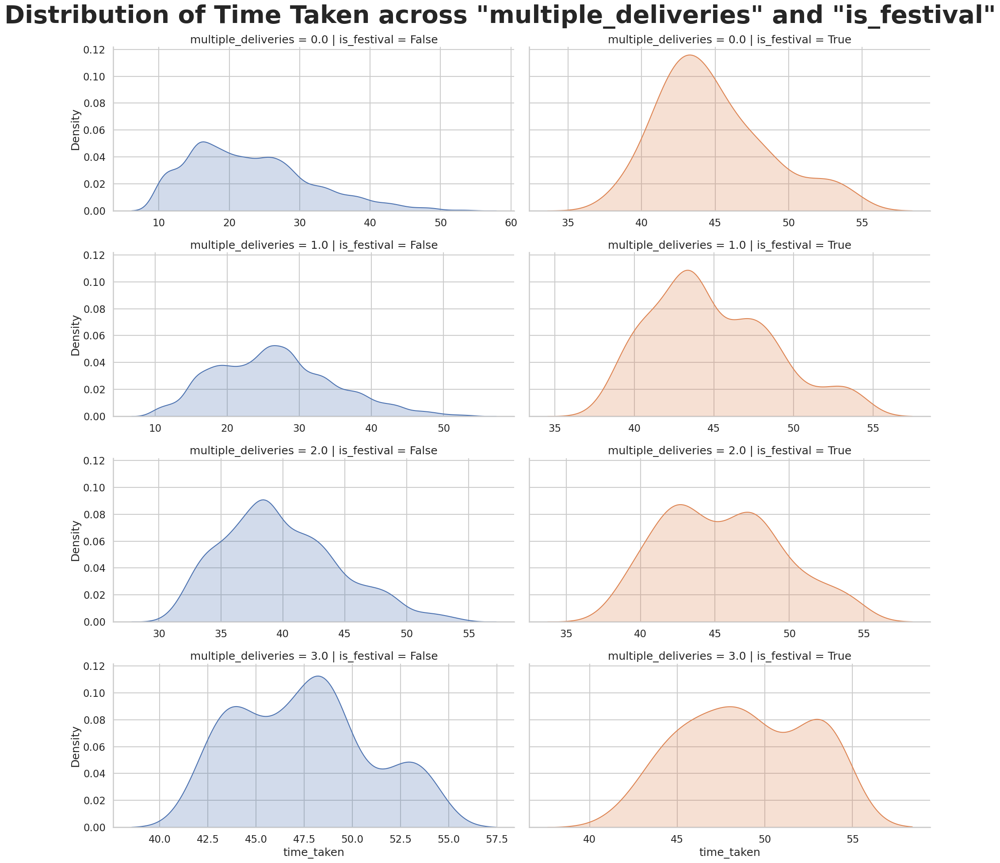

is_festival,False,True
multiple_deliveries,,
0.0,22.821194,44.849057
1.0,26.619765,44.893564
2.0,39.845815,45.491803
3.0,47.453333,48.940476


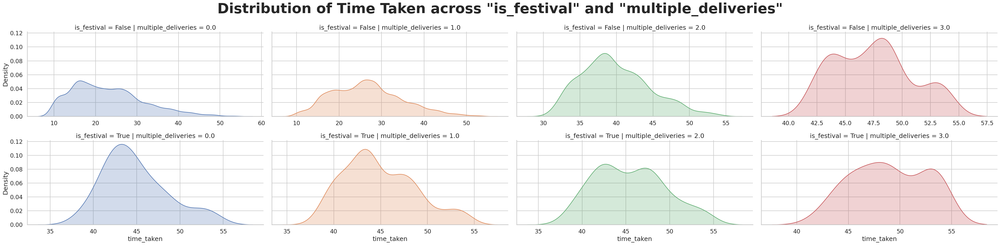

multiple_deliveries,0.0,1.0,2.0,3.0
is_festival,,,,
False,22.821194,26.619765,39.845815,47.453333
True,44.849057,44.893564,45.491803,48.940476


In [ ]:
get_multivariate_analysis_for_categorical_feature(new_df.copy(), feature_given = 'multiple_deliveries', plot_facet = ['traffic', 'distance_cat', 'is_festival'])

### d. Final Observations

---
**1. Correlation Interpretation**
- Spearman 0.3396 indicates a moderate monotonic association  
- Pearson 0.3872 indicates a moderate positive linear association  
- This suggests a reasonably strong positive relationship between multiple_deliveries and time_taken  
- As the number of deliveries handled in a single trip increases, the total delivery time tends to increase  
- It means: Riders handling more deliveries during a trip generally require more time to complete the route  

---
**2. Scatter Plot, LOWESS, Mean and Median Trend Interpretation**
- The scatter plot clearly shows that higher values of multiple_deliveries correspond to higher delivery times  
- The regression line has a upward slope  
- The LOWESS curve also shows a strong upward trend as the number of deliveries increases  
- The mean and median delivery times increase sharply as the number of deliveries increases  
- Increasing delivery stacking leads to longer delivery duration  
- Each additional delivery significantly increases the total delivery time  
- But Since the distribution of time_taken is evenly spread from 10 to 54 minutes even when deliveries are 0/1 but the mean/median time taken is still very low

---
**3. Distribution of Orders Across Multiple Deliveries**
- The bar chart shows that most observations fall into the categories of 0 or 1 delivery  
- Very few observations exist for 2 or 3 deliveries  
- The dataset is heavily concentrated around single-delivery trips  

---
**4. Explained Variation Insight**
- Using Pearson correlation approximately R2 Score = 0.3872^2 = 0.15

- **Around 15 % of the variation in delivery time can be explained by the number of deliveries alone**

- This implies that around 85% of the variation in delivery time is driven by other variables or combination of other variables.

- `multiple_deliverieries` tends to provide useful & stronger predictive information. **However `multiple_deliveries` alone cannot fully explain variation in time_taken**

---
**5. This is Real Picture**
- multiple_deliveries has a statistically significant, clear and meaningful relationship with time_taken  

- | multiple_deliveries |	num_count	| avg_dist |avg_time |
|---------------------|-----------|----------|---------|
| 0                   |	14057	    | 9 km    | 23 min  |
| 1	                  | 28109	    | 10 km	 | 27 min  |
| 2	                  | 1982	    | 13 km   | 40 min  |
| 3	                  | 361	      | 13 km	 | 48 min  |

- The effect is also practically very strong

- multiple deliveries orders have:
  
  - higher average distance : means rider covering more distance
  - Delivery stacking increases travel distance    
    - Since riders must take additional stop time at customer locations  
  - Therefore: Multi-order deliveries naturally increase total delivery duration
  
  - Traffic distribution changes drastically when multiple_deliveries count increase from 1 to 2 count and to 3 - A much larger proportion of traffic Jam.
  
  - But within the same traffic category, multiple stacked deliveries remain slower. The delay gap remains visible even within the same traffic category, suggesting that **`multiple_deliveries introduce additional delay beyond traffic alone.`**

  - From facetgrid you can see that is_festival impact time taken within same stacked delivery. The delay gap remains visible even within the same stacked delivery. But within the is_fesival(False & True), multiple stacked deliveries remain slower. The delay gap remains visible even within the is_fesival(False & True) category , suggesting that **`multiple_deliveries introduce additional delay beyond is_festival alone.`**

  - Same analysis goes in case of distance_km, as **`multiple_deliveries introduce additional delay beyond distance_cat alone.`**
     
  - **So  `multiple deliveries` is not just a proxy for distance, traffic &  is_festival**

  - **`multiple_deliveries` is likely an important predictor because it itself captures a real shift in delivery time.**

  - But `multiple_deliveries` along itself doesn't cause higher delivery time.

  - `multiple_deliveries` **is linked to a broader context of `longer distance routes`, `heavier traffic`, `festival` and may also along with others features, of which combined effect causes delay effects in delivery time.**

## 6.vehicle_type

### a. Uni & Bi-Variate Analysis

Data-Type of vehicle_type : object
Unique values in vehicle_type : ['Motor-Cycle' 'Scooter' 'Electric-Scooter' 'Bicycle']
Total unique values in vehicle_type : 4
%of NaN values in vehicle_type : 0.0



,vehicle_type,counts,proportion
0,Motor-Cycle,26427,0.5808
1,Scooter,15244,0.3350
2,Electric-Scooter,3778,0.0830
3,Bicycle,53,0.0012


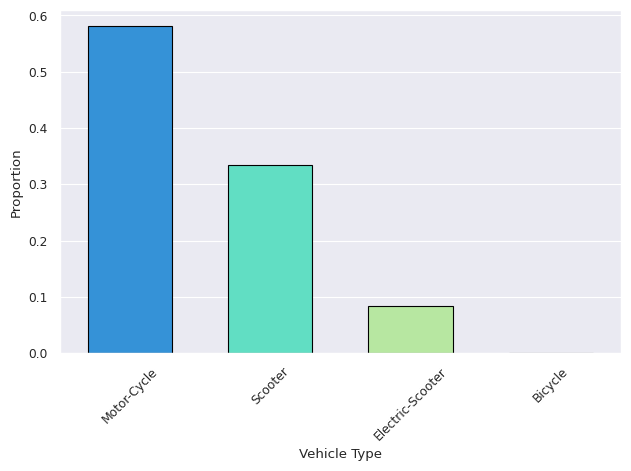

In [ ]:
get_univariate_analysis_for_categorical_feature(df = df.copy(), feature = 'vehicle_type')

,vehicle_type,count,proportion_%,mean_time_taken,std_time_taken
0,Electric-Scooter,3778,8.303,24.48,8.62
1,Scooter,15244,33.502,24.48,8.71
2,Bicycle,53,0.116,26.72,9.76
3,Motor-Cycle,26427,58.079,27.61,9.65


----------------------------------------------------------------------------------------------------------------------------------------------------------------


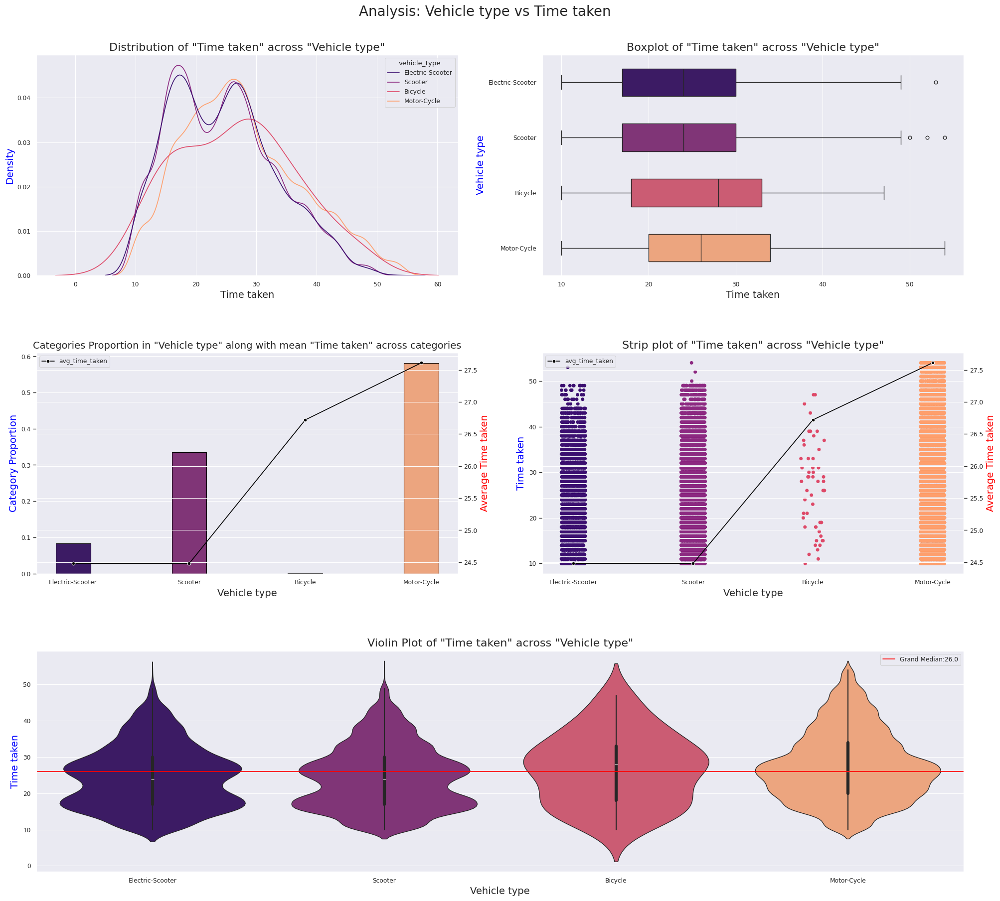

--------------------------------------------------------------------------------------------------------------------------------------------
Welch One-Way ANOVA (not assumed equal variance)

Reject Ho
Result: Significant difference in category mean of "time_taken" detected across "Vehicle type"
Result: Welch’s ANOVA indicates that atleast one category mean of "time_taken" is significantly differs from the rest of the others
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df.copy(), feature = 'vehicle_type', target = 'time_taken', palette = 'magma')

### b. Muti-Variate Analysis

In [ ]:
get_hypothesis_test_results_for_categorical_column(df = new_df.copy(), feature_given = 'vehicle_type')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,vehicle_type,vehicle_condition,0.0,vehicle_condition,time_taken,0.0
1,vehicle_type,is_festival,0.0,is_festival,time_taken,0.0
2,vehicle_type,rider_ratings,0.0,rider_ratings,time_taken,0.0
3,vehicle_type,multiple_deliveries,0.0,multiple_deliveries,time_taken,0.0



Overall category-level summary:


,vehicle_type,avg_dist,avg_time
0,Electric-Scooter,9.72,24.36
1,Scooter,9.77,24.50
2,Motor-Cycle,9.69,27.61



Feature × traffic analysis:


proportion  avg_dist  avg_time_taken
vehicle_type     traffic                                      
Electric-Scooter Low          0.3353    8.2802         19.9510
                 Medium       0.2492   10.9156         24.9963
                 High         0.0955    4.2930         24.9013
                 Jam          0.3200   11.9246         28.3270
Scooter          Low          0.3408    8.1475         20.0138
                 Medium       0.2441   11.1471         24.9145
                 High         0.0978    4.3823         25.0266
                 Jam          0.3172   12.1014         28.8336
Motor-Cycle      Low          0.3453    8.1335         22.1675
                 Medium       0.2425   11.0506         28.0080
                 High         0.0990    4.4196         28.7699
                 Jam          0.3131   12.0215         32.9364

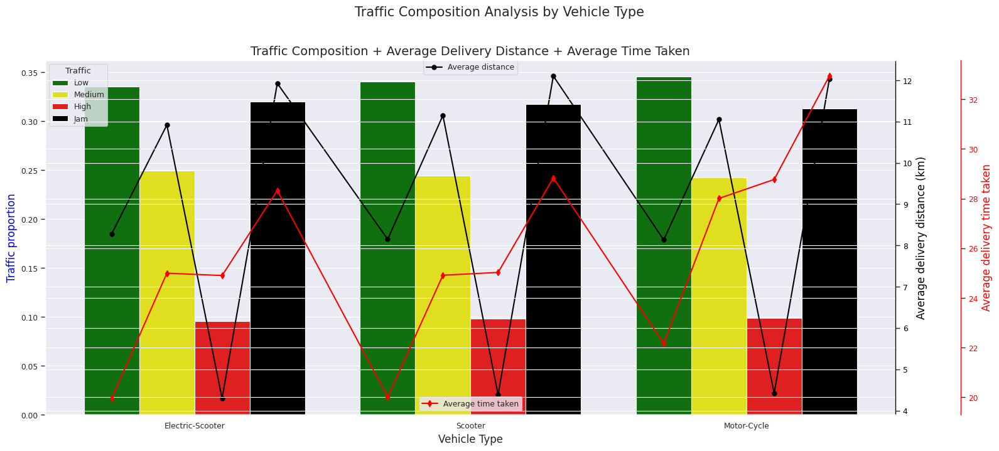

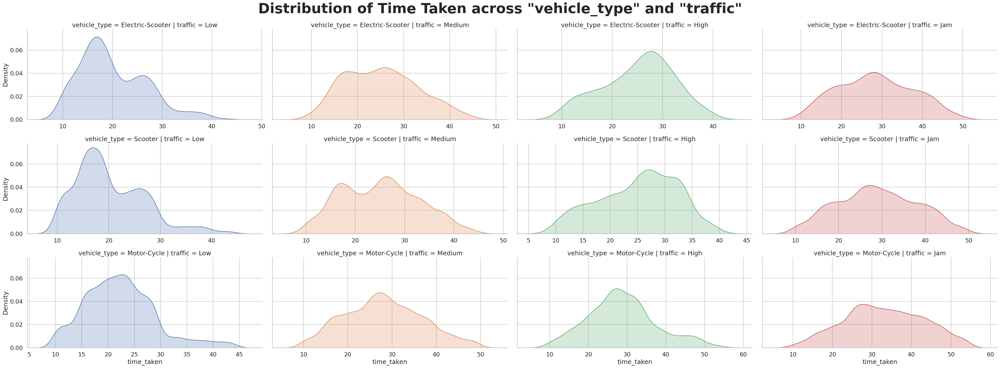

traffic,Low,Medium,High,Jam
vehicle_type,,,,
Electric-Scooter,20.086207,25.164508,25.158249,28.485456
Scooter,20.184770,25.068074,25.136505,28.923391
Motor-Cycle,22.318112,28.114801,28.821900,33.033476


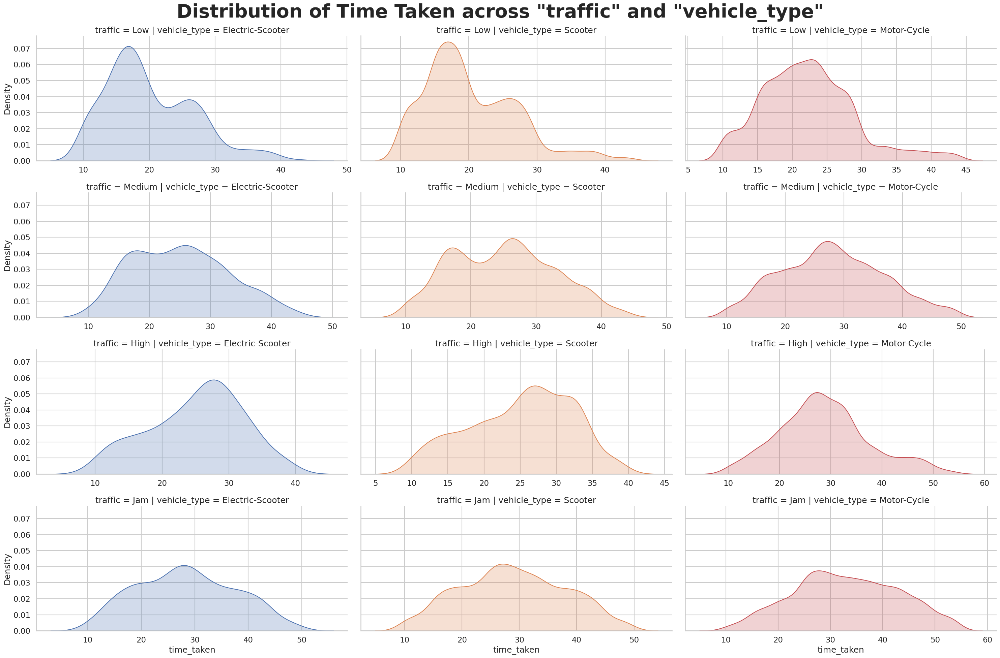

vehicle_type,Electric-Scooter,Scooter,Motor-Cycle
traffic,,,
Low,20.086207,20.184770,22.318112
Medium,25.164508,25.068074,28.114801
High,25.158249,25.136505,28.821900
Jam,28.485456,28.923391,33.033476


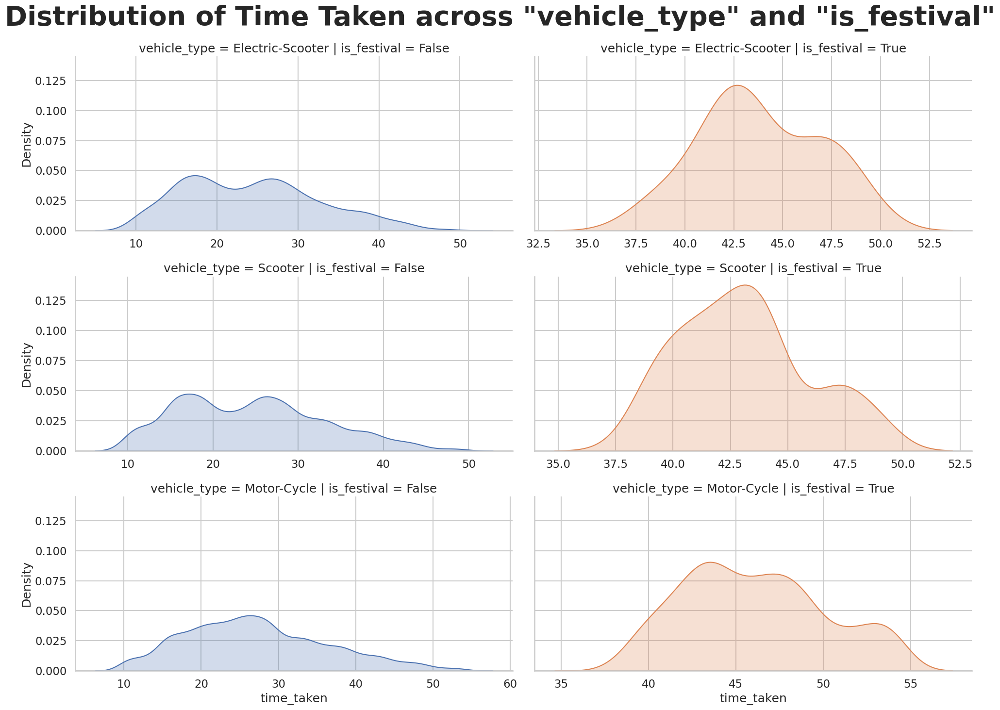

is_festival,False,True
vehicle_type,,
Electric-Scooter,24.342097,43.827586
Scooter,24.472075,43.073529
Motor-Cycle,27.246936,46.075163


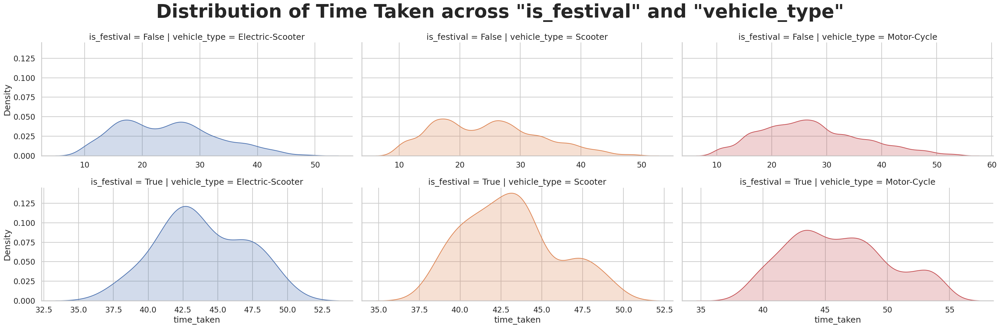

vehicle_type,Electric-Scooter,Scooter,Motor-Cycle
is_festival,,,
False,24.342097,24.472075,27.246936
True,43.827586,43.073529,46.075163


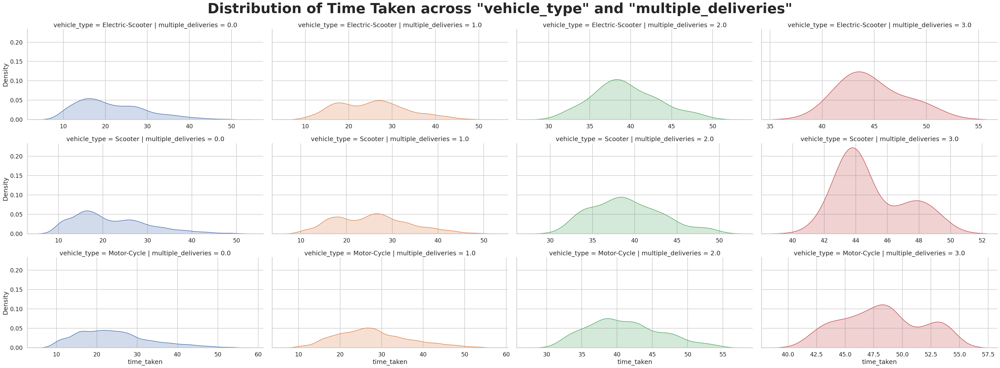

multiple_deliveries,0.0,1.0,2.0,3.0
vehicle_type,,,,
Electric-Scooter,21.501408,25.340909,39.342857,44.750000
Scooter,21.628327,25.513814,39.014118,44.960000
Motor-Cycle,24.149287,27.905224,41.004831,48.160714


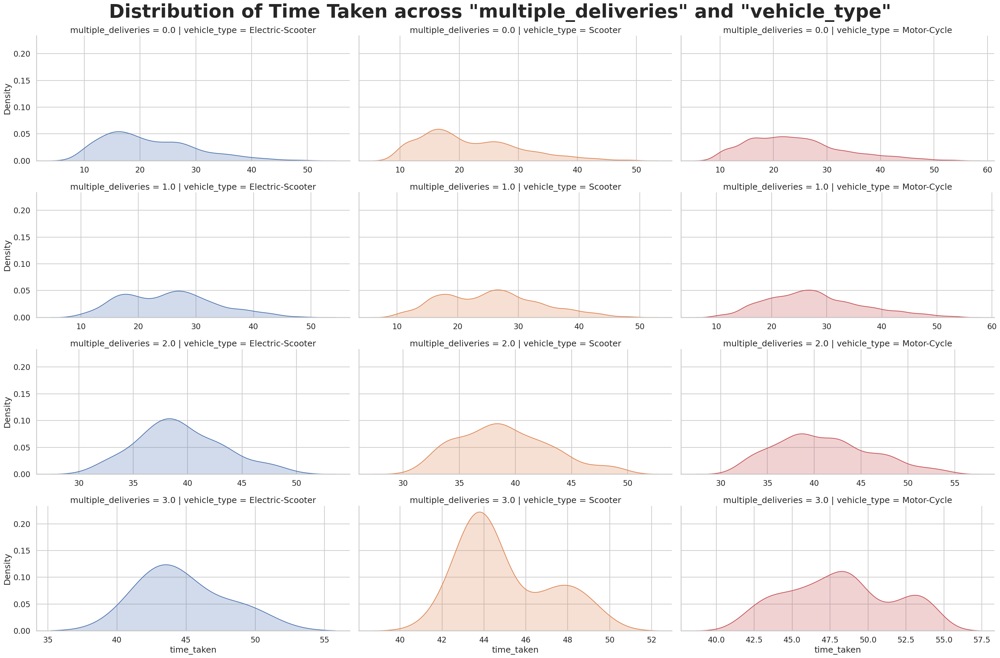

vehicle_type,Electric-Scooter,Scooter,Motor-Cycle
multiple_deliveries,,,
0.0,21.501408,21.628327,24.149287
1.0,25.340909,25.513814,27.905224
2.0,39.342857,39.014118,41.004831
3.0,44.750000,44.960000,48.160714


In [ ]:
get_multivariate_analysis_for_categorical_feature(df = new_df.copy(), feature_given = 'vehicle_type', plot_facet = ['traffic', 'is_festival', 'multiple_deliveries'])

### c. Final Observations

1. Motor-Cycle is the most common vehicle type among others

2. Bicycle looks slower than Scooter/Electric-Scooter, but sample size is too tiny. Bicycle should not be trusted much because count = 53

3. Among the common categories, Electric-Scooter and Scooter show almost identical delivery-time behavior, whereas Motor-Cycle has a the highest average delivery time among the categories.

4. Electric-Scooter and Scooter are almost identical. Both have almost same mean, same median, similar spread, similar average distance. So in your data, Scooter and Electric-Scooter behave very similarly with respect to time_taken

5. Motor-Cycle is about 3 minutes slower on average than Electric-Scooter and Scooter. That is a real difference, but it is not as bigger as what we saw for is_festival

---
6. From the traffic Composition Analysis by Vechicle Type, we can see that within the same vehicle category, the **`time_taken` follows increasing trend as the traffic congestion changes from: Low -> Medium -> High -> Jam**

7. vehicle_type has a statistically significant relationship with delivery time. There is statistical significance but practical significance is very less, not huge as we can see this from multiple figures of facet_plots

8. Interaction plots show that `traffic`, `is_festival`, `multiple_deliveries` substantially increase time_taken across all vehicle types. Festival orders & multiple_deliveries shift delivery-time distributions regardless of vehicle type.

9. The effect on distribution of `time_taken` within the vehicle type catgeory is more driven by `traffic` and `multiple_deliveries`, `is_festival` are they leads to significant changes in pdf of `time_taken`.

10. Maybe vehicle_type has some real independent small effect or maybe vehicle_type is acting as a proxy for some other hidden variable. Our hypothesis-test table supports that idea, that vehicle_type is significantly associated with: vehicle_condition, multiple_deliveries, is_festival, rider_ratings with p-values = 0.

11. It means vehicle_type does not exist in isolation. It is related to several other variables that themselves affect time_taken. So the observed vehicle-type effect may be directly effect time_taken and maybe partly through these features.

---
**Final Conclusion:**

- Although vehicle_type shows some overall association with delivery time, much of the observed variation appears to be explained more strongly by features such as `traffic`,`is_festival` & `multiple_deliveries`

 ## 7.vehicle_condition

### a. Uni & Bi-Variate Analysis

Data-Type of vehicle_condition : object
Unique values in vehicle_condition : ['2' '0' '1' '3']
Total unique values in vehicle_condition : 4
%of NaN values in vehicle_condition : 0.0



,vehicle_condition,counts,proportion
0,2,15034,0.3304
1,1,15030,0.3303
2,0,15009,0.3299
3,3,429,0.0094


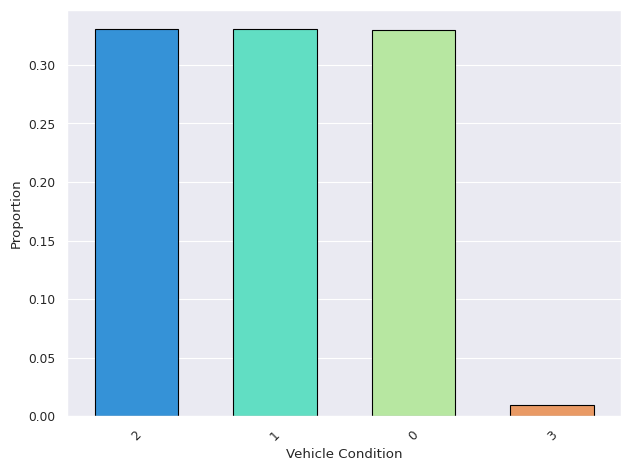

In [ ]:
get_univariate_analysis_for_categorical_feature(df = df.copy(), feature = 'vehicle_condition')

,vehicle_condition,count,proportion_%,mean_time_taken,std_time_taken
0,1,15030,33.032,24.36,8.72
1,2,15034,33.040,24.46,8.64
2,3,429,0.943,26.85,9.64
3,0,15009,32.985,30.07,9.60


----------------------------------------------------------------------------------------------------------------------------------------------------------------


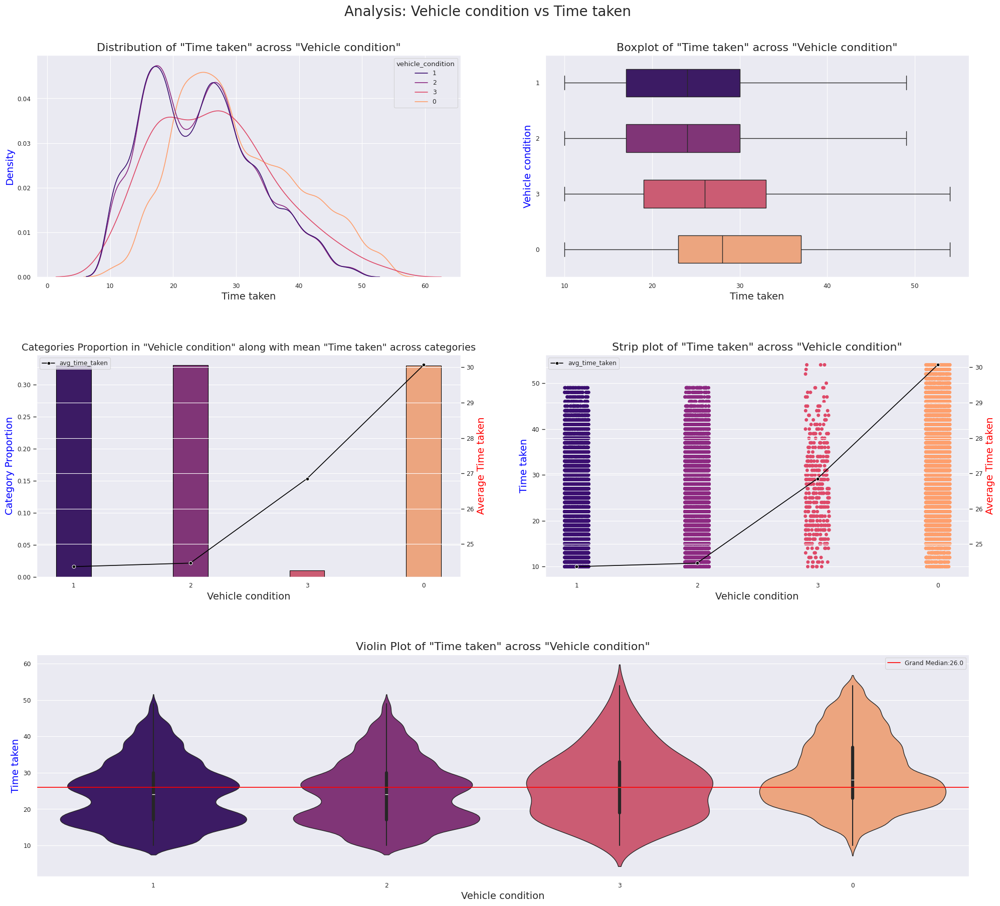

--------------------------------------------------------------------------------------------------------------------------------------------
Welch One-Way ANOVA (not assumed equal variance)

Reject Ho
Result: Significant difference in category mean of "time_taken" detected across "Vehicle condition"
Result: Welch’s ANOVA indicates that atleast one category mean of "time_taken" is significantly differs from the rest of the others
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df.copy(), feature = 'vehicle_condition', target = 'time_taken', palette = 'magma')

### b. Multi-Variate Analysis

In [ ]:
get_hypothesis_test_results_for_categorical_column(df = new_df.copy(), feature_given = 'vehicle_condition')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,vehicle_condition,vehicle_type,0.0,vehicle_type,time_taken,0.0
1,vehicle_condition,is_festival,0.0,is_festival,time_taken,0.0
2,vehicle_condition,rider_ratings,0.0,rider_ratings,time_taken,0.0
3,vehicle_condition,multiple_deliveries,0.0,multiple_deliveries,time_taken,0.0



Overall category-level summary:


,vehicle_condition,avg_dist,avg_time
0,1,9.69,24.37
1,2,9.79,24.48
2,0,9.67,30.09



Feature × traffic analysis:


proportion  avg_dist  avg_time_taken
vehicle_condition traffic                                      
1                 Low          0.3393    8.0603         19.8239
                  Medium       0.2403   11.0513         24.6592
                  High         0.1006    4.4072         25.1438
                  Jam          0.3198   12.0541         28.7424
2                 Low          0.3393    8.2226         19.9611
                  Medium       0.2456   11.1646         25.0171
                  High         0.0963    4.3146         24.9789
                  Jam          0.3187   12.0633         28.7201
0                 Low          0.3504    8.1654         23.9716
                  Medium       0.2448   10.9994         30.4767
                  High         0.0981    4.4687         31.5769
                  Jam          0.3067   12.0028         36.2967

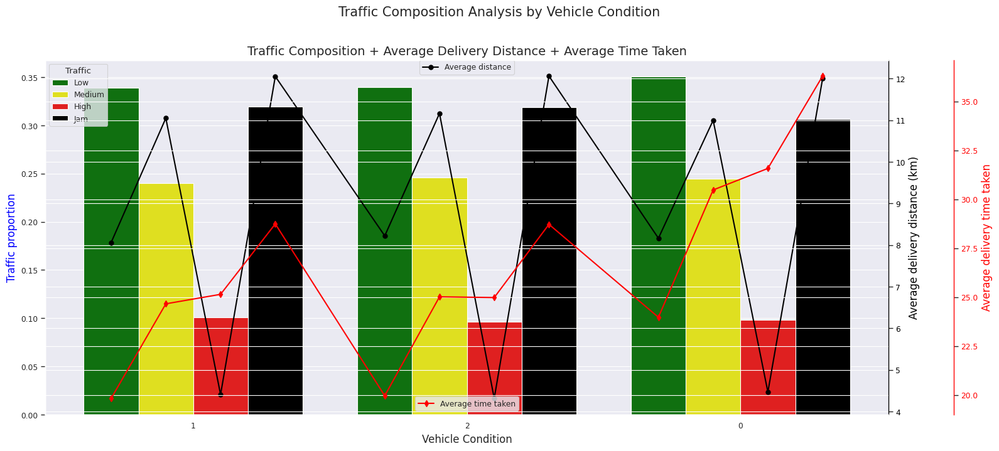

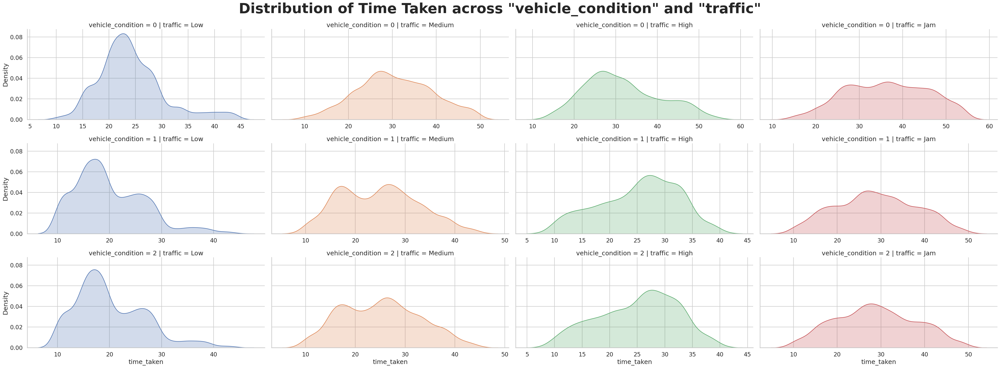

traffic,Low,Medium,High,Jam
vehicle_condition,,,,
0,24.089735,30.552002,31.554945,36.340283
1,19.979071,24.802552,25.297953,28.871384
2,20.121045,25.164577,25.134127,28.830062


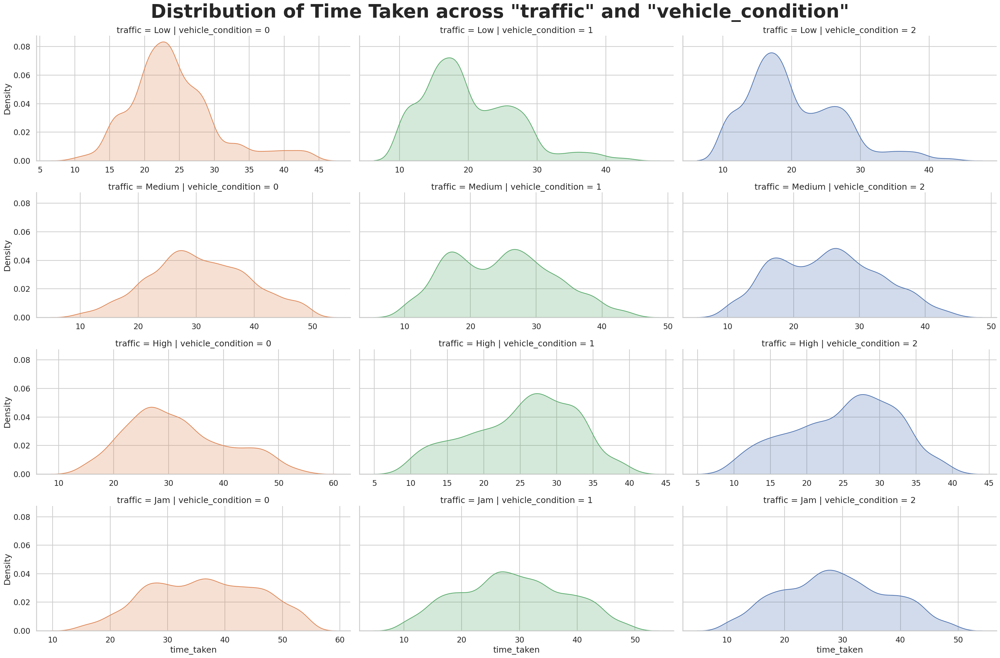

vehicle_condition,0,1,2
traffic,,,
Low,24.089735,19.979071,20.121045
Medium,30.552002,24.802552,25.164577
High,31.554945,25.297953,25.134127
Jam,36.340283,28.871384,28.830062


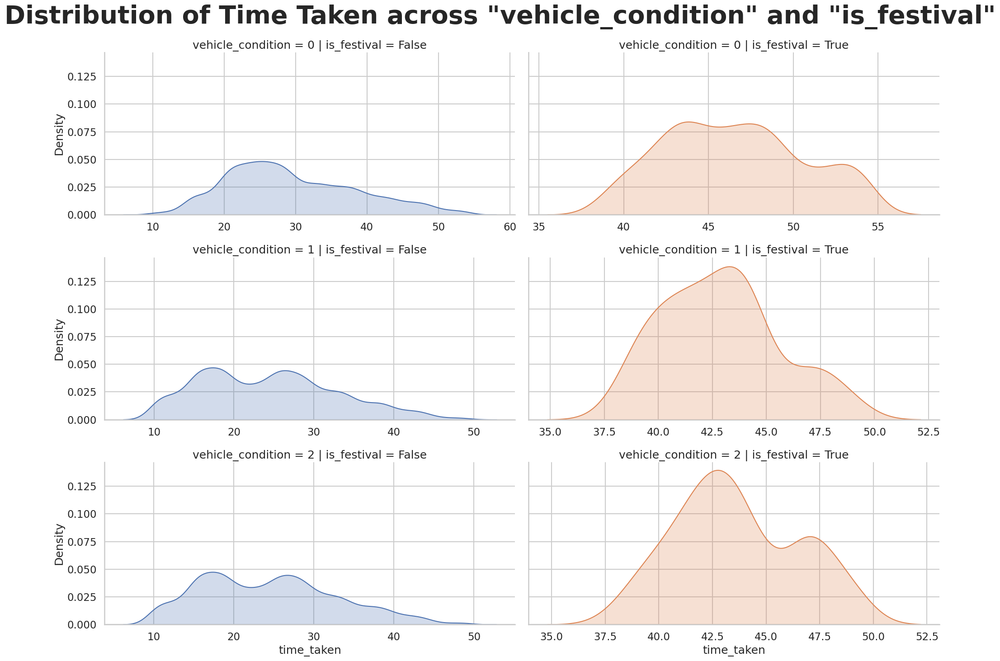

is_festival,False,True
vehicle_condition,,
0,29.494152,46.522901
1,24.384771,42.869565
2,24.443277,43.615942


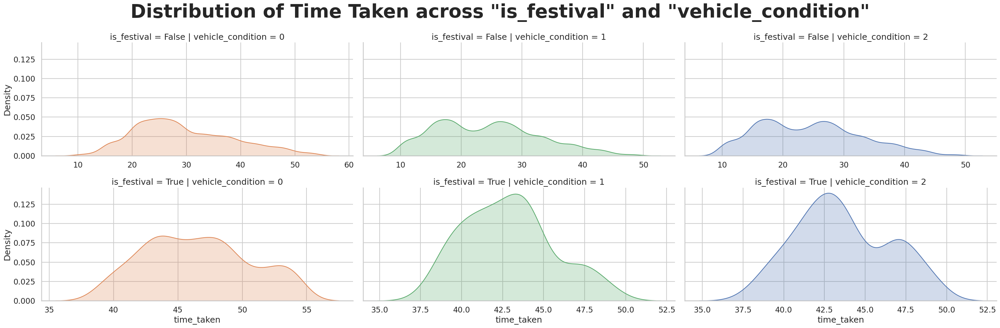

vehicle_condition,0,1,2
is_festival,,,
False,29.494152,24.384771,24.443277
True,46.522901,42.869565,43.615942


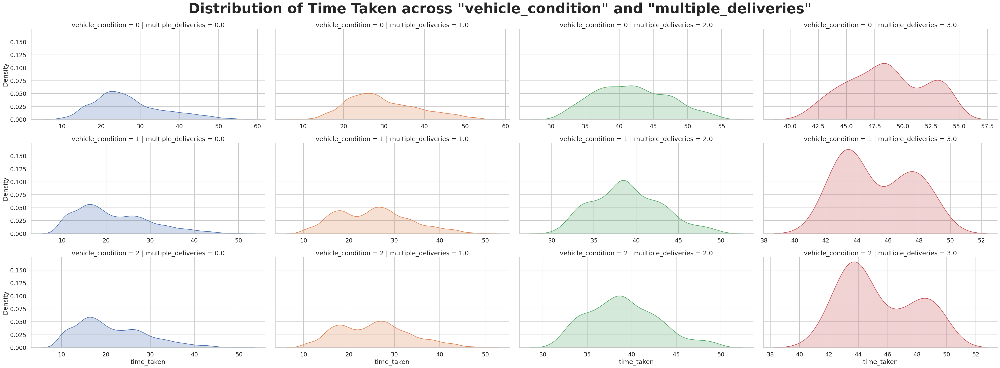

multiple_deliveries,0.0,1.0,2.0,3.0
vehicle_condition,,,,
0,26.977668,29.719962,41.829431,48.561983
1,21.507850,25.350633,38.945498,45.243243
2,21.424018,25.543219,39.037528,45.400000


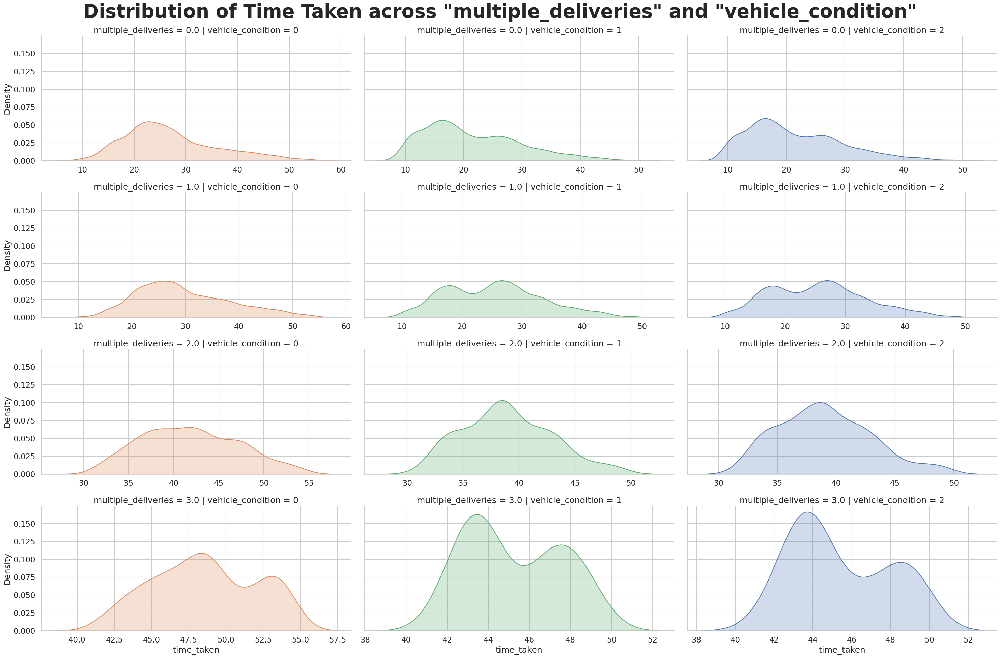

vehicle_condition,0,1,2
multiple_deliveries,,,
0.0,26.977668,21.507850,21.424018
1.0,29.719962,25.350633,25.543219
2.0,41.829431,38.945498,39.037528
3.0,48.561983,45.243243,45.400000


In [ ]:
get_multivariate_analysis_for_categorical_feature(df = new_df.copy(), feature_given = 'vehicle_condition',
                                                  plot_facet = ['traffic', 'is_festival', 'multiple_deliveries'])

### c. Final Observations
- Same like vehicle_type

## 8.order_type

### a. Uni & Bi-Variate Analysis

Data-Type of order_type : object
Unique values in order_type : ['Snack' 'Drinks' 'Buffet' 'Meal']
Total unique values in order_type : 4
%of NaN values in order_type : 0.0



,order_type,counts,proportion
0,Snack,11512,0.2530
1,Meal,11435,0.2513
2,Drinks,11294,0.2482
3,Buffet,11261,0.2475


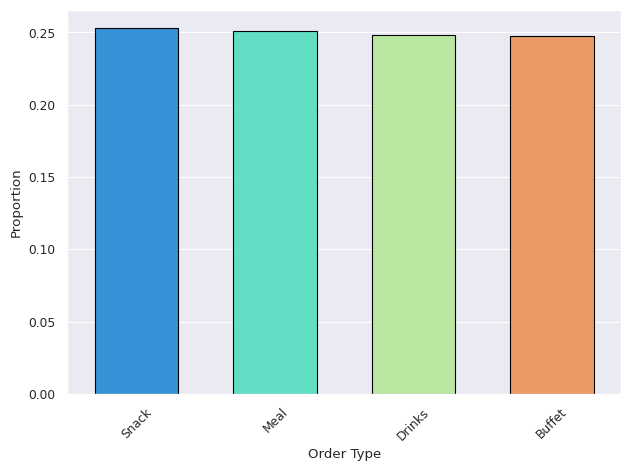

In [ ]:
get_univariate_analysis_for_categorical_feature(df = df.copy(), feature = 'order_type')

,order_type,count,proportion_%,mean_time_taken,std_time_taken
0,Drinks,11294,24.821,26.19,9.30
1,Buffet,11261,24.748,26.28,9.41
2,Snack,11512,25.300,26.29,9.40
3,Meal,11435,25.131,26.43,9.43


----------------------------------------------------------------------------------------------------------------------------------------------------------------


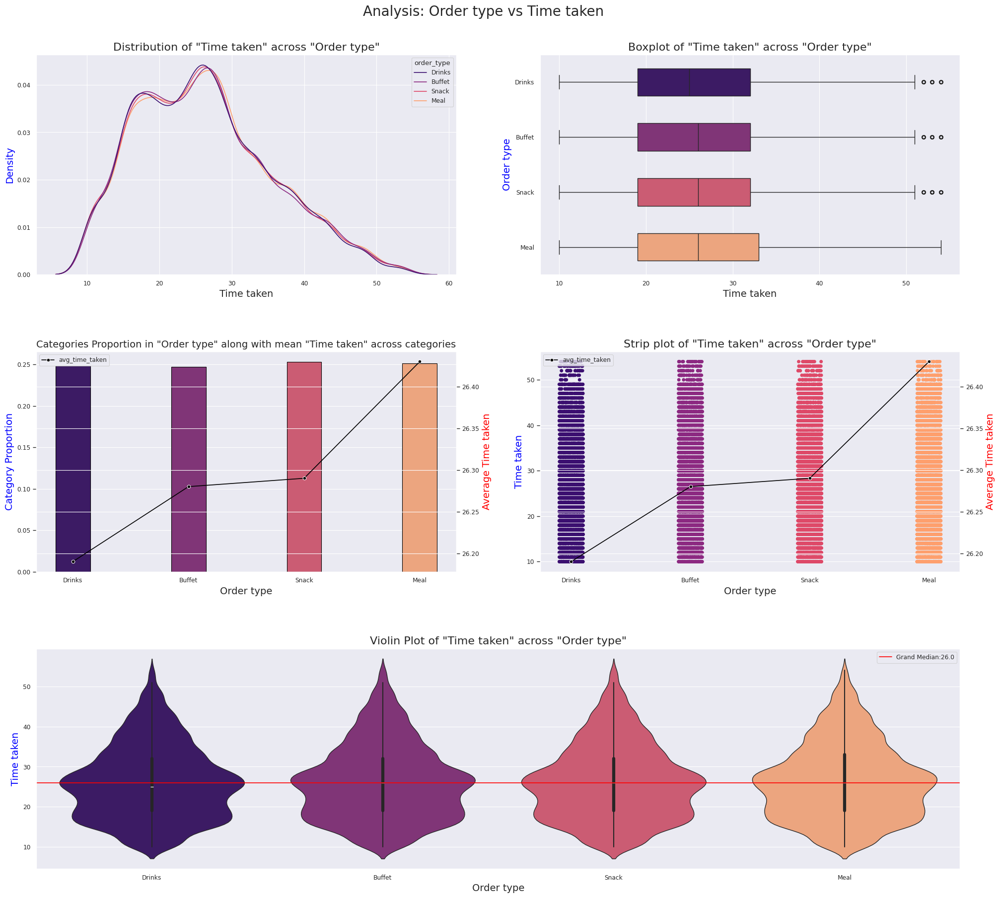

--------------------------------------------------------------------------------------------------------------------------------------------
Welch One-Way ANOVA (not assumed equal variance)

Fail to Reject Ho
Result: No significant difference in category mean of "time_taken" detected across "Order type"
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df = df.copy(), feature = 'order_type', target = 'time_taken', palette = 'magma')

# No effect

In [ ]:
get_hypothesis_test_results_for_categorical_column(df = new_df.copy(), feature_given = 'order_type')

""


## 9.city_name

### a. Uni & Bi-Variate Analysis

,city_name,count,proportion_%,mean_time_taken,std_time_taken
0,Mysore,3164,6.954,26.01,9.46
1,Mumbai,3168,6.962,26.05,9.27
2,Bangalore,3184,6.997,26.07,9.17
3,Surat,3182,6.993,26.09,9.15
4,Indore,3154,6.932,26.11,9.40
5,Goa,709,1.558,26.20,9.22
6,Ranchi,3222,7.081,26.23,9.45
7,Ludhiana,758,1.666,26.28,9.56
8,Vadodara,3159,6.943,26.28,9.39
9,Coimbatore,3162,6.949,26.31,9.39


----------------------------------------------------------------------------------------------------------------------------------------------------------------


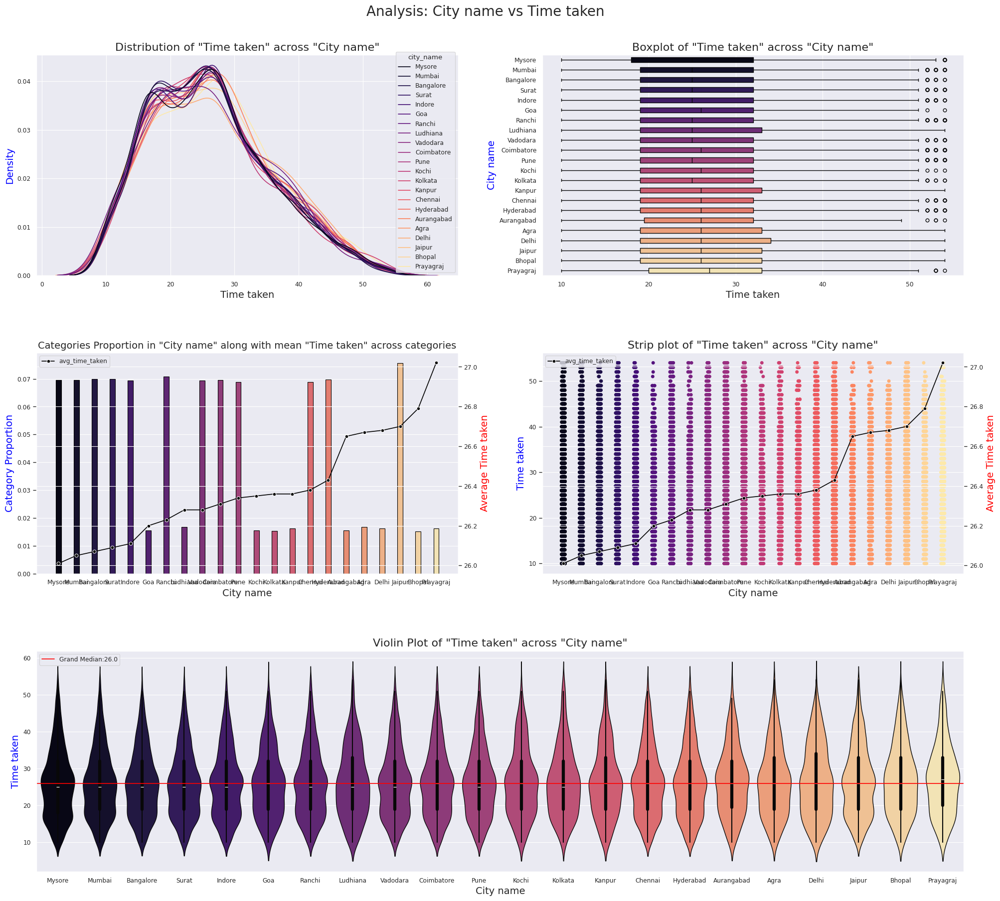

--------------------------------------------------------------------------------------------------------------------------------------------
Welch One-Way ANOVA (not assumed equal variance)

Fail to Reject Ho
Result: No significant difference in category mean of "time_taken" detected across "City name"
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df.copy(), feature = 'city_name', target = 'time_taken', palette = 'magma')

### b. Multi-Variate Analysis

In [ ]:
get_hypothesis_test_results_for_categorical_column(df = new_df.copy(), feature_given = 'city_name')

# Not because of city_name
# but much of the observed variation in time_taken appears to be explained more strongly by features such as 'is_friday_night', distance_km	and multiple_deliveries etc

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,city_name,order_day_of_week,0.000,order_day_of_week,time_taken,0.0
1,city_name,is_friday_night,0.000,is_friday_night,time_taken,0.0
2,city_name,is_month_start,0.000,is_month_start,time_taken,0.0
3,city_name,is_month_end,0.000,is_month_end,time_taken,0.0
4,city_name,distance_km,0.000,distance_km,time_taken,0.0
5,city_name,order_day,0.000,order_day,time_taken,0.0
6,city_name,multiple_deliveries,0.039,multiple_deliveries,time_taken,0.0


## 10.order_placed_hr

### a. Uni-Variate Analysis

Data-Type: float64
Missing Value %: 0.13
Outlier count (IQR rule): 430


,order_placed_hr
count,45445.00
mean,17.43
std,4.81
min,0.00
25%,15.00
50%,19.00
75%,21.00
max,23.00


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


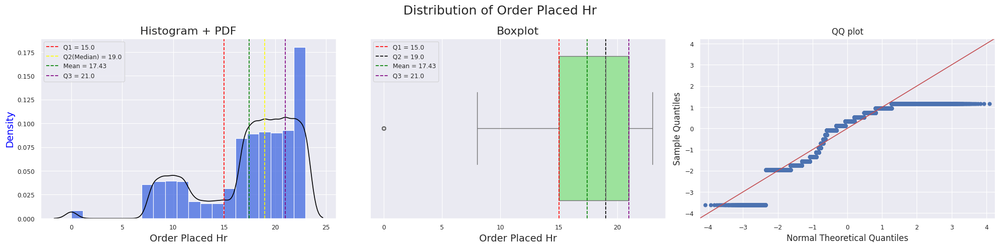

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Skewness: -1.0
Distribution of Order Placed Hr is Left-Skewed
The left tail is longer
The mean is less than the median, which is pulled lower by a few small extreme values.

But Overall Distribution of Order Placed Hr is: Moderately Symmetrical

Excess Kurtosis: 0.43
Leptokurtic -> Distribution of Order Placed Hr has "fat tails" and a "higher frequency of extreme outliers" than a Normal Distribution".

Omnibus Test for Normality
OB: Result: Reject Null Hypothesis. Data is not Normally Distributed

Anderson–Darling Test for Normality
AD: Result: Reject Null Hypothesis. Data is not Normally Distributed 

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_univariate_analysis_for_numerical_feature(df.copy(), feature = 'order_placed_hr', num_bins = 20)

In [ ]:
# the outliers is genuine -> it represent that order placed hr is 12am

### b. Bi-Variate Analysis

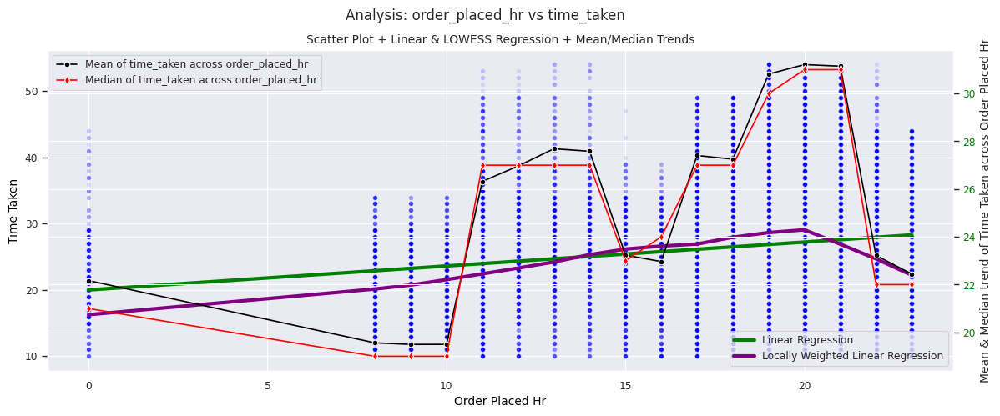

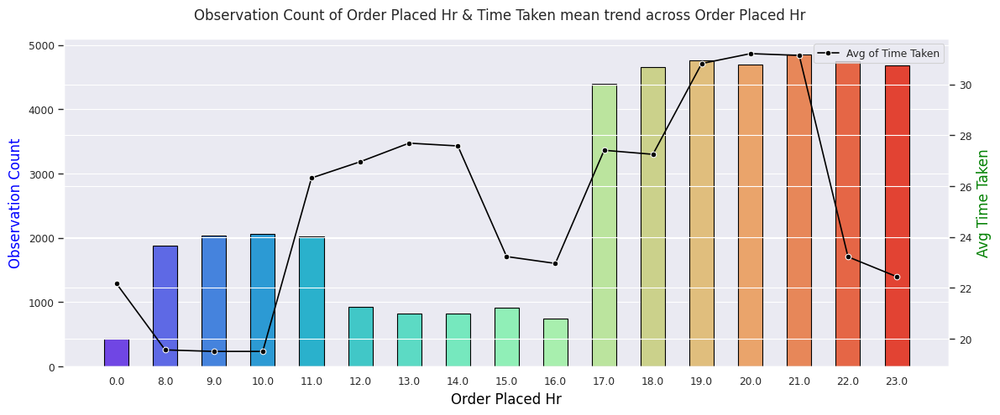

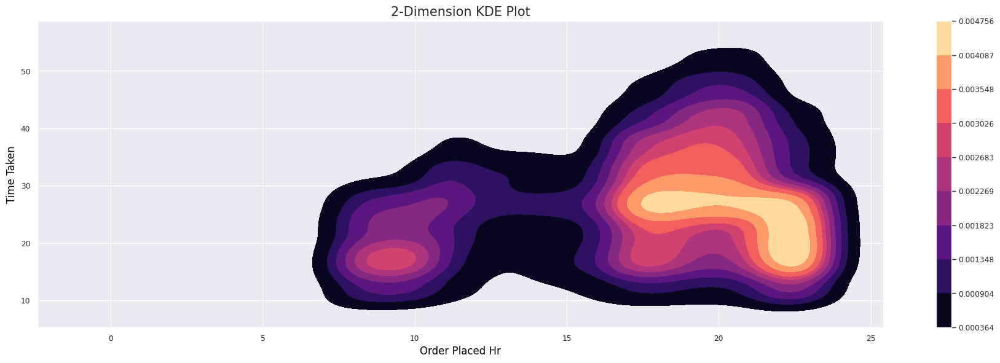

----------------------------------------------------------------------------------------------------------------------------------
STATISTICS FOR Order Placed Hr vs Time Taken
Mutual Information: 0.1296 (Higher = more dependency)
Spearman Rank:      0.1022 (Robust to non-linear)
Pearson Coef:       0.1848

Result: Statistically significant monotonic association detected between Order Placed Hr & Time Taken by Spearman Rank
----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_numerical_vs_numerical(df = df.copy(), feature = 'order_placed_hr', feature_type = 'discrete', target = 'time_taken', palette = 'magma')

### c. Multi-Variate Analysis

In [ ]:
get_hypothesis_test_results_for_numerical_column(df = df.drop(columns = ['vehicle_condition','order_type', 'city_name','sin_hr','cos_hr']).copy(),
                                                 feature_given = 'order_placed_hr')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,order_placed_hr,distance_km,0.0,distance_km,time_taken,0.00
1,order_placed_hr,is_friday_night,0.0,is_friday_night,time_taken,0.00
2,order_placed_hr,is_dinner_rush,0.0,is_dinner_rush,time_taken,0.00
3,order_placed_hr,is_lunch_rush,0.0,is_lunch_rush,time_taken,0.16
4,order_placed_hr,traffic,0.0,traffic,time_taken,0.00
5,order_placed_hr,order_day_of_week,0.0,order_day_of_week,time_taken,0.00
6,order_placed_hr,is_month_end,0.0,is_month_end,time_taken,0.00
7,order_placed_hr,is_month_start,0.0,is_month_start,time_taken,0.00
8,order_placed_hr,is_festival,0.0,is_festival,time_taken,0.00
9,order_placed_hr,multiple_deliveries,0.0,multiple_deliveries,time_taken,0.00


#### Q1. What are the reasons behind spikes in mean/median delivery `time_taken` across `order_placed_hr` between 11 am to 2 pm, even when the order volume didn't spike, though it even decreases but the delivery time increase and also from 5 pm to 9 pm even when the order volume didn't spike much, the delivery time spikes too much. What is the reason behind all these spikes ?

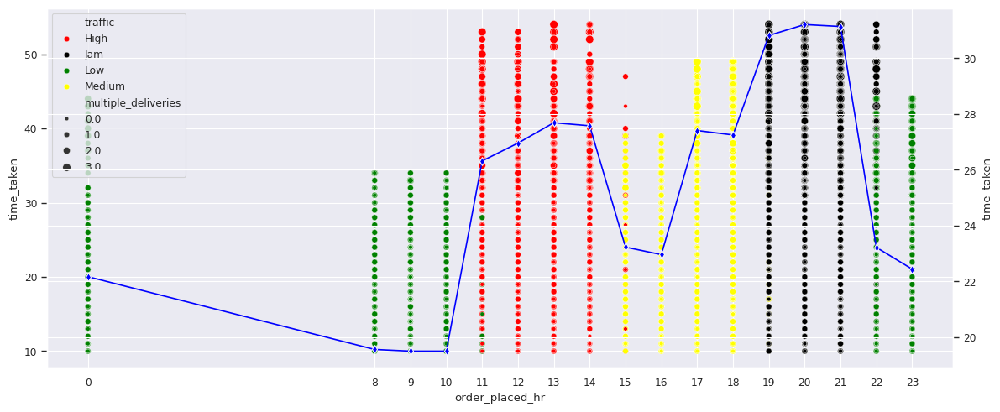

In [ ]:
fig, ax_scatter = plt.subplots(nrows = 1, ncols = 1, figsize = (12,5))
ax_mean = ax_scatter.twinx()

sns.scatterplot(data = df, x = 'order_placed_hr', y = 'time_taken', hue = 'traffic', size = 'multiple_deliveries', palette = traffic_color_palette, ax = ax_scatter)
sns.lineplot(data = df.groupby('order_placed_hr',as_index = False)['time_taken'].mean().round(2), x = 'order_placed_hr', y = 'time_taken',
             color = 'blue', marker = 'd', ax = ax_mean)

plt.xticks(df['order_placed_hr'].dropna().unique())
plt.tight_layout()
plt.show()

In [ ]:
def plot_this(df, study_impact_col1, study_impact_col2, palette):

    avg_df = df.groupby('order_placed_hr',as_index = False)['time_taken'].mean().round(2)

    fig, ax_scatter = plt.subplots(nrows = 1, ncols = 1, figsize = (12,5))
    fig.suptitle(f'Analysing "order_placed_hr" with "time_taken" along with the impact of "{study_impact_col1}" & "{study_impact_col2}"', fontsize = 14)

    sns.scatterplot(data = df, x = 'order_placed_hr', y = 'time_taken', hue = study_impact_col1, size = study_impact_col2, palette = palette, ax = ax_scatter)

    ax_mean = ax_scatter.twinx()
    sns.lineplot(data = avg_df, x = 'order_placed_hr', y = 'time_taken', color = 'blue', marker = 'd', ax = ax_mean)

    # Labelling
    ax_scatter.set_ylabel('Time Taken',   color = 'red', fontsize = 12)
    ax_mean.set_ylabel('Mean Time Taken', color = 'blue', fontsize = 12)
    plt.xticks(sorted(df['order_placed_hr'].dropna().unique()))
    ax_scatter.legend(loc = 'best')
    plt.tight_layout()
    plt.show()

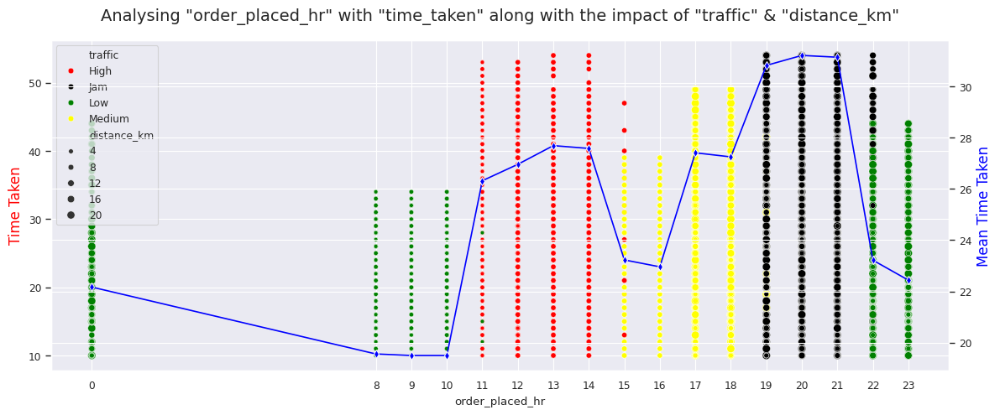

In [ ]:
plot_this(df.copy(),  study_impact_col1 = 'traffic', study_impact_col2 = 'distance_km', palette = traffic_color_palette)

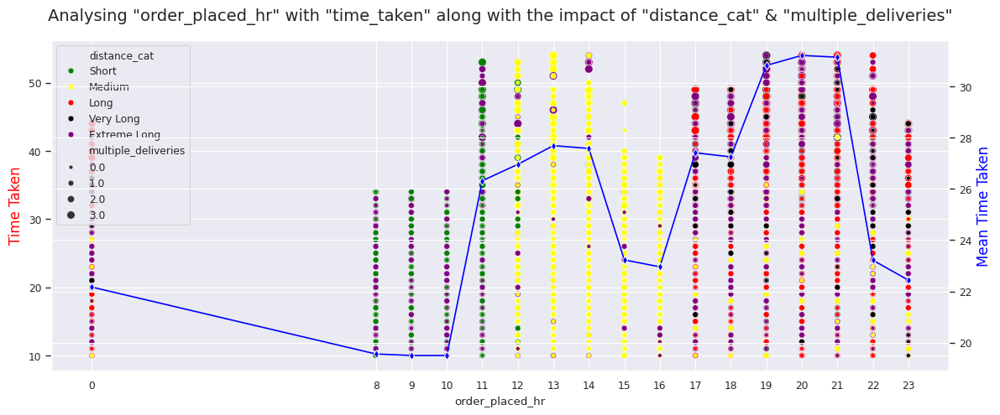

In [ ]:
distance_palette = {'Short':'green', 'Medium':'yellow', 'Long':'red', 'Very Long':'black', 'Extreme Long':'purple'}

plot_this(new_df.copy(), study_impact_col1 = 'distance_cat', study_impact_col2 = 'multiple_deliveries', palette = distance_palette)

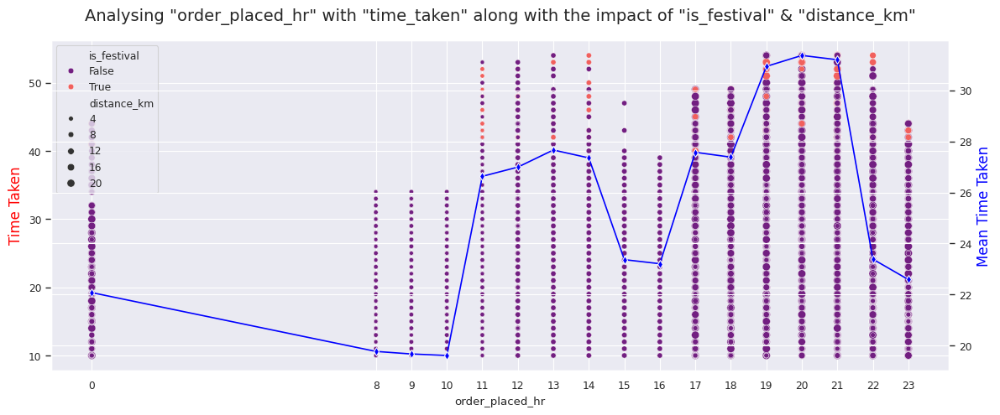

In [ ]:
plot_this(new_df.dropna().copy(), study_impact_col1 = 'is_festival',  study_impact_col2 = 'distance_km', palette = 'magma')

# little impact festival, multiple_deliveries ka bhi hai but majority/dominationg factor traffic & distance ka hai. somehow it's an combined effect jese
# peak hours causes -> increase in volume of orders -> increase multiple_deliveries handlded by rider ->
# -> might causes more distance to be covered by the rider which causes delay and if there is a traffic congestion + especially festival times
# then this combined effect leads to extra delays in delivery

#### Q2. Check order_placed_hr is the causation ? or is the real causation are
     - Traffic congestion -> Yes/Maybe
     - Festival time -> Yes/Maybe
     - Multiple deliveries -> Yes/Maybe
     - Delivery distance -> Yes/Maybe

### d. Final Observations

---
**1. Correlation Interpretation**

- Spearman 0.1022 indicates a weak monotonic association  
- Pearson 0.1848 indicates a weak positive linear association  
- This suggests a weak positive relationship between order_placed_hr and time_taken  
- Delivery time tends to increase slightly as the order hour moves toward later parts of the day  
- However the strength of the relationship remains weak  
- **Time of order has some influence on delivery duration but it is not a dominant factor**

---
**2. Mean and Median Trend Interpretation**
- The mean and median delivery times fluctuate across different hours  

---
**3. Scatter Plot and LOWESS Trend Interpretation**
- The scatter plot shows delivery times distributed across different hours of the day  
- The regression line slopes slightly upward indicating a gradual increase in delivery time for later hours  
- LOWESS show non-linear relationship and follow the mean/median trend

---
**4. Distribution of Orders Across Hours**
- The bar chart shows that **order volume increases significantly during evening hours**  
- The highest concentration of orders appears between approximately 5pm to 9pm  
- Increased order volume during these hours may contribute to longer delivery times  
- Genrally Morning deliveries tend to be faster & Evening deliveries show slightly higher delivery durations  

---
**5. Mutual Information Interpretation**
- Mutual Information value 0.1296 indicates moderate dependency between order_placed_hr and time_taken.
- A value around ~0.13 suggests that order time contains some useful predictive information about delivery duration  
- However: The dependency remains moderate rather than strong  

---
**6. Explained Variation Insight**
- Using Pearson correlation approximately
- R2 Score ~ 0.1848^2 ~ 0.034
- Interpretation : Around 3.4% of the variation in delivery time can be explained by order_placed_hr alone
- It means: order_placed_hr has some influence but most variation is driven by other features or combination of other feature  

---
**7. Final Conclusion**
- order_placed_hr shows a weak positive relationship with delivery time  
- Morning deliveries tend to be faster  
- Evening peak hours correspond to slightly longer delivery durations  
- Delivery time tends to increase during high demand hours  
- Evening and late evening periods correspond with increased traffic and order volume  
- Operational factors that influence this pattern
  - Increased order Volume -> Increased delivery stacking
  - distance covered
  - Rush hour Traffic conditions  
  - Festival times

- Therefore: **`order_placed_hr` provides some predictive information but is not a primary driver**.

- **Other Operational factors likely drive the increase in delivery times during later hours of the day.**

## 11.order_time_of_day

### a. Uni & Bi-variate Analysis

,order_time_of_day,count,proportion_%,mean_time_taken,std_time_taken
0,Morning,7998,17.577,21.24,7.00
1,Late Night,487,1.070,22.39,7.33
2,Night,14285,31.394,25.66,9.40
3,Afternoon,4222,9.279,25.72,8.26
4,Evening,18510,40.680,29.21,9.48


----------------------------------------------------------------------------------------------------------------------------------------------------------------


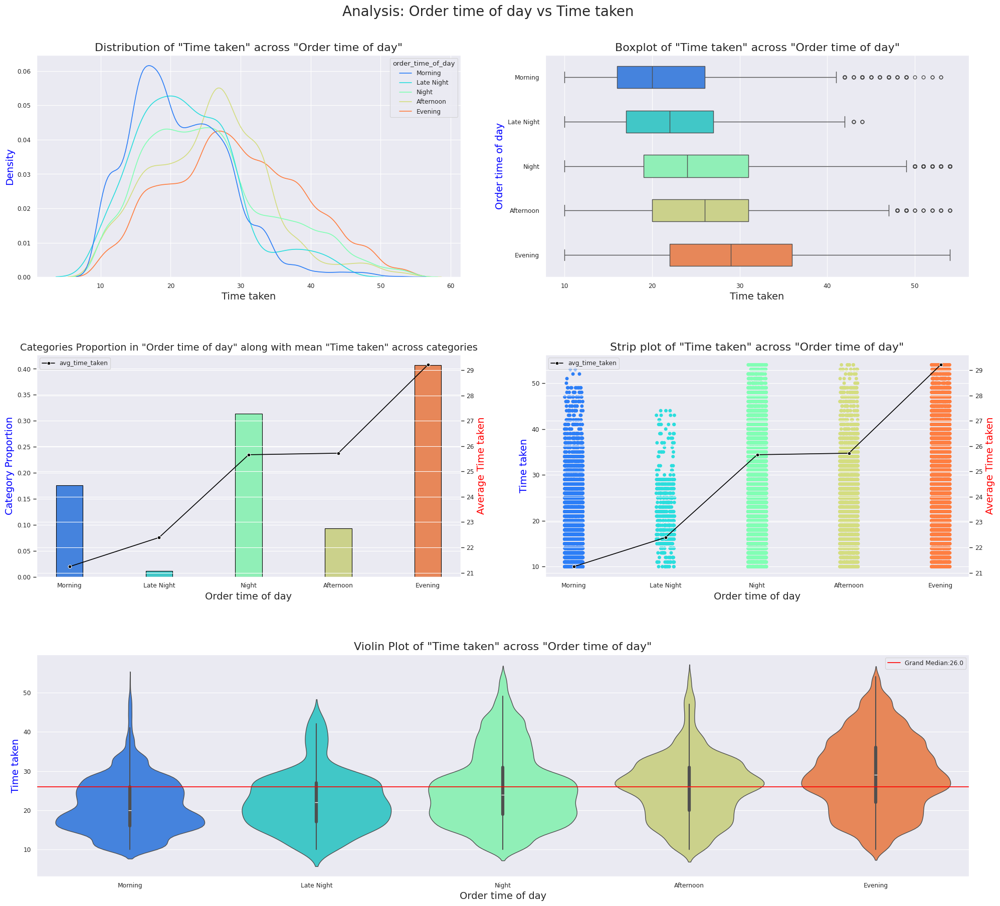

--------------------------------------------------------------------------------------------------------------------------------------------
Welch One-Way ANOVA (not assumed equal variance)

Reject Ho
Result: Significant difference in category mean of "time_taken" detected across "Order time of day"
Result: Welch’s ANOVA indicates that atleast one category mean of "time_taken" is significantly differs from the rest of the others
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df = df.copy(), feature = 'order_time_of_day', target = 'time_taken')

### b. Multi-Variate Analysis

In [ ]:
get_hypothesis_test_results_for_categorical_column(df = df.copy(), feature_given = 'order_time_of_day')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,order_time_of_day,vehicle_condition,0.0,vehicle_condition,time_taken,0.000
1,order_time_of_day,is_lunch_rush,0.0,is_lunch_rush,time_taken,0.155
2,order_time_of_day,is_dinner_rush,0.0,is_dinner_rush,time_taken,0.000
3,order_time_of_day,order_day_of_week,0.0,order_day_of_week,time_taken,0.000
4,order_time_of_day,is_friday_night,0.0,is_friday_night,time_taken,0.000
5,order_time_of_day,is_month_start,0.0,is_month_start,time_taken,0.000
6,order_time_of_day,is_month_end,0.0,is_month_end,time_taken,0.000
7,order_time_of_day,is_festival,0.0,is_festival,time_taken,0.000
8,order_time_of_day,traffic,0.0,traffic,time_taken,0.000
9,order_time_of_day,rider_ratings,0.0,rider_ratings,time_taken,0.000


In [ ]:
# new_df['order_time_of_day'] = pd.Categorical(df['order_time_of_day'], categories = ['Morning', 'Afternoon', 'Evening', 'Late Evening'], ordered = True)


Overall category-level summary:


,order_time_of_day,avg_dist,avg_time
0,Morning,2.29,21.27
1,Late Night,11.55,22.16
2,Night,11.99,25.67
3,Afternoon,5.93,25.69
4,Evening,11.98,29.22



Feature × traffic analysis:


proportion  avg_dist  avg_time_taken
order_time_of_day traffic                                      
Morning           Low          0.7732    2.2856         19.5391
                  High         0.2268    2.3105         27.1716
Late Night        Low          1.0000   11.5531         22.1597
Night             Low          0.6281   12.0160         22.4347
                  Jam          0.3719   11.9489         31.1457
Afternoon         Medium       0.3671    6.1112         22.9872
                  High         0.6329    5.8183         27.2638
Evening           Medium       0.5136   11.8751         27.3318
                  Jam          0.4864   12.0944         31.2050

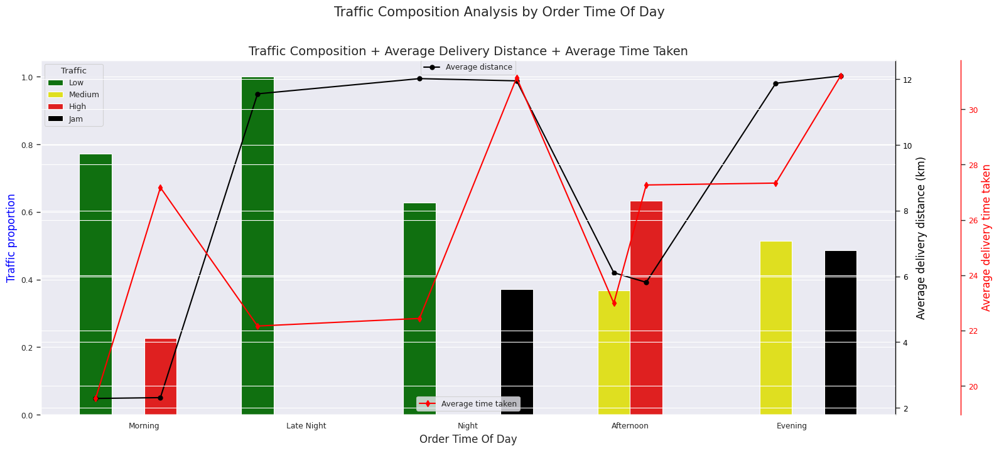

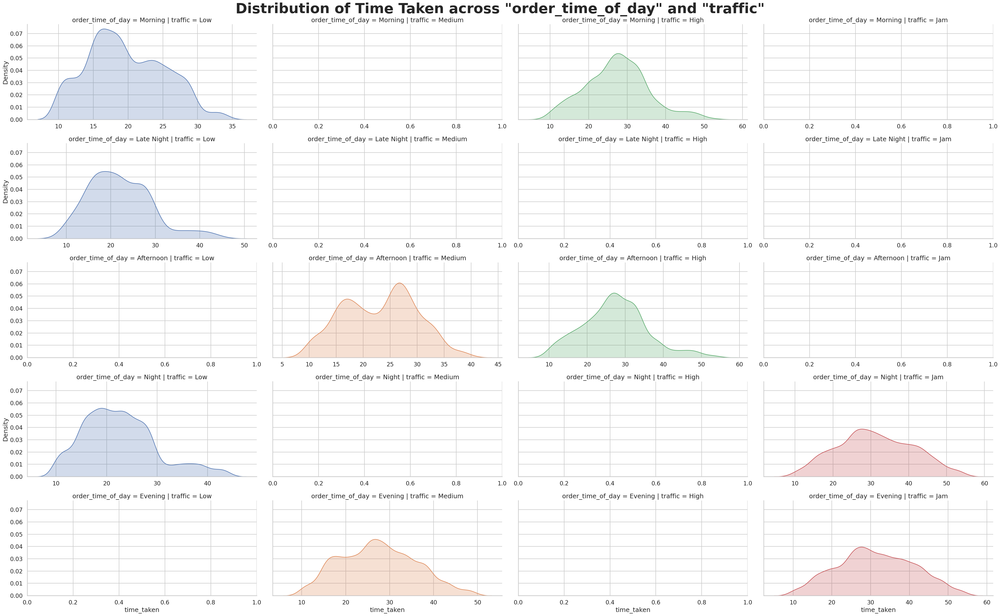

traffic,Low,Medium,High,Jam
order_time_of_day,,,,
Morning,19.689127,NaN,27.380801,NaN
Late Night,22.078125,NaN,NaN,NaN
Afternoon,NaN,23.153614,27.266667,NaN
Night,22.600574,NaN,NaN,31.21242
Evening,NaN,27.463008,NaN,31.32912


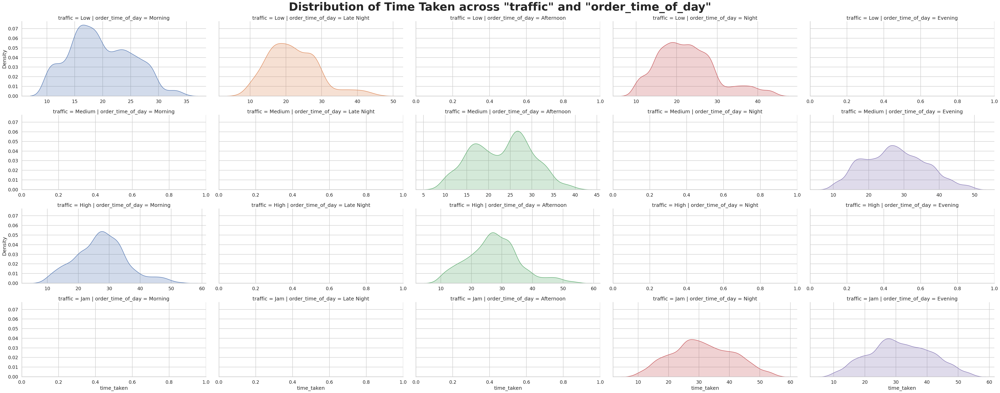

order_time_of_day,Morning,Late Night,Afternoon,Night,Evening
traffic,,,,,
Low,19.689127,22.078125,NaN,22.600574,NaN
Medium,NaN,NaN,23.153614,NaN,27.463008
High,27.380801,NaN,27.266667,NaN,NaN
Jam,NaN,NaN,NaN,31.212420,31.329120


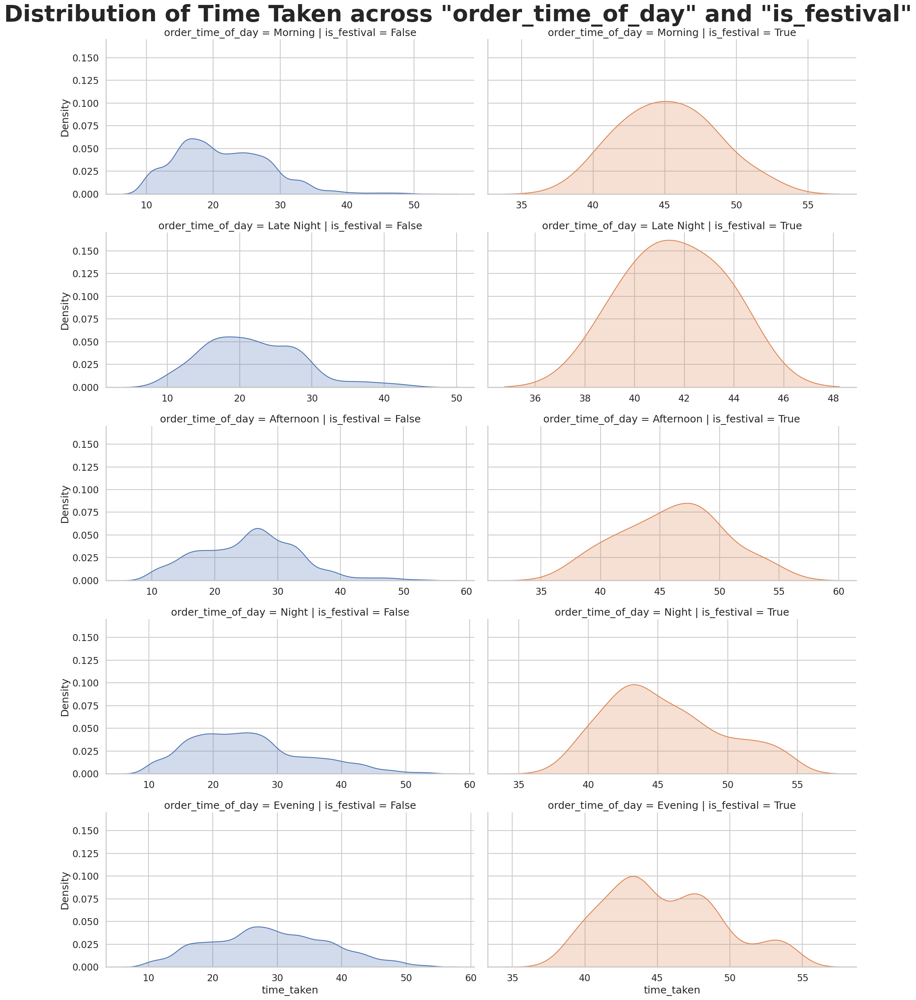

is_festival,False,True
order_time_of_day,,
Morning,21.381571,45.200000
Late Night,21.820580,41.600000
Afternoon,25.519484,46.048780
Night,25.356007,45.467391
Evening,28.905960,45.469767


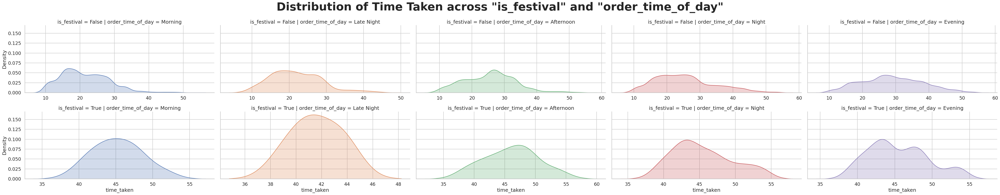

order_time_of_day,Morning,Late Night,Afternoon,Night,Evening
is_festival,,,,,
False,21.381571,21.82058,25.519484,25.356007,28.905960
True,45.200000,41.60000,46.048780,45.467391,45.469767


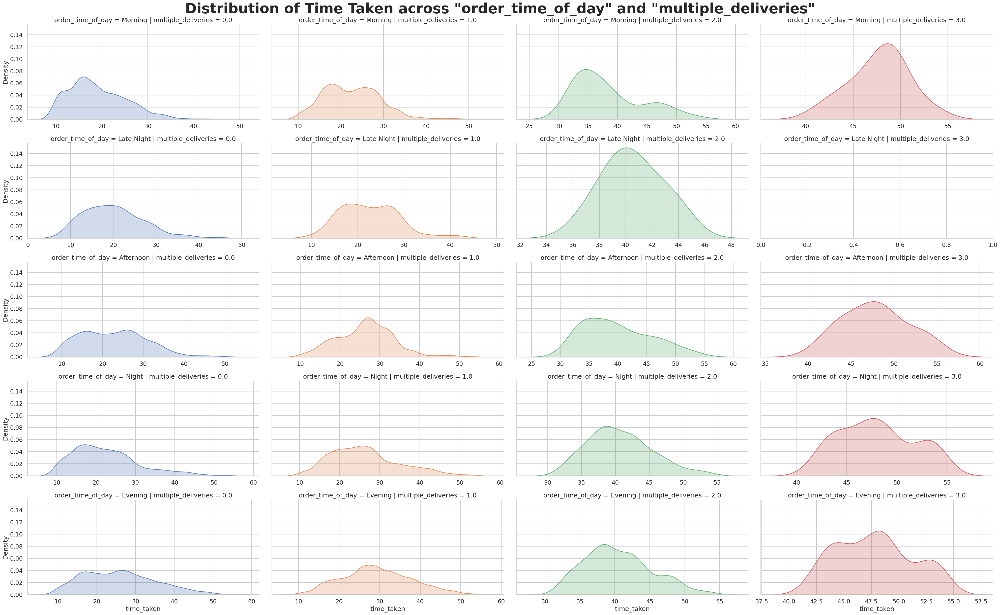

multiple_deliveries,0.0,1.0,2.0,3.0
order_time_of_day,,,,
Morning,19.108359,22.613098,38.312500,47.727273
Late Night,20.000000,22.587755,40.500000,NaN
Afternoon,22.713518,26.366060,39.827273,47.833333
Night,22.430731,26.289171,40.688766,48.011494
Evening,25.979463,29.322062,40.486151,47.797927


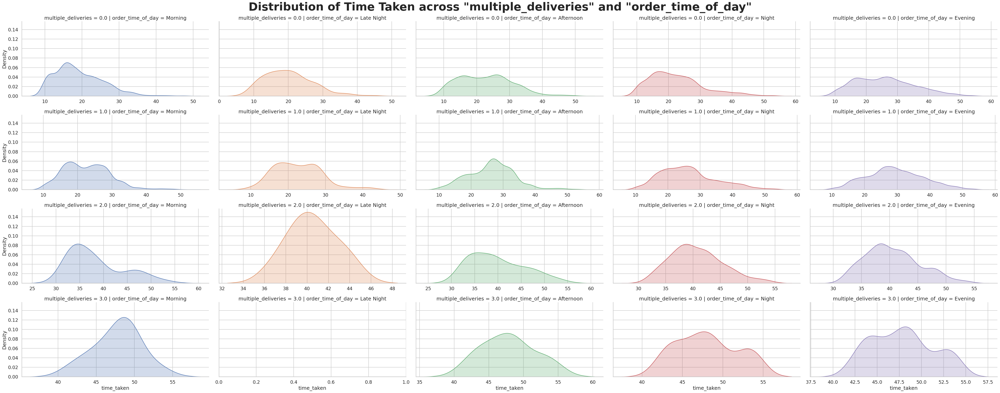

order_time_of_day,Morning,Late Night,Afternoon,Night,Evening
multiple_deliveries,,,,,
0.0,19.108359,20.000000,22.713518,22.430731,25.979463
1.0,22.613098,22.587755,26.366060,26.289171,29.322062
2.0,38.312500,40.500000,39.827273,40.688766,40.486151
3.0,47.727273,NaN,47.833333,48.011494,47.797927


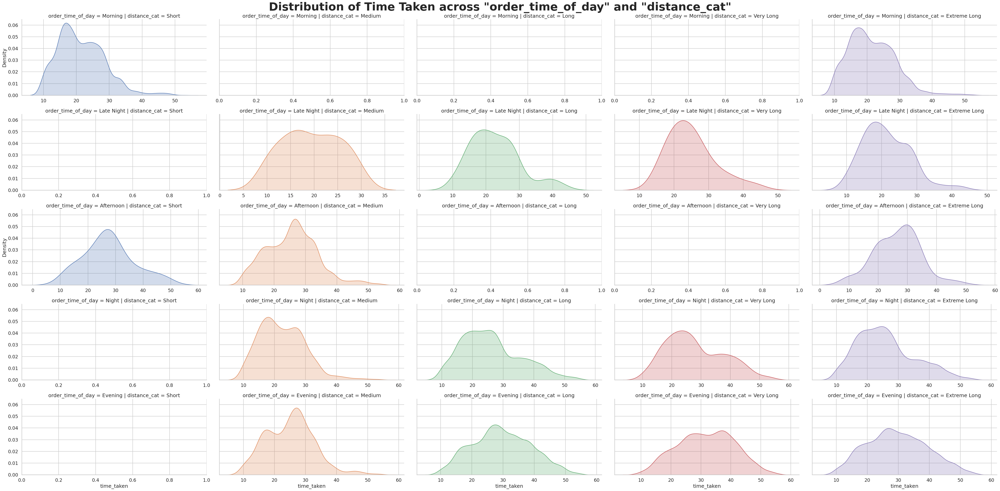

distance_cat,Short,Medium,Long,Very Long,Extreme Long
order_time_of_day,,,,,
Morning,21.501414,NaN,NaN,NaN,21.426015
Late Night,NaN,19.425532,22.746667,25.000000,21.448980
Afternoon,27.567010,25.683537,NaN,NaN,26.602740
Night,NaN,22.447841,26.050146,27.934485,25.901682
Evening,NaN,25.056623,29.582170,31.674376,29.698961


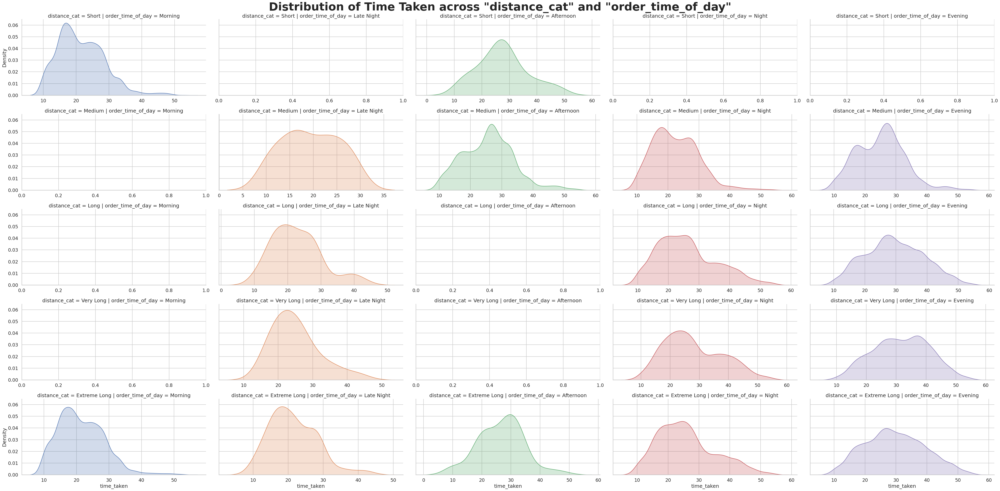

order_time_of_day,Morning,Late Night,Afternoon,Night,Evening
distance_cat,,,,,
Short,21.501414,NaN,27.567010,NaN,NaN
Medium,NaN,19.425532,25.683537,22.447841,25.056623
Long,NaN,22.746667,NaN,26.050146,29.582170
Very Long,NaN,25.000000,NaN,27.934485,31.674376
Extreme Long,21.426015,21.448980,26.602740,25.901682,29.698961


In [ ]:
get_multivariate_analysis_for_categorical_feature(df = new_df.copy(), feature_given = 'order_time_of_day',
                                                  plot_facet = ['traffic', 'is_festival', 'multiple_deliveries', 'distance_cat'])


Overall category-level summary:


,is_lunch_rush,avg_dist,avg_time
0,True,6.11,26.03
1,False,9.93,26.33



Feature × traffic analysis:


proportion  avg_dist  avg_time_taken
is_lunch_rush traffic                                      
True          Medium       0.3186    6.1134         22.9565
              High         0.6814    6.1140         27.4612
False         Low          0.3633    8.1495         21.2799
              Medium       0.2392   11.4624         27.0233
              High         0.0639    3.3154         27.0785
              Jam          0.3337   12.0406         31.1831

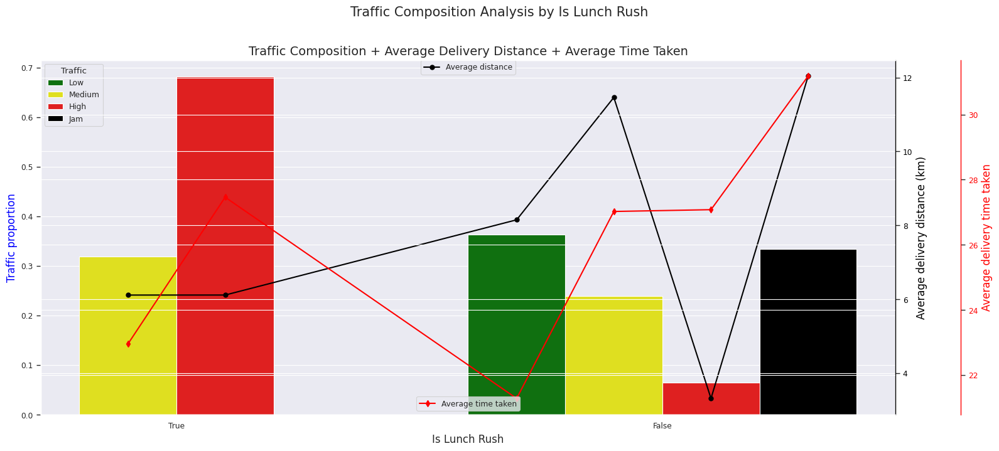

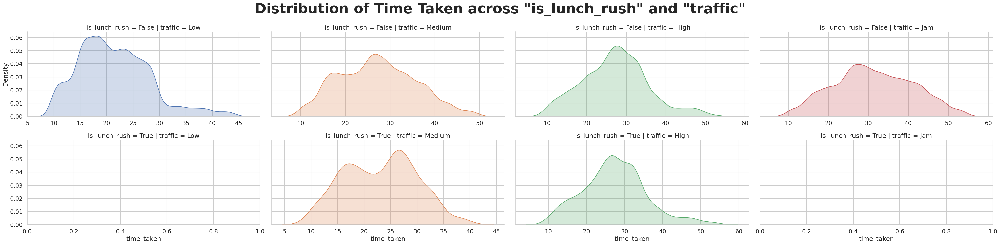

traffic,Low,Medium,High,Jam
is_lunch_rush,,,,
False,21.440093,27.160864,27.249474,31.286199
True,NaN,23.105714,27.415989,NaN


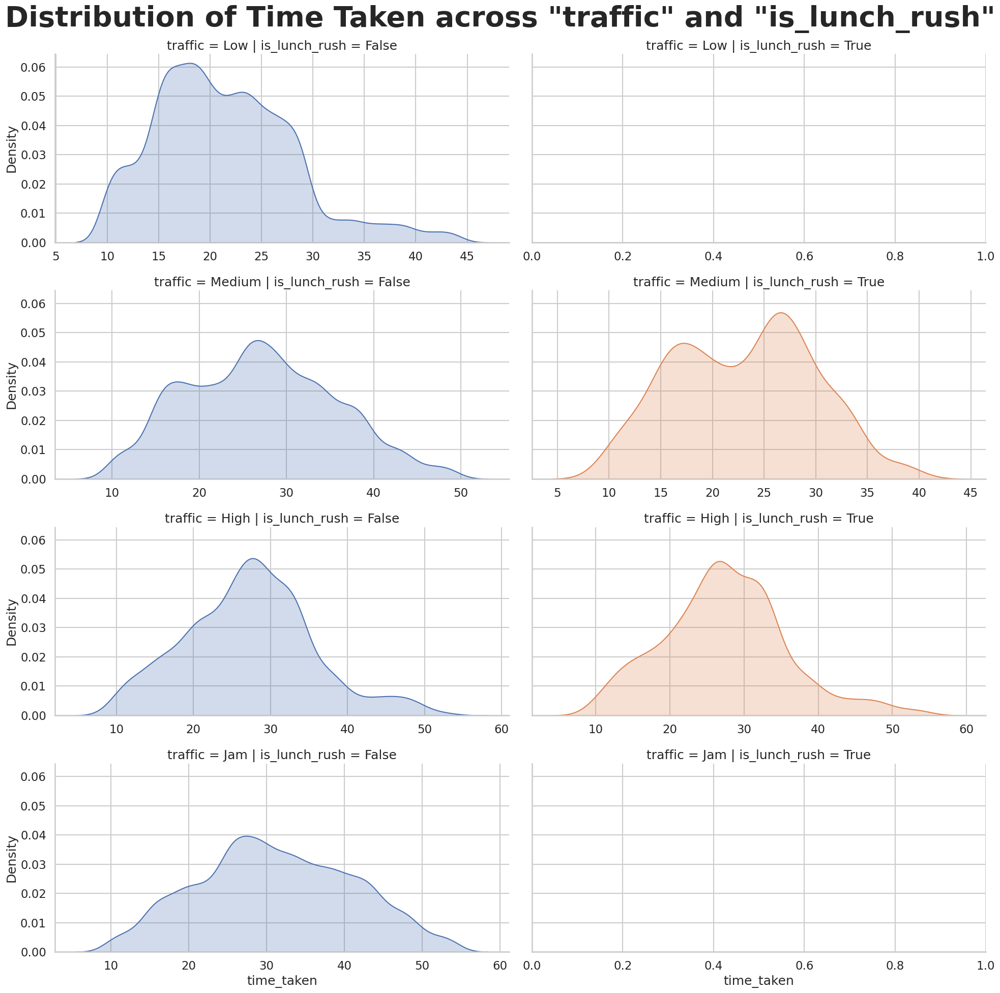

is_lunch_rush,False,True
traffic,,
Low,21.440093,NaN
Medium,27.160864,23.105714
High,27.249474,27.415989
Jam,31.286199,NaN


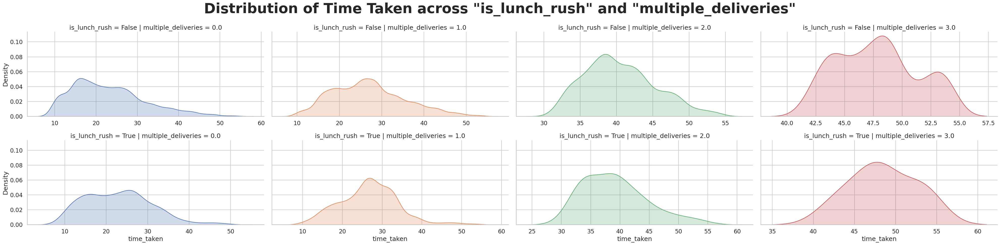

multiple_deliveries,0.0,1.0,2.0,3.0
is_lunch_rush,,,,
False,23.017720,26.934247,40.484136,47.831081
True,22.895988,26.665493,39.085714,48.461538


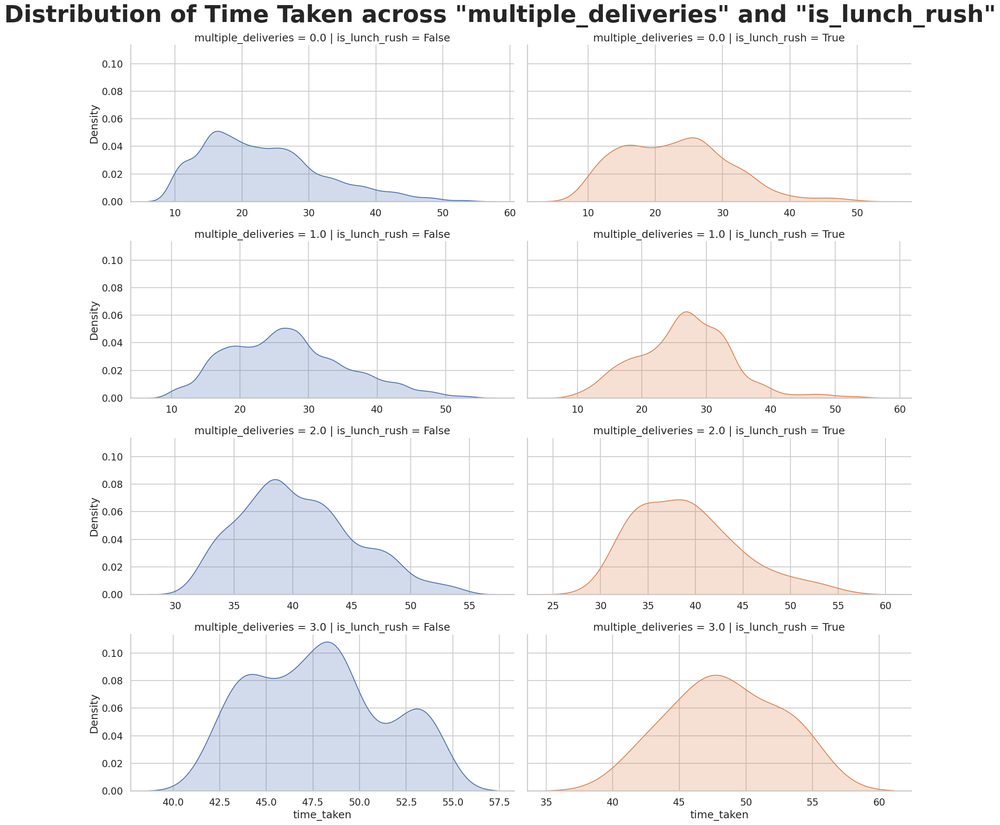

is_lunch_rush,False,True
multiple_deliveries,,
0.0,23.017720,22.895988
1.0,26.934247,26.665493
2.0,40.484136,39.085714
3.0,47.831081,48.461538


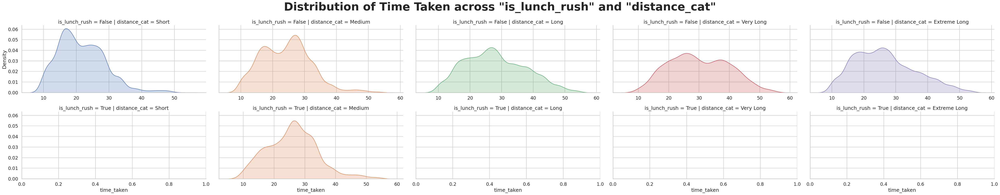

distance_cat,Short,Medium,Long,Very Long,Extreme Long
is_lunch_rush,,,,,
False,21.648947,24.190109,27.99129,29.987632,26.563392
True,NaN,26.029412,NaN,NaN,NaN


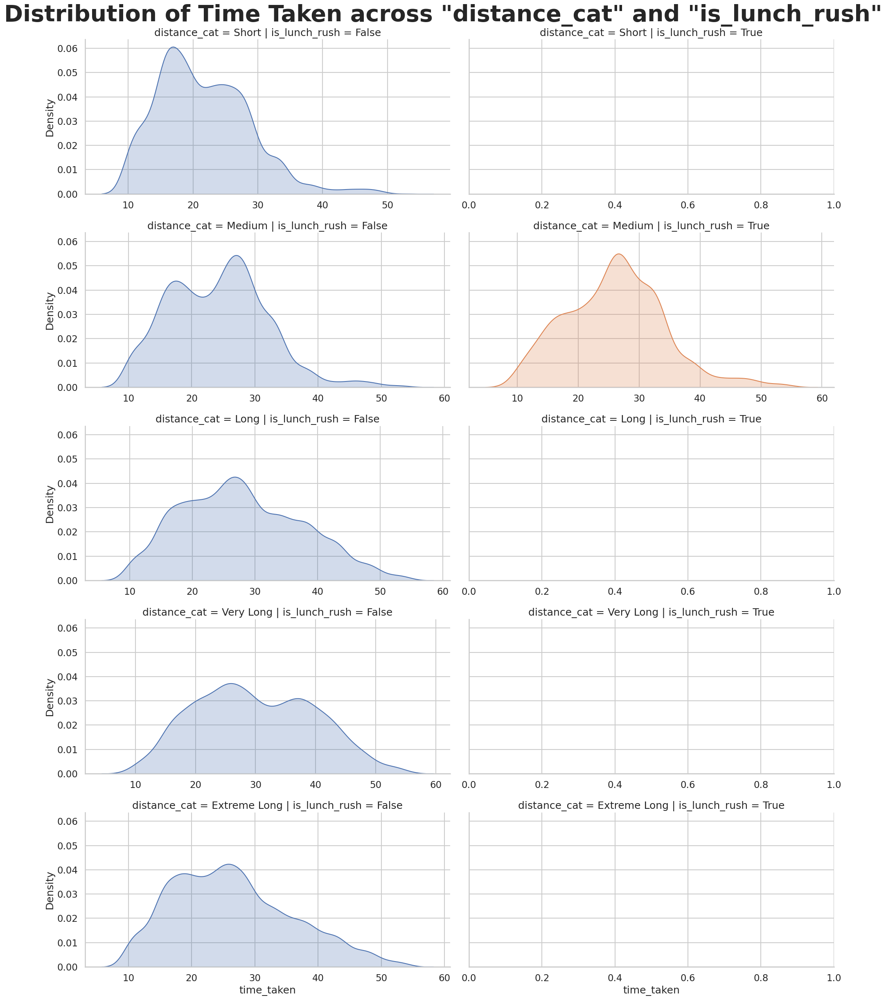

is_lunch_rush,False,True
distance_cat,,
Short,21.648947,NaN
Medium,24.190109,26.029412
Long,27.991290,NaN
Very Long,29.987632,NaN
Extreme Long,26.563392,NaN


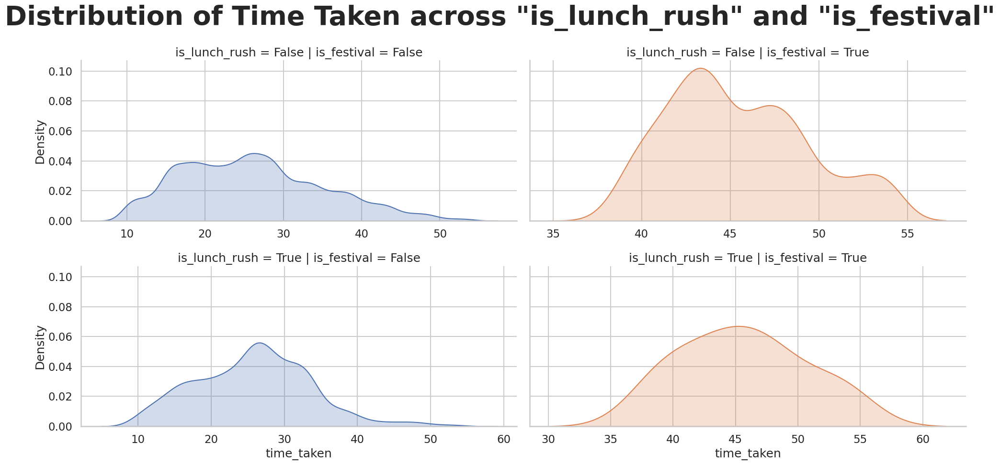

is_festival,False,True
is_lunch_rush,,
False,26.097678,45.460823
True,25.810874,45.625000


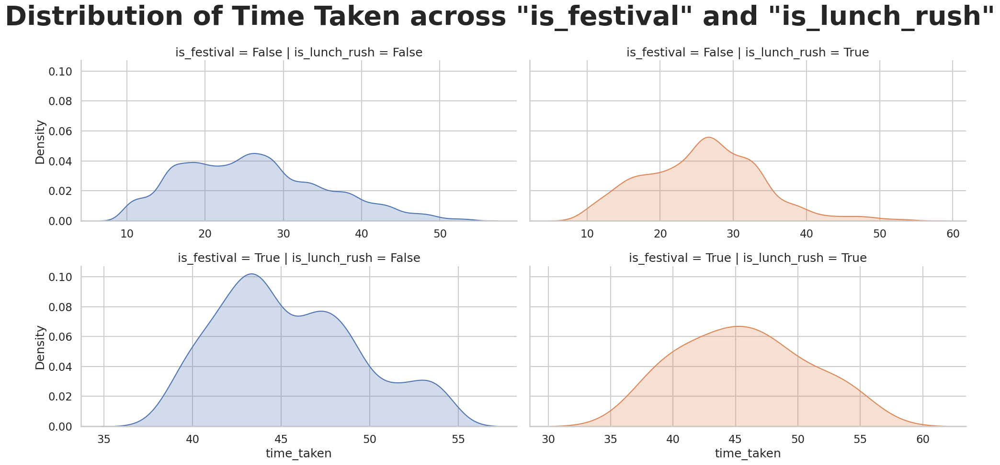

is_lunch_rush,False,True
is_festival,,
False,26.097678,25.810874
True,45.460823,45.625000


In [ ]:
get_multivariate_analysis_for_categorical_feature(df = new_df.copy(), feature_given = 'is_lunch_rush',
                                          plot_facet = ['traffic', 'multiple_deliveries', 'distance_cat','is_festival'])


Overall category-level summary:


,is_dinner_rush,avg_dist,avg_time
0,False,8.65,25.28
1,True,12.04,28.56



Feature × traffic analysis:


proportion  avg_dist  avg_time_taken
is_dinner_rush traffic                                      
False          Low          0.3628    6.6579         20.8433
               Medium       0.3554   11.0720         26.7265
               High         0.1435    4.3974         27.2265
               Jam          0.1383   12.0691         31.1876
True           Low          0.2999   12.0792         22.4303
               Jam          0.7001   12.0283         31.1812

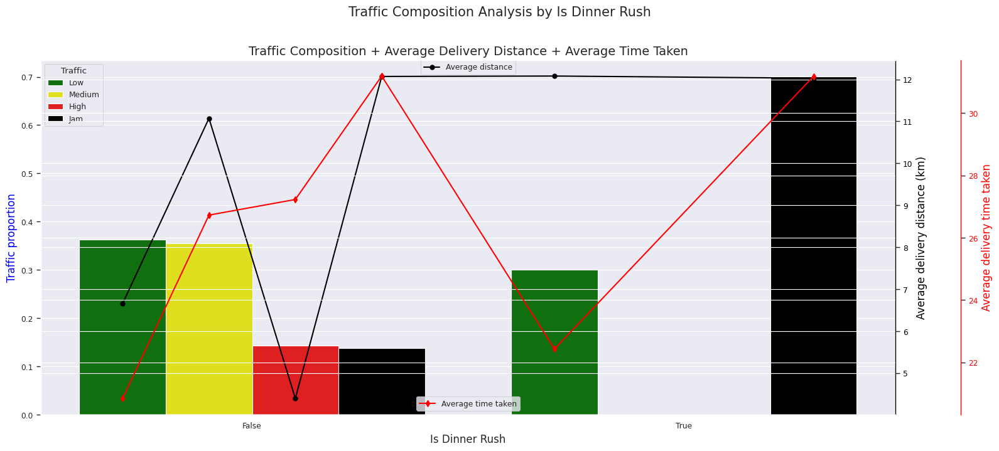

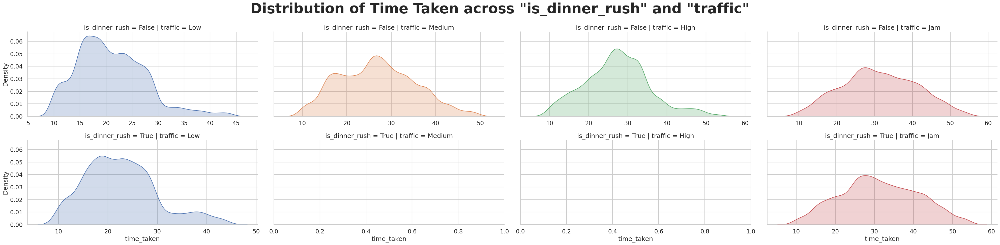

traffic,Low,Medium,High,Jam
is_dinner_rush,,,,
False,20.990615,26.863503,27.313262,31.294807
True,22.608566,NaN,NaN,31.282455


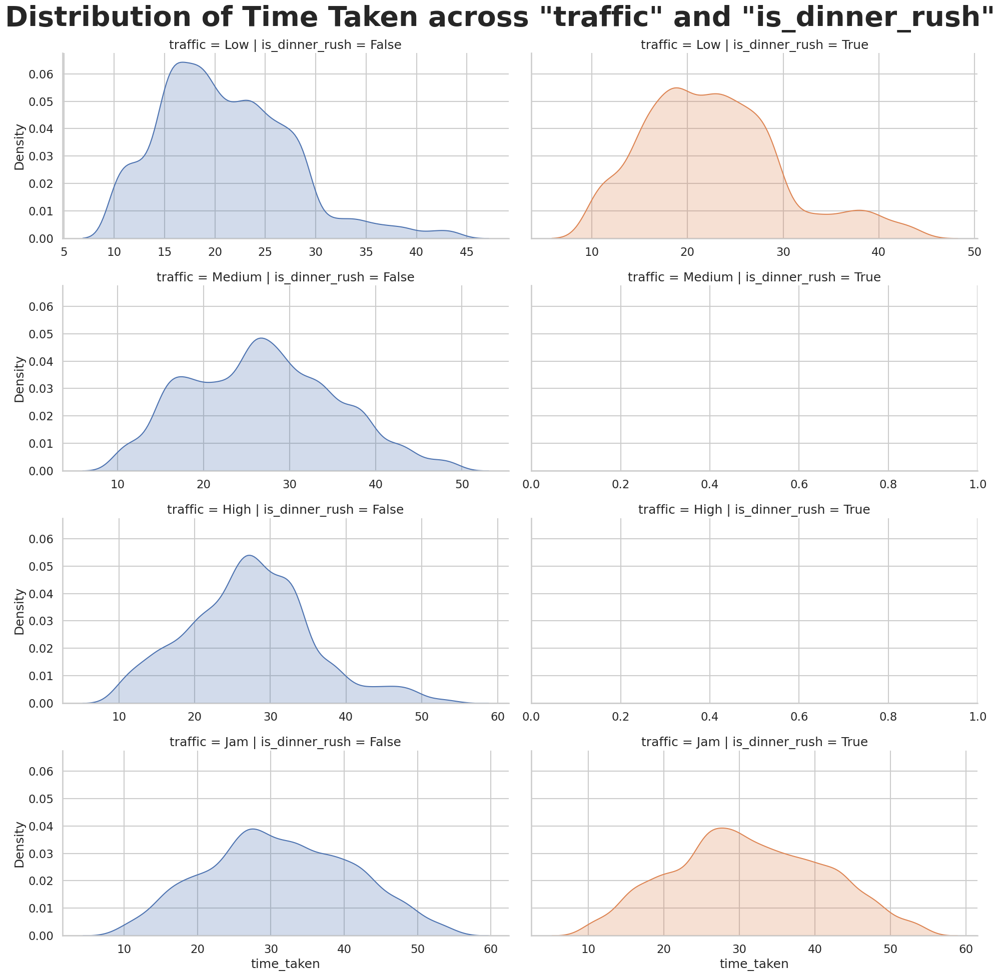

is_dinner_rush,False,True
traffic,,
Low,20.990615,22.608566
Medium,26.863503,NaN
High,27.313262,NaN
Jam,31.294807,31.282455


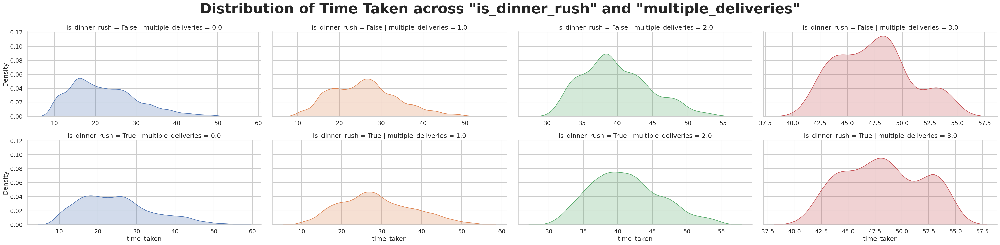

multiple_deliveries,0.0,1.0,2.0,3.0
is_dinner_rush,,,,
False,22.274896,26.064375,39.812304,47.410959
True,24.774434,28.794719,41.156212,48.257669


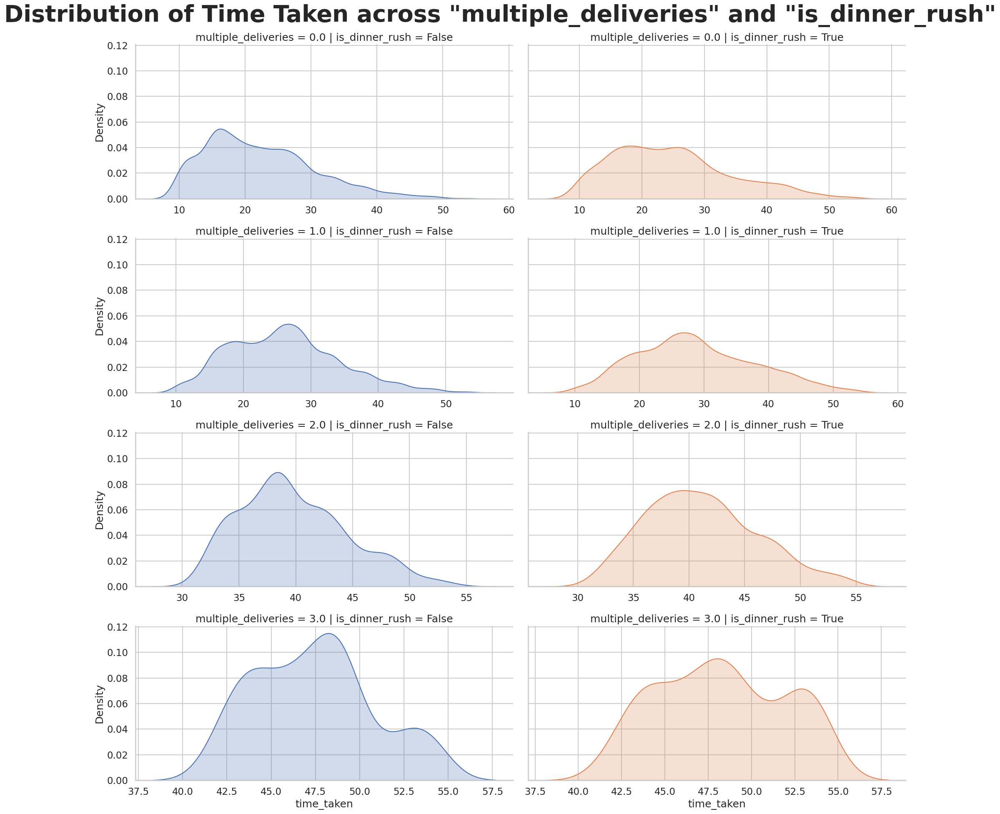

is_dinner_rush,False,True
multiple_deliveries,,
0.0,22.274896,24.774434
1.0,26.064375,28.794719
2.0,39.812304,41.156212
3.0,47.410959,48.257669


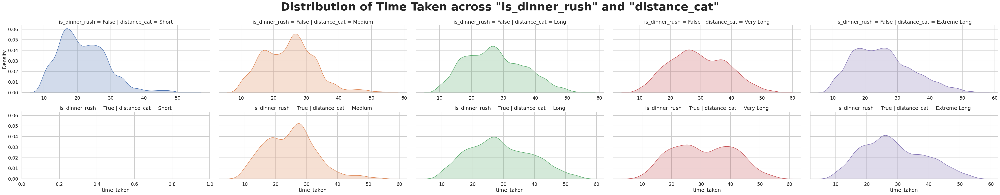

distance_cat,Short,Medium,Long,Very Long,Extreme Long
is_dinner_rush,,,,,
False,21.648947,24.735363,27.274015,29.261872,25.407510
True,NaN,24.875258,28.960160,30.907126,28.792202


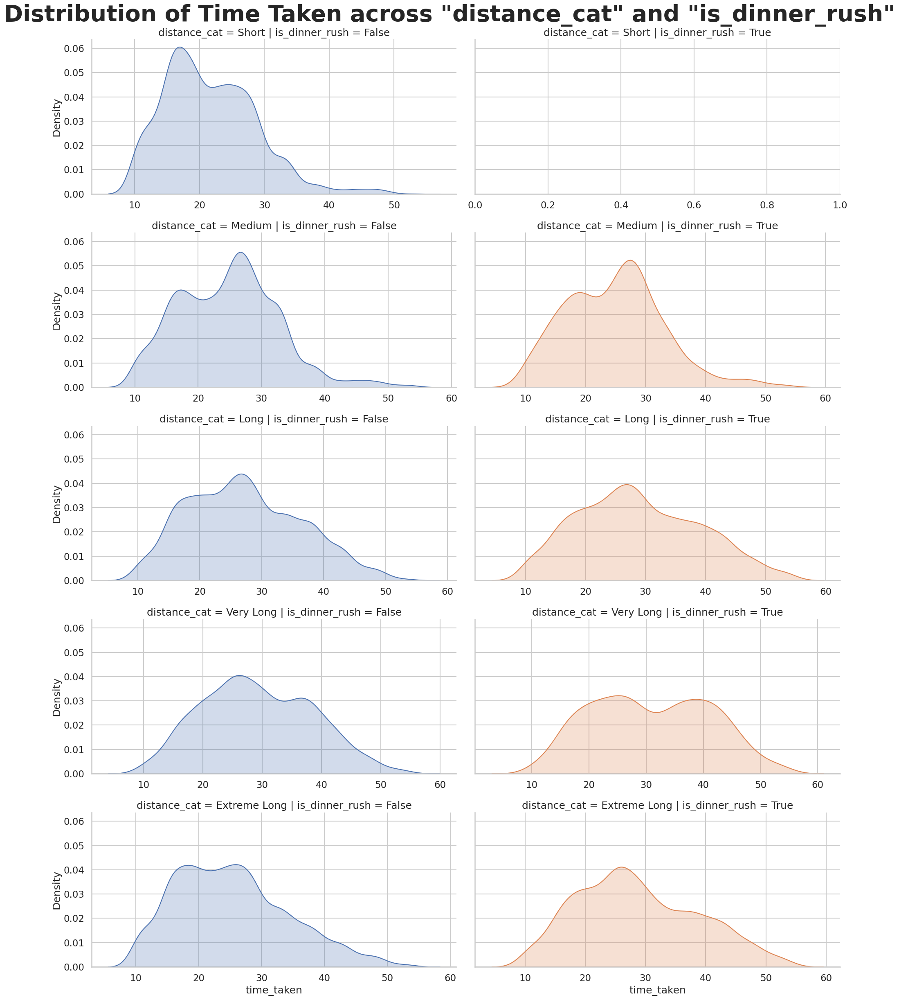

is_dinner_rush,False,True
distance_cat,,
Short,21.648947,NaN
Medium,24.735363,24.875258
Long,27.274015,28.960160
Very Long,29.261872,30.907126
Extreme Long,25.407510,28.792202


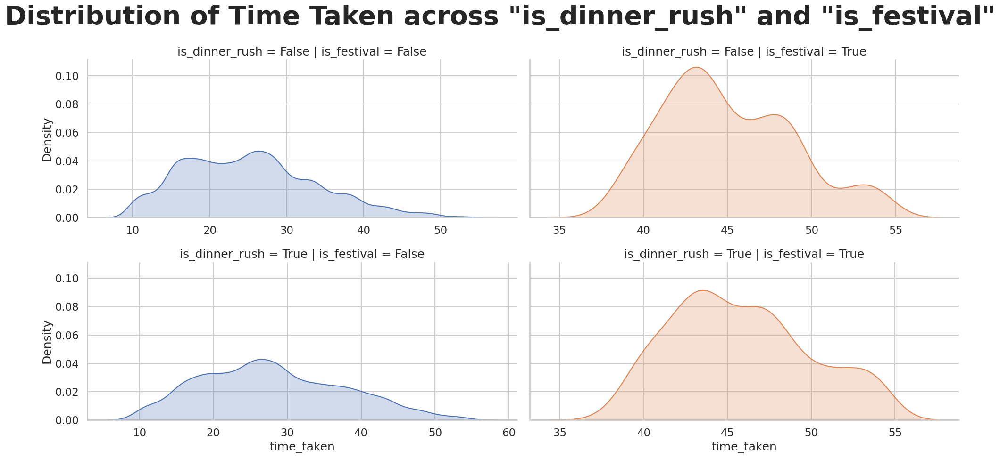

is_festival,False,True
is_dinner_rush,,
False,25.186915,45.043228
True,28.067093,45.806977


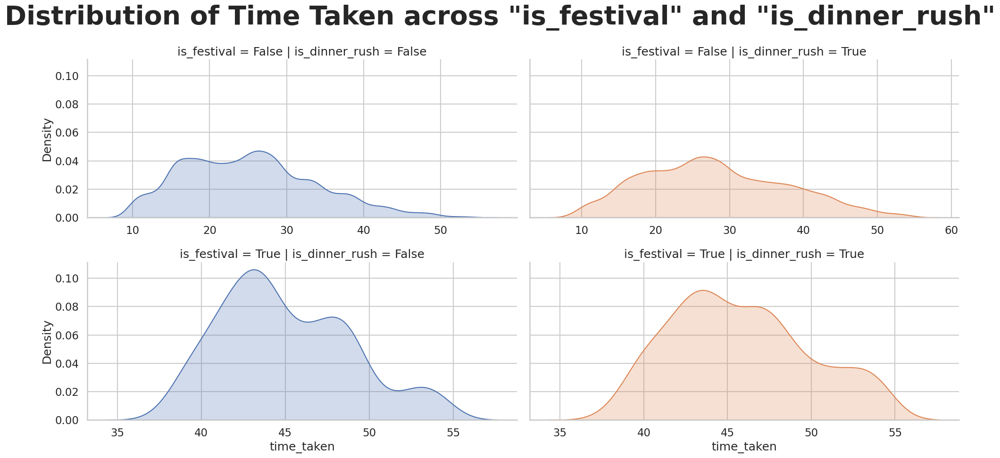

is_dinner_rush,False,True
is_festival,,
False,25.186915,28.067093
True,45.043228,45.806977


In [ ]:
get_multivariate_analysis_for_categorical_feature(df = new_df.copy(), feature_given = 'is_dinner_rush',
                                          plot_facet = ['traffic', 'multiple_deliveries', 'distance_cat','is_festival'])

### c. Final Observations
- order time of day explain some variation in delivery time, but much of the variation is delivery time is explained by other important features
- Since this `order_time_of_day` is derived from `order_placed_hr` therefore both the features will have similar observations.
- Similar observations will be applied for `is_dinner` and `is_lunch_rush`

## 12.order_pickup_time_mins

### a. Uni & Bi-Variate Analysis

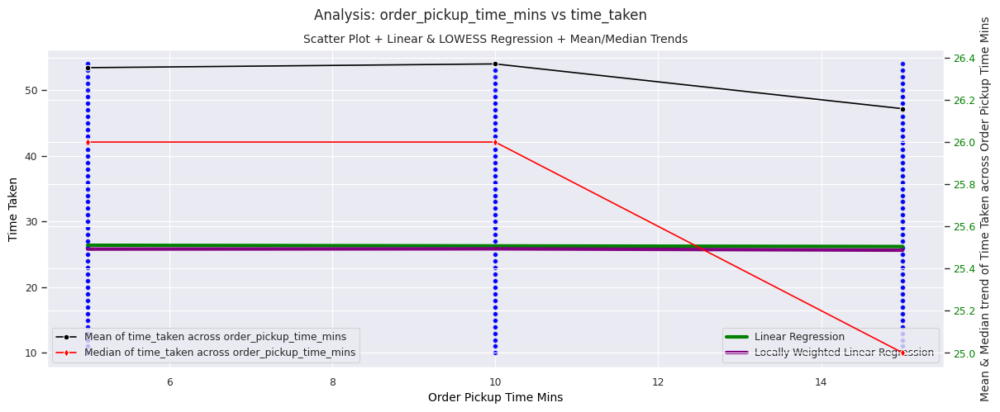

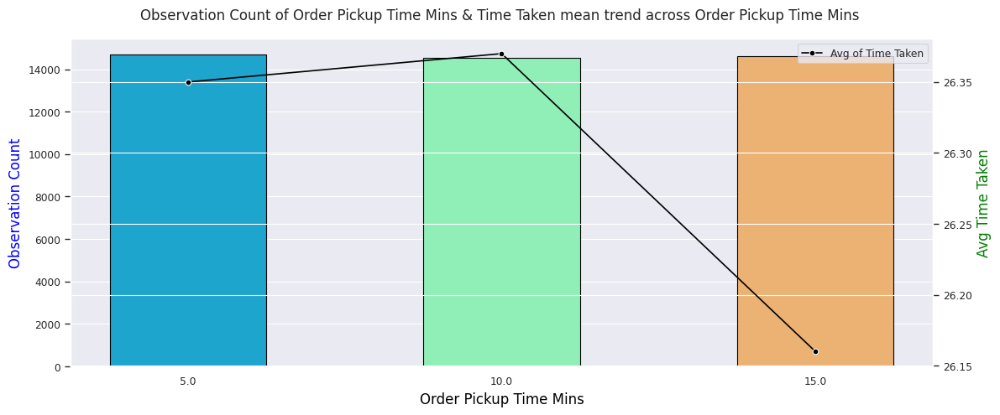

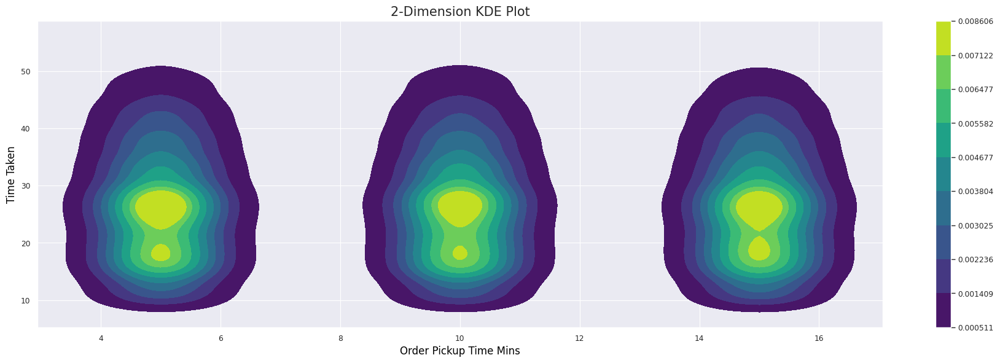

----------------------------------------------------------------------------------------------------------------------------------
STATISTICS FOR Order Pickup Time Mins vs Time Taken
Mutual Information: 0.0019 (Higher = more dependency)
Spearman Rank:      -0.0074 (Robust to non-linear)
Pearson Coef:       -0.0085

Result: No statistically significant monotonic association detected between Order Pickup Time Mins & Time Taken by Spearman Rank
----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_numerical_vs_numerical(df.copy(), feature = 'order_pickup_time_mins', feature_type = 'discrete', target = 'time_taken', palette = 'viridis')
# Dropped

In [ ]:
get_hypothesis_test_results_for_numerical_column(df.copy(), 'order_pickup_time_mins')

""


### b. Final Observations

- Pickup preparation time appears to be independent from the delivery time
- The total delivery duration is mainly driven by others like:
  - Traffic congestion  
  - Multiple deliveries
  - Delivery distance  
  - Festival time

---
**Final Conclusion**
- Correlation values are extremely close to zero and mutual information indicates almost no dependency  
- Delivery time distributions remain stable across pickup preparation times  
- Delivery performance is primarily determined by operational logistics rather than restaurant pickup delay
- **`order_pickup_time_mins` shows no meaningful relationship with `time_taken`**  

## 13.order_day

### a. Uni & Bi-Variate Analysis

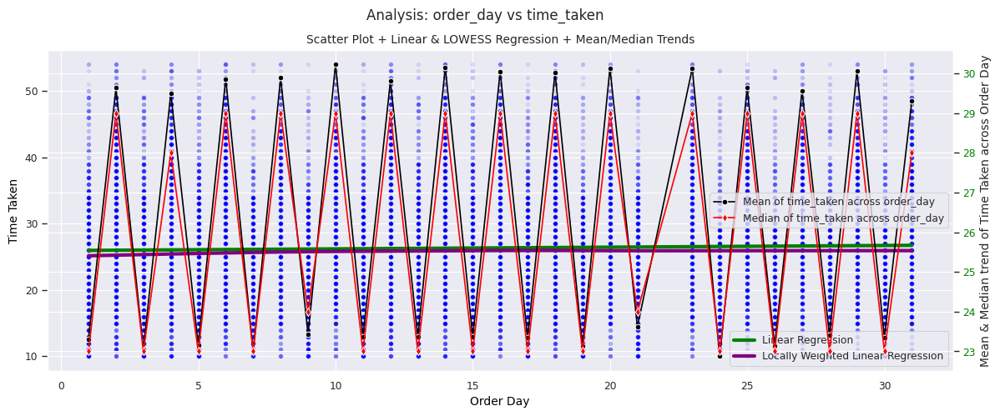

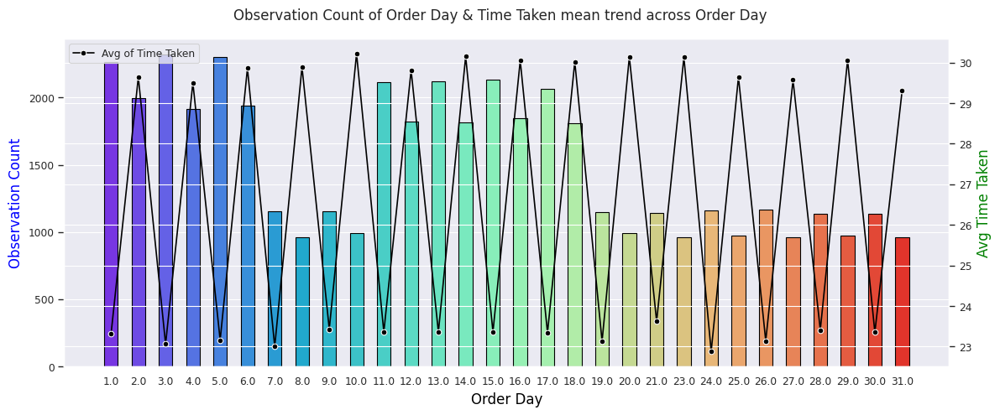

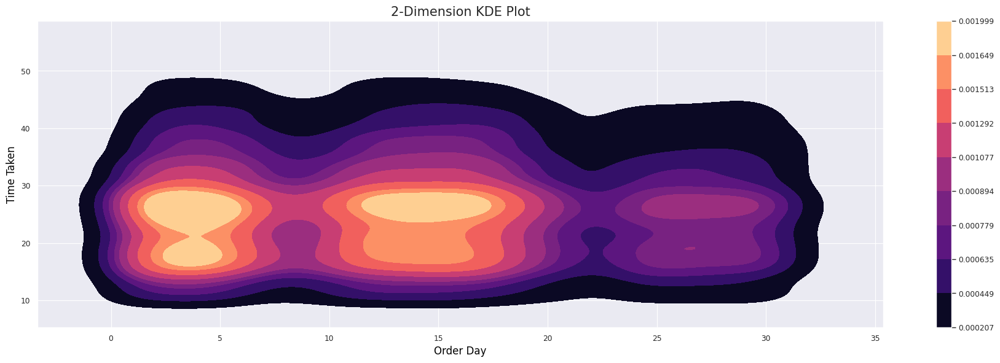

----------------------------------------------------------------------------------------------------------------------------------
STATISTICS FOR Order Day vs Time Taken
Mutual Information: 0.0802 (Higher = more dependency)
Spearman Rank:      0.0238 (Robust to non-linear)
Pearson Coef:       0.0237

Result: Statistically significant monotonic association detected between Order Day & Time Taken by Spearman Rank
----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_numerical_vs_numerical(df.copy(), feature = 'order_day', feature_type = 'discrete', target = 'time_taken', palette = 'magma')

### b. Multi-Variate Analysis

In [ ]:
get_hypothesis_test_results_for_numerical_column(df.copy(), 'order_day')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,order_day,order_month,0.0,order_month,time_taken,0.01
1,order_day,is_month_end,0.0,is_month_end,time_taken,0.00
2,order_day,is_month_start,0.0,is_month_start,time_taken,0.00
3,order_day,order_day_of_week,0.0,order_day_of_week,time_taken,0.00
4,order_day,city_name,0.0,city_name,time_taken,0.17
5,order_day,distance_km,0.0,distance_km,time_taken,0.00
6,order_day,is_weekend,0.0,is_weekend,time_taken,0.49
7,order_day,cos_hr,0.0,cos_hr,time_taken,0.00
8,order_day,order_time_of_day,0.0,order_time_of_day,time_taken,0.00
9,order_day,order_placed_hr,0.0,order_placed_hr,time_taken,0.00


In [ ]:
# Not because of order_day
# but much of the observed variation in time_taken appears to be explained more
# strongly by features such as 'distance_km', order_placed_hr, traffic, is_festival	and multiple_deliveries etc.

### c. Observations

---
**1. Correlation Interpretation**

- Spearman 0.0238 indicates an extremely weak monotonic association  
- Pearson  0.0237 indicates an extremely weak linear association  
- This suggests that there is almost no meaningful relationship between order_day and time_taken  
- **Even though the statistical test reports significance, the correlation magnitude is extremely small  **
- Delivery time does not increase or decrease as the order_day progresses  

---
**2. Scatter Plot and LOWESS Trend Interpretation**
- Both the linear regression line and the LOWESS curve remain almost flat  
- This indicates that delivery time remains stable across different days of the month  
- The absence of a noticeable slope suggests that order_day does not strongly influence delivery duration  
- Variability in delivery time appears similar throughout the entire range of days  

---
**3. Mean and Median Trend Interpretation**
- The mean and median time_taken values fluctuate across different days of the month  
- However these fluctuations appear irregular rather than following a consistent pattern  
- Possible interpretation
  - Some days show spikes in mean delivery time while others show lower values  
  - These variations are likely caused by operational conditions rather than the day number itself  
- Examples of possible causes
  - Traffic conditions  
  - Distance covered  
  - Random variability in order patterns  

---
**4. Distribution of Orders Across Days**
- The bar chart shows the number of observations for each order_day
- Order Volume decrease during end of month / during last week  
- Howeever: Orders are distributed evenly across most days  
- The dataset does not appear heavily biased toward specific days of the month  

---
**5. KDE Density & Heatmap Interpretation**
- This high-density region appears across almost all order_day values  
- No clear shift in density occurs as the day number increases  

---
**6. Mutual Information Interpretation**
- Mutual Information value 0.0802 indicates a very weak dependency between order_day and time_taken
- Mutual information measures any statistical dependency including nonlinear relationships  
- A value around 0.08 suggests that order_day contains very limited information about delivery time  
- Knowing the day of the month provides little predictive value for estimating delivery duration  

---
**7. Explained Variation Insight**
- Using Pearson correlation approximately
- R2 Score ~ 0.0237^2 ~ 0.00056
- 0 % of the variation in delivery time is explained by order_day  
- Almost all variation in delivery time must be explained by other variables.

---
**8.Overall Conclusion**
- Delivery time variability is driven more by operational conditions rather than calendar timing  
- Much of the observed variation in time_taken appears to be explained more
strongly by features such as `distance_km`, `order_placed_hr`, `traffic`, `is_festival`	& `multiple_deliveries` etc than `order_day` itself.  
- The day of the month provides little predictive value for estimating delivery duration.
- Therefore the **`order_day` of month does not appear to be an important determinant of `time_taken`.**

## 14.order_day_of_week

### a. Uni & Bi-Variate Analysis

Data-Type of order_day_of_week : object
Unique values in order_day_of_week : ['Saturday' 'Friday' 'Tuesday' 'Monday' 'Sunday' 'Wednesday' 'Thursday'
 nan]
Total unique values in order_day_of_week : 7
%of NaN values in order_day_of_week : 0.13



,order_day_of_week,counts,proportion
0,Wednesday,7065,0.1555
1,Friday,7011,0.1543
2,Tuesday,6356,0.1399
3,Thursday,6330,0.1393
4,Saturday,6269,0.1379
5,Sunday,6225,0.1370
6,Monday,6189,0.1362


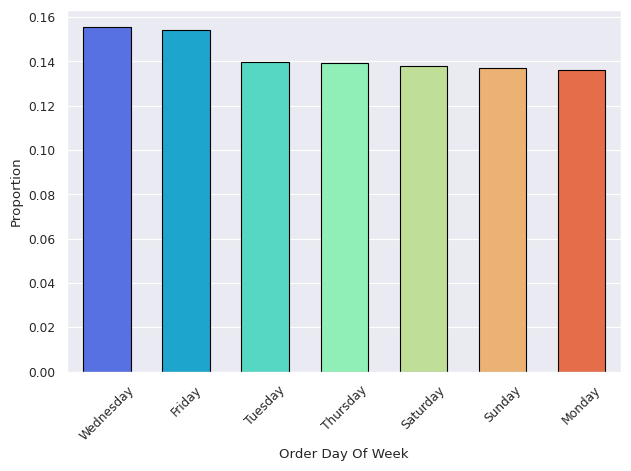

In [ ]:
get_univariate_analysis_for_categorical_feature(df.copy(), 'order_day_of_week')

,order_day_of_week,count,proportion_%,mean_time_taken,std_time_taken
0,Thursday,6330,13.929,25.19,8.99
1,Tuesday,6356,13.986,25.33,9.06
2,Saturday,6269,13.795,26.10,9.35
3,Monday,6189,13.619,26.26,9.36
4,Sunday,6225,13.698,26.40,9.37
5,Friday,7011,15.427,26.83,9.52
6,Wednesday,7065,15.546,27.77,9.72


----------------------------------------------------------------------------------------------------------------------------------------------------------------


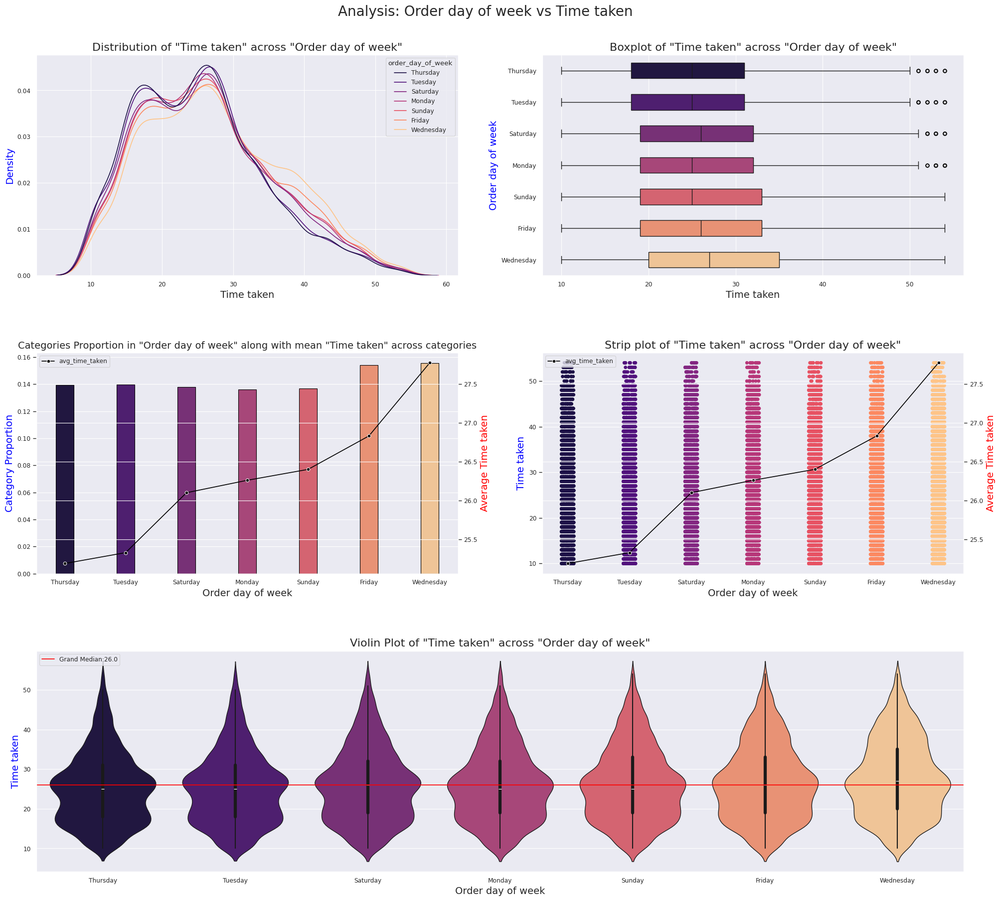

--------------------------------------------------------------------------------------------------------------------------------------------
Welch One-Way ANOVA (not assumed equal variance)

Reject Ho
Result: Significant difference in category mean of "time_taken" detected across "Order day of week"
Result: Welch’s ANOVA indicates that atleast one category mean of "time_taken" is significantly differs from the rest of the others
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df.copy(), feature = 'order_day_of_week', target = 'time_taken', palette = 'magma')

### b. Multi-Variate Analysis

In [ ]:
get_hypothesis_test_results_for_categorical_column(df.copy(), 'order_day_of_week')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,order_day_of_week,city_name,0.0,city_name,time_taken,0.166
1,order_day_of_week,order_time_of_day,0.0,order_time_of_day,time_taken,0.000
2,order_day_of_week,is_lunch_rush,0.0,is_lunch_rush,time_taken,0.150
3,order_day_of_week,is_dinner_rush,0.0,is_dinner_rush,time_taken,0.000
4,order_day_of_week,is_friday_night,0.0,is_friday_night,time_taken,0.000
5,order_day_of_week,is_weekend,0.0,is_weekend,time_taken,0.491
6,order_day_of_week,is_month_start,0.0,is_month_start,time_taken,0.000
7,order_day_of_week,is_month_end,0.0,is_month_end,time_taken,0.000
8,order_day_of_week,is_festival,0.0,is_festival,time_taken,0.000
9,order_day_of_week,traffic,0.0,traffic,time_taken,0.000



Overall category-level summary:


,order_day_of_week,avg_dist,avg_time
0,Thursday,8.32,25.28
1,Tuesday,8.27,25.44
2,Saturday,9.56,25.98
3,Monday,9.48,26.24
4,Sunday,9.86,26.46
5,Friday,10.47,26.82
6,Wednesday,11.74,27.76



Feature × traffic analysis:


proportion  avg_dist  avg_time_taken
order_day_of_week traffic                                      
Thursday          Low          0.3612    6.8235         20.8312
                  Medium       0.2399    9.9081         25.3374
                  High         0.1232    4.2661         27.4133
                  Jam          0.2757   10.6945         30.0920
Tuesday           Low          0.3588    6.7037         20.4475
                  Medium       0.2331    9.7600         25.7198
                  High         0.1301    4.3047         27.7251
                  Jam          0.2779   10.8974         30.5697
Saturday          Low          0.3468    7.8160         20.9598
                  Medium       0.2411   11.0143         26.2988
                  High         0.1003    4.4509         27.2991
                  Jam          0.3118   12.0085         30.8791
Monday            Low          0.3417    7.9479         21.3195
                  Medium       0.2379   10.9220         26.8301
                  High         0.1060    4.3624         26.4766
                  Jam          0.3144   11.7863         31.0750
Sunday            Low          0.3440    8.2608         21.4520
                  Medium       0.2433   11.0099         26.9906
                  High         0.0917    4.4630         26.9846
                  Jam          0.3210   12.2400         31.2713
Friday            Low          0.3372    8.8805         21.5633
                  Medium       0.2543   11.5252         27.3794
                  High         0.0810    4.5520         26.9316
                  Jam          0.3274   12.7573         31.7700
Wednesday         Low          0.3116   10.5768         22.3630
                  Medium       0.2545   12.9048         28.1337
                  High         0.0627    4.4960         27.6593
                  Jam          0.3713   13.1393         32.0488

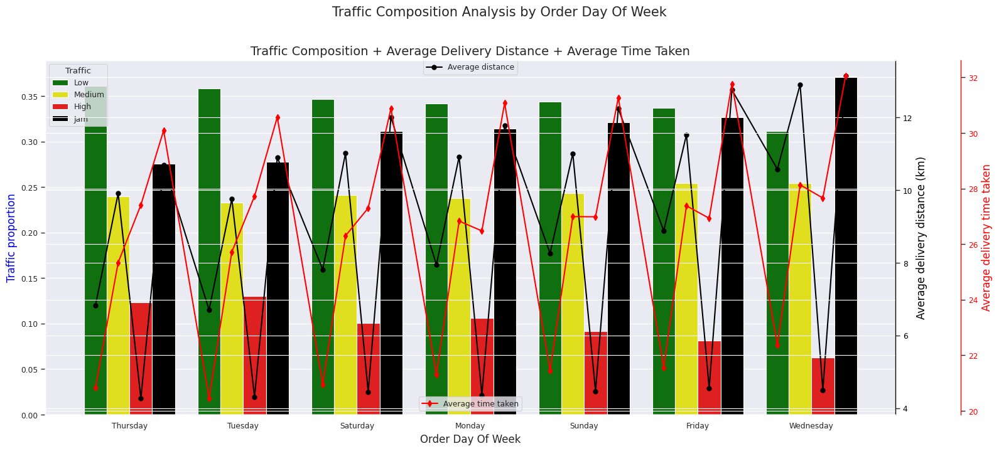

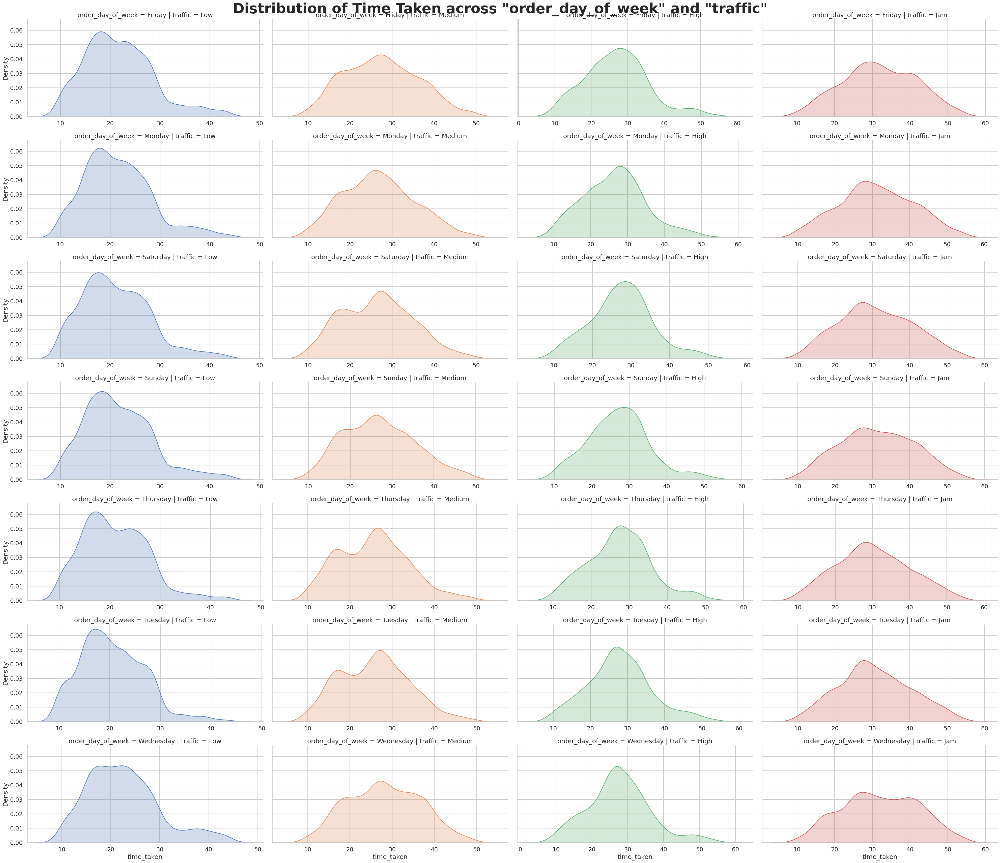

traffic,Low,Medium,High,Jam
order_day_of_week,,,,
Friday,21.759102,27.500000,26.967213,31.881013
Monday,21.504425,26.866824,26.476190,31.138955
Saturday,21.105547,26.508527,27.547445,31.018746
Sunday,21.583333,27.034456,27.148847,31.321080
Thursday,21.048693,25.602930,27.511013,30.222888
Tuesday,20.542032,25.906542,27.808123,30.753623
Wednesday,22.553034,28.213104,27.592593,32.115385


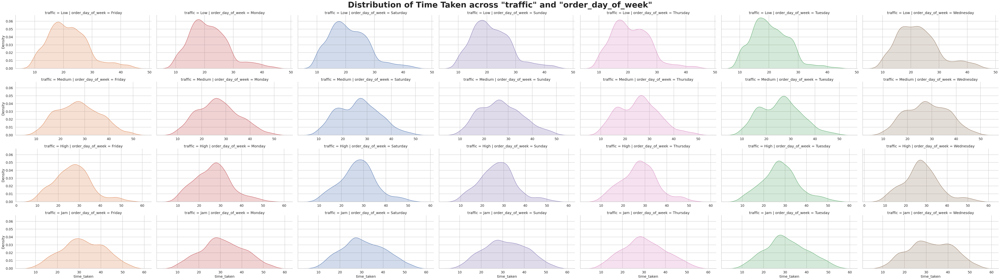

order_day_of_week,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
traffic,,,,,,,
Low,21.759102,21.504425,21.105547,21.583333,21.048693,20.542032,22.553034
Medium,27.500000,26.866824,26.508527,27.034456,25.602930,25.906542,28.213104
High,26.967213,26.476190,27.547445,27.148847,27.511013,27.808123,27.592593
Jam,31.881013,31.138955,31.018746,31.321080,30.222888,30.753623,32.115385


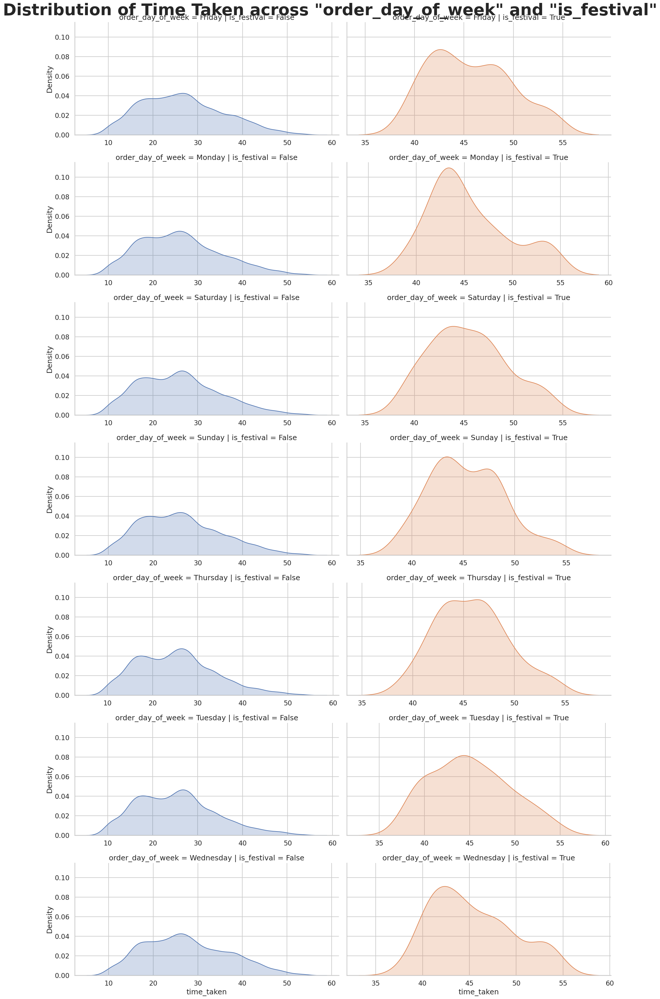

is_festival,False,True
order_day_of_week,,
Friday,26.556541,45.646617
Monday,25.981439,45.539216
Saturday,25.813997,45.485149
Sunday,26.161155,45.350427
Thursday,25.134270,45.826087
Tuesday,25.274879,45.044944
Wednesday,27.444333,45.356643


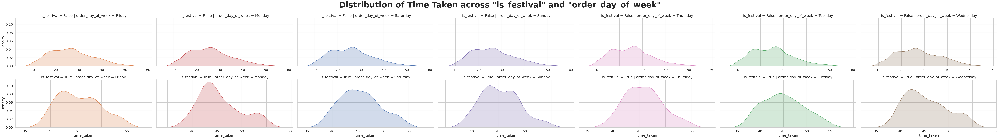

order_day_of_week,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
is_festival,,,,,,,
False,26.556541,25.981439,25.813997,26.161155,25.134270,25.274879,27.444333
True,45.646617,45.539216,45.485149,45.350427,45.826087,45.044944,45.356643


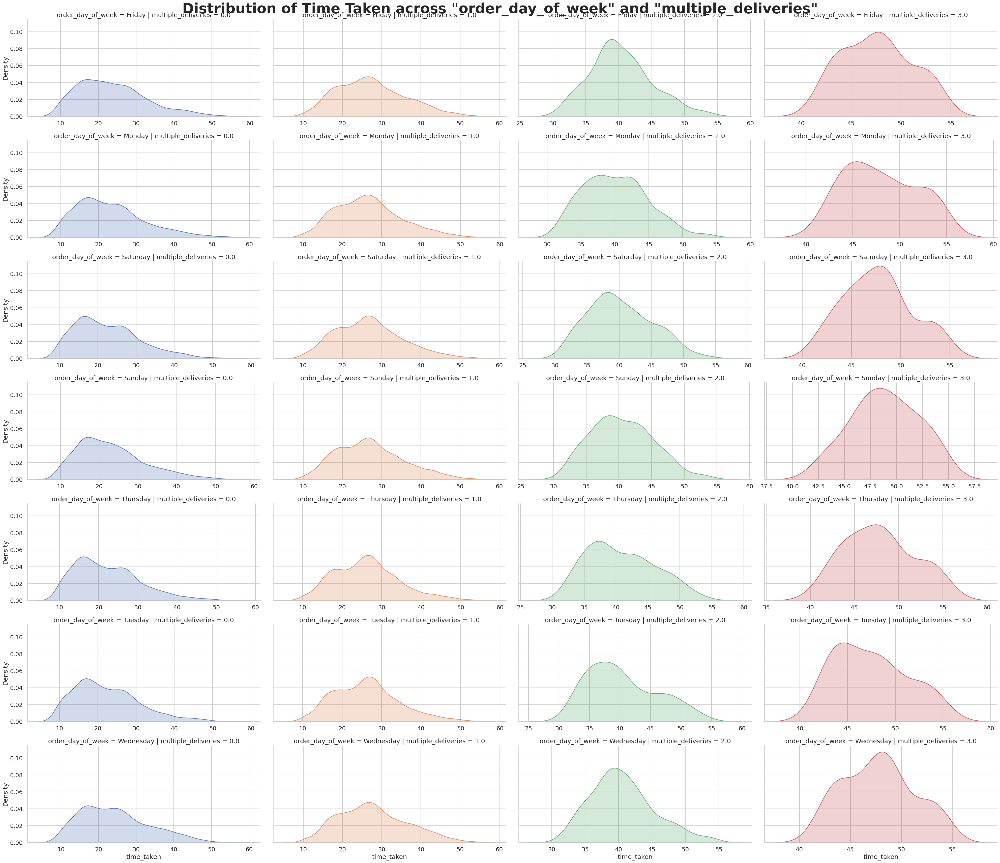

multiple_deliveries,0.0,1.0,2.0,3.0
order_day_of_week,,,,
Friday,23.640107,27.360190,40.386029,47.607143
Monday,23.092692,26.653305,40.073930,47.955556
Saturday,22.510017,26.834270,40.216450,47.688889
Sunday,23.014979,27.072229,40.521739,48.882353
Thursday,22.191443,26.263081,40.812155,47.846154
Tuesday,22.302378,26.225051,40.378109,47.483871
Wednesday,24.333333,27.838948,40.612732,47.777778


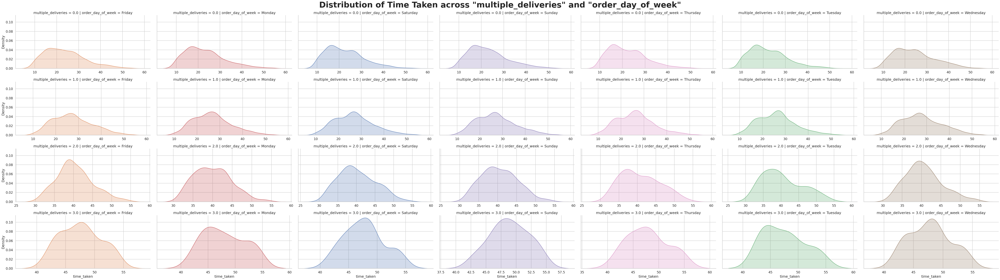

order_day_of_week,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
multiple_deliveries,,,,,,,
0.0,23.640107,23.092692,22.510017,23.014979,22.191443,22.302378,24.333333
1.0,27.360190,26.653305,26.834270,27.072229,26.263081,26.225051,27.838948
2.0,40.386029,40.073930,40.216450,40.521739,40.812155,40.378109,40.612732
3.0,47.607143,47.955556,47.688889,48.882353,47.846154,47.483871,47.777778


In [ ]:
get_multivariate_analysis_for_categorical_feature(new_df.copy(), 'order_day_of_week', plot_facet = ['traffic', 'is_festival','multiple_deliveries'])

## 15.is_weekend & is_friday_night

,is_weekend,count,proportion_%,mean_time_taken,std_time_taken
0,True,12494,27.493,26.25,9.36
1,False,32951,72.507,26.32,9.40


----------------------------------------------------------------------------------------------------------------------------------------------------------------


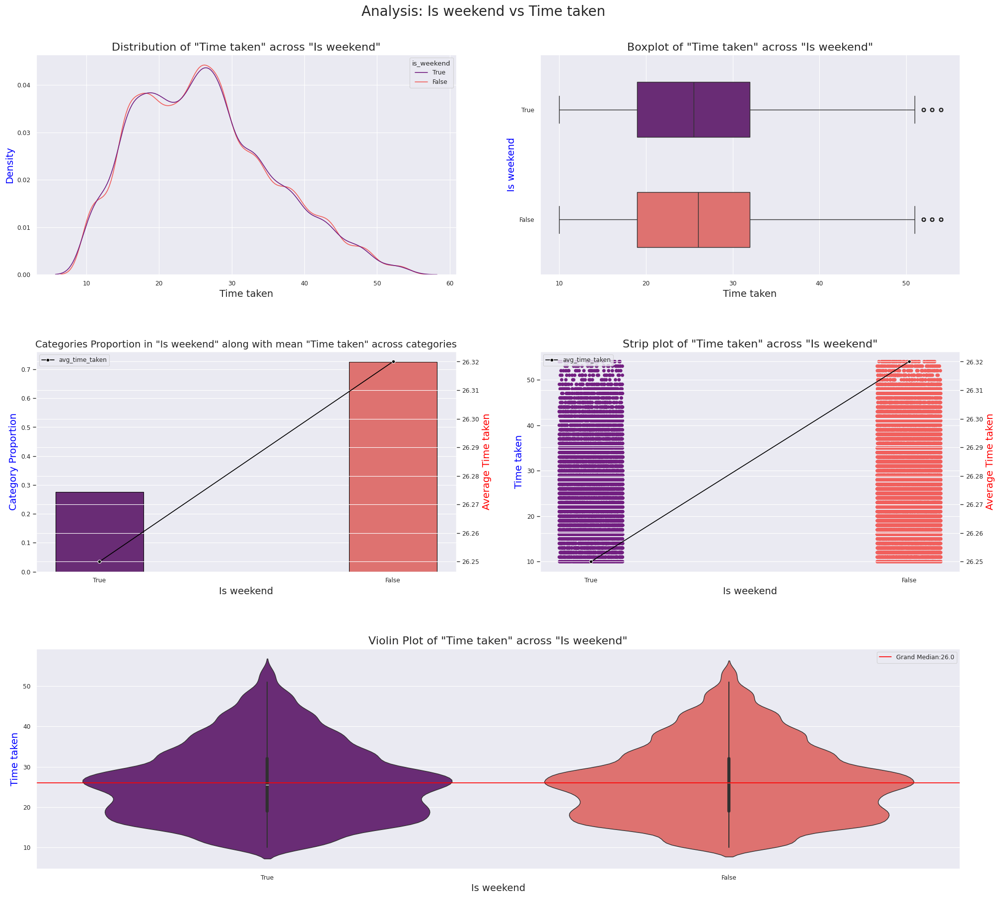

--------------------------------------------------------------------------------------------------------------------------------------------
Welch t-test (not assumed equal variance)

Fail to Reject Ho
Result: t-test indicated there is No significant difference between the mean of "time_taken" across two categories of "Is weekend"
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df.copy(), feature = 'is_weekend', target = 'time_taken', palette = 'magma')

,is_friday_night,count,proportion_%,mean_time_taken,std_time_taken
0,False,40855,89.9,26.09,9.32
1,True,4590,10.1,28.20,9.77


----------------------------------------------------------------------------------------------------------------------------------------------------------------


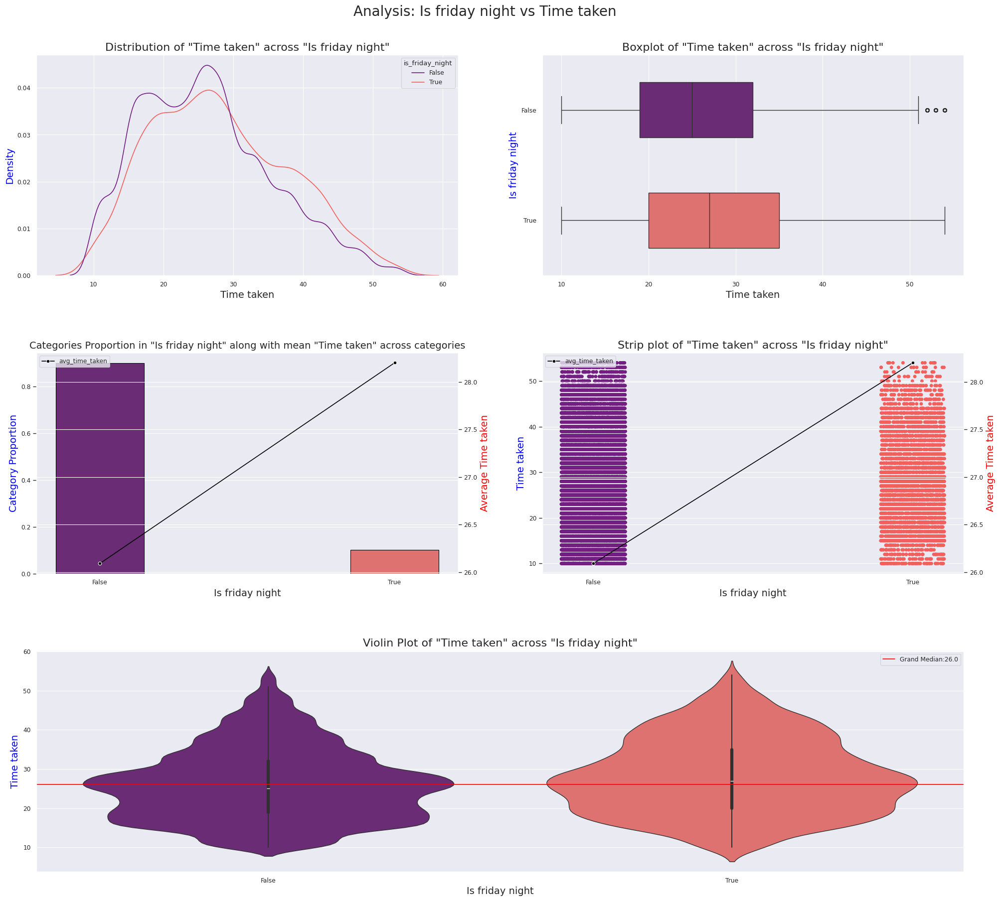

--------------------------------------------------------------------------------------------------------------------------------------------
Welch t-test (not assumed equal variance)

Reject Ho
Result: t-test indicates there is a significant difference between the mean of "time_taken" across two categories of "Is friday night"
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df.copy(), feature = 'is_friday_night', target = 'time_taken', palette = 'magma')

In [ ]:
get_hypothesis_test_results_for_categorical_column(df = df.copy(), feature_given = 'is_friday_night')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,is_friday_night,city_name,0.0,city_name,time_taken,0.166
1,is_friday_night,order_time_of_day,0.0,order_time_of_day,time_taken,0.000
2,is_friday_night,is_lunch_rush,0.0,is_lunch_rush,time_taken,0.150
3,is_friday_night,is_dinner_rush,0.0,is_dinner_rush,time_taken,0.000
4,is_friday_night,order_day_of_week,0.0,order_day_of_week,time_taken,0.000
5,is_friday_night,is_weekend,0.0,is_weekend,time_taken,0.491
6,is_friday_night,is_month_start,0.0,is_month_start,time_taken,0.000
7,is_friday_night,is_month_end,0.0,is_month_end,time_taken,0.000
8,is_friday_night,is_festival,0.0,is_festival,time_taken,0.000
9,is_friday_night,traffic,0.0,traffic,time_taken,0.000


### a. Final Observations
- Since `is_weekend` is derived from `order_day_of_week` &
- `is_friday_night` is derived from `order_day_of_week` & `order_placed_hr`
- Much of the observed variation in time_taken appears to be explained more strongly by features such as
  - distance_km,
  - traffic,
  - is_festival
  - multiple_deliveries etc
  - Rather than `order_day_of_week`, `is_weekend`, `is_friday_night` itself.

## 17.order_month, is_month_start, is_month_end

### a. Uni & Bi-Variate Analysis

,order_month,count,proportion_%,mean_time_taken,std_time_taken
0,4.0,6353,13.962,26.11,9.27
1,3.0,31918,70.148,26.28,9.40
2,2.0,7230,15.890,26.53,9.44


----------------------------------------------------------------------------------------------------------------------------------------------------------------


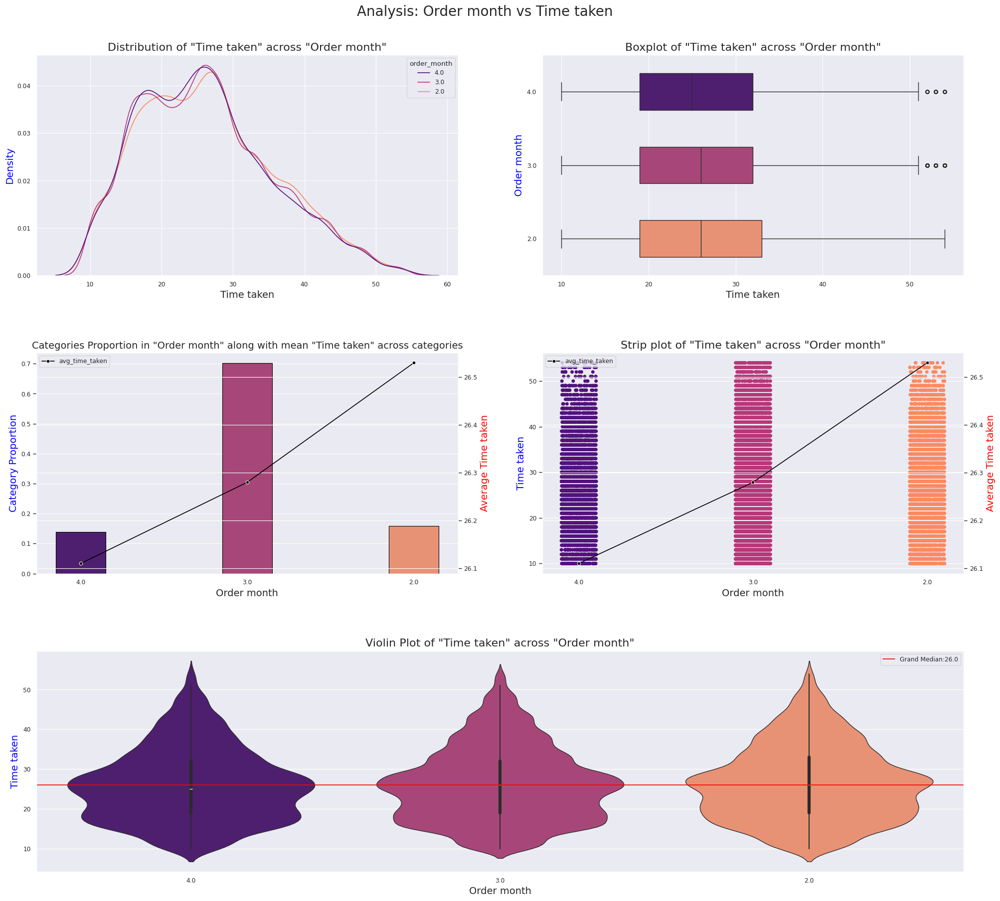

--------------------------------------------------------------------------------------------------------------------------------------------
Welch One-Way ANOVA (not assumed equal variance)

Reject Ho
Result: Significant difference in category mean of "time_taken" detected across "Order month"
Result: Welch’s ANOVA indicates that atleast one category mean of "time_taken" is significantly differs from the rest of the others
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df.copy(), feature = 'order_month', target = 'time_taken', palette = 'magma')

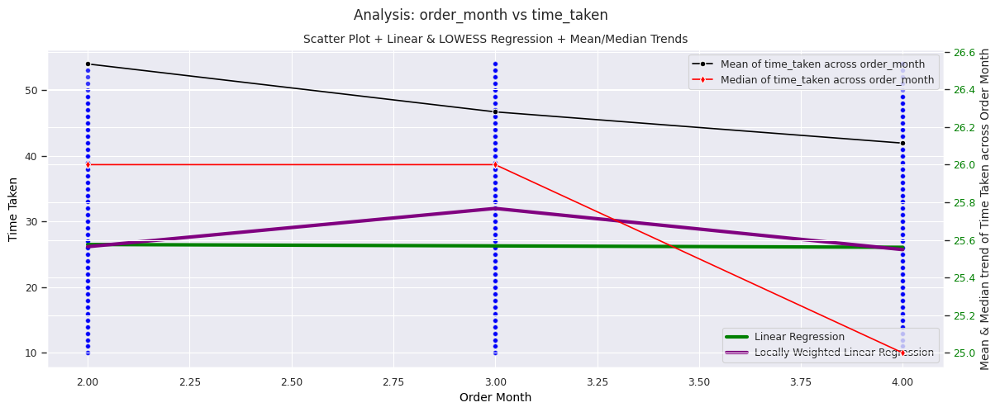

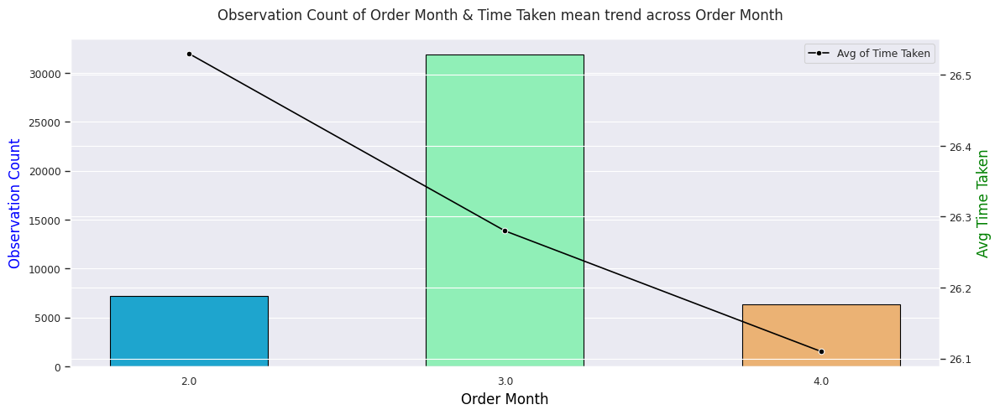

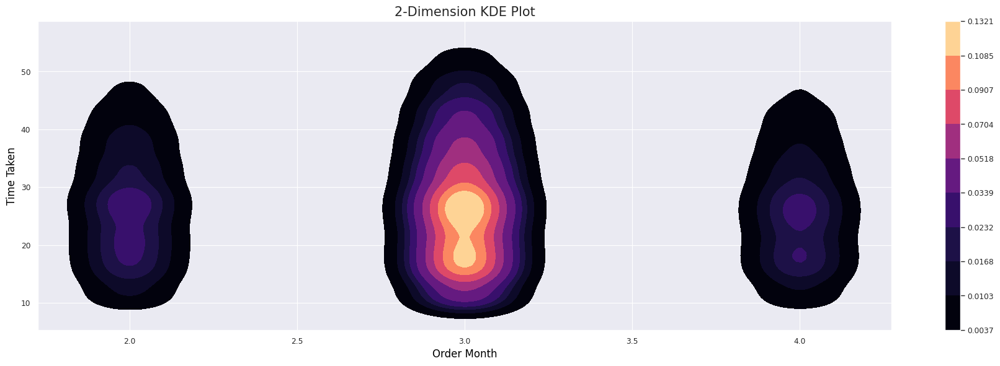

----------------------------------------------------------------------------------------------------------------------------------
STATISTICS FOR Order Month vs Time Taken
Mutual Information: 0.0028 (Higher = more dependency)
Spearman Rank:      -0.0124 (Robust to non-linear)
Pearson Coef:       -0.0124

Result: Statistically significant monotonic association detected between Order Month & Time Taken by Spearman Rank
----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_numerical_vs_numerical(df.copy(), feature = 'order_month', feature_type = 'discrete', target = 'time_taken', palette = 'magma')

### b. Final Observations
- `order_month` visually shows no relationship with time_taken  
- Correlation values are extremely small and mutual information indicates zero dependency  
- Distribution of order month 2 & 4 overlap
- Box plot & Violen Plot remain nearly identical across the observed months  
- The month of order placement does not meaningfully influence delivery duration.  
- Much of the observed variation in time_taken appears to be explained more strongly by other features than `order_day` itself

## 18.rider_age

### a. Uni-Variate Analysis

Data-Type: float64
Missing Value %: 4.07
Outlier count (IQR rule): 0


,rider_age
count,43648.00
mean,29.56
std,5.76
min,20.00
25%,25.00
50%,30.00
75%,35.00
max,39.00


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


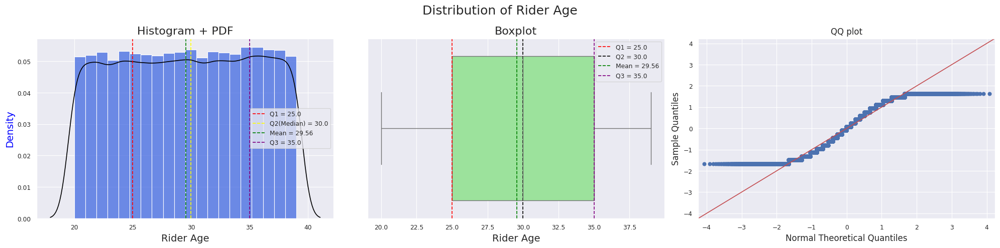

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Skewness: -0.0

But Overall Distribution of Rider Age is: Perfectly Symmetrical

Excess Kurtosis: -1.209
Platykurtic -> Distribution of Rider Age has "thin tails" and "fewer outliers" than a Normal distribution.

Omnibus Test for Normality
OB: Result: Reject Null Hypothesis. Data is not Normally Distributed

Anderson–Darling Test for Normality
AD: Result: Reject Null Hypothesis. Data is not Normally Distributed 

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_univariate_analysis_for_numerical_feature(df = df.copy(), feature = 'rider_age', num_bins = 20)

### b. Bi-Variate Analysis

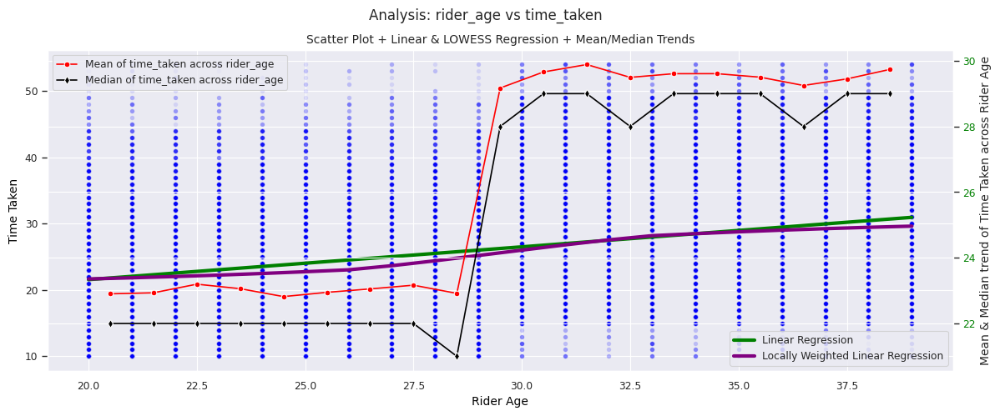

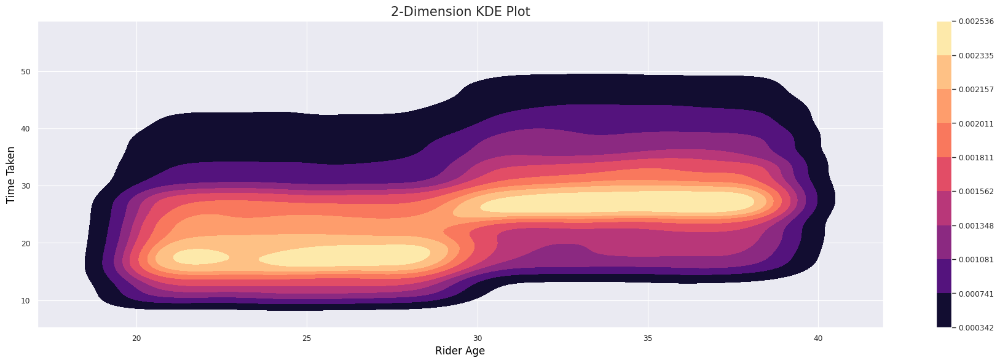

----------------------------------------------------------------------------------------------------------------------------------
STATISTICS FOR Rider Age vs Time Taken
Mutual Information: 0.0707 (Higher = more dependency)
Spearman Rank:      0.3133 (Robust to non-linear)
Pearson Coef:       0.3038

Result: Statistically significant monotonic association detected between Rider Age & Time Taken by Spearman Rank
----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_numerical_vs_numerical(df = df.copy(), feature = 'rider_age', feature_type = 'continuous', target = 'time_taken',
                                                  bins_to_divide = 50, palette = 'magma')

# rider age is discrete numerical variable

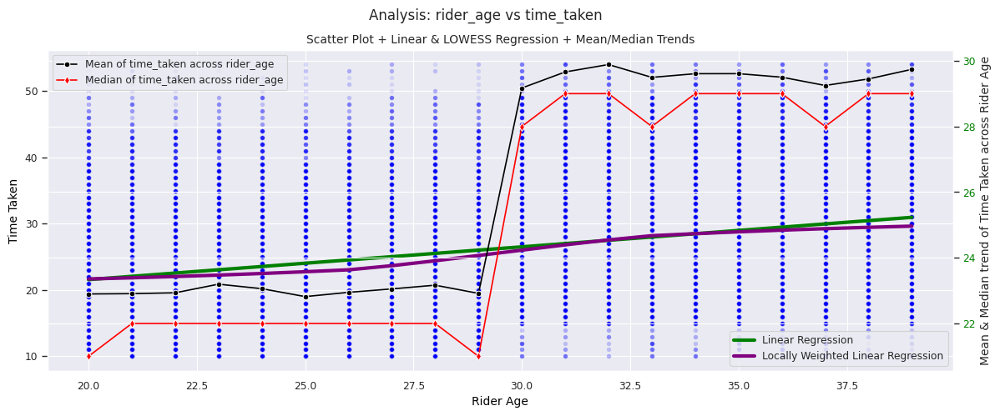

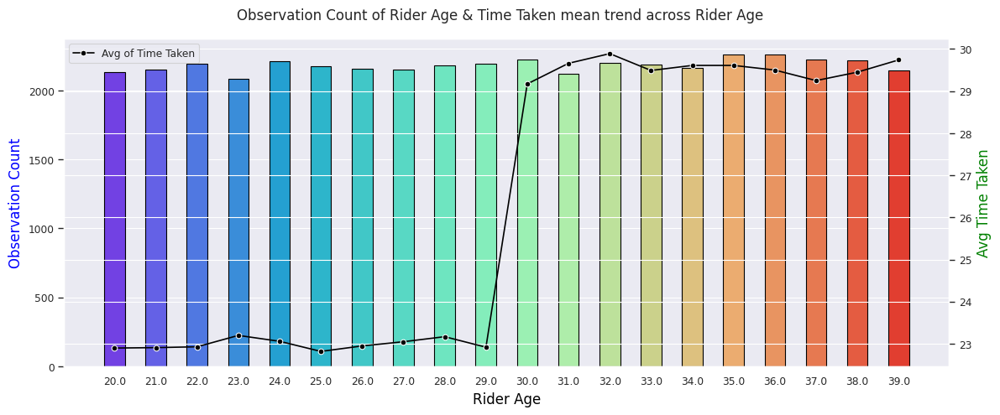

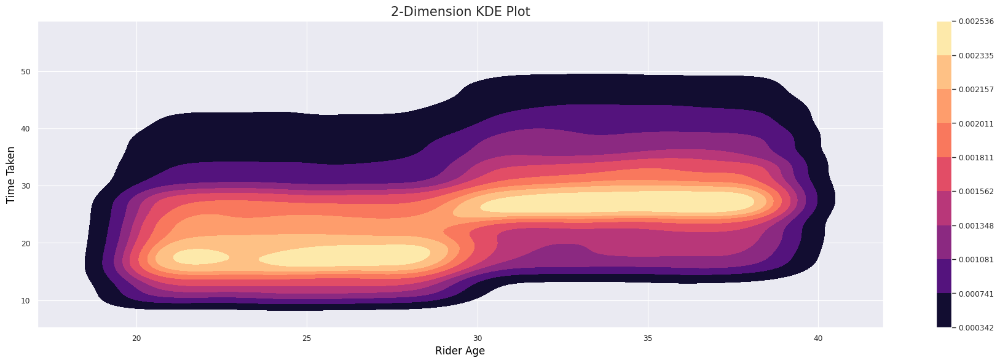

----------------------------------------------------------------------------------------------------------------------------------
STATISTICS FOR Rider Age vs Time Taken
Mutual Information: 0.0707 (Higher = more dependency)
Spearman Rank:      0.3133 (Robust to non-linear)
Pearson Coef:       0.3038

Result: Statistically significant monotonic association detected between Rider Age & Time Taken by Spearman Rank
----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_numerical_vs_numerical(df = df.copy(), feature = 'rider_age', feature_type = 'discrete', target = 'time_taken',
                                                  bins_to_divide = 50, palette = 'magma')

### c. Multi-Variate Analysis

#### Q1. Does riders of age between 20-29 covers more distance than riders of age 30-39 which cause this spike in time_taken

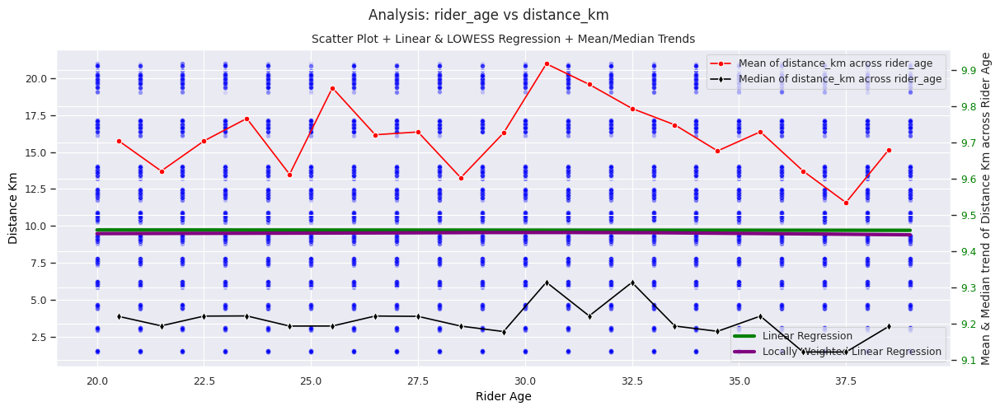

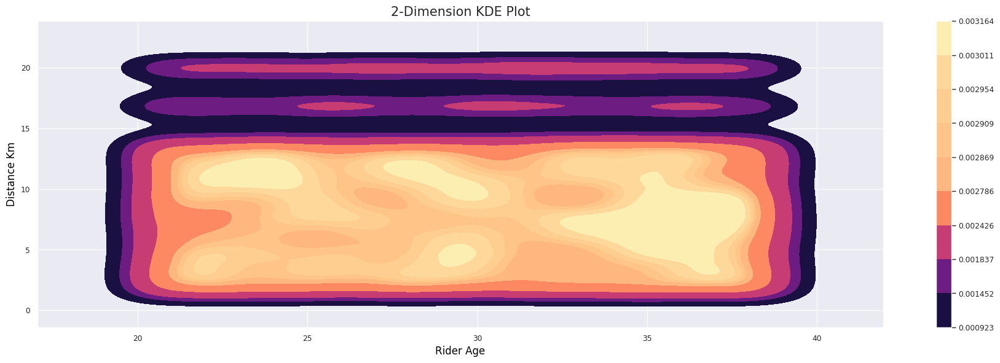

----------------------------------------------------------------------------------------------------------------------------------
STATISTICS FOR Rider Age vs Distance Km
Mutual Information: 0 (Higher = more dependency)
Spearman Rank:      -0.0019 (Robust to non-linear)
Pearson Coef:       -0.0014

Result: No statistically significant monotonic association detected between Rider Age & Distance Km by Spearman Rank
----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_numerical_vs_numerical(df.copy(), feature = 'rider_age', feature_type = 'continuous', target = 'distance_km',
                                                  bins_to_divide = 20, palette = 'magma')

In [ ]:
mask1 = new_df['rider_age'].between(20,29)
mask2 = new_df['rider_age'].between(30,39)

s1 = new_df.loc[mask1, ['distance_km', 'time_taken']].mean().round()
s1.name = 'Age 20 to 29'
s1.index.name = 'Average'

s2 = new_df.loc[mask2, ['distance_km', 'time_taken']].mean().round()
s2.name = 'Age 30 to 39'
s2.index.name = 'Average'

display(s1)
display(s2)

,Age 20 to 29
Average,
distance_km,10.0
time_taken,23.0


,Age 30 to 39
Average,
distance_km,10.0
time_taken,30.0


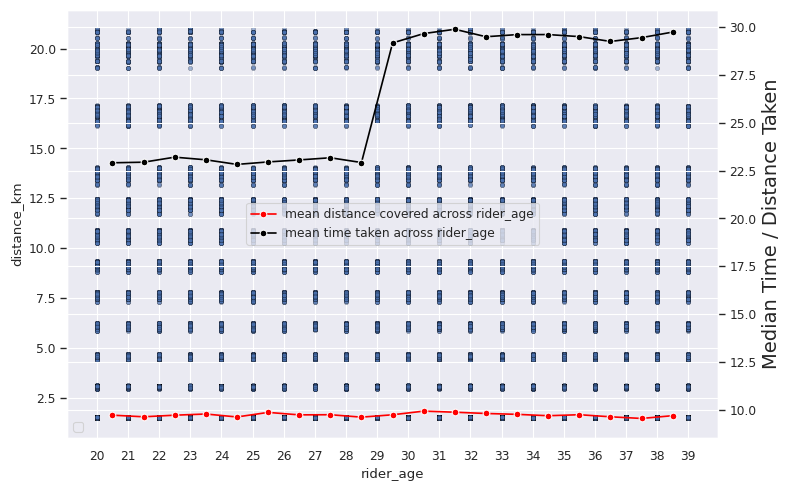

In [ ]:
col_name = 'rider_age'

d1 = new_df.copy()
d1['bin'] = pd.qcut(d1[col_name], q = 30, duplicates='drop')
d1['mid'] = d1['bin'].apply(lambda x: x.mid)

fig, ax_scatter = plt.subplots(nrows = 1, ncols = 1, figsize = (8,5))
ax_mean = ax_scatter.twinx()

sns.scatterplot(data = d1, x = col_name, y = 'distance_km', s = 10,  marker = 'o', alpha = 0.5, edgecolor = 'black', palette = 'magma', ax = ax_scatter)
ax_scatter.set_xticks(sorted(df[col_name].dropna().unique()))
ax_scatter.legend(loc = 'lower left')

sns.lineplot(data = d1.groupby('mid')['distance_km'].mean().sort_index(), label = f'mean distance covered across {col_name}', color = 'red', marker = 'o', ax = ax_mean)
sns.lineplot(data = d1.groupby('mid')['time_taken'].mean().sort_index(),  label = f'mean time taken across {col_name}', color = 'black', marker = 'o', ax = ax_mean)
ax_mean.set_ylabel('Median Time / Distance Taken', fontsize = 14)
ax_mean.legend(loc = 'center')

plt.tight_layout()
plt.show()

Observations:

1. Among the riders of two different age groups, Mean distance covered is same i.e 10 km, but still there is a 7 min difference in time taken to deliver order

2. In our scatter plot, there is no such clear trend which shows that as the rider_age increases distance increases, which also signifies that there is no such clear trend which show that younger rider covers more distance than the older riders

3. There is enough variablity in distance despite rider age.

4. Spearman Rank cor-relation also says that "No statistically significant monotonic association detected between rider_age & distance_km"

5. Linear Regression line and LOWESS Regression cruve is flat too

6. So the answer of our question **"Does riders of age between 20-29 covers more distance than riders of age 30-39 which cause this spike in time_taken ?"**: No

In [ ]:
mask1 = df['rider_age'].between(20,29) & df['time_taken'].between(10,20, inclusive = 'left')
mask2 = df['rider_age'].between(30,39) & df['time_taken'].between(10,20, inclusive = 'left')

mask3 = df['rider_age'].between(20,29) & df['time_taken'].between(20,30, inclusive = 'left')
mask4 = df['rider_age'].between(30,39) & df['time_taken'].between(20,30, inclusive = 'left')

mask5 = df['rider_age'].between(20,29) & df['time_taken'].between(30,40, inclusive = 'left')
mask6 = df['rider_age'].between(30,39) & df['time_taken'].between(30,40, inclusive = 'left')

mask7 = df['rider_age'].between(20,29) & df['time_taken'].between(40,50, inclusive = 'left')
mask8 = df['rider_age'].between(30,39) & df['time_taken'].between(40,50, inclusive = 'left')

d1 = df.loc[mask1, 'distance_km'].mean().round(2)
d2 = df.loc[mask2, 'distance_km'].mean().round(2)
d3 = df.loc[mask3, 'distance_km'].mean().round(2)
d4 = df.loc[mask4, 'distance_km'].mean().round(2)
d5 = df.loc[mask5, 'distance_km'].mean().round(2)
d6 = df.loc[mask6, 'distance_km'].mean().round(2)
d7 = df.loc[mask7, 'distance_km'].mean().round(2)
d8 = df.loc[mask8, 'distance_km'].mean().round(2)

In [ ]:
print('Average Distance Covered when:\n')
print('Age between 20 to 29 & time between 10 to 20:', d1,'km')
print('Age between 30 to 39 & time between 10 to 20:', d2,'km\n')

print('Age between 20 to 29 & time between 20 to 30:', d3,'km')
print('Age between 30 to 39 & time between 20 to 30:', d4,'km\n')

print('Age between 20 to 29 & time between 30 to 40:', d5,'km')
print('Age between 30 to 39 & time between 30 to 40:', d6,'km\n')

print('Age between 20 to 29 & time between 40 to 50:', d7,'km')
print('Age between 30 to 39 & time between 40 to 50:', d8,'km')

Average Distance Covered when:

Age between 20 to 29 & time between 10 to 20: 7.95 km
Age between 30 to 39 & time between 10 to 20: 7.2 km

Age between 20 to 29 & time between 20 to 30: 9.97 km
Age between 30 to 39 & time between 20 to 30: 8.47 km

Age between 20 to 29 & time between 30 to 40: 12.78 km
Age between 30 to 39 & time between 30 to 40: 10.52 km

Age between 20 to 29 & time between 40 to 50: 13.22 km
Age between 30 to 39 & time between 40 to 50: 13.78 km


7. These observations shows that there is no association between rider_age and distance, distance covered by the rider, does not depends on whats the rider age is

In [ ]:
get_hypothesis_test_results_for_numerical_column(df.copy(), 'rider_age')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,rider_age,multiple_deliveries,0.00,multiple_deliveries,time_taken,0.00
1,rider_age,rider_ratings,0.00,rider_ratings,time_taken,0.00
2,rider_age,is_festival,0.00,is_festival,time_taken,0.00
3,rider_age,is_lunch_rush,0.02,is_lunch_rush,time_taken,0.16


#### Q2. Check why there is a sudden steep jump in time_taken occurs when rider age cross 29 ?

In [ ]:
print('Data when rider age is between 20 - 29')
display(df[df['rider_age'].between(20,29)]['multiple_deliveries'].value_counts())

print('Data when rider age is between 30 - 39')
display(df[df['rider_age'].between(30,39)]['multiple_deliveries'].value_counts())

# In our data there is a strange pattern,
# we can see that younger riders with age [20 - 29] do very less stacked deliveries
# From scatter plot you can see that density of multiple deliveries slight increase as rider age cross 29
# than older rider with age >= 30

Data when rider age is between 20 - 29


,count
multiple_deliveries,
1.0,12779
0.0,7722
2.0,528
3.0,78


Data when rider age is between 30 - 39


,count
multiple_deliveries,
1.0,14144
0.0,5816
2.0,1384
3.0,263


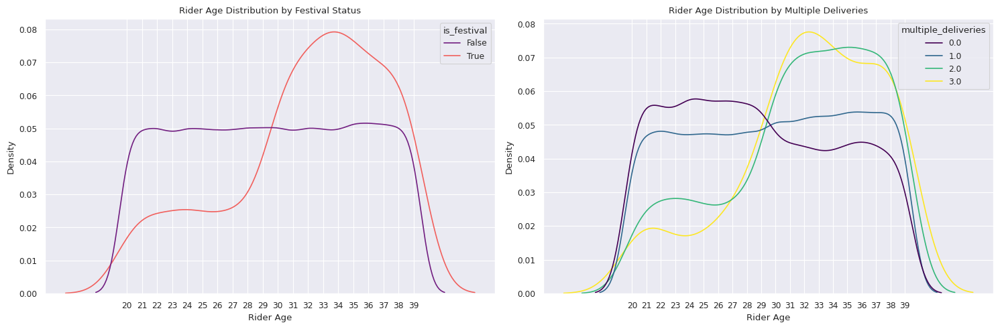

In [ ]:
clean_df = new_df.dropna(subset = ['rider_age', 'is_festival','multiple_deliveries'])

age_ticks = sorted(clean_df['rider_age'].unique())

fig, (kde_festival, kde_deliveries) = plt.subplots(nrows = 1, ncols = 2, figsize = (15, 5))

# Rider age distribution by festival status
sns.kdeplot(data = clean_df, x = 'rider_age', hue = 'is_festival', common_norm = False, palette = 'magma', ax = kde_festival)
kde_festival.set_xticks(age_ticks)
kde_festival.set_title('Rider Age Distribution by Festival Status')
kde_festival.set_xlabel('Rider Age')
kde_festival.set_ylabel('Density')

# Rider age distribution by number of deliveries
sns.kdeplot(data = clean_df, x = 'rider_age', hue = 'multiple_deliveries', common_norm = False, palette = 'viridis', ax = kde_deliveries)
kde_deliveries.set_xticks(age_ticks)
kde_deliveries.set_title('Rider Age Distribution by Multiple Deliveries')
kde_deliveries.set_xlabel('Rider Age')
kde_deliveries.set_ylabel('Density')

plt.tight_layout()
plt.show()

# Our data is in such way that
# L(festival = True| rider age > 29) >> L(festival = False | rider age > 29) &
# L(multiple_deliveries = 3 or 2 | rider age > 29) >> L(multiple deliveries = 0,1 | rider age > 29) &
#
# There is a spike in conditional probablity of festival and mutliple deliveries when age cross 28
#
# They itself on their own cause delay in delivery time of an order

- Come back here after doing EDA of multiple deliveries & rider_ratings and add some more observations

In [ ]:
print('Data when rider age is between 20 - 29')
display(df[df['rider_age'].between(20,29)]['is_festival'].value_counts())
print()

print('Data when rider age is between 30 - 39')
display(df[df['rider_age'].between(30,39)]['is_festival'].value_counts())

# In our data there is a also strange pattern that rider below age of 30 faces less festival time as comparision to rider on 30 onwards
# Festival count gets greater than doubled 2x its. 642 vs 210
# & from our previous observation we already know that festival feature itself increase delivery time very much

Data when rider age is between 20 - 29


,count
is_festival,
False,21223
True,210



Data when rider age is between 30 - 39


,count
is_festival,
False,21355
True,642


#### Q3. KDE Plot shows two high denisty regions of rider_age and time_taken.
  - Region 1 - Rider of age 20 to 29 and delivery time between 10 to 29 mins
  - Region 2 - Rider of age 30 to 54 and delivery time between 30 to 54 mins

  1. Compare if the riders in those two different high density regions of cover similar distance or different ?
     - different distance

  2. Is distance causes different delivery time gap in those two different regions or there are some another reasons too ?
     - distance, festival, mutliple deliveries, traffic conditions

In [ ]:
d1 = df[df['rider_age'].between(20,29) & df['time_taken'].between(10,29)]
d2 = df[df['rider_age'].between(30,39) & df['time_taken'].between(30,54)]

print('Region:1')
print(d1['distance_km'].mean())
display(d1['is_festival'].value_counts())
display(d1['multiple_deliveries'].value_counts())
display(d1['traffic'].value_counts())
print()

print('Region:2')
print(d2['distance_km'].mean())
display(d2['is_festival'].value_counts())
display(d2['multiple_deliveries'].value_counts())
display(d2['traffic'].value_counts())

Region:1
8.955410204787858


,count
is_festival,
False,17234


,count
multiple_deliveries,
1.0,10059
0.0,6907


,count
traffic,
Low,7209
Jam,4284
Medium,4259
High,1684



Region:2
11.631244100777785


,count
is_festival,
False,9335
True,642


,count
multiple_deliveries,
1.0,6293
0.0,1902
2.0,1384
3.0,263


,count
traffic,
Jam,4899
Medium,2804
High,1189
Low,1085


#### Q4. Within the same age, why there is variablity in time_taken to deliver order ?

1. Traffic is one of the core reason for this variablity in time_taken to deliver order within the same age

2. is_festival, multiple_deliveries also has more mild impact in variablity in time_taken to deliver order within the same age

3. You can say that one single feature cannot fully explain the variablity arise in the time_taken within the same age

4. Variablity in time_taken within the same age, arises from the combinatins of multiple features such as `traffic` + `festival` + `multiple_deliveries`

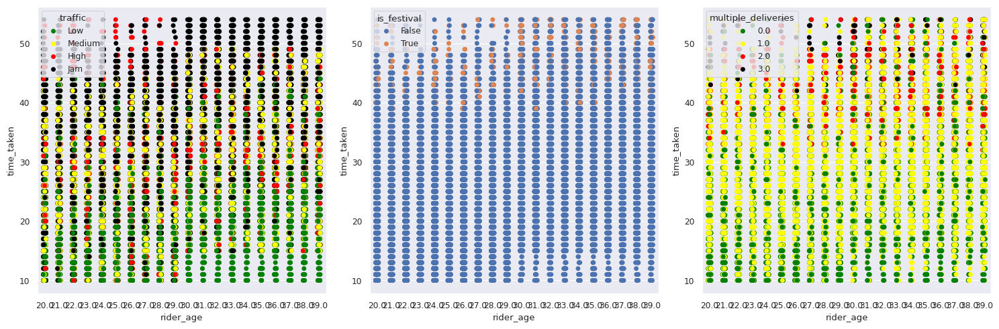

In [ ]:
x_labels = sorted(np.array(new_df['rider_age'].unique(), dtype = str))

fig, (ax_traffic, ax_festival, ax_deliveries) = plt.subplots(nrows = 1, ncols = 3, figsize = (15,5))

sns.stripplot(data = clean_df, x = 'rider_age', y = 'time_taken', hue = 'traffic', palette = {'Low':'green', 'Medium':'yellow', 'High':'red', 'Jam':'black'}, ax = ax_traffic)
sns.stripplot(data = clean_df, x = 'rider_age', y = 'time_taken', hue = 'is_festival', ax = ax_festival)
sns.stripplot(data = clean_df, x = 'rider_age', y = 'time_taken', hue = 'multiple_deliveries', palette = {0:'green', 1:'yellow', 2:'red', 3:'black'}, ax = ax_deliveries)
plt.tight_layout()
plt.show()


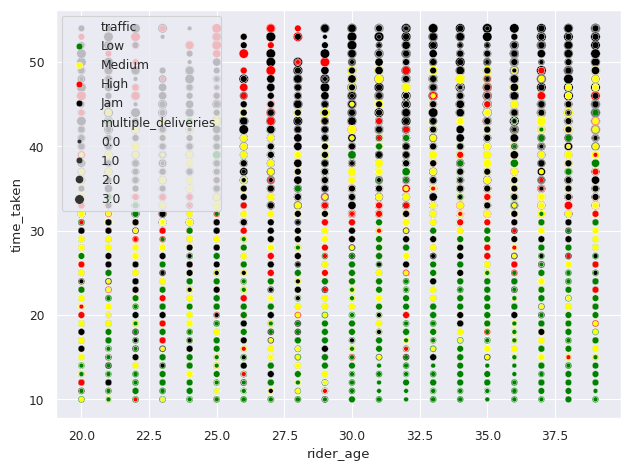

In [ ]:
sns.scatterplot(data = new_df, x = 'rider_age', y = 'time_taken', hue = 'traffic',  size = 'multiple_deliveries',
                palette = {'Low':'green', 'Medium':'yellow', 'High':'red', 'Jam':'black'})

sns.scatterplot(data = df.dropna(), x = 'rider_age', y = 'time_taken', hue = 'is_festival',    ax = ax_festival)
plt.tight_layout()
plt.show()

#### Q5. Since there is a moderate co-relation between rider_age and time_taken. But is rider_age also the causation of time_taken ?
- No

### d. Observations

---
1. **Correlation Interpretation**
   - Both Pearson (0.30) and Spearman (0.31) correlations indicate that `time_taken` tends to increase slightly with `rider_age`.
   - The relationship between `rider_age` and `time_taken` is monotonically increasing
   - The relationship is positive, meaning older riders are associated with somewhat longer delivery times.
   - The association is statistically significant, suggesting that the observed relationship(effet) is unlikely to have occured by random variation.

---
2. **Scatter Plot + LOWESS Trend + KDE Density Interpretation**
   
   **a. Scatter plot**
   - A weak upward trend between rider_age and time_taken.
   - Spread of delivery times across all ages, indicating large variability.

   **b. Regression and LOWESS trends**
   - The green linear regression line trends upward & the purple LOWESS curve also trends upward.
   - Both models suggest a increasing trend between `rider age` & `time_taken`.
   - The similarity between LOWESS and linear regression indicates no strong nonlinear structure.
   - But the slope of regression line is gentle, meaning the effect of `rider_age` on `time_taken` is not that strong.
   - This means: `rider_age` alone cannot fully explain variability in `time_taken`.
   - Often on Calculation R2 score = Pearson^2 = 0.3^2 = 0.09.
   - This suggests: Only ~9% of the variation in `time_taken` is being explained by `rider_age` alone.
   - Thus: Most variability arises from other features or combination of others features.
   
   **c. Mean and Median Bin Trends**
   - There is a higher shift in both mean and median delivery times after rider age crosses 29.
   - Younger riders [20 - 29] tend to have lower average delivery times.
   - Riders above 29 show higher average delivery times.

   **d. KDE Density Interpretation**
   - The KDE density suggests two regions: riders aged 20-29 are more concentrated around lower delivery times, whereas riders aged 30-39 show higher density around larger delivery times.
   - Younger riders are more concentrated in faster delivery ranges.
   - Despite the observed clusters:
     - There remains significant overlap across age groups.
     - Fast deliveries still occur across many age values.
     - Age alone is not the primary driver of delivery time.

---
3. **Mutual Information Interpretation**
   - Mutual Information measures any statistical dependency (linear or nonlinear).
   - The value 0.07 is very small, indicating limited shared information between rider_age and time_taken.
   - Even though: A statistically significant correlation exists, the overall dependency remains weak.
   
---
4. **Conclusion**
   - `rider_age` may provide some information but is unlikely to be a primary driver of predictions.
   
   - It may contribute some predictive signal. However, it is unlikely to be a high-importance feature compared to other variables which suggests: **Most variability arises from other features or combination of other features which we already seen in Multi-Variate Analysis**

   - **`rider_age` is linked to a broader context of `longer distance routes`, `heavier traffic`, `festival` and may also along with others features, of which combined effect causes delay effects in delivery.**

## 19.rider_ratings

### a. Uni-Variate Analysis

Data-Type: float64
Missing Value %: 4.19
Outlier count (IQR rule): 1132


,rider_ratings
count,43594.00
mean,4.64
std,0.31
min,2.50
25%,4.50
50%,4.70
75%,4.90
max,5.00


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


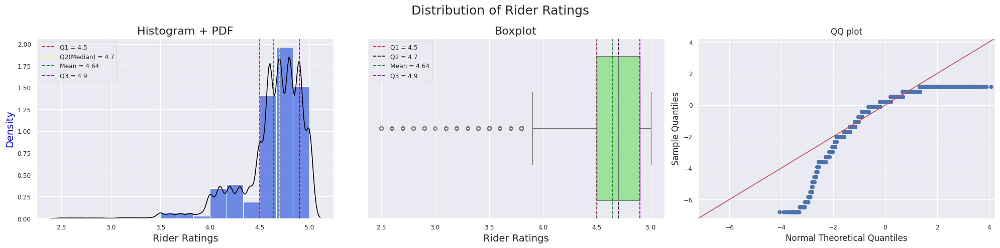

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Skewness: -1.8
Distribution of Rider Ratings is Left-Skewed
The left tail is longer
The mean is less than the median, which is pulled lower by a few small extreme values.
Rider Ratings is: Highly Skewed

Excess Kurtosis: 5.137
Leptokurtic -> Distribution of Rider Ratings has "fat tails" and a "higher frequency of extreme outliers" than a Normal Distribution".

Omnibus Test for Normality
OB: Result: Reject Null Hypothesis. Data is not Normally Distributed

Anderson–Darling Test for Normality
AD: Result: Reject Null Hypothesis. Data is not Normally Distributed 

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_univariate_analysis_for_numerical_feature(df.copy(), 'rider_ratings', num_bins = 15)

Observations:

1. Riders with ratings >= 4.5 dominate this swiggy data.
2. High ratings riders dominate over low ratings riders.
3. Maybe because company prefer such types of riders too
4. Outliers are riders who have ratings roughly < 3.8

### b. Outlier Detection

In [ ]:
check_for_outliers(df.copy(), 'rider_ratings')

# Q. Do the rider_ratings outliers look like genuine operational cases, or do they look suspicious / artificial ?
# - So for that goal, the right interpretation is:
#   a. Do outlier cases show systematic association with plausible real-world conditions ?
#   b. Or do they look random, inconsistent, or impossible?

# 1. For numerical features, this analysis compares the average value in outlier deliveries and non outlier deliveries.
#    So, the interpretation is about **difference between groups**, not direct causation.

# 2. For categorical features, this analysis compares the proportion of each category among outlier rider ratings and
#    non outlier rider ratings such as,
#    P(category | outlier in rider ratings) vs P(category | no outlier in rider ratings)
#    So, the interpretation is about association and over-representation, not causation.

# 3. It tells us which categories are more common or less common among outlier deliveries.

------------------------------------------------------------------------Numerical Data-Type-----------------------------------------------------------------


,feature,when_no_outliers_in(rider_ratings),when_outliers_in(rider_ratings)
0,time_taken,26.02,37.08
1,distance_km,9.60,14.15
2,rider_age,29.49,31.89
3,order_pickup_time_mins,9.99,10.00



------------------------------------------------------------------------Categorical Data-Type-----------------------------------------------------------------


vehicle_type,Scooter,Electric-Scooter,Motor-Cycle,Bicycle
P(vehicle_type | outliers in rider_ratings),0.475,0.092,0.433,NaN
P(vehicle_type | no-outliers in rider_ratings),0.331,0.083,0.585,0.001



 --------------------------------------------------------------------------------------------------------------------------------------------


vehicle_condition,1,2,0,3
P(vehicle_condition | outliers in rider_ratings),0.458,0.436,0.105,NaN
P(vehicle_condition | no-outliers in rider_ratings),0.327,0.328,0.336,0.01


... (25 outputs left out)

is_festival,True,False
P(is_festival | outliers in rider_ratings),0.059,0.941
P(is_festival | no-outliers in rider_ratings),0.019,0.981



 --------------------------------------------------------------------------------------------------------------------------------------------


traffic,Jam,Low,High,Medium
P(traffic | outliers in rider_ratings),0.451,0.381,0.026,0.142
P(traffic | no-outliers in rider_ratings),0.311,0.343,0.100,0.246



 --------------------------------------------------------------------------------------------------------------------------------------------


**Observations from outliers:**

---
**Why they look genuine**

1. **Longer distance:**
   - Outlier cases have higher average distance:
   - Outliers: 14.15 km
   - Non-outliers: 9.60 km
   - This is a big difference.
   - So, outlier in rider ratings cases were handling longer deliveries -> which can create more delay -> more customer dissatisfication -> lower ratings to riders

2. **More common in evening and night**
   - Outlier in rider ratings are mostly seen in: Night, Late Night & Evening
   - They are much less common in Morning and Afternoon.
   - This looks realistic because delivery pressure is often higher in busy late hours -> can create more delay -> customer dissatisfication -> lower ratings to riders
   - That is a very strong and realistic timing pattern. If the outliers were artificial, we would not expect such a clear concentration in busy hours

3. **Dinner rush is higher**   
   - Outlier cases happen more during dinner rush:
     - P(is_dinner_rush | outlier) = 0.695
     - P(is_dinner_rush | no outlier) = 0.517
     - This is a noticeable increase.
     - That makes sense : during dinner rush, the system is likely under more load,
     - This suggests that low rider rating outliers are more common when delivery demand is high is dinning hours -> which create more delay -> customer dissatisfication -> lower ratings to riders

4. **Traffic jam is higher**
   - Outlier cases have more Jam traffic than non-outlier cases.
   - That make sense: more traffic can lead to delays and worse customer experience, which can translate into unusually low ratings.
  
5. **Things that do not look very important here**
   - Some variables do not show a strong difference between outlier and non-outlier cases, such as:
     - order_pickup_time_mins
     - order_type
     - is_weekend & others

   - So, **these features do not seem to explain rider rating outliers much on their own.**

6. **Important Point to Remeber & Conclusion**

   - The outliers in rider_ratings appear more likely to be genuine operational cases than random or artificial / random noise

   - For time_taken, extreme values were directly tied to real world delay factors, so it was easier to say they looked genuine.

   - For rider_ratings, the outliers are still likely genuine, but **rider_ratings is a subjective because it depends on customer experience with delivery**

   - That means low-rating outliers can arise from:
     
     - Bad delivery experience of customers which itself arises from multiple factors that causes delay.
     - So even if these ratings outliers look genuine, that does not mean every low rating is fully fair or fully caused by the rider.
     - Low rider ratings does not mean that every low rating is a clean measurement of rider performance.
   
   - So **we should be a little more careful with rating outliers than with time_taken outliers.**

   - They should not be removed automatically.
   - Because they are linked with plausible stressful delivery conditions, especially:
     - longer distance
     - evening/night timing
     - dinner rush
     - Traffic jam
     - festival times
     - others

   - Removal would only be justified if there is separate evidence of:
     - Invalid ratings
     - impossible values,
     - Duplicate rows
     - Data-quality issues.

### c. Bi-Variate Analysis

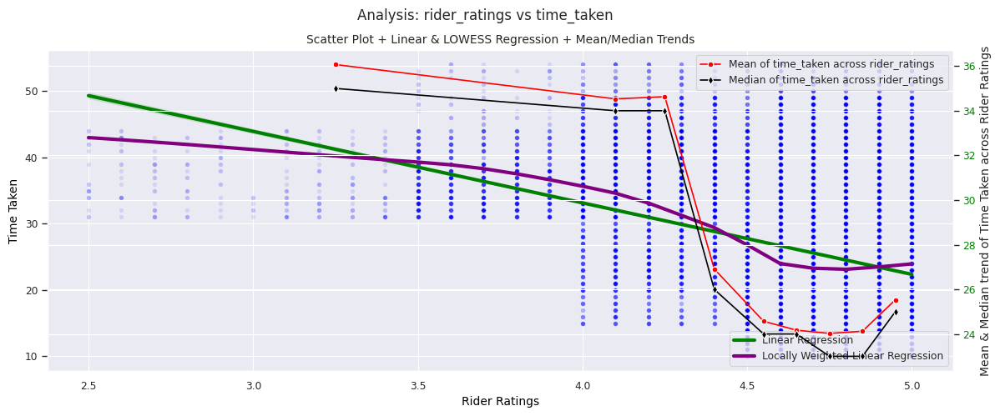

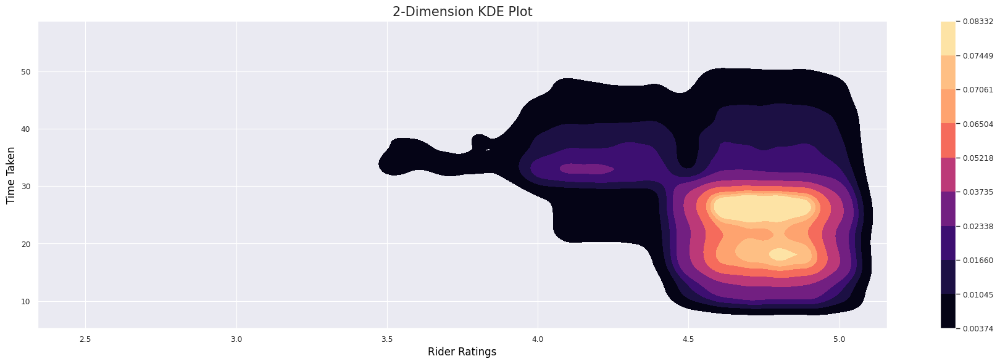

----------------------------------------------------------------------------------------------------------------------------------
STATISTICS FOR Rider Ratings vs Time Taken
Mutual Information: 0.1637 (Higher = more dependency)
Spearman Rank:      -0.2946 (Robust to non-linear)
Pearson Coef:       -0.361

Result: Statistically significant monotonic association detected between Rider Ratings & Time Taken by Spearman Rank
----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_numerical_vs_numerical(df.copy(), feature = 'rider_ratings', feature_type = 'continuous', target = 'time_taken', palette = 'magma')

### d. Observations

---
1. **Correlation Interpretation**

   - The relationship between rider_ratings and time_taken is approximately monotonic (decreasing trend)
   - Both correlations indicate that higher rider ratings are associated with shorter delivery times.
   - The association is negative, meaning that as rider ratings increase, delivery time tends to decrease.
   - The relationship is statistically significant, implying that the observed pattern is unlikely due to random variation.
   - However: The correlation magnitude (~ 0.29) suggests a moderate association, not an extremely strong predictive relationship.
   - R2 Score ~ (Pearoson_coef)^2 ~ (-0.361)^2 = 0.13
   - **Approximately `13%` of the variation in delivery time is explained by rider ratings alone.**

---
2. **Scatter Plot + LOWESS Trend + KDE Density Interpretation**

   **a. Scatter plot**

      - A clear downward trend between rider_ratings and time_taken.
      - Higher delivery times appear more frequently for lower-rated riders.
      - Faster deliveries are concentrated among highly rated riders.
      - However: **There is still considerable spread in delivery times across rider_ratings.**

   **b. Regression and LOWESS trends**
      
      - The linear regression line slopes downward, indicating decreasing delivery times as ratings increase.
      - The LOWESS curve also declines, indicationg an overall decreasing delivery times as ratings increase.
      - The LOWESS curve deviates slightly from the linear regression line, indicating **nonlinearity in the relationship**, the pattern is still mostly monotonic maintaining a decreasing trend.
      - After rider_ratings crosses 4.8, LOWESS Curve slighly bent upwards. It signifies that **in this region even though the rider_ratings increase, the delivery time is still slighly higher**.
    
   **c. Mean and Median Bin Trends**

      - Mean and median delivery times decrease as ratings increase.
      - The sharp decline in delivery time appears more pronounced after ratings exceed 4.4.
      - For ratings below 4.5 delivery times are typically higher
      - There are chances that **"Customers might rate riders higher because deliveries were fast."**


   **d. KDE Density Interpretation**
   
     - The KDE plot clearly shows the two high density region around:
     - rider_ratings: 4.6 - 4.9 & delivery time: under 15 minutes
     - rider_ratings: 4.6 - 4.9 & delivery time: under 20 minutes
     - rider_ratings: 4.6 - 4.9 & delivery time: under 30 minutes
     
     - Three groups exist:
       - High-rated very fast riders
       - High-rated little slower riders
       - High-rate  slower riders
     - Overlap exists across rating levels
     - **Meaning delivery time is also influenced by other variables too**

---
3. **Mutual Information Interpretation**
   - A value of 0.16 suggests moderate dependency between rider_ratings and time_taken.
   - This indicates: rider_ratings contains more predictive information about delivery time than rider_age.
   - However: The dependency is not extremely strong, meaning other operational factors still contribute heavily.

### e. Multi-Variate Analysis

In [ ]:
get_hypothesis_test_results_for_numerical_column(new_df.copy(), 'rider_ratings')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,rider_ratings,rider_age,0.0,rider_age,time_taken,0.00
1,rider_ratings,multiple_deliveries,0.0,multiple_deliveries,time_taken,0.00
2,rider_ratings,distance_km,0.0,distance_km,time_taken,0.00
3,rider_ratings,weather,0.0,weather,time_taken,0.00
4,rider_ratings,vehicle_condition,0.0,vehicle_condition,time_taken,0.00
5,rider_ratings,is_dinner_rush,0.0,is_dinner_rush,time_taken,0.00
6,rider_ratings,is_festival,0.0,is_festival,time_taken,0.00
7,rider_ratings,is_month_start,0.0,is_month_start,time_taken,0.00
8,rider_ratings,order_day_of_week,0.0,order_day_of_week,time_taken,0.00
9,rider_ratings,is_lunch_rush,0.0,is_lunch_rush,time_taken,0.16


#### Q1. Does low ratings riders covers more distance than high ratings riders outliers which causes delay in time taken ?

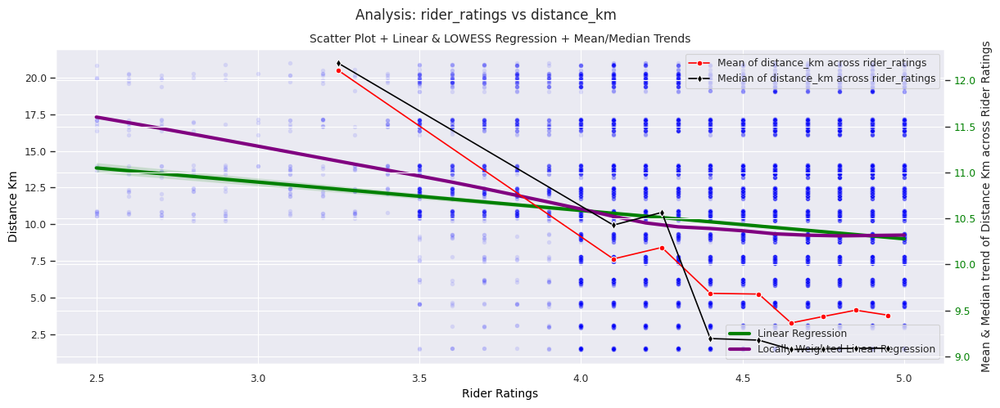

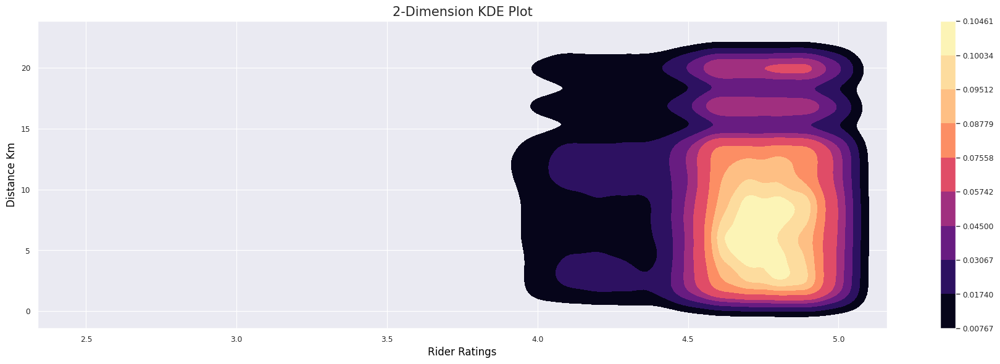

----------------------------------------------------------------------------------------------------------------------------------
STATISTICS FOR Rider Ratings vs Distance Km
Mutual Information: 0.0117 (Higher = more dependency)
Spearman Rank:      -0.0699 (Robust to non-linear)
Pearson Coef:       -0.1087

Result: Statistically significant monotonic association detected between Rider Ratings & Distance Km by Spearman Rank
----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_numerical_vs_numerical(new_df.copy(), feature = 'rider_ratings', feature_type = 'continuous', target = 'distance_km', palette = 'magma')

In [ ]:
t1 = df[df['rider_ratings'].between(4.5,5)]
t2 = df[df['rider_ratings'].between(4,4.5)]
t3 = df[df['rider_ratings'].between(3.5,4)]
t4 = df[df['rider_ratings'].between(3,3.5)]
t5 = df[df['rider_ratings'].between(2.5,3)]

print('Average Distance Covered as Rider ratings decrease')
print(round(t1['distance_km'].mean(),2),'km')
print(round(t2['distance_km'].mean(),2),'km')
print(round(t3['distance_km'].mean(),2),'km')
print(round(t4['distance_km'].mean(),2),'km')
print(round(t5['distance_km'].mean(),2),'km')

Average Distance Covered as Rider ratings decrease
9.48 km
9.86 km
11.84 km
14.1 km
14.66 km


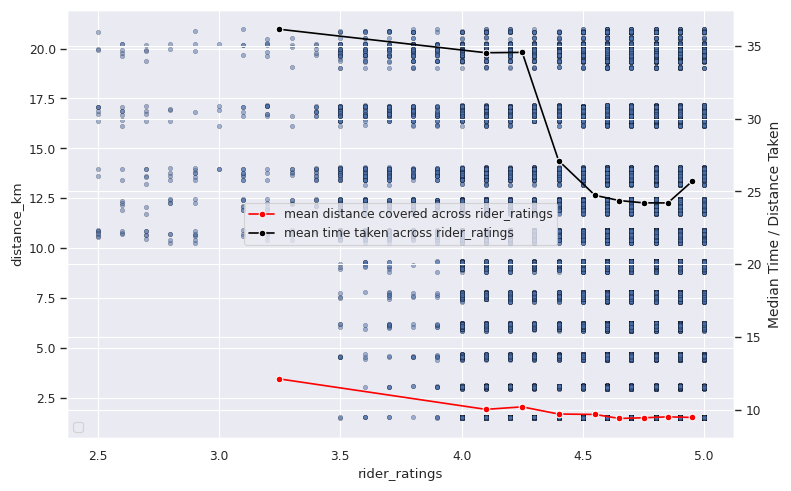

In [ ]:
col_name = 'rider_ratings'

d1 = df.copy().dropna()
d1['bin'] = pd.qcut(d1[col_name], q = 20, duplicates='drop')
d1['mid'] = d1['bin'].apply(lambda x: x.mid)

fig, ax_scatter = plt.subplots(nrows = 1, ncols = 1, figsize = (8,5))
ax_mean = ax_scatter.twinx()

sns.scatterplot(data = d1, x = col_name, y = 'distance_km', s = 10,  marker = 'o', alpha = 0.5, edgecolor = 'black', palette = 'magma', ax = ax_scatter)
ax_scatter.legend(loc = 'lower left')

sns.lineplot(data = d1.groupby('mid')['distance_km'].mean().sort_index(), label = f'mean distance covered across {col_name}', color = 'red', marker = 'o', ax = ax_mean)
sns.lineplot(data = d1.groupby('mid')['time_taken'].mean().sort_index(),  label = f'mean time taken across {col_name}', color = 'black', marker = 'o', ax = ax_mean)
ax_mean.set_ylabel('Median Time / Distance Taken', fontsize = 10)
ax_mean.legend(loc = 'center')

plt.tight_layout()
plt.show()

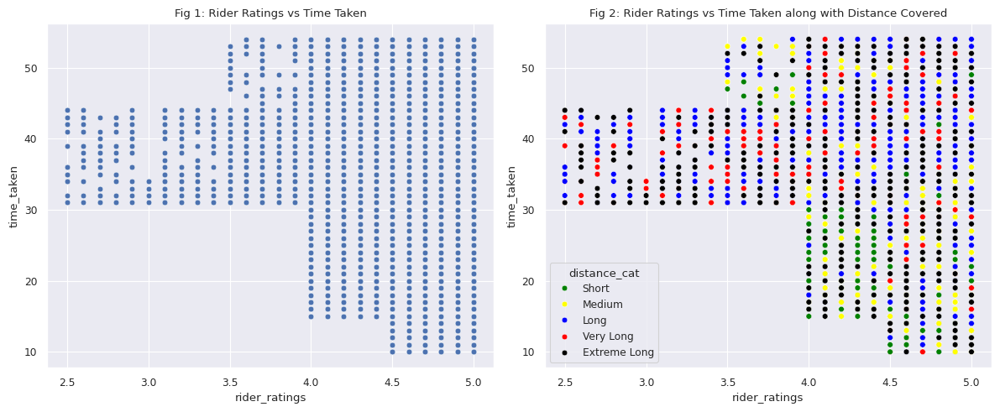

In [ ]:
fig, (ax_scatter, ax_scatter_dist) = plt.subplots(nrows = 1, ncols = 2, figsize = (12,5))

sns.scatterplot(data = new_df, x = 'rider_ratings', y = 'time_taken', ax = ax_scatter)
sns.scatterplot(data = new_df, x = 'rider_ratings', y = 'time_taken', hue = 'distance_cat',
                palette = {'Short':'green', 'Medium':'yellow', 'Long': 'blue','Very Long':'red', 'Extreme Long':'black'}, ax = ax_scatter_dist)

ax_scatter.set_title('Fig 1: Rider Ratings vs Time Taken')
ax_scatter_dist.set_title('Fig 2: Rider Ratings vs Time Taken along with Distance Covered')
plt.tight_layout()
plt.show()

1. Previously: From our Univariate Analysis, we've seen that rider with ratings >= 4.5 dominate this data, and rider below ratings 3.8 are considered as outliers

2. **Fig 1:** Tells us that for Riders with rating < 4 there minimum time to delivery order is atleast > 30 minutes. Maybe agar data mai hee low ratings wale riders aur zayada hote to unka spread along time_taken, higher ratings rider ki tarah hota hai faila hua

3. **Q.** Isn't it strange that riders whose ratings are below 4 atleast take 30 minutes to deliver order ? Kya Lower rider ratings hamesha order late hee deliver karte hai ?

4. **Fig 2:** Tells you that riders with 2.5-3.4 ratings unka time_taken isliye zayada nahi hai ki unki ratings less hai or Lower ratings riders hamesha order late hee deliver karte hai. We can see that rider ratings 2.5-4, coveres more distance. You can see that for these riders there distance category is highly dominated by Long, Very Long & Extreme Long distances deliveries

5. **Must Read:** But, there is also a strange pattern which shows that for rider with ratings 4.0 onwards, in those, some riders who travels Long, Very long, Extreme Long distances still take lesser time to delivery order than riders who covers Medium distance, which means `there are definetely some other factors which leads to this variablity in time_taken` if plottted against rider_ratings, you can confirm this also from below plotly 3d scatter plot or seaborn regression facet plot

6. **Fig 1 & 2 Combined:** Our EDA suggests that higher-rated riders appear across many longer-distance ones. If longer-distance orders tend to pay more, then it is reasonable to say that riders may end up with higher earnings /incentives indirectly through handling more long-distance or they are getting more & more deliveries. **Maybe thats why riders request to rate them, because it increae them chance of earnings.**

7. But our data alone cannot prove the platform is intentionally preferring high-rated riders for those orders, **it only shows a pattern consistent with that possibility.** Other explanations are also possible, such as high-rated riders being more common overall, more active, available in better zones, or working longer or in more peak shift.

---
1. Average Distance covered decrease as the rider ratings increases

2. Spearman Rank cor-relation also says that "Statistically significant monotonic association detected between rider_age & distance_km"

3. Linear Regression line and LOWESS Regression cruve also shown downwards trend between rider_age & distance_km

4. So the answer of our question **Does low ratings riders covers more distance than high ratings riders outliers which causes delay in time taken ?**: Yes

5. But there is a catch from real life persepective which is that
   - Handling longer distance deliveries
     - Create more delay
       - Increases customer dissatisfication
         - Customers gives lower ratings to riders

6. `rider_ratings` is a **subjective** because it **depends on customer experience with delivery**. That means low-rating outliers can arise from:
   - Bad delivery experience of customers which itself arises from multiple factors that causes delay.
   - `Lower ratings does not mean every low rating is fully fair or fully caused by the rider.`
   - `Every Low ratings does not mean that it is a clean measurement of rider performance`

#### Q2. Check why there is a sudden increases in time taken as rider ratings crosses 4.4 ?

---
1.

 - a. P(order time of day = Evening | rider ratings >= 4.5 to 5) >>> P(order time of day = except Evening | rider ratings >= 4.5 to 5)
 - b. P(order time of day = Night   | rider ratings >= 4.5 to 5) > P(order time of day = Morining, Afternoon, Late Night | rider  ratings >= 4.5 to 5)
 - c. Also there is a spike in Conditional Probablity of order time of day after rider_ratings crosses 4.4
 - d. But this spike is highest for Evening time

---
2.
  - a. P(festival = True| rider ratings >= 4.5 to 5) >>> P(festival = True | rider ratings 2.5 to 4.4)
  - b. There is a spike Conditional Probablity of festival, even though they represent ~ 2% of data
  - c. & festival itself causes delay in delivery time

---
3.
  - a. P(deliveries = 0,1,2,3 | rider ratings >= 4.5 to 5) >>> P(deliveries = 0,1,2,3 | rider ratings 2.5 to 4.4)
  - b. Even though 0, still dominates in this regions but still thereis a spike in multiple deliveries 1,2,3
  - c. multiple deliveris itself causes delay in delivery time, this is analysed from later parts of our EDA. Sorry to mention it early

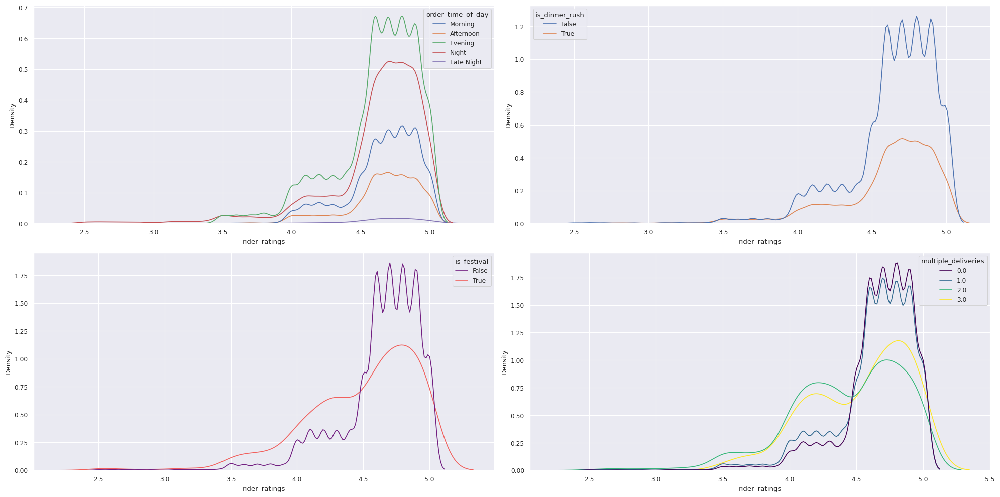

In [ ]:
fig, [(kde_order_time, kde_dinner_rush), (kde_festival, kde_deliveries)] = plt.subplots(nrows = 2, ncols = 2, figsize = (20,10))

sns.kdeplot(data = clean_df, x = 'rider_ratings', hue = 'order_time_of_day', ax = kde_order_time)
sns.kdeplot(data = clean_df, x = 'rider_ratings', hue = 'is_dinner_rush', ax = kde_dinner_rush)
sns.kdeplot(data = clean_df, x = 'rider_ratings', hue = 'is_festival', common_norm = False, palette = 'magma', ax = kde_festival)
sns.kdeplot(data = clean_df, x = 'rider_ratings', hue = 'multiple_deliveries', common_norm = False, palette = 'viridis', ax = kde_deliveries)
plt.tight_layout()
plt.show()

#### Q3. Within the same rider ratings, why there is variablity in time_taken to deliver order ?

1. A rider can have the same rating, but the delivery conditions can be very different.

2. For example, two riders may both have rating 4.5, but:
   - One delivery may happen in Jam traffic, another may happen in Low traffic
   - One rider may handle multiple deliveries, another handle only one delivery
   - One order may be cover longer distance, another  short distance
   - One may happen during dinner rush, another during a normal hour

3. Within the same rider_ratings, time_taken varies because rider rating is only one part of the story.

4. Handling longer distance deliveries
   - along with dealing with multiple_deliveries
     - which itself increase distance that has to be covered by riders
       - Along with facing worse traffic condition (especially during festival & dinner rush time)
         - which leads delays & more additional delays in delivery time
           - Customer receive order late
             - Increases customer dissatisfication
               - Customers gives lower ratings to riders

5. Combined effect of features like **distance covered, traffic, multiple deliveries,  dinner rush & festival conditions** affect delivery time or leads to variatian in delivery time taken, within the same rider ratings

6. **`rider_ratings` is linked to a broader context of `longer distance routes`, `multiple_deliveries`, `heavier traffic`, `festival times`, `dinner rush time`, and may also along with some others features, of which combined effect causes delay effects in delivery time.**

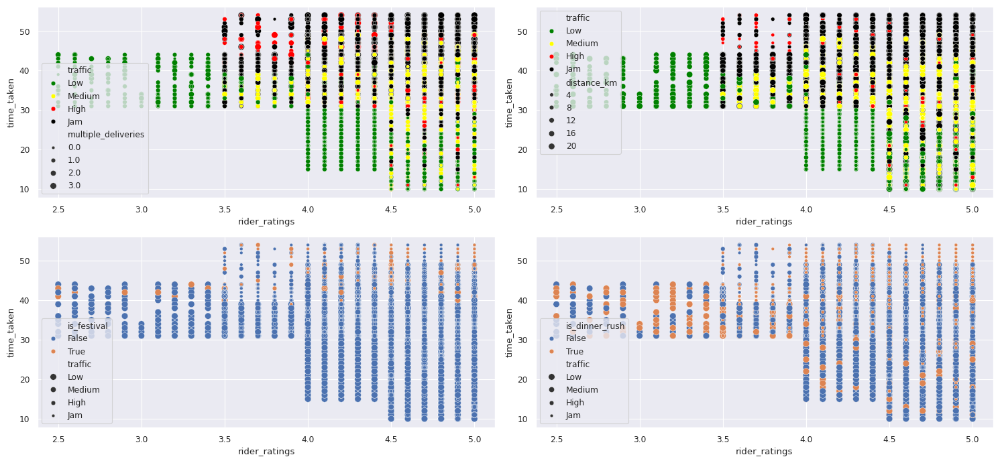

In [ ]:
fig, [(ax1,ax2),(ax3,ax4)] = plt.subplots(nrows = 2, ncols = 2, figsize = (15,7))

traffic_palette = {'Low':'green', 'Medium':'yellow', 'High':'red', 'Jam':'black'}

sns.scatterplot(data = clean_df, x = 'rider_ratings', y = 'time_taken', hue = 'traffic',        size = 'multiple_deliveries', palette = traffic_palette, ax = ax1)
sns.scatterplot(data = clean_df, x = 'rider_ratings', y = 'time_taken', hue = 'traffic',        size = 'distance_km',         palette = traffic_palette, ax = ax2)
sns.scatterplot(data = clean_df, x = 'rider_ratings', y = 'time_taken', hue = 'is_festival',    size = 'traffic',             ax = ax3)
sns.scatterplot(data = clean_df, x = 'rider_ratings', y = 'time_taken', hue = 'is_dinner_rush', size = 'traffic',             ax = ax4)

plt.tight_layout()
plt.show()

#### Q4. Since there is a moderate co-relation between rider_ratings and time_taken. But is rider_ratings also is the causation of time_taken ?
- No

### f. **Final Conclusion**
   - rider_ratings appears to be a moderately informative feature for predicting delivery time.
   
   - rider ratings have greater explanatory power & provide some information than rider_age, but still explain only a portion of delivery time variability.
   
   - **Approximately 13% of the variation in delivery time may be explained by `rider_ratings` alone.**
      
   - It may contribute some predictive signal. However, it is unlikely to be a high-importance feature or to be a primary cause of delivery time predictions. This suggests: **Other variables likely explain delivery time far better than `rider_ratings`.**
   
   - This we see later in EDA that multiple_deliveries itself - increases distance covered by the riders

    - Handling longer distance deliveries
       - along with dealing with multiple_deliveries
         - which itself increase distance covered by riders
           - along with facing worse traffic condition (especially during festival & dinner rush time)
             - leads to additional delays in delivery time
               - Increases customer dissatisfication
                 - Customers gives lower ratings to riders
   
   - **Most variability in time_taken arises from or combination of multiple features which we already seen in Multi-Variate Analysis**

   - **`rider_ratings` is linked to a broader context of `longer distance routes`, `multiple_deliveries`, `heavier traffic`, `festival times`, `dinner rush time`, and may also along with some others features, of which combined effect causes delay effects in delivery time.**

## 20.weather

### a. Uni & Bi-Variate Analysis

,weather,count,proportion_%,mean_time_taken,std_time_taken
0,Sunny,7284,16.195,21.86,8.33
1,Stormy,7586,16.866,25.87,8.47
2,Sandstorms,7495,16.664,25.88,8.62
3,Windy,7422,16.502,26.12,8.62
4,Cloudy,7536,16.755,28.92,10.08
5,Fog,7654,17.018,28.92,10.13


----------------------------------------------------------------------------------------------------------------------------------------------------------------


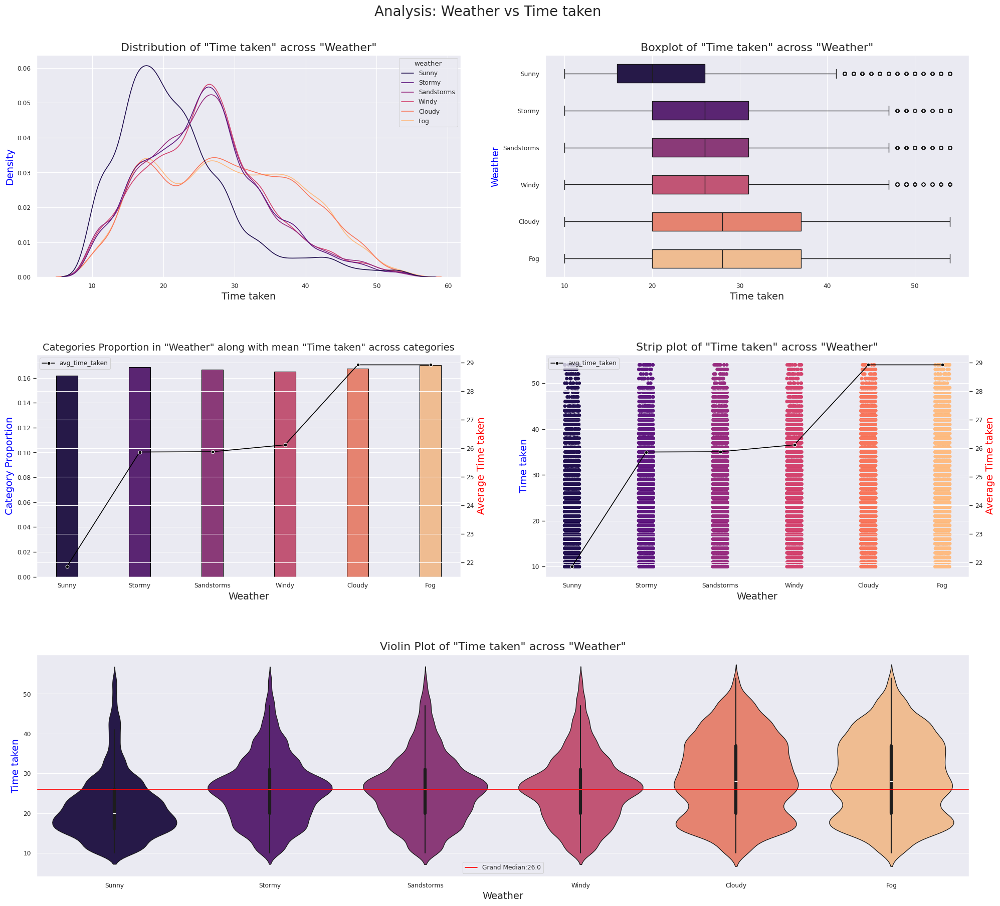

--------------------------------------------------------------------------------------------------------------------------------------------
Welch One-Way ANOVA (not assumed equal variance)

Reject Ho
Result: Significant difference in category mean of "time_taken" detected across "Weather"
Result: Welch’s ANOVA indicates that atleast one category mean of "time_taken" is significantly differs from the rest of the others
--------------------------------------------------------------------------------------------------------------------------------------------


In [ ]:
get_bivariate_analysis_for_categorical_vs_numerical(df.copy(), feature = 'weather', target = 'time_taken', palette = 'magma')

### b. Multi-Variate Analysis

In [ ]:
get_hypothesis_test_results_for_categorical_column(new_df.copy(), feature_given = 'weather')

,feature_1,feature_2,p_value_b/w_feature_1_and_feature_2,feature_2,feature_3,p_value_b/w_feature_2_and_feature_3
0,weather,is_festival,0.0,is_festival,time_taken,0.0
1,weather,rider_ratings,0.0,rider_ratings,time_taken,0.0
2,weather,multiple_deliveries,0.0,multiple_deliveries,time_taken,0.0



Overall category-level summary:


,weather,avg_dist,avg_time
0,Sunny,9.63,21.90
1,Sandstorms,9.65,25.88
2,Stormy,9.73,25.90
3,Windy,9.75,26.13
4,Cloudy,9.77,28.93
5,Fog,9.77,28.97



Feature × traffic analysis:


proportion  avg_dist  avg_time_taken
weather    traffic                                      
Sunny      Low          0.3392    8.0283         21.4820
           Medium       0.2458   11.1001         20.1971
           High         0.1006    4.4389         23.4018
           Jam          0.3144   11.8627         23.1934
Sandstorms Low          0.3465    8.0205         20.3038
           Medium       0.2395   10.9977         27.7346
           High         0.0934    4.3820         27.6946
           Jam          0.3206   11.9474         29.9959
Stormy     Low          0.3527    8.1739         20.6675
           Medium       0.2432   11.0768         27.6781
           High         0.0966    4.3536         27.7893
           Jam          0.3074   12.1530         29.8927
Windy      Low          0.3346    8.1751         20.6833
           Medium       0.2481   10.9634         27.8755
           High         0.0997    4.4365         26.9868
           Jam          0.3176   12.1316         30.2323
Cloudy     Low          0.3454    8.2976         22.2343
           Medium       0.2434   11.1425         28.5519
           High         0.0988    4.3665         28.9197
           Jam          0.3125   12.0505         36.6154
Fog        Low          0.3391    8.1963         22.3082
           Medium       0.2417   11.1506         28.2041
           High         0.1010    4.4035         28.4831
           Jam          0.3182   12.0995         36.8207

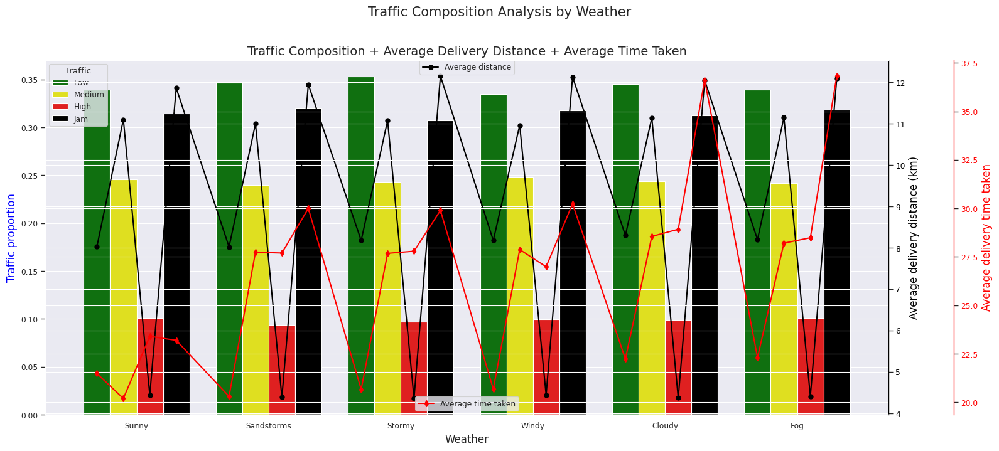

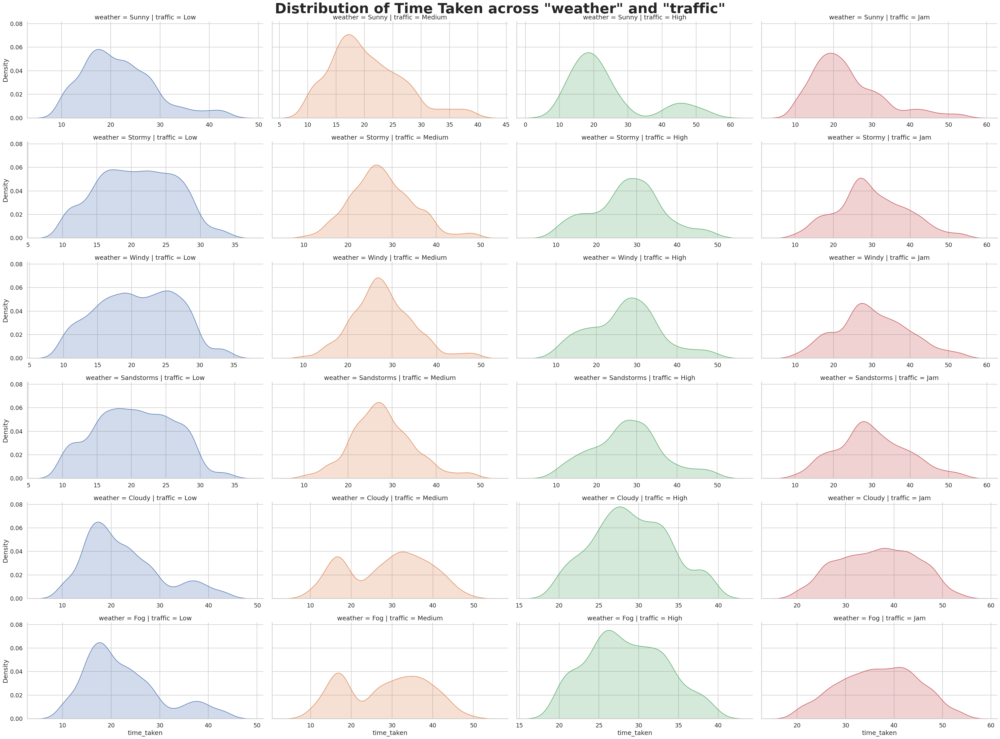

traffic,Low,Medium,High,Jam
weather,,,,
Sunny,21.702347,20.385714,23.479624,23.376950
Stormy,20.773241,27.752457,27.867395,30.027613
Windy,20.867011,27.876002,27.211180,30.305797
Sandstorms,20.495067,27.836526,27.683007,30.076118
Cloudy,22.381544,28.762476,29.074534,36.593583
Fog,22.416107,28.329602,28.494065,36.842498


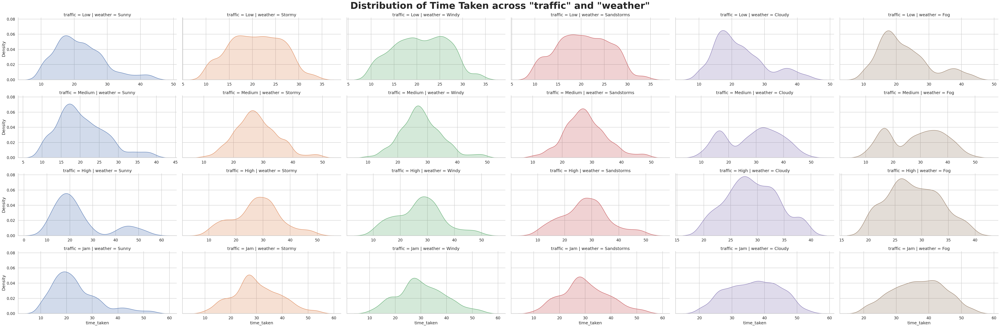

weather,Sunny,Stormy,Windy,Sandstorms,Cloudy,Fog
traffic,,,,,,
Low,21.702347,20.773241,20.867011,20.495067,22.381544,22.416107
Medium,20.385714,27.752457,27.876002,27.836526,28.762476,28.329602
High,23.479624,27.867395,27.211180,27.683007,29.074534,28.494065
Jam,23.376950,30.027613,30.305797,30.076118,36.593583,36.842498


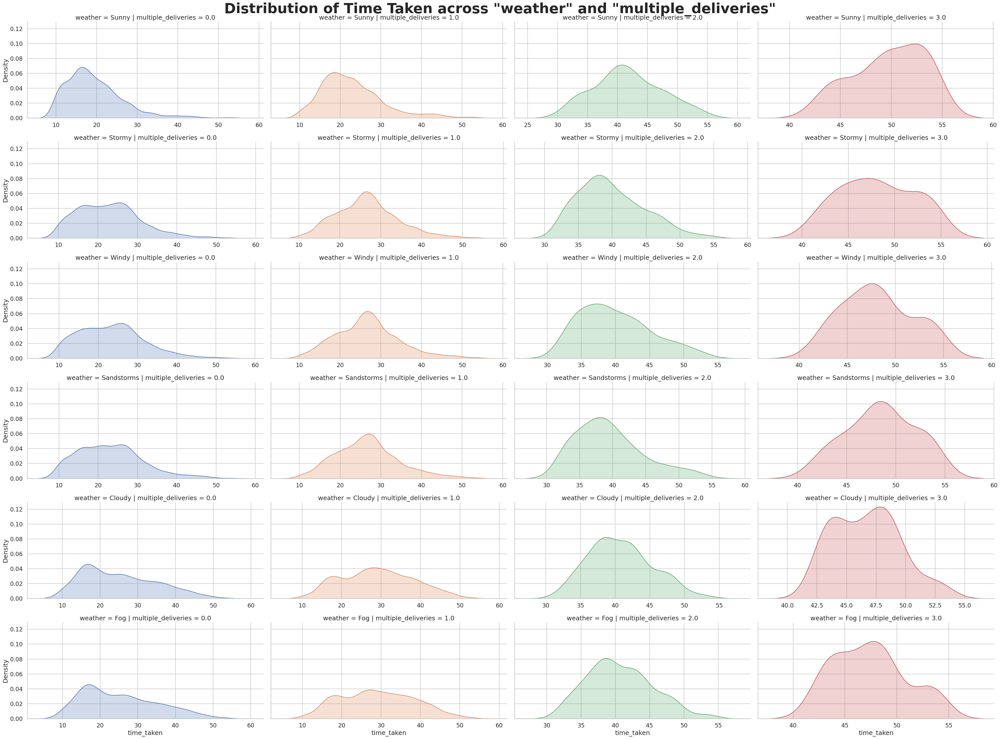

multiple_deliveries,0.0,1.0,2.0,3.0
weather,,,,
Sunny,19.437605,22.876267,41.733333,49.702703
Stormy,22.772437,26.601214,39.850427,48.116279
Windy,23.253928,26.765555,39.937220,48.125000
Sandstorms,23.064238,26.608967,39.450237,48.476190
Cloudy,25.161155,29.157002,40.784990,46.685714
Fog,25.283692,29.151385,40.672098,47.415584


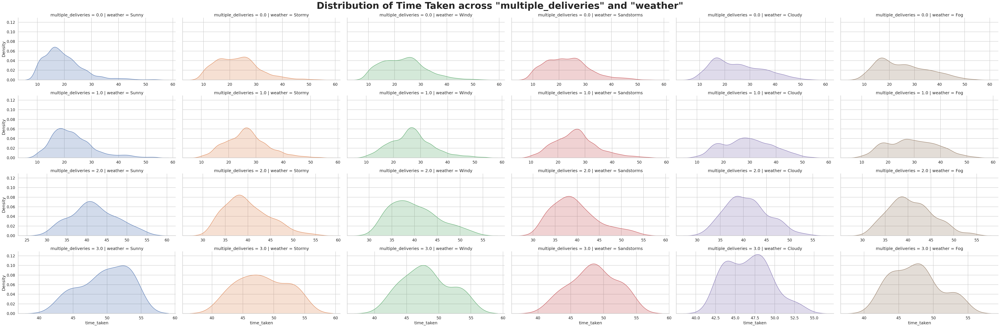

weather,Sunny,Stormy,Windy,Sandstorms,Cloudy,Fog
multiple_deliveries,,,,,,
0.0,19.437605,22.772437,23.253928,23.064238,25.161155,25.283692
1.0,22.876267,26.601214,26.765555,26.608967,29.157002,29.151385
2.0,41.733333,39.850427,39.937220,39.450237,40.784990,40.672098
3.0,49.702703,48.116279,48.125000,48.476190,46.685714,47.415584


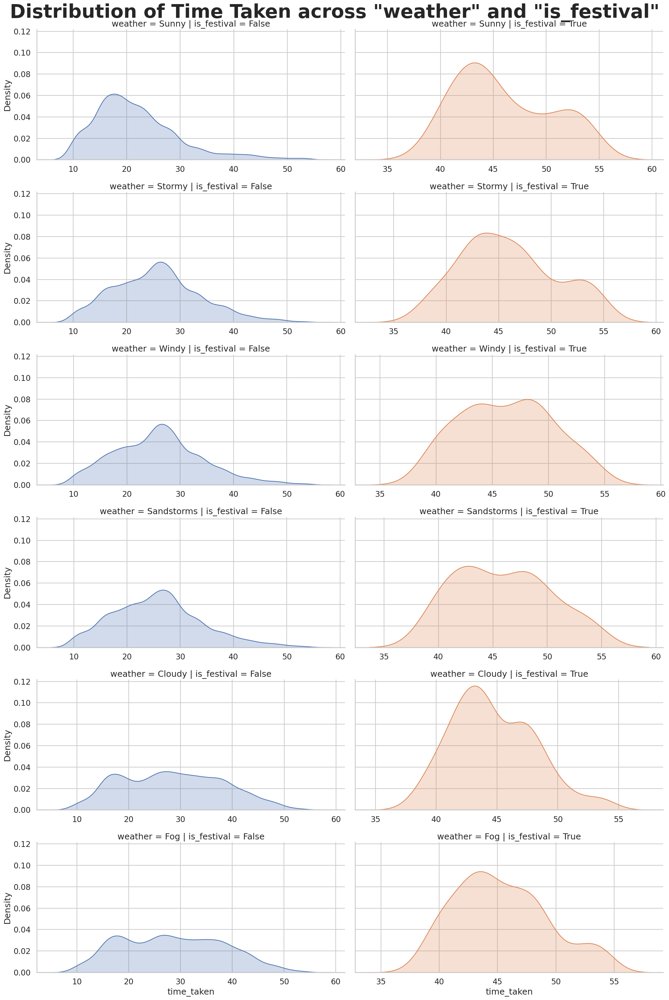

is_festival,False,True
weather,,
Sunny,21.824285,45.971014
Stormy,25.725077,45.929293
Windy,26.001569,46.235955
Sandstorms,25.777069,45.890244
Cloudy,28.537927,44.704762
Fog,28.528516,45.359649


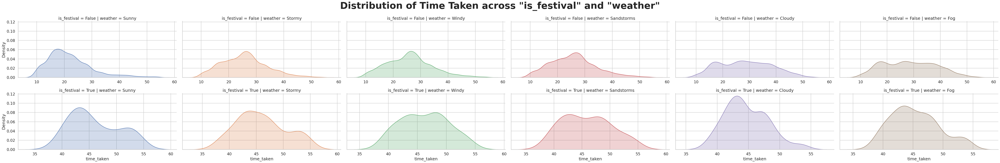

weather,Sunny,Stormy,Windy,Sandstorms,Cloudy,Fog
is_festival,,,,,,
False,21.824285,25.725077,26.001569,25.777069,28.537927,28.528516
True,45.971014,45.929293,46.235955,45.890244,44.704762,45.359649


In [ ]:
get_multivariate_analysis_for_categorical_feature(new_df.copy(), feature_given = 'weather', plot_facet = ['traffic','multiple_deliveries', 'is_festival'])

###c. Observations

1. `weather` has a statistically significant relationship with time_taken.
2. Weather categories show clear differences in delivery time.
3. Sunny weather behaves differently from the other weather categories.
4. Deliveries in Sunny weather are fastest on average.
5. Deliveries in Stormy, Windy, and Sandstorms take more time than Sunny.
6. Deliveries in Cloudy and Fog take the highest time on average.
7. So the weather effect is not only statistically significant, but also practically meaningful.

---
**Here is the real picture:**

8. The average distance is almost the same across all weather categories. This means the higher time_taken in Fog and Cloudy is not because those categories have longer routes. So **Weather is not simply acting as a proxy for distance.**

9. Traffic composition is also very similar across weather categories. The proportion of Low, Medium, High, and Jam traffic is nearly the same for each weather group. So the slower delivery times in Fog and Cloudy are not only because those weather categories have worse traffic mix.

10. Even when traffic pattern looks similar, the delivery-time gap across weather categories still remains visible. This suggests that weather introduces additional delay beyond traffic impact on time_taken. So **Weather is not simply acting as a proxy for traffic.**

11. For multiple_deliveries, delivery load itself clearly affects time_taken. As multiple_deliveries increases from **0 to 3**, delivery time increases strongly in every weather category. So multiple_deliveries is itself an important driver of delivery time. This is also we already know from our previous analysis.

12. But even within the same fixed multiple_deliveries level, the weather pattern still remains visible. Within the same delivery-load group:
    - Sunny deliveries are still relatively faster
    - Stormy, Windy, and Sandstorms are still in the middle
    - Cloudy and Fog are still relatively slower
    - This means **Weather is not simply acting as a proxy for multiple_deliveries.**

13. For is_festival, festival itself strongly increases time_taken. In every weather category, the distribution for is_festival = True is clearly shifted to the right compared with is_festival = False. So festival is another strong factor affecting delivery time. This is also we already know from our previous analysis.

14. But even within is_festival = False or is_festival = True, the weather pattern still remains visible. Sunny remains relatively lower, while Cloudy and Fog remain relatively higher. **Weather is not simply acting as a proxy for festival condition either.**

15. Therefore, weather is not simply standing in place of:
    - distance
    - traffic
    - multiple_deliveries
    - is_festival

16. weather is likely an important predictor because it captures a real shift in delivery time. But **weather alone itself does not directly cause higher delivery time. Weather is linked to a broader delivery context** such as:
    - lower visibility
    - slower movement on roads
    - difficult riding conditions
    - interaction with delivery load / multiple_deliveries
    - interaction with festival pressure
    - and other operational factors

17. **The combined effect of these conditions increases delivery time.**

# **Epistatic Effect in Machine Learning**

## **1. Meaning of an Epistatic Effect**

1. An **epistatic effect** occurs when the effect of one feature on the target variable depends on the value of another feature.

2. In an additive model, features contribute independently. In an epistatic relationship, their joint effect contains information that cannot be explained by their individual effects alone.

In simple words: **Two or more features interact in such a way that their combined effect cannot be fully understood by examining each feature separately.**

In machine learning, an epistatic effect is commonly called:

* **Feature interaction**
* **Variable interaction**
* **Interaction effect**

---

## **2. Simple Example**

Suppose we want to predict whether a student will pass an examination using two features:

* `study_hours`
* `sleep_hours`

| Study Hours | Sleep Hours | Result                             |
| ----------- | ----------- | ---------------------------------- |
| Low         | Low         | Fail                               |
| High        | Low         | Fail because of exhaustion         |
| Low         | High        | Fail because of insufficient study |
| High        | High        | Pass                               |

In this example, the effect of `study_hours` depends on `sleep_hours`.

Studying for many hours may not improve performance when the student does not get enough sleep.

Therefore, `study_hours` and `sleep_hours` have an **interaction effect**.

---

## **3. Model Without an Interaction Effect**

Suppose:

* $x_1$ represents study hours.
* $x_2$ represents sleep hours.
* $y$ represents examination performance.

A simple linear model can be written as:

$$y = \beta_0 + \beta_1x_1 + \beta_2x_2$$

Where:

* $\beta_0$ is the intercept.
* $\beta_1$ represents the independent effect of $x_1$.
* $\beta_2$ represents the independent effect of $x_2$.

This model assumes that the effect of $x_1$ does not depend on $x_2$.

It also assumes that the effect of $x_2$ does not depend on $x_1$.

---

## **4. Model With an Interaction Effect**

To represent an epistatic effect, we add an interaction term:

$$y = \beta_0 + \beta_1x_1 + \beta_2x_2 + \beta_3x_1x_2$$

The interaction term is:

$$\beta_3x_1x_2$$

Here:

* $\beta_1x_1$ is the main effect of $x_1$.
* $\beta_2x_2$ is the main effect of $x_2$.
* $\beta_3x_1x_2$ is the interaction or epistatic effect.

The product $x_1x_2$ allows the effect of one feature to change according to the value of the other feature.

---

## **5. Why Does the Interaction Term Matter?**

Consider the following model:

$$y = \beta_0 + \beta_1x_1 + \beta_2x_2 + \beta_3x_1x_2$$

To determine how $y$ changes when $x_1$ changes, we calculate the partial derivative with respect to $x_1$:

$$\frac{\partial y}{\partial x_1} = \beta_1 + \beta_3x_2$$

This equation shows that the effect of $x_1$ depends on the value of $x_2$.

Similarly, the effect of $x_2$ is:

$$\frac{\partial y}{\partial x_2} = \beta_2 + \beta_3x_1$$

Therefore:

* The effect of $x_1$ depends on $x_2$.
* The effect of $x_2$ depends on $x_1$.

This dependency is the main idea behind an **epistatic effect**.

---

## **6. Numerical Example**

Suppose the model is:

$$y = 2x_1 + 3x_2 + 5x_1x_2$$

Here:

* $2x_1$ is the main effect of $x_1$.
* $3x_2$ is the main effect of $x_2$.
* $5x_1x_2$ is the interaction effect.

The effect of $x_1$ is:

$$\frac{\partial y}{\partial x_1} = 2 + 5x_2$$

### **Case 1: When $x_2 = 0$**

$$\frac{\partial y}{\partial x_1} = 2 + 5(0) = 2$$

Therefore, when $x_2 = 0$, a one-unit increase in $x_1$ changes $y$ by $2$ units.

### **Case 2: When $x_2 = 2$**

$$\frac{\partial y}{\partial x_1} = 2 + 5(2) = 12$$

Therefore, when $x_2 = 2$, a one-unit increase in $x_1$ changes $y$ by $12$ units.

The effect of $x_1$ changes from $2$ to $12$ because the value of $x_2$ changed.

This is an **epistatic effect**.

---

## **7. Main Effect vs Interaction Effect**

A **main effect** represents the independent contribution of one feature.

An **interaction effect** represents the additional contribution created when two or more features work together.

Consider:

$$y = 2x_1 + 3x_2 + 5x_1x_2$$

The main effects are:

$$2x_1$$

and:

$$3x_2$$

The interaction effect is:

$$5x_1x_2$$

Therefore:

* Main effect of $x_1$: $2x_1$
* Main effect of $x_2$: $3x_2$
* Interaction effect: $5x_1x_2$

---

## **8. Additive Relationship**

In an additive relationship, each feature affects the target independently.

$$y = \beta_0 + \beta_1x_1 + \beta_2x_2$$

In this model:

* The effect of $x_1$ is always $\beta_1$.
* The effect of $x_2$ is always $\beta_2$.
* The effect of $x_1$ does not change when $x_2$ changes.
* The effect of $x_2$ does not change when $x_1$ changes.

The combined effect is simply the sum of the individual effects.

---

## **9. Epistatic Relationship**

In an epistatic relationship, the model includes an interaction term:

$$y = \beta_0 + \beta_1x_1 + \beta_2x_2 + \beta_3x_1x_2$$

Now, the effect of $x_1$ is:

$$\frac{\partial y}{\partial x_1} = \beta_1 + \beta_3x_2$$

The effect of $x_2$ is:

$$\frac{\partial y}{\partial x_2} = \beta_2 + \beta_3x_1$$

Therefore, the two features no longer affect the target independently.

---

## **10. XOR as a Classic Example of Epistatic**

The XOR problem is a classic example of a pure feature interaction.

| Input 1 | Input 2 | Target |
| ------: | ------: | -----: |
|       0 |       0 |      0 |
|       0 |       1 |      1 |
|       1 |       0 |      1 |
|       1 |       1 |      0 |

The XOR relationship can be written as:

$$y = x_1 \oplus x_2$$

The symbol $\oplus$ represents the XOR operation.

The output is $1$ when the two inputs are different.

The output is $0$ when the two inputs are the same.

Looking at $x_1$ alone is not sufficient to determine the target.

Looking at $x_2$ alone is also not sufficient to determine the target.

However, the combination of $x_1$ and $x_2$ perfectly determines the target.

Therefore, **XOR represents a strong epistatic relationship.**

---

## **11. Pairwise Epistasis**

A **pairwise epistatic effect** occurs when two features interact.

The interaction term is:

$$x_1x_2$$

A model containing a pairwise interaction can be written as:

$$y = \beta_0 + \beta_1x_1 + \beta_2x_2 + \beta_3x_1x_2$$

Examples include:

* Study hours interacting with sleep hours
* Exercise interacting with calorie intake
* Advertising expenditure interacting with product price
* Interest rates interacting with inflation

---

## **12. Three-Way Epistasis**

A **three-way epistatic effect** occurs when three features interact simultaneously.

The interaction term is:

$$x_1x_2x_3$$

A model containing a three-way interaction can be written as:

$$y = \beta_0 + \beta_1x_1 + \beta_2x_2 + \beta_3x_3 + \beta_4x_1x_2x_3$$

For example, examination performance may jointly depend on:

* Study hours
* Sleep hours
* Stress level

The effect of study hours may change depending on both sleep and stress.

---

## **13. Higher-Order Epistasis**

A higher-order epistatic effect occurs when more than three features interact.

For example:

$$x_1x_2x_3x_4$$

Higher-order interactions are difficult to detect because the number of possible feature combinations increases rapidly.

They also require more data because the model must learn the behaviour of many feature combinations.

---

## **14. Number of Possible Pairwise Interactions**

Suppose a dataset contains $p$ features.

The number of possible pairwise interactions is:

$$\binom{p}{2} = \frac{p(p-1)}{2}$$

For $100$ features:

$$\binom{100}{2} = \frac{100(100-1)}{2}$$

Therefore:

$$\binom{100}{2} = \frac{100 \times 99}{2} = 4950$$

A dataset with $100$ features has $4950$ possible pairwise interactions.

This is why manually checking every possible interaction can become computationally expensive.

---

## **15. Can Linear Regression Capture Epistatic Effects?**

A standard linear regression model does not automatically capture feature interactions.

$$y = \beta_0 + \beta_1x_1 + \beta_2x_2$$

To capture an interaction, we must explicitly create the interaction feature.

```python
df["interaction"] = df["x1"] * df["x2"]
```

We can then include it in the input features:

```python
X = df[["x1", "x2", "interaction"]]
```

The fitted model becomes:

$$y = \beta_0 + \beta_1x_1 + \beta_2x_2 + \beta_3x_1x_2$$

Therefore, linear regression can capture epistatic effects only when the required interaction terms are explicitly included.

---

## **16. Creating Interaction Features Using PolynomialFeatures**

Scikit-learn provides `PolynomialFeatures` for generating interaction features.

```python
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

X_interaction = poly.fit_transform(X)
```

For two original features, $x_1$ and $x_2$, the transformed data may contain:

* $x_1$
* $x_2$
* $x_1x_2$

Because `interaction_only=True`, individual squared terms are not generated.

Therefore, the following terms are excluded:

$$x_1^2$$

and:

$$x_2^2$$

---

## **17. Can Logistic Regression Capture Epistatic Effects?**

A standard logistic regression model also does not automatically include interaction terms.

The model may begin with:

$$z = \beta_0 + \beta_1x_1 + \beta_2x_2$$

The predicted probability is:

$$P(y=1) = \frac{1}{1 + e^{-z}}$$

To include an interaction, the linear component must be changed to:

$$z = \beta_0 + \beta_1x_1 + \beta_2x_2 + \beta_3x_1x_2$$

Therefore, logistic regression can model an epistatic effect when the interaction feature is explicitly included.

---

## **18. Can Decision Trees Capture Epistatic Effects?**

Yes. Decision trees can naturally capture feature interactions.

For example, a tree may first split on `sleep_hours`.

It may then split on `study_hours` inside the resulting branches.

This means that the effect of `study_hours` is evaluated differently for different values of `sleep_hours`.

Therefore, decision trees can model feature interactions without manually creating product terms such as $x_1x_2$.

---

## **19. Can Random Forest Capture Epistatic Effects?**

Yes. A Random Forest can capture interactions because it contains many decision trees.

Different trees may learn different interactions:

* One tree may learn an interaction between $x_1$ and $x_2$.
* Another tree may learn an interaction between $x_2$ and $x_3$.
* Another tree may learn an interaction involving several features.

Its ability to capture interactions depends on:

* Number of trees
* Maximum tree depth
* Number of observations
* Amount of noise
* Feature sampling
* Strength of the interaction

Very shallow trees may fail to capture complex interactions.

---

## **20. Can XGBoost Capture Epistatic Effects?**

Yes. XGBoost can capture nonlinear and interaction effects through decision-tree splits.

Suppose a tree first splits on $x_1$.

Inside one resulting branch, it then splits on $x_2$.

The prediction based on $x_2$ now depends on the value of $x_1$.

Therefore, the tree has learned an interaction between $x_1$ and $x_2$.

Deeper trees can generally represent more complex interactions.

However, the exact interaction order depends on the structure of the tree.

---

## **21. Can Neural Networks Capture Epistatic Effects?**

Yes. Neural networks can learn complex and higher-order interactions.

A hidden neuron begins with a weighted sum:

$$z = w_1x_1 + w_2x_2 + b$$

A nonlinear activation function is then applied:

$$a = f(z)$$

Through multiple neurons and nonlinear hidden layers, a neural network can approximate interactions such as:

$$x_1x_2$$

It can also learn higher-order interactions such as:

$$x_1x_2x_3$$

The ability of a neural network to learn these interactions depends on:

* Network architecture
* Amount of training data
* Optimization process
* Regularization
* Noise
* Strength of the interaction

---

## **22. Models and Their Ability to Capture Epistasis**

| Machine Learning Model | Ability to Capture Interactions                            |
| ---------------------- | ---------------------------------------------------------- |
| Linear Regression      | Interaction terms must be manually added                   |
| Logistic Regression    | Interaction terms must be manually added                   |
| Decision Tree          | Captures interactions through hierarchical splits          |
| Random Forest          | Captures interactions through multiple trees               |
| Gradient Boosting      | Captures interactions through sequential trees             |
| XGBoost                | Captures interactions through nonlinear tree splits        |
| LightGBM               | Captures interactions through nonlinear tree splits        |
| Neural Network         | Captures interactions through nonlinear hidden layers      |
| K-Nearest Neighbours   | May capture local interaction patterns                     |
| Naive Bayes            | Limited because of the conditional-independence assumption |

---

## **23. Why Can Univariate Feature Selection Miss Epistasis?**

Univariate feature-selection methods evaluate one feature at a time.

Suppose:

* $x_1$ has almost no individual relationship with the target.
* $x_2$ has almost no individual relationship with the target.
* The combination of $x_1$ and $x_2$ perfectly predicts the target.

This occurs in the XOR problem.

A univariate feature-selection method may incorrectly conclude that both features are unimportant.

However, their combined effect may be extremely important.

Therefore:

> **A feature can be weak individually but highly predictive when combined with another feature.**

---

## **24. Important Interpretation Rule**

Consider the following model:

$$y = \beta_0 + \beta_1x_1 + \beta_2x_2 + \beta_3x_1x_2$$

The effect of $x_1$ is:

$$\frac{\partial y}{\partial x_1} = \beta_1 + \beta_3x_2$$

Therefore, $\beta_1$ is not the universal effect of $x_1$.

It represents the effect of $x_1$ only when:

$$x_2 = 0$$

Similarly, the effect of $x_2$ is:

$$\frac{\partial y}{\partial x_2} = \beta_2 + \beta_3x_1$$

Therefore, $\beta_2$ represents the effect of $x_2$ only when:

$$x_1 = 0$$

This is important when interpreting models that contain interaction terms.

---

## **25. Real-World Examples**

### **Example 1: Education**

The effect of study hours on examination performance may depend on sleep hours.

$$\text{Interaction} = \text{Study Hours} \times \text{Sleep Hours}$$

### **Example 2: Health**

The effect of exercise on weight loss may depend on calorie intake.

$$\text{Interaction} = \text{Exercise} \times \text{Calorie Intake}$$

### **Example 3: Marketing**

The effect of advertising expenditure on sales may depend on the product price.

$$\text{Interaction} = \text{Advertising} \times \text{Product Price}$$

### **Example 4: Finance**

The effect of interest rates on stock returns may depend on inflation.

$$\text{Interaction} = \text{Interest Rate} \times \text{Inflation Rate}$$

### **Example 5: Credit Risk**

The effect of income on default probability may depend on the debt-to-income ratio.

$$\text{Interaction} = \text{Income} \times \text{Debt-to-Income Ratio}$$

---

## **26. Interaction Does Not Imply Causation**

A detected interaction means that the combination of two or more features helps predict the target.

It does not automatically prove that:

* One feature causes the target.
* Another feature causes the target.
* Their interaction causes the target.

Therefore:

> **An epistatic effect may represent a statistical or predictive interaction, but it does not necessarily represent a causal interaction.**

---

## **27. Advantages of Detecting Epistatic Effects**

Detecting interactions can help us:

* Improve model performance
* Discover hidden relationships
* Understand nonlinear behaviour
* Avoid removing useful features
* Build more realistic models
* Generate useful domain insights
* Understand how one feature modifies the effect of another

---

## **28. Challenges of Detecting Epistatic Effects**

Detecting interactions can be difficult because:

* The number of possible interactions grows rapidly.
* Higher-order interactions require more data.
* Noise may create false interactions.
* Complex models may be difficult to interpret.
* Correlated features can complicate interpretation.
* Adding too many interaction terms can cause overfitting.
* A predictive interaction does not necessarily imply causation.

---------------------------------------------------------------- End of EDA ------------------------------------------------------------